In [15]:
import os
import sys
import random
import platform
import subprocess
import importlib.metadata as metadata
from pathlib import Path


# ============================================================
# PART 2 LOCAL CACHE CONFIGURATION
# These must be set BEFORE importing Hugging Face libraries.
# ============================================================

NOTEBOOK_DIR = Path.cwd().resolve()
PART2_ROOT = NOTEBOOK_DIR.parent
DATA_ROOT = PART2_ROOT / "data"

CACHE_ROOT = DATA_ROOT / "cache"
HF_HOME = CACHE_ROOT / "huggingface"
HF_HUB_CACHE = HF_HOME / "hub"
HF_DATASETS_CACHE = HF_HOME / "datasets"
HF_XET_CACHE = HF_HOME / "xet"
HF_ASSETS_CACHE = HF_HOME / "assets"
TORCH_HOME = CACHE_ROOT / "torch"

for directory in [
    DATA_ROOT,
    CACHE_ROOT,
    HF_HOME,
    HF_HUB_CACHE,
    HF_DATASETS_CACHE,
    HF_XET_CACHE,
    HF_ASSETS_CACHE,
    TORCH_HOME,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

os.environ["HF_HOME"] = str(HF_HOME)
os.environ["HF_HUB_CACHE"] = str(HF_HUB_CACHE)
os.environ["HF_DATASETS_CACHE"] = str(HF_DATASETS_CACHE)
os.environ["HF_XET_CACHE"] = str(HF_XET_CACHE)
os.environ["HF_ASSETS_CACHE"] = str(HF_ASSETS_CACHE)
os.environ["TORCH_HOME"] = str(TORCH_HOME)

# The Windows filesystem may not support Hugging Face symlinks.
# Caching still works normally, but may use more disk space.
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"


import numpy as np
import torch
SEED = 266

# Reproducibility seeds
os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Reproducibility-oriented cuDNN settings
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


def run_git_command(args):
    """
    Run a Git command and return readable output.
    This also handles the current situation where the repository
    has been initialized but does not yet have its first commit.
    """
    try:
        return subprocess.check_output(
            ["git"] + args,
            stderr=subprocess.STDOUT,
            text=True,
        ).strip()
    except subprocess.CalledProcessError:
        return "NO_COMMIT_YET"


def package_version(package_name):
    """
    Return the installed package version without importing
    every package into memory.
    """
    try:
        return metadata.version(package_name)
    except metadata.PackageNotFoundError:
        return "NOT INSTALLED"


git_commit = run_git_command(["rev-parse", "HEAD"])
git_branch = run_git_command(["branch", "--show-current"])
git_root = run_git_command(["rev-parse", "--show-toplevel"])


print("=" * 80)
print("DATA 266 LAB 2 - PART 2 REPRODUCIBILITY INFORMATION")
print("=" * 80)

print(f"Random seed              : {SEED}")

print("")
print("GIT")
print("-" * 80)
print(f"Git commit               : {git_commit}")
print(f"Git branch               : {git_branch}")
print(f"Git repository root      : {git_root}")

print("")
print("PYTHON / OPERATING SYSTEM")
print("-" * 80)
print(f"Python version           : {sys.version.split()[0]}")
print(f"Python executable        : {sys.executable}")
print(f"Operating system         : {platform.platform()}")
print(f"Notebook working dir     : {Path.cwd()}")

print("")
print("CORE PACKAGE VERSIONS")
print("-" * 80)
packages = [
    # Core numerical / imaging stack
    "numpy",
    "Pillow",
    "pandas",

    # PyTorch
    "torch",
    "torchvision",

    # Hugging Face / diffusion training
    "diffusers",
    "transformers",
    "accelerate",
    "datasets",
    "peft",
    "huggingface-hub",
    "safetensors",
    "ftfy",

    # Part 2 evaluation
    "torchmetrics",
    "torch-fidelity",
    "lpips",
    "matplotlib",
    "scipy",
    "scikit-learn",
    "ImageHash",

    # Notebook environment
    "jupyterlab",
    "notebook",
    "ipykernel",
]

for package in packages:
    print(
        f"{package:<24}: "
        f"{package_version(package)}"
    )

print("")
print("GPU / CUDA")
print("-" * 80)

print(
    f"CUDA available           : "
    f"{torch.cuda.is_available()}"
)

print(
    f"PyTorch CUDA build       : "
    f"{torch.version.cuda}"
)

print(
    f"cuDNN version            : "
    f"{torch.backends.cudnn.version()}"
)

if torch.cuda.is_available():

    gpu_properties = torch.cuda.get_device_properties(0)

    print(
        f"GPU name                 : "
        f"{torch.cuda.get_device_name(0)}"
    )

    print(
        f"GPU count                : "
        f"{torch.cuda.device_count()}"
    )

    print(
        f"GPU VRAM                 : "
        f"{gpu_properties.total_memory / (1024 ** 3):.2f} GB"
    )

else:
    print("GPU name                 : NONE")

print("")
print("REPRODUCIBILITY SETTINGS")
print("-" * 80)

print(
    f"PYTHONHASHSEED           : "
    f"{os.environ['PYTHONHASHSEED']}"
)

print(
    f"cuDNN deterministic      : "
    f"{torch.backends.cudnn.deterministic}"
)

print(
    f"cuDNN benchmark          : "
    f"{torch.backends.cudnn.benchmark}"
)

print("")
print("=" * 80)
print("ENVIRONMENT CHECK COMPLETE")
print("=" * 80)

DATA 266 LAB 2 - PART 2 REPRODUCIBILITY INFORMATION
Random seed              : 266

GIT
--------------------------------------------------------------------------------
Git commit               : 6960fd2fd54f3314c0aadc81d2492f0889ca1682
Git branch               : main
Git repository root      : D:/DATA 266 Gen AI/Lab2

PYTHON / OPERATING SYSTEM
--------------------------------------------------------------------------------
Python version           : 3.11.9
Python executable        : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\.venv\Scripts\python.exe
Operating system         : Windows-10-10.0.26200-SP0
Notebook working dir     : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\notebooks

CORE PACKAGE VERSIONS
--------------------------------------------------------------------------------
numpy                   : 2.4.6
Pillow                  : 13.0.0
pandas                  : 3.1.1
torch                   : 2.10.0+cu126
torchvision             : 0.25.0+cu126
diffusers               : 0.42.1


In [2]:
import os

from huggingface_hub import constants as hf_constants
import datasets.config as datasets_config


print("=" * 80)
print("CACHE CONFIGURATION VERIFICATION")
print("=" * 80)

print("")
print("ENVIRONMENT VARIABLES")
print("-" * 80)

print(f"HF_HOME              : {os.environ.get('HF_HOME')}")
print(f"HF_HUB_CACHE         : {os.environ.get('HF_HUB_CACHE')}")
print(f"HF_DATASETS_CACHE    : {os.environ.get('HF_DATASETS_CACHE')}")
print(f"HF_XET_CACHE         : {os.environ.get('HF_XET_CACHE')}")
print(f"HF_ASSETS_CACHE      : {os.environ.get('HF_ASSETS_CACHE')}")
print(f"TORCH_HOME           : {os.environ.get('TORCH_HOME')}")

print("")
print("VALUES ACTUALLY READ BY LIBRARIES")
print("-" * 80)

print(
    f"huggingface_hub HF_HOME      : "
    f"{hf_constants.HF_HOME}"
)

print(
    f"huggingface_hub HF_HUB_CACHE : "
    f"{hf_constants.HF_HUB_CACHE}"
)

print(
    f"datasets HF_DATASETS_CACHE   : "
    f"{datasets_config.HF_DATASETS_CACHE}"
)

expected_root = str(
    PART2_ROOT / "data" / "cache"
)

checks = {
    "HF_HOME":
        str(hf_constants.HF_HOME).startswith(expected_root),

    "HF_HUB_CACHE":
        str(hf_constants.HF_HUB_CACHE).startswith(expected_root),

    "HF_DATASETS_CACHE":
        str(datasets_config.HF_DATASETS_CACHE).startswith(expected_root),
}

print("")
print("VERIFICATION")
print("-" * 80)

for name, passed in checks.items():
    print(
        f"{name:<20}: "
        f"{'PASS' if passed else 'FAIL'}"
    )

print("")
print(
    "ALL CACHE LOCATIONS LOCAL TO PART 2:",
    all(checks.values()),
)

print("")
print("=" * 80)
print("CACHE CONFIGURATION CHECK COMPLETE")
print("=" * 80)

D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CACHE CONFIGURATION VERIFICATION

ENVIRONMENT VARIABLES
--------------------------------------------------------------------------------
HF_HOME              : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface
HF_HUB_CACHE         : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface\hub
HF_DATASETS_CACHE    : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface\datasets
HF_XET_CACHE         : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface\xet
HF_ASSETS_CACHE      : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface\assets
TORCH_HOME           : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\torch

VALUES ACTUALLY READ BY LIBRARIES
--------------------------------------------------------------------------------
huggingface_hub HF_HOME      : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface
huggingface_hub HF_HUB_CACHE : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface\hub
datas

# DATA 266 — Lab 2, Part 2
## Fine-Tuning Diffusion Models for Domain-Specific Image Generation

## 1. Dataset Discovery and Provenance

In [3]:
import json

from huggingface_hub import HfApi, hf_hub_download


# ============================================================
# DATASET DISCOVERY / PROVENANCE
# Cache paths are configured centrally in Cell 1.
# ============================================================

DATASET_ID = "lambdalabs/naruto-blip-captions"

api = HfApi()

dataset_info = api.dataset_info(
    repo_id=DATASET_ID,
    files_metadata=True,
)

DATASET_REVISION = dataset_info.sha


print("=" * 80)
print("NARUTO BLIP CAPTIONS — REMOTE DATASET INSPECTION")
print("=" * 80)

print(f"Dataset ID               : {DATASET_ID}")
print(f"Repository revision SHA  : {DATASET_REVISION}")
print(f"Private                  : {dataset_info.private}")
print(f"Gated                    : {dataset_info.gated}")
print(f"Downloads                : {dataset_info.downloads}")

print("")
print("LOCAL CACHE LOCATIONS")
print("-" * 80)

print(f"Part 2 root              : {PART2_ROOT}")
print(f"Data root                : {DATA_ROOT}")
print(f"HF_HOME                  : {HF_HOME}")
print(f"HF datasets cache        : {HF_DATASETS_CACHE}")
print(f"HF hub cache             : {HF_HUB_CACHE}")


# ------------------------------------------------------------
# Machine-readable dataset metadata
# ------------------------------------------------------------

dataset_infos_path = hf_hub_download(
    repo_id=DATASET_ID,
    repo_type="dataset",
    filename="dataset_infos.json",
    revision=DATASET_REVISION,
    cache_dir=str(HF_HUB_CACHE),
)

with open(
    dataset_infos_path,
    "r",
    encoding="utf-8",
) as file:
    dataset_infos = json.load(file)


print("")
print("DATASET_INFOS.JSON")
print("-" * 80)

print(
    json.dumps(
        dataset_infos,
        indent=2,
        ensure_ascii=False,
    )
)


# ------------------------------------------------------------
# Dataset-card metadata
# ------------------------------------------------------------

print("")
print("DATASET CARD METADATA")
print("-" * 80)

card_data = dataset_info.card_data

if card_data is None:
    print("Dataset card metadata    : NONE")
    card_license = None
else:
    try:
        card_dict = card_data.to_dict()
    except AttributeError:
        card_dict = dict(card_data)

    print(
        json.dumps(
            card_dict,
            indent=2,
            ensure_ascii=False,
            default=str,
        )
    )

    card_license = card_dict.get("license")


# ------------------------------------------------------------
# Extract split/schema information
# ------------------------------------------------------------

print("")
print("PARSED DATASET SUMMARY")
print("-" * 80)

if len(dataset_infos) != 1:
    print(
        "WARNING: Expected one dataset configuration, "
        f"but found {len(dataset_infos)}."
    )

for config_name, config_info in dataset_infos.items():

    print(f"Configuration            : {config_name}")

    features = config_info.get("features", {})
    splits = config_info.get("splits", {})

    print(f"Feature names            : {list(features.keys())}")
    print(f"Available splits         : {list(splits.keys())}")

    for split_name, split_info in splits.items():
        print(
            f"Rows in '{split_name}'          : "
            f"{split_info.get('num_examples')}"
        )

    print(
        f"Recorded license field   : "
        f"{config_info.get('license')!r}"
    )

print(
    f"Dataset-card license     : "
    f"{card_license!r}"
)

print("")
print("=" * 80)
print("REMOTE DATASET INSPECTION COMPLETE")
print("=" * 80)

NARUTO BLIP CAPTIONS — REMOTE DATASET INSPECTION
Dataset ID               : lambdalabs/naruto-blip-captions
Repository revision SHA  : 1ed13e8ef280bd45e3bbac4cfa8bbd9d64ec9f89
Private                  : False
Gated                    : False
Downloads                : 2233

LOCAL CACHE LOCATIONS
--------------------------------------------------------------------------------
Part 2 root              : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel
Data root                : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data
HF_HOME                  : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface
HF datasets cache        : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface\datasets
HF hub cache             : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface\hub

DATASET_INFOS.JSON
--------------------------------------------------------------------------------
{
  "lambdalabs--naruto-blip-captions": {
    "description": "",
    "citation": "",
    

## 2. Dataset Loading and Record-Level Validation

LOADING PINNED NARUTO BLIP CAPTIONS DATASET
Dataset ID               : lambdalabs/naruto-blip-captions
Pinned revision          : 1ed13e8ef280bd45e3bbac4cfa8bbd9d64ec9f89
Datasets cache           : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\huggingface\datasets


Repo card metadata block was not found. Setting CardData to empty.
Generating train split: 100%|██████████| 1221/1221 [00:10<00:00, 116.53 examples/s]



DATASET OBJECT
--------------------------------------------------------------------------------
Dataset({
    features: ['image', 'text'],
    num_rows: 1221
})

BASIC STRUCTURE
--------------------------------------------------------------------------------
Dataset type             : Dataset
Number of rows           : 1221
Column names             : ['image', 'text']
Features                 : {'image': Image(mode=None, decode=True), 'text': Value('string')}

REPRESENTATIVE RECORDS
--------------------------------------------------------------------------------
Row index                : 0
Image Python type        : PngImageFile
Image format             : PNG
Image mode               : RGB
Image size               : (1080, 1080)
Caption Python type      : str
Caption length           : 35
Caption                  : 'a man with dark hair and brown eyes'
--------------------------------------------------------------------------------
Row index                : 305
Image Python type    

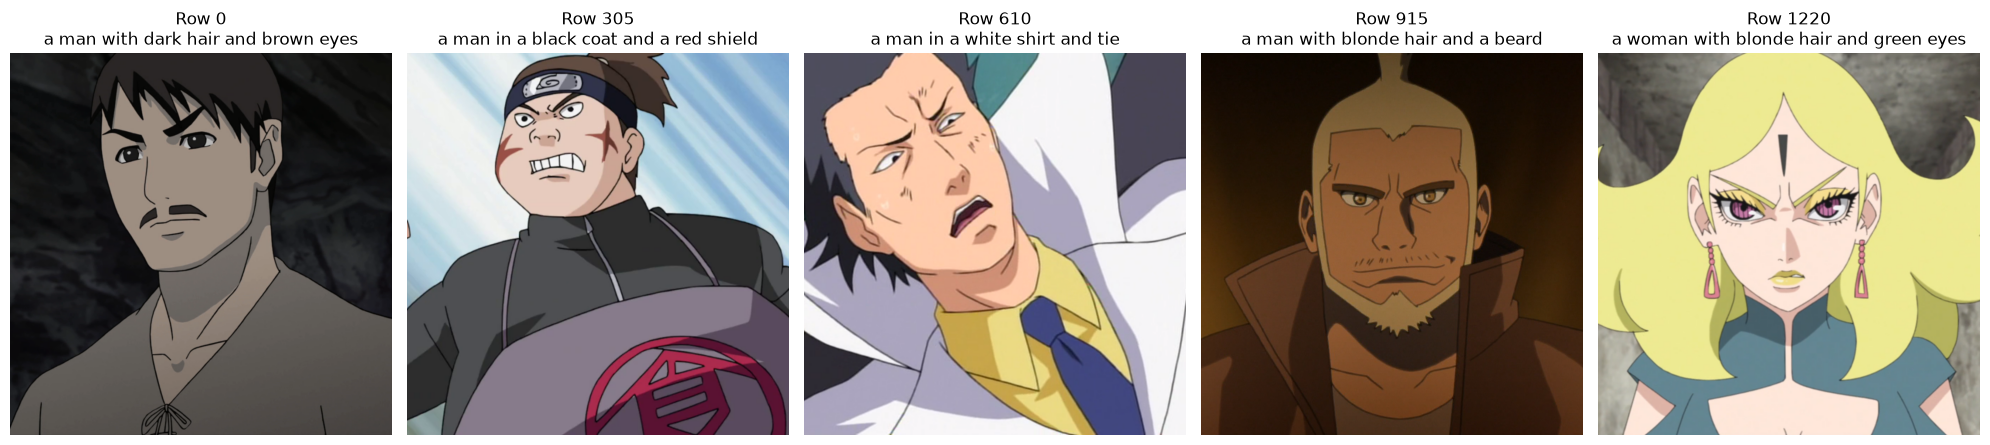


PINNED DATASET LOAD AND RECORD VALIDATION COMPLETE


In [4]:
from datasets import load_dataset
import matplotlib.pyplot as plt


# ============================================================
# LOAD PINNED DATASET
# ============================================================

print("=" * 80)
print("LOADING PINNED NARUTO BLIP CAPTIONS DATASET")
print("=" * 80)

print(f"Dataset ID               : {DATASET_ID}")
print(f"Pinned revision          : {DATASET_REVISION}")
print(f"Datasets cache           : {HF_DATASETS_CACHE}")

raw_dataset = load_dataset(
    DATASET_ID,
    split="train",
    revision=DATASET_REVISION,
    cache_dir=str(HF_DATASETS_CACHE),
)

print("")
print("DATASET OBJECT")
print("-" * 80)

print(raw_dataset)

print("")
print("BASIC STRUCTURE")
print("-" * 80)

print(f"Dataset type             : {type(raw_dataset).__name__}")
print(f"Number of rows           : {len(raw_dataset)}")
print(f"Column names             : {raw_dataset.column_names}")
print(f"Features                 : {raw_dataset.features}")


# ============================================================
# REPRESENTATIVE RECORD INSPECTION
# ============================================================

sample_indices = sorted(
    set(
        [
            0,
            len(raw_dataset) // 4,
            len(raw_dataset) // 2,
            (3 * len(raw_dataset)) // 4,
            len(raw_dataset) - 1,
        ]
    )
)

print("")
print("REPRESENTATIVE RECORDS")
print("-" * 80)

sample_records = []

for index in sample_indices:

    record = raw_dataset[index]

    image = record["image"]
    caption = record["text"]

    record_summary = {
        "index": index,
        "image_type": type(image).__name__,
        "image_format": getattr(image, "format", None),
        "image_mode": getattr(image, "mode", None),
        "image_size": getattr(image, "size", None),
        "caption_type": type(caption).__name__,
        "caption_length": len(caption) if caption is not None else None,
        "caption": caption,
    }

    sample_records.append(record_summary)

    print(f"Row index                : {index}")
    print(f"Image Python type        : {record_summary['image_type']}")
    print(f"Image format             : {record_summary['image_format']}")
    print(f"Image mode               : {record_summary['image_mode']}")
    print(f"Image size               : {record_summary['image_size']}")
    print(f"Caption Python type      : {record_summary['caption_type']}")
    print(f"Caption length           : {record_summary['caption_length']}")
    print(f"Caption                  : {record_summary['caption']!r}")
    print("-" * 80)


# ============================================================
# VISUAL SANITY CHECK
# ============================================================

fig, axes = plt.subplots(
    1,
    len(sample_indices),
    figsize=(4 * len(sample_indices), 5),
)

if len(sample_indices) == 1:
    axes = [axes]

for axis, index in zip(axes, sample_indices):

    record = raw_dataset[index]

    axis.imshow(record["image"])
    axis.set_title(
        f"Row {index}\n"
        f"{record['text'][:50]}"
        + ("..." if len(record["text"]) > 50 else "")
    )
    axis.axis("off")

plt.tight_layout()
plt.show()


print("")
print("=" * 80)
print("PINNED DATASET LOAD AND RECORD VALIDATION COMPLETE")
print("=" * 80)

## 3. Dataset Quality Audit

In [5]:
import hashlib
import json
from collections import Counter, defaultdict
from itertools import combinations

import imagehash
import pandas as pd
from tqdm.auto import tqdm


# ============================================================
# FULL DATASET QUALITY AUDIT
# ============================================================

print("=" * 80)
print("NARUTO BLIP CAPTIONS — FULL DATASET QUALITY AUDIT")
print("=" * 80)

print(f"Rows to inspect           : {len(raw_dataset)}")
print("No rows will be removed in this step.")


# ------------------------------------------------------------
# Containers for row-level audit results
# ------------------------------------------------------------

audit_records = []

decode_failure_indices = []
missing_caption_indices = []
blank_caption_indices = []
non_string_caption_indices = []

exact_hash_to_indices = defaultdict(list)

format_counter = Counter()
mode_counter = Counter()
size_counter = Counter()


# ============================================================
# SCAN EVERY DATASET ROW
# ============================================================

for index in tqdm(
    range(len(raw_dataset)),
    desc="Auditing dataset rows",
):

    row_result = {
        "index": index,
        "decode_ok": False,
        "caption_ok": False,
        "caption": None,
        "caption_length": None,
        "image_format": None,
        "image_mode": None,
        "width": None,
        "height": None,
        "exact_pixel_sha256": None,
        "perceptual_hash": None,
        "error": None,
    }

    # --------------------------------------------------------
    # Caption validation
    # --------------------------------------------------------

    try:
        caption = raw_dataset[index]["text"]

        row_result["caption"] = caption

        if caption is None:
            missing_caption_indices.append(index)

        elif not isinstance(caption, str):
            non_string_caption_indices.append(index)

        elif caption.strip() == "":
            blank_caption_indices.append(index)
            row_result["caption_length"] = len(caption)

        else:
            row_result["caption_ok"] = True
            row_result["caption_length"] = len(caption)

    except Exception as exc:
        row_result["error"] = (
            f"Caption access error: "
            f"{type(exc).__name__}: {exc}"
        )


    # --------------------------------------------------------
    # Image validation
    # --------------------------------------------------------

    try:
        image = raw_dataset[index]["image"]

        # Force PIL to fully decode the image now.
        image.load()

        row_result["decode_ok"] = True

        image_format = getattr(
            image,
            "format",
            None,
        )

        image_mode = getattr(
            image,
            "mode",
            None,
        )

        width, height = image.size

        row_result["image_format"] = image_format
        row_result["image_mode"] = image_mode
        row_result["width"] = width
        row_result["height"] = height

        format_counter[str(image_format)] += 1
        mode_counter[str(image_mode)] += 1
        size_counter[(width, height)] += 1


        # ----------------------------------------------------
        # Exact image duplicate hash
        #
        # Hash normalized RGB pixel values + dimensions.
        # This identifies images that are pixel-identical even
        # if metadata or file encoding differs.
        # ----------------------------------------------------

        rgb_image = image.convert("RGB")

        hash_input = (
            f"{rgb_image.width}x{rgb_image.height}|RGB|"
        ).encode("utf-8") + rgb_image.tobytes()

        exact_hash = hashlib.sha256(
            hash_input
        ).hexdigest()

        row_result["exact_pixel_sha256"] = exact_hash

        exact_hash_to_indices[
            exact_hash
        ].append(index)


        # ----------------------------------------------------
        # Perceptual hash
        #
        # pHash allows us to identify visually similar images
        # even when pixels are not exactly identical.
        # ----------------------------------------------------

        p_hash = imagehash.phash(
            rgb_image,
            hash_size=8,
        )

        row_result["perceptual_hash"] = str(
            p_hash
        )

    except Exception as exc:

        decode_failure_indices.append(index)

        existing_error = row_result["error"]

        image_error = (
            f"Image decode error: "
            f"{type(exc).__name__}: {exc}"
        )

        if existing_error is None:
            row_result["error"] = image_error
        else:
            row_result["error"] = (
                existing_error
                + " | "
                + image_error
            )


    audit_records.append(row_result)


# ============================================================
# CREATE AUDIT DATAFRAME
# ============================================================

audit_df = pd.DataFrame(
    audit_records
)


# ============================================================
# EXACT DUPLICATE GROUPS
# ============================================================

exact_duplicate_groups = {
    image_hash: indices
    for image_hash, indices
    in exact_hash_to_indices.items()
    if len(indices) > 1
}

exact_duplicate_rows = sorted(
    {
        index
        for indices
        in exact_duplicate_groups.values()
        for index
        in indices
    }
)

exact_duplicate_redundant_count = sum(
    len(indices) - 1
    for indices
    in exact_duplicate_groups.values()
)


# ============================================================
# PERCEPTUAL DUPLICATE CANDIDATES
# ============================================================
#
# We compare valid-image pHashes.
#
# Hamming distance:
#   0 = identical pHash
#   small values = visually very similar
#
# We use <= 4 only as a CANDIDATE threshold.
# Nothing is removed automatically based on this threshold.
# ============================================================

valid_phash_records = []

for row in audit_records:

    if (
        row["decode_ok"]
        and row["perceptual_hash"] is not None
    ):
        valid_phash_records.append(
            (
                row["index"],
                imagehash.hex_to_hash(
                    row["perceptual_hash"]
                ),
            )
        )


PERCEPTUAL_DISTANCE_THRESHOLD = 4

perceptual_candidates = []

for (
    (index_a, hash_a),
    (index_b, hash_b),
) in tqdm(
    combinations(
        valid_phash_records,
        2,
    ),
    total=(
        len(valid_phash_records)
        * (len(valid_phash_records) - 1)
        // 2
    ),
    desc="Comparing perceptual hashes",
):

    distance = hash_a - hash_b

    if distance <= PERCEPTUAL_DISTANCE_THRESHOLD:

        # Determine whether this candidate is already
        # pixel-identical according to the SHA-256 audit.
        exact_a = audit_df.loc[
            audit_df["index"] == index_a,
            "exact_pixel_sha256",
        ].iloc[0]

        exact_b = audit_df.loc[
            audit_df["index"] == index_b,
            "exact_pixel_sha256",
        ].iloc[0]

        is_exact_duplicate = (
            exact_a is not None
            and exact_a == exact_b
        )

        perceptual_candidates.append(
            {
                "index_a": index_a,
                "index_b": index_b,
                "phash_distance": distance,
                "exact_duplicate": is_exact_duplicate,
            }
        )


perceptual_candidates_df = pd.DataFrame(
    perceptual_candidates
)

if not perceptual_candidates_df.empty:
    perceptual_candidates_df = (
        perceptual_candidates_df
        .sort_values(
            [
                "phash_distance",
                "index_a",
                "index_b",
            ]
        )
        .reset_index(drop=True)
    )


# ============================================================
# DATASET SUMMARY
# ============================================================

valid_image_count = int(
    audit_df["decode_ok"].sum()
)

valid_caption_count = int(
    audit_df["caption_ok"].sum()
)


print("")
print("=" * 80)
print("AUDIT SUMMARY")
print("=" * 80)

print(f"Total rows                : {len(audit_df)}")

print("")
print("IMAGE VALIDATION")
print("-" * 80)

print(f"Successfully decoded      : {valid_image_count}")
print(f"Decode failures           : {len(decode_failure_indices)}")

print("")
print("CAPTION VALIDATION")
print("-" * 80)

print(f"Valid captions            : {valid_caption_count}")
print(f"Missing captions          : {len(missing_caption_indices)}")
print(f"Blank captions            : {len(blank_caption_indices)}")
print(
    f"Non-string captions       : "
    f"{len(non_string_caption_indices)}"
)

print("")
print("EXACT DUPLICATES")
print("-" * 80)

print(
    f"Exact duplicate groups    : "
    f"{len(exact_duplicate_groups)}"
)

print(
    f"Rows in duplicate groups  : "
    f"{len(exact_duplicate_rows)}"
)

print(
    f"Redundant exact rows      : "
    f"{exact_duplicate_redundant_count}"
)

print("")
print("PERCEPTUAL DUPLICATE CANDIDATES")
print("-" * 80)

print(
    f"pHash threshold           : "
    f"<= {PERCEPTUAL_DISTANCE_THRESHOLD}"
)

print(
    f"Candidate pairs           : "
    f"{len(perceptual_candidates_df)}"
)

if not perceptual_candidates_df.empty:

    non_exact_candidates = (
        ~perceptual_candidates_df[
            "exact_duplicate"
        ]
    ).sum()

    print(
        f"Non-exact candidate pairs : "
        f"{int(non_exact_candidates)}"
    )


# ============================================================
# IMAGE FORMAT DISTRIBUTION
# ============================================================

print("")
print("IMAGE FORMAT DISTRIBUTION")
print("-" * 80)

for image_format, count in sorted(
    format_counter.items()
):
    print(
        f"{image_format:<20}: {count}"
    )


# ============================================================
# IMAGE MODE DISTRIBUTION
# ============================================================

print("")
print("IMAGE MODE DISTRIBUTION")
print("-" * 80)

for image_mode, count in sorted(
    mode_counter.items()
):
    print(
        f"{image_mode:<20}: {count}"
    )


# ============================================================
# IMAGE SIZE DISTRIBUTION
# ============================================================

print("")
print("IMAGE SIZE DISTRIBUTION")
print("-" * 80)

print(
    f"Unique image sizes        : "
    f"{len(size_counter)}"
)

print("")
print("Most common sizes:")

for (
    (width, height),
    count,
) in size_counter.most_common(15):

    print(
        f"{width} x {height:<10}: "
        f"{count}"
    )


# ============================================================
# CAPTION LENGTH DISTRIBUTION
# ============================================================

valid_caption_lengths = (
    audit_df.loc[
        audit_df["caption_ok"],
        "caption_length",
    ]
    .astype(int)
)


print("")
print("CAPTION LENGTH STATISTICS")
print("-" * 80)

if len(valid_caption_lengths) > 0:

    print(
        f"Minimum characters        : "
        f"{valid_caption_lengths.min()}"
    )

    print(
        f"Median characters         : "
        f"{valid_caption_lengths.median():.1f}"
    )

    print(
        f"Mean characters           : "
        f"{valid_caption_lengths.mean():.2f}"
    )

    print(
        f"Maximum characters        : "
        f"{valid_caption_lengths.max()}"
    )


# ============================================================
# PRINT PROBLEM INDICES
# ============================================================

print("")
print("PROBLEM ROW INDICES")
print("-" * 80)

print(
    f"Decode failures           : "
    f"{decode_failure_indices}"
)

print(
    f"Missing captions          : "
    f"{missing_caption_indices}"
)

print(
    f"Blank captions            : "
    f"{blank_caption_indices}"
)

print(
    f"Non-string captions       : "
    f"{non_string_caption_indices}"
)


# ============================================================
# PRINT EXACT DUPLICATE GROUPS
# ============================================================

print("")
print("EXACT DUPLICATE GROUPS")
print("-" * 80)

if exact_duplicate_groups:

    for group_number, indices in enumerate(
        exact_duplicate_groups.values(),
        start=1,
    ):

        captions = [
            raw_dataset[index]["text"]
            for index in indices
        ]

        print(
            f"Group {group_number}: "
            f"indices={indices}"
        )

        print(
            f"             captions="
            f"{captions}"
        )

else:
    print("No exact duplicate groups found.")


# ============================================================
# SHOW FIRST PERCEPTUAL CANDIDATES
# ============================================================

print("")
print("FIRST PERCEPTUAL DUPLICATE CANDIDATES")
print("-" * 80)

if perceptual_candidates_df.empty:

    print(
        "No perceptual duplicate candidates "
        "found at the selected threshold."
    )

else:

    print(
        perceptual_candidates_df
        .head(30)
        .to_string(index=False)
    )


# ============================================================
# SAVE MACHINE-READABLE AUDIT RESULTS
# ============================================================

RESULTS_ROOT = PART2_ROOT / "results"

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

audit_csv_path = (
    RESULTS_ROOT
    / "dataset_quality_audit.csv"
)

candidate_csv_path = (
    RESULTS_ROOT
    / "perceptual_duplicate_candidates.csv"
)

summary_json_path = (
    RESULTS_ROOT
    / "dataset_quality_summary.json"
)


audit_df.to_csv(
    audit_csv_path,
    index=False,
)


perceptual_candidates_df.to_csv(
    candidate_csv_path,
    index=False,
)


summary = {
    "dataset_id": DATASET_ID,
    "dataset_revision": DATASET_REVISION,
    "seed": SEED,

    "total_rows": len(audit_df),

    "valid_images": valid_image_count,
    "decode_failures": len(
        decode_failure_indices
    ),

    "valid_captions": valid_caption_count,
    "missing_captions": len(
        missing_caption_indices
    ),
    "blank_captions": len(
        blank_caption_indices
    ),
    "non_string_captions": len(
        non_string_caption_indices
    ),

    "exact_duplicate_groups": len(
        exact_duplicate_groups
    ),
    "rows_in_exact_duplicate_groups": len(
        exact_duplicate_rows
    ),
    "redundant_exact_rows": (
        exact_duplicate_redundant_count
    ),

    "perceptual_distance_threshold": (
        PERCEPTUAL_DISTANCE_THRESHOLD
    ),

    "perceptual_candidate_pairs": len(
        perceptual_candidates_df
    ),

    "image_formats": dict(
        format_counter
    ),

    "image_modes": dict(
        mode_counter
    ),

    "unique_image_sizes": len(
        size_counter
    ),
}


with open(
    summary_json_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        summary,
        file,
        indent=2,
    )


print("")
print("SAVED AUDIT ARTIFACTS")
print("-" * 80)

print(f"Row-level audit           : {audit_csv_path}")
print(f"Duplicate candidates      : {candidate_csv_path}")
print(f"Audit summary             : {summary_json_path}")

print("")
print("=" * 80)
print("DATASET QUALITY AUDIT COMPLETE")
print("=" * 80)

NARUTO BLIP CAPTIONS — FULL DATASET QUALITY AUDIT
Rows to inspect           : 1221
No rows will be removed in this step.


Comparing perceptual hashes: 100%|██████████| 744810/744810 [00:05<00:00, 125774.90it/s]



AUDIT SUMMARY
Total rows                : 1221

IMAGE VALIDATION
--------------------------------------------------------------------------------
Successfully decoded      : 1221
Decode failures           : 0

CAPTION VALIDATION
--------------------------------------------------------------------------------
Valid captions            : 1221
Missing captions          : 0
Blank captions            : 0
Non-string captions       : 0

EXACT DUPLICATES
--------------------------------------------------------------------------------
Exact duplicate groups    : 0
Rows in duplicate groups  : 0
Redundant exact rows      : 0

PERCEPTUAL DUPLICATE CANDIDATES
--------------------------------------------------------------------------------
pHash threshold           : <= 4
Candidate pairs           : 0

IMAGE FORMAT DISTRIBUTION
--------------------------------------------------------------------------------
PNG                 : 1221

IMAGE MODE DISTRIBUTION
----------------------------------------

## 4. Cleaning Decision and Deterministic Train/Test Split

The complete quality audit found:

- 0 image decoding failures;
- 0 missing, blank, or non-string captions;
- 0 exact duplicate image groups;
- 0 perceptual duplicate candidates at the selected pHash threshold of 4.

Therefore, no rows are removed from the source dataset. The cleaned dataset contains all 1,221 original examples.

A deterministic 90% training / 10% test split is then created using random seed **266**.

The split is stored as original dataset row indices so that:

- the exact partition can be reproduced;
- train and test membership can be audited;
- the test set remains isolated from model training;
- later in-domain evaluation prompts can be traced to test examples.

The test split is reserved strictly for evaluation.

In [7]:
import json
import math

import numpy as np
import pandas as pd


# ============================================================
# CLEANING DECISION
# ============================================================

print("=" * 80)
print("DATASET CLEANING DECISION AND TRAIN/TEST SPLIT")
print("=" * 80)

TOTAL_SOURCE_ROWS = len(raw_dataset)

rows_to_remove = sorted(
    set(
        decode_failure_indices
        + missing_caption_indices
        + blank_caption_indices
        + non_string_caption_indices
    )
)

# No automatic perceptual removals are made.
# Exact duplicate redundancy would be removed here if present.
for duplicate_indices in exact_duplicate_groups.values():
    rows_to_remove.extend(
        duplicate_indices[1:]
    )

rows_to_remove = sorted(
    set(rows_to_remove)
)

clean_indices = [
    index
    for index in range(TOTAL_SOURCE_ROWS)
    if index not in set(rows_to_remove)
]

clean_dataset = raw_dataset.select(
    clean_indices
)
# Count unique rows with any corruption / caption-validity issue.
invalid_row_indices = sorted(
    set(
        decode_failure_indices
        + missing_caption_indices
        + blank_caption_indices
        + non_string_caption_indices
    )
)

invalid_row_count = len(
    invalid_row_indices
)


print("")
print("CLEANING SUMMARY")
print("-" * 80)

print(
    f"Original rows             : "
    f"{TOTAL_SOURCE_ROWS}"
)

print(
    f"Corrupt/invalid rows      : "
    f"{invalid_row_count}"
)

print(
    f"Redundant exact duplicates: "
    f"{exact_duplicate_redundant_count}"
)

print(
    f"Total rows removed        : "
    f"{len(rows_to_remove)}"
)

print(
    f"Cleaned rows              : "
    f"{len(clean_dataset)}"
)

print(
    f"Rows removed              : "
    f"{rows_to_remove}"
)


# ============================================================
# DETERMINISTIC 90 / 10 SPLIT
# ============================================================

TEST_FRACTION = 0.10

# Use ceil so the test partition contains at least 10%
# of the cleaned dataset when an exact integer split is impossible.
n_total = len(clean_indices)

n_test = math.ceil(
    n_total * TEST_FRACTION
)

n_train = (
    n_total - n_test
)

rng = np.random.default_rng(
    SEED
)

permuted_positions = rng.permutation(
    n_total
)

test_positions = np.sort(
    permuted_positions[:n_test]
)

train_positions = np.sort(
    permuted_positions[n_test:]
)

# Convert positions in clean_dataset back to original
# raw_dataset row indices.
train_indices = np.array(
    [
        clean_indices[position]
        for position in train_positions
    ],
    dtype=int,
)

test_indices = np.array(
    [
        clean_indices[position]
        for position in test_positions
    ],
    dtype=int,
)


train_dataset = raw_dataset.select(
    train_indices.tolist()
)

test_dataset = raw_dataset.select(
    test_indices.tolist()
)


# ============================================================
# SPLIT INTEGRITY CHECKS
# ============================================================

train_set = set(
    train_indices.tolist()
)

test_set = set(
    test_indices.tolist()
)

clean_set = set(
    clean_indices
)

assert train_set.isdisjoint(
    test_set
), "Train/test overlap detected."

assert (
    train_set | test_set
) == clean_set, (
    "Train/test split does not cover "
    "the complete cleaned dataset."
)

assert (
    len(train_indices)
    + len(test_indices)
) == len(clean_indices)

assert len(train_dataset) == n_train
assert len(test_dataset) == n_test


print("")
print("SPLIT SUMMARY")
print("-" * 80)

print(
    f"Random seed               : "
    f"{SEED}"
)

print(
    f"Requested test fraction   : "
    f"{TEST_FRACTION:.2%}"
)

print(
    f"Training rows             : "
    f"{len(train_dataset)}"
)

print(
    f"Test rows                 : "
    f"{len(test_dataset)}"
)

print(
    f"Actual training fraction  : "
    f"{len(train_dataset) / n_total:.4%}"
)

print(
    f"Actual test fraction      : "
    f"{len(test_dataset) / n_total:.4%}"
)

print(
    f"Train/test overlap        : "
    f"{len(train_set & test_set)}"
)

print(
    f"Complete coverage         : "
    f"{len(train_set | test_set) == len(clean_set)}"
)


# ============================================================
# SAVE EXACT SPLIT MANIFEST
# ============================================================

EVAL_ROOT = PART2_ROOT / "eval"

EVAL_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

train_manifest_path = (
    EVAL_ROOT
    / "train_split_indices.csv"
)

test_manifest_path = (
    EVAL_ROOT
    / "test_split_indices.csv"
)

split_summary_path = (
    RESULTS_ROOT
    / "dataset_split_summary.json"
)


train_manifest = pd.DataFrame(
    {
        "original_index": train_indices,
        "split": "train",
    }
)

test_manifest = pd.DataFrame(
    {
        "original_index": test_indices,
        "split": "test",
    }
)


train_manifest.to_csv(
    train_manifest_path,
    index=False,
)

test_manifest.to_csv(
    test_manifest_path,
    index=False,
)


split_summary = {
    "dataset_id": DATASET_ID,
    "dataset_revision": DATASET_REVISION,
    "seed": SEED,

    "original_rows": TOTAL_SOURCE_ROWS,
    "removed_rows": len(rows_to_remove),
    "cleaned_rows": len(clean_dataset),

    "requested_train_fraction": 0.90,
    "requested_test_fraction": 0.10,

    "train_rows": len(train_dataset),
    "test_rows": len(test_dataset),

    "actual_train_fraction": (
        len(train_dataset)
        / len(clean_dataset)
    ),

    "actual_test_fraction": (
        len(test_dataset)
        / len(clean_dataset)
    ),

    "train_test_overlap": len(
        train_set & test_set
    ),

    "complete_coverage": (
        train_set | test_set
    ) == clean_set,
}


with open(
    split_summary_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        split_summary,
        file,
        indent=2,
    )


# ============================================================
# SHOW SMALL MANIFEST PREVIEW
# ============================================================

print("")
print("TRAIN INDEX PREVIEW")
print("-" * 80)

print(
    train_manifest
    .head(10)
    .to_string(index=False)
)

print("")
print("TEST INDEX PREVIEW")
print("-" * 80)

print(
    test_manifest
    .head(10)
    .to_string(index=False)
)


print("")
print("SAVED SPLIT ARTIFACTS")
print("-" * 80)

print(
    f"Training indices          : "
    f"{train_manifest_path}"
)

print(
    f"Test indices              : "
    f"{test_manifest_path}"
)

print(
    f"Split summary             : "
    f"{split_summary_path}"
)


print("")
print("=" * 80)
print("DETERMINISTIC TRAIN/TEST SPLIT COMPLETE")
print("=" * 80)

DATASET CLEANING DECISION AND TRAIN/TEST SPLIT

CLEANING SUMMARY
--------------------------------------------------------------------------------
Original rows             : 1221
Corrupt/invalid rows      : 0
Redundant exact duplicates: 0
Total rows removed        : 0
Cleaned rows              : 1221
Rows removed              : []

SPLIT SUMMARY
--------------------------------------------------------------------------------
Random seed               : 266
Requested test fraction   : 10.00%
Training rows             : 1098
Test rows                 : 123
Actual training fraction  : 89.9263%
Actual test fraction      : 10.0737%
Train/test overlap        : 0
Complete coverage         : True

TRAIN INDEX PREVIEW
--------------------------------------------------------------------------------
 original_index split
              0 train
              1 train
              3 train
              4 train
              5 train
              6 train
              8 train
              9 train
  

## 5. Pre-Training Evaluation Prompt Set — In-Domain Candidates


IN-DOMAIN EVALUATION PROMPT CANDIDATES
prompt_id  original_index                                          prompt
    ID_01             111                a man with a hoodie and a hoodie
    ID_02             118                    a man with a gun in his hand
    ID_03             282        a girl with brown hair and a white shirt
    ID_04             353             a girl with glasses and a red shirt
    ID_05             439                 a cat with bubbles on it's back
    ID_06             468            a woman with a scarf around her neck
    ID_07             612           a man with a baseball cap on his head
    ID_08             727    a man in a green jacket with his eyes closed
    ID_09             932 a woman with long hair and a man with long hair
    ID_10            1070                 a dog with glasses on it's face

INTEGRITY CHECKS
--------------------------------------------------------------------------------
Number of prompts        : 10
All source rows in

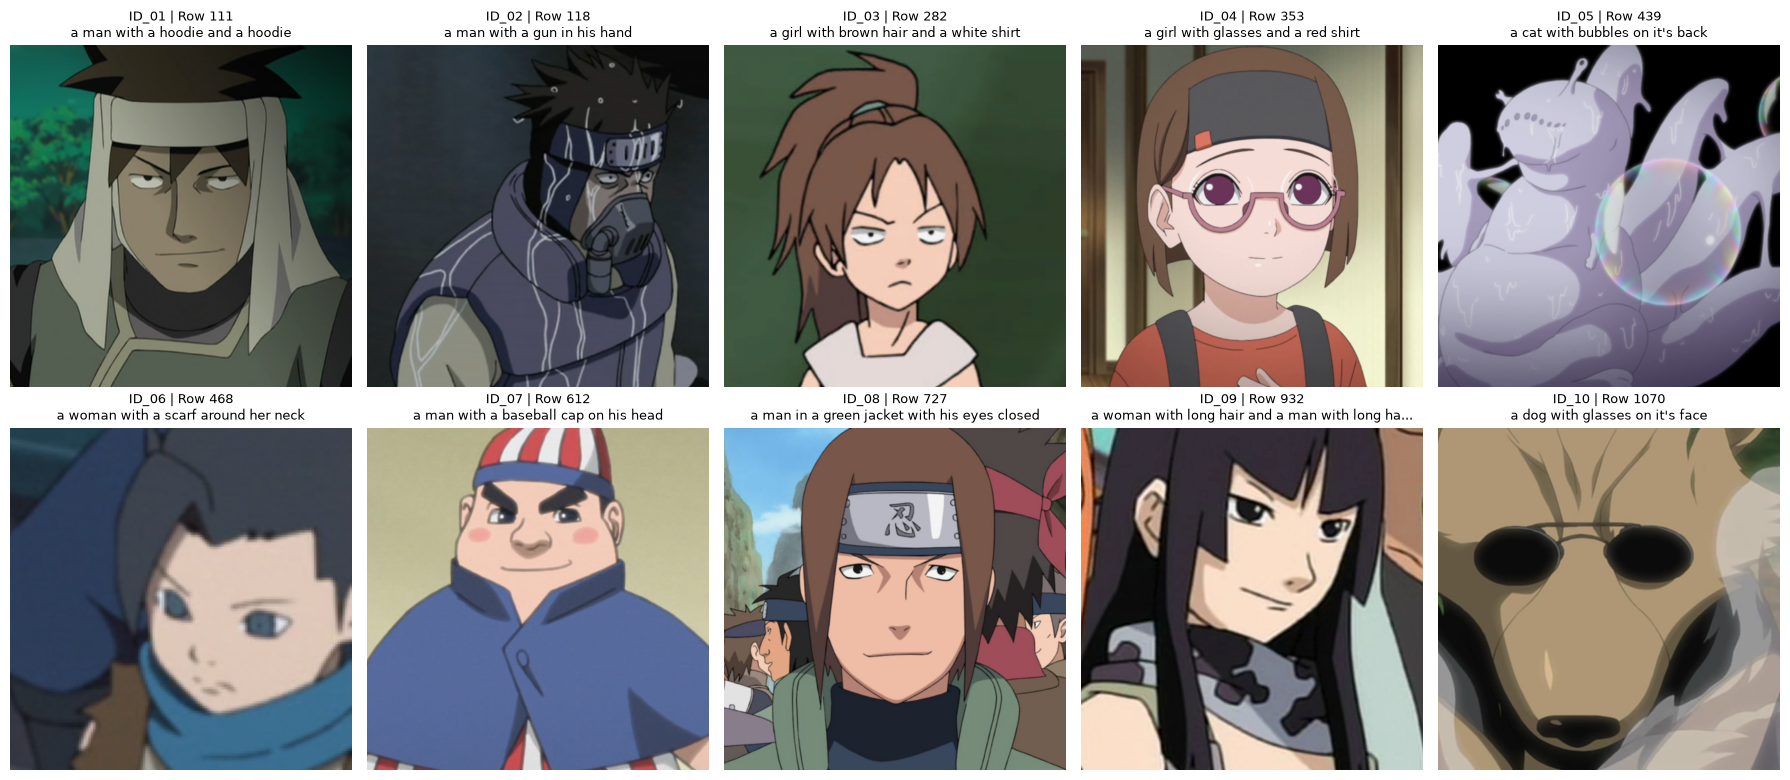


SAVED PROMPT ARTIFACT
--------------------------------------------------------------------------------
In-domain candidates     : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\eval\in_domain_prompt_candidates.csv

IN-DOMAIN PROMPT SELECTION COMPLETE


In [8]:
# ============================================================
# SELECT 10 IN-DOMAIN PROMPTS FROM HELD-OUT TEST DATA
# ============================================================

IN_DOMAIN_PROMPT_COUNT = 10

prompt_rng = np.random.default_rng(
    SEED
)

selected_test_positions = np.sort(
    prompt_rng.choice(
        len(test_indices),
        size=IN_DOMAIN_PROMPT_COUNT,
        replace=False,
    )
)

in_domain_prompt_records = []

for prompt_number, test_position in enumerate(
    selected_test_positions,
    start=1,
):

    original_index = int(
        test_indices[test_position]
    )

    record = raw_dataset[
        original_index
    ]

    caption = record["text"]

    in_domain_prompt_records.append(
        {
            "prompt_id": (
                f"ID_{prompt_number:02d}"
            ),
            "category": "in_domain",
            "original_index": original_index,
            "test_position": int(
                test_position
            ),
            "prompt": caption,
        }
    )


in_domain_prompts_df = pd.DataFrame(
    in_domain_prompt_records
)


# ============================================================
# VERIFY ALL PROMPTS COME FROM TEST SET
# ============================================================

assert (
    len(in_domain_prompts_df)
    == IN_DOMAIN_PROMPT_COUNT
)

assert (
    in_domain_prompts_df[
        "original_index"
    ].is_unique
)

assert all(
    index in test_set
    for index
    in in_domain_prompts_df[
        "original_index"
    ]
)

assert not any(
    index in train_set
    for index
    in in_domain_prompts_df[
        "original_index"
    ]
)


print("=" * 80)
print("IN-DOMAIN EVALUATION PROMPT CANDIDATES")
print("=" * 80)

print(
    in_domain_prompts_df[
        [
            "prompt_id",
            "original_index",
            "prompt",
        ]
    ].to_string(
        index=False
    )
)

print("")
print("INTEGRITY CHECKS")
print("-" * 80)

print(
    "Number of prompts        :",
    len(in_domain_prompts_df),
)

print(
    "All source rows in test  :",
    all(
        index in test_set
        for index
        in in_domain_prompts_df[
            "original_index"
        ]
    ),
)

print(
    "Any source row in train  :",
    any(
        index in train_set
        for index
        in in_domain_prompts_df[
            "original_index"
        ]
    ),
)

print(
    "Unique source rows       :",
    in_domain_prompts_df[
        "original_index"
    ].is_unique,
)


# ============================================================
# VISUAL INSPECTION OF THE 10 SOURCE TEST IMAGES
# ============================================================

fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 8),
)

axes = axes.flatten()

for axis, row in zip(
    axes,
    in_domain_prompt_records,
):

    original_index = row[
        "original_index"
    ]

    record = raw_dataset[
        original_index
    ]

    axis.imshow(
        record["image"]
    )

    prompt_text = row["prompt"]

    if len(prompt_text) > 45:
        display_text = (
            prompt_text[:45]
            + "..."
        )
    else:
        display_text = prompt_text

    axis.set_title(
        f"{row['prompt_id']} | "
        f"Row {original_index}\n"
        f"{display_text}",
        fontsize=9,
    )

    axis.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# SAVE THE PRE-TRAINING IN-DOMAIN PROMPT CANDIDATES
# ============================================================

in_domain_prompt_path = (
    EVAL_ROOT
    / "in_domain_prompt_candidates.csv"
)

in_domain_prompts_df.to_csv(
    in_domain_prompt_path,
    index=False,
)

print("")
print("SAVED PROMPT ARTIFACT")
print("-" * 80)

print(
    f"In-domain candidates     : "
    f"{in_domain_prompt_path}"
)

print("")
print("=" * 80)
print("IN-DOMAIN PROMPT SELECTION COMPLETE")
print("=" * 80)

INITIAL IN-DOMAIN PROMPT REVIEW

ACCEPTED PROMPTS
--------------------------------------------------------------------------------
prompt_id  original_index                                       prompt
    ID_03             282     a girl with brown hair and a white shirt
    ID_04             353          a girl with glasses and a red shirt
    ID_05             439              a cat with bubbles on it's back
    ID_06             468         a woman with a scarf around her neck
    ID_08             727 a man in a green jacket with his eyes closed
    ID_10            1070              a dog with glasses on it's face

REJECTED PROMPTS
--------------------------------------------------------------------------------
prompt_id  original_index                                          prompt
    ID_01             111                a man with a hoodie and a hoodie
    ID_02             118                    a man with a gun in his hand
    ID_07             612           a man with a ba

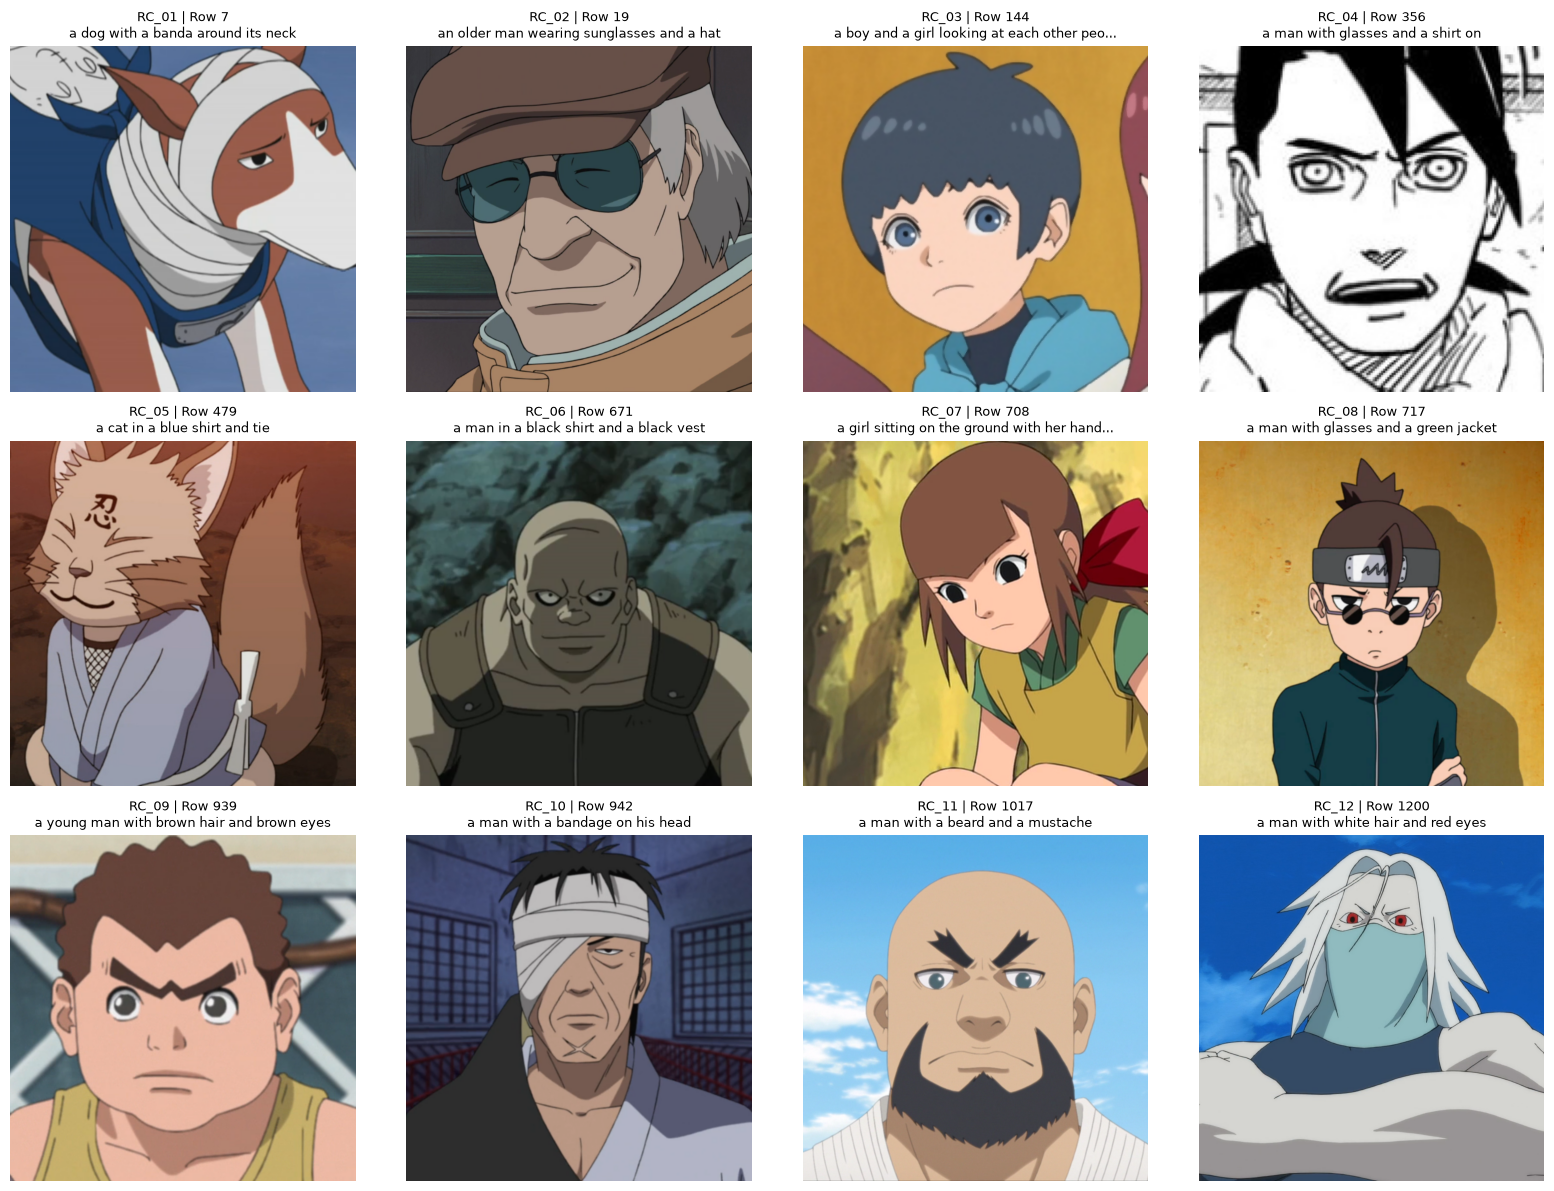


REPLACEMENT-CANDIDATE REVIEW READY


In [9]:
# ============================================================
# REVIEW IN-DOMAIN PROMPTS AND GENERATE REPLACEMENT CANDIDATES
# ============================================================

# Prompts accepted from the initial deterministic sample.
accepted_prompt_ids = [
    "ID_03",
    "ID_04",
    "ID_05",
    "ID_06",
    "ID_08",
    "ID_10",
]

# Prompts rejected before training because their source captions
# are clearly repetitive, ambiguous, or poorly grounded.
rejected_prompt_ids = [
    "ID_01",
    "ID_02",
    "ID_07",
    "ID_09",
]

accepted_prompts_df = (
    in_domain_prompts_df[
        in_domain_prompts_df[
            "prompt_id"
        ].isin(accepted_prompt_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

rejected_prompts_df = (
    in_domain_prompts_df[
        in_domain_prompts_df[
            "prompt_id"
        ].isin(rejected_prompt_ids)
    ]
    .copy()
    .reset_index(drop=True)
)


print("=" * 80)
print("INITIAL IN-DOMAIN PROMPT REVIEW")
print("=" * 80)

print("")
print("ACCEPTED PROMPTS")
print("-" * 80)

print(
    accepted_prompts_df[
        [
            "prompt_id",
            "original_index",
            "prompt",
        ]
    ].to_string(
        index=False
    )
)

print("")
print("REJECTED PROMPTS")
print("-" * 80)

print(
    rejected_prompts_df[
        [
            "prompt_id",
            "original_index",
            "prompt",
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# BUILD UNUSED HELD-OUT TEST CANDIDATE POOL
# ============================================================

already_selected_indices = set(
    in_domain_prompts_df[
        "original_index"
    ].tolist()
)

unused_test_indices = np.array(
    sorted(
        test_set
        - already_selected_indices
    ),
    dtype=int,
)

# Use a different deterministic RNG stream while retaining
# the assignment seed as the base.
replacement_rng = np.random.default_rng(
    SEED + 1
)

REPLACEMENT_POOL_SIZE = 12

replacement_indices = np.sort(
    replacement_rng.choice(
        unused_test_indices,
        size=REPLACEMENT_POOL_SIZE,
        replace=False,
    )
)


replacement_records = []

for candidate_number, original_index in enumerate(
    replacement_indices,
    start=1,
):

    record = raw_dataset[
        int(original_index)
    ]

    replacement_records.append(
        {
            "candidate_id": (
                f"RC_{candidate_number:02d}"
            ),
            "original_index": int(
                original_index
            ),
            "prompt": record["text"],
        }
    )


replacement_candidates_df = pd.DataFrame(
    replacement_records
)


# ============================================================
# INTEGRITY CHECKS
# ============================================================

assert len(
    replacement_candidates_df
) == REPLACEMENT_POOL_SIZE

assert (
    replacement_candidates_df[
        "original_index"
    ].is_unique
)

assert all(
    index in test_set
    for index in replacement_candidates_df[
        "original_index"
    ]
)

assert not any(
    index in train_set
    for index in replacement_candidates_df[
        "original_index"
    ]
)

assert not any(
    index in already_selected_indices
    for index in replacement_candidates_df[
        "original_index"
    ]
)


print("")
print("REPLACEMENT CANDIDATES")
print("-" * 80)

print(
    replacement_candidates_df.to_string(
        index=False
    )
)

print("")
print("INTEGRITY CHECKS")
print("-" * 80)

print(
    "Candidate count          :",
    len(replacement_candidates_df),
)

print(
    "All source rows in test  :",
    all(
        index in test_set
        for index in replacement_candidates_df[
            "original_index"
        ]
    ),
)

print(
    "Any source row in train  :",
    any(
        index in train_set
        for index in replacement_candidates_df[
            "original_index"
        ]
    ),
)

print(
    "Overlap with first sample:",
    any(
        index in already_selected_indices
        for index in replacement_candidates_df[
            "original_index"
        ]
    ),
)


# ============================================================
# VISUALIZE REPLACEMENT CANDIDATES
# ============================================================

fig, axes = plt.subplots(
    3,
    4,
    figsize=(16, 12),
)

axes = axes.flatten()

for axis, row in zip(
    axes,
    replacement_records,
):

    original_index = row[
        "original_index"
    ]

    record = raw_dataset[
        original_index
    ]

    axis.imshow(
        record["image"]
    )

    prompt_text = row[
        "prompt"
    ]

    if len(prompt_text) > 42:
        display_text = (
            prompt_text[:42]
            + "..."
        )
    else:
        display_text = prompt_text

    axis.set_title(
        f"{row['candidate_id']} | "
        f"Row {original_index}\n"
        f"{display_text}",
        fontsize=9,
    )

    axis.axis("off")

plt.tight_layout()
plt.show()


print("")
print("=" * 80)
print("REPLACEMENT-CANDIDATE REVIEW READY")
print("=" * 80)

### Final In-Domain Prompt Selection

The initial deterministic test-set sample contained four captions that were rejected before training because they were repetitive, ambiguous, poorly grounded, or linguistically weak.

Replacement candidates were sampled only from unused held-out test rows before model training.

The final 10 in-domain prompts therefore remain fully isolated from the training split while providing clearer and more interpretable evaluation cases.

FINAL 10 IN-DOMAIN EVALUATION PROMPTS
prompt_id source_candidate_id  original_index                                                   prompt
    IN_01               RC_02              19                an older man wearing sunglasses and a hat
    IN_02               ID_03             282                 a girl with brown hair and a white shirt
    IN_03               ID_04             353                      a girl with glasses and a red shirt
    IN_04               ID_05             439                          a cat with bubbles on it's back
    IN_05               ID_06             468                     a woman with a scarf around her neck
    IN_06               RC_07             708 a girl sitting on the ground with her hands on her knees
    IN_07               ID_08             727             a man in a green jacket with his eyes closed
    IN_08               RC_10             942                         a man with a bandage on his head
    IN_09               ID_10      

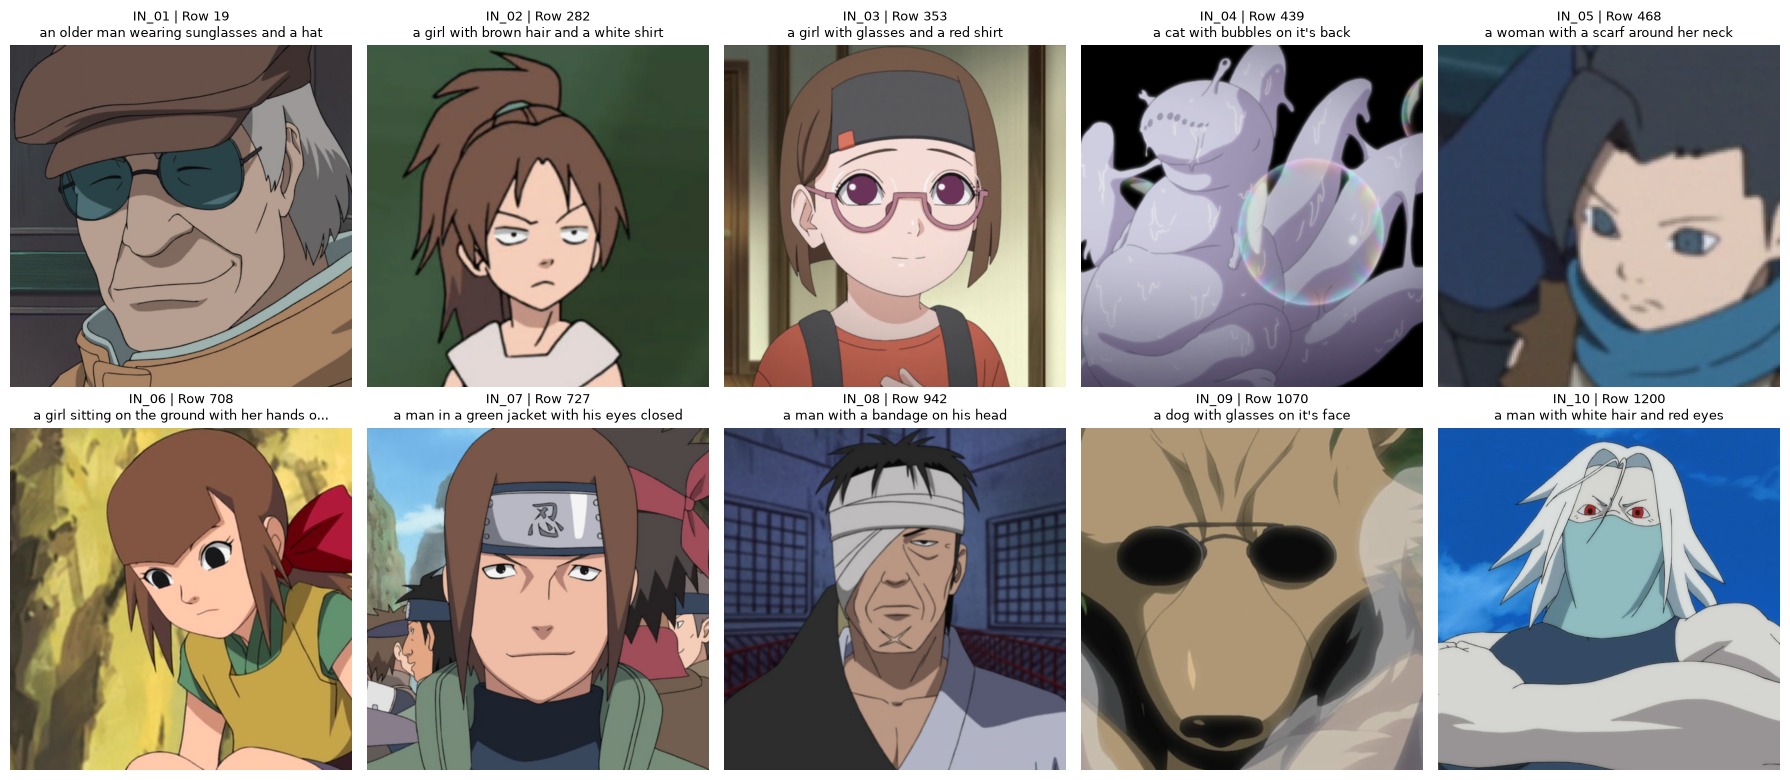


SAVED FINAL PROMPT MANIFEST
--------------------------------------------------------------------------------
Final in-domain prompts   : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\eval\final_in_domain_prompts.csv

FINAL IN-DOMAIN PROMPT SET FROZEN


In [11]:
# ============================================================
# FREEZE FINAL 10 IN-DOMAIN EVALUATION PROMPTS
# ============================================================

# Six accepted prompts from the original deterministic sample.
accepted_source_ids = [
    "ID_03",
    "ID_04",
    "ID_05",
    "ID_06",
    "ID_08",
    "ID_10",
]

# Four visually and semantically grounded replacements.
replacement_source_ids = [
    "RC_02",
    "RC_07",
    "RC_10",
    "RC_12",
]


# ------------------------------------------------------------
# Collect accepted original prompts
# ------------------------------------------------------------

accepted_final = (
    in_domain_prompts_df[
        in_domain_prompts_df[
            "prompt_id"
        ].isin(
            accepted_source_ids
        )
    ][
        [
            "prompt_id",
            "original_index",
            "prompt",
        ]
    ]
    .copy()
)

accepted_final = accepted_final.rename(
    columns={
        "prompt_id": "source_candidate_id",
    }
)

accepted_final[
    "selection_source"
] = "initial_sample"


# ------------------------------------------------------------
# Collect chosen replacement prompts
# ------------------------------------------------------------

replacement_final = (
    replacement_candidates_df[
        replacement_candidates_df[
            "candidate_id"
        ].isin(
            replacement_source_ids
        )
    ][
        [
            "candidate_id",
            "original_index",
            "prompt",
        ]
    ]
    .copy()
)

replacement_final = replacement_final.rename(
    columns={
        "candidate_id": "source_candidate_id",
    }
)

replacement_final[
    "selection_source"
] = "replacement_pool"


# ------------------------------------------------------------
# Combine and sort by original dataset index
# ------------------------------------------------------------

final_in_domain_df = pd.concat(
    [
        accepted_final,
        replacement_final,
    ],
    ignore_index=True,
)

final_in_domain_df = (
    final_in_domain_df
    .sort_values(
        "original_index"
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Assign final evaluation prompt IDs
# ------------------------------------------------------------

final_in_domain_df.insert(
    0,
    "prompt_id",
    [
        f"IN_{number:02d}"
        for number
        in range(
            1,
            len(final_in_domain_df) + 1,
        )
    ],
)

final_in_domain_df[
    "category"
] = "in_domain"


# ============================================================
# INTEGRITY CHECKS
# ============================================================

assert len(
    final_in_domain_df
) == 10

assert (
    final_in_domain_df[
        "original_index"
    ].is_unique
)

assert all(
    index in test_set
    for index
    in final_in_domain_df[
        "original_index"
    ]
)

assert not any(
    index in train_set
    for index
    in final_in_domain_df[
        "original_index"
    ]
)


# ============================================================
# DISPLAY FINAL PROMPT TABLE
# ============================================================

print("=" * 80)
print("FINAL 10 IN-DOMAIN EVALUATION PROMPTS")
print("=" * 80)

print(
    final_in_domain_df[
        [
            "prompt_id",
            "source_candidate_id",
            "original_index",
            "prompt",
        ]
    ].to_string(
        index=False
    )
)

print("")
print("INTEGRITY CHECKS")
print("-" * 80)

print(
    "Final prompt count       :",
    len(final_in_domain_df),
)

print(
    "All prompts from test    :",
    all(
        index in test_set
        for index
        in final_in_domain_df[
            "original_index"
        ]
    ),
)

print(
    "Any prompt from train    :",
    any(
        index in train_set
        for index
        in final_in_domain_df[
            "original_index"
        ]
    ),
)

print(
    "Unique original rows     :",
    final_in_domain_df[
        "original_index"
    ].is_unique,
)

# ============================================================
# VISUALIZE FINAL 10
# ============================================================

fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 8),
)

axes = axes.flatten()

for axis, (_, row) in zip(
    axes,
    final_in_domain_df.iterrows(),
):

    original_index = int(
        row[
            "original_index"
        ]
    )

    record = raw_dataset[
        original_index
    ]

    axis.imshow(
        record["image"]
    )

    prompt_text = row[
        "prompt"
    ]

    display_text = (
        prompt_text[:45]
        + "..."
        if len(prompt_text) > 45
        else prompt_text
    )

    axis.set_title(
        f"{row['prompt_id']} | "
        f"Row {original_index}\n"
        f"{display_text}",
        fontsize=9,
    )

    axis.axis("off")

plt.tight_layout()
plt.show()
# ============================================================
# SAVE FINAL IN-DOMAIN PROMPT MANIFEST
# ============================================================

final_in_domain_path = (
    EVAL_ROOT
    / "final_in_domain_prompts.csv"
)

final_in_domain_df.to_csv(
    final_in_domain_path,
    index=False,
)

print("")
print("SAVED FINAL PROMPT MANIFEST")
print("-" * 80)

print(
    f"Final in-domain prompts   : "
    f"{final_in_domain_path}"
)

print("")
print("=" * 80)
print("FINAL IN-DOMAIN PROMPT SET FROZEN")
print("=" * 80)

### Out-of-Domain Evaluation Prompts

Five out-of-domain prompts are defined before fine-tuning.

These prompts intentionally describe concepts and scenes that are substantially different from the Naruto character-image training domain. They are kept relatively simple so that this category primarily measures out-of-domain generalization rather than compositional reasoning.

The out-of-domain set covers:

- automobiles;
- food;
- architecture;
- natural landscapes;
- everyday objects.

These prompts are fixed before model training and will be used unchanged for the Base Model, Run 1, and Run 2.

In [12]:
# ============================================================
# DEFINE AND FREEZE 5 OUT-OF-DOMAIN PROMPTS
# ============================================================

out_of_domain_records = [
    {
        "prompt_id": "OOD_01",
        "category": "out_of_domain",
        "prompt": (
            "a red vintage car parked on a quiet city street"
        ),
    },
    {
        "prompt_id": "OOD_02",
        "category": "out_of_domain",
        "prompt": (
            "a bowl of fresh strawberries on a wooden table"
        ),
    },
    {
        "prompt_id": "OOD_03",
        "category": "out_of_domain",
        "prompt": (
            "a modern glass skyscraper under a clear blue sky"
        ),
    },
    {
        "prompt_id": "OOD_04",
        "category": "out_of_domain",
        "prompt": (
            "a lighthouse on a rocky coast at sunset"
        ),
    },
    {
        "prompt_id": "OOD_05",
        "category": "out_of_domain",
        "prompt": (
            "a ceramic coffee mug beside an open book"
        ),
    },
]


out_of_domain_df = pd.DataFrame(
    out_of_domain_records
)


# ============================================================
# INTEGRITY CHECKS
# ============================================================

assert len(
    out_of_domain_df
) == 5

assert (
    out_of_domain_df[
        "prompt_id"
    ].is_unique
)

assert (
    out_of_domain_df[
        "prompt"
    ].is_unique
)

assert (
    out_of_domain_df[
        "category"
    ] == "out_of_domain"
).all()

assert all(
    isinstance(prompt, str)
    and prompt.strip() != ""
    for prompt
    in out_of_domain_df[
        "prompt"
    ]
)


# ============================================================
# DISPLAY PROMPT TABLE
# ============================================================

print("=" * 80)
print("FINAL 5 OUT-OF-DOMAIN EVALUATION PROMPTS")
print("=" * 80)

print(
    out_of_domain_df.to_string(
        index=False
    )
)

print("")
print("INTEGRITY CHECKS")
print("-" * 80)

print(
    "Prompt count             :",
    len(out_of_domain_df),
)

print(
    "Unique prompt IDs        :",
    out_of_domain_df[
        "prompt_id"
    ].is_unique,
)

print(
    "Unique prompt text       :",
    out_of_domain_df[
        "prompt"
    ].is_unique,
)

print(
    "All prompts non-empty    :",
    all(
        isinstance(prompt, str)
        and prompt.strip() != ""
        for prompt
        in out_of_domain_df[
            "prompt"
        ]
    ),
)


# ============================================================
# SAVE OUT-OF-DOMAIN MANIFEST
# ============================================================

out_of_domain_path = (
    EVAL_ROOT
    / "out_of_domain_prompts.csv"
)

out_of_domain_df.to_csv(
    out_of_domain_path,
    index=False,
)

print("")
print("SAVED OUT-OF-DOMAIN PROMPT MANIFEST")
print("-" * 80)

print(
    f"Out-of-domain prompts     : "
    f"{out_of_domain_path}"
)

print("")
print("=" * 80)
print("OUT-OF-DOMAIN PROMPT SET FROZEN")
print("=" * 80)

FINAL 5 OUT-OF-DOMAIN EVALUATION PROMPTS
prompt_id      category                                           prompt
   OOD_01 out_of_domain  a red vintage car parked on a quiet city street
   OOD_02 out_of_domain   a bowl of fresh strawberries on a wooden table
   OOD_03 out_of_domain a modern glass skyscraper under a clear blue sky
   OOD_04 out_of_domain          a lighthouse on a rocky coast at sunset
   OOD_05 out_of_domain         a ceramic coffee mug beside an open book

INTEGRITY CHECKS
--------------------------------------------------------------------------------
Prompt count             : 5
Unique prompt IDs        : True
Unique prompt text       : True
All prompts non-empty    : True

SAVED OUT-OF-DOMAIN PROMPT MANIFEST
--------------------------------------------------------------------------------
Out-of-domain prompts     : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\eval\out_of_domain_prompts.csv

OUT-OF-DOMAIN PROMPT SET FROZEN


### Compositional Evaluation Prompts

Five compositional prompts are defined before fine-tuning.

These prompts contain multiple simultaneous constraints such as:

- character attributes;
- clothing;
- objects;
- spatial relationships;
- actions;
- background elements;
- multiple subjects.

The compositional set is primarily domain-relevant so that it evaluates whether fine-tuning improves the model's ability to combine several concepts within the target anime/ninja visual domain.

These prompts are fixed before training and will be used unchanged for the Base Model, Run 1, and Run 2.

In [13]:
# ============================================================
# DEFINE AND FREEZE 5 COMPOSITIONAL PROMPTS
# ============================================================

compositional_records = [
    {
        "prompt_id": "COMP_01",
        "category": "compositional",
        "prompt": (
            "a young ninja with silver hair wearing a blue cloak "
            "standing beside a red torii gate at night"
        ),
        "composition_focus": (
            "character appearance; clothing; object; spatial relation; night scene"
        ),
    },
    {
        "prompt_id": "COMP_02",
        "category": "compositional",
        "prompt": (
            "two anime warriors facing each other, "
            "one holding a sword and the other holding a lantern"
        ),
        "composition_focus": (
            "two subjects; facing relationship; distinct held objects"
        ),
    },
    {
        "prompt_id": "COMP_03",
        "category": "compositional",
        "prompt": (
            "a girl with green eyes and long black hair "
            "sitting under a cherry blossom tree while holding a book"
        ),
        "composition_focus": (
            "facial attribute; hair attribute; pose; location; held object"
        ),
    },
    {
        "prompt_id": "COMP_04",
        "category": "compositional",
        "prompt": (
            "a masked ninja jumping over a river "
            "with snow-covered mountains in the background"
        ),
        "composition_focus": (
            "character accessory; action; foreground scene; background scene"
        ),
    },
    {
        "prompt_id": "COMP_05",
        "category": "compositional",
        "prompt": (
            "three ninja students in different colored outfits "
            "sharing bowls of ramen at an outdoor table"
        ),
        "composition_focus": (
            "three subjects; clothing variation; food objects; shared action; setting"
        ),
    },
]


compositional_df = pd.DataFrame(
    compositional_records
)


# ============================================================
# INTEGRITY CHECKS
# ============================================================

assert len(
    compositional_df
) == 5

assert (
    compositional_df[
        "prompt_id"
    ].is_unique
)

assert (
    compositional_df[
        "prompt"
    ].is_unique
)

assert (
    compositional_df[
        "category"
    ] == "compositional"
).all()

assert all(
    isinstance(prompt, str)
    and prompt.strip() != ""
    for prompt
    in compositional_df[
        "prompt"
    ]
)

assert all(
    isinstance(focus, str)
    and focus.strip() != ""
    for focus
    in compositional_df[
        "composition_focus"
    ]
)


# ============================================================
# DISPLAY PROMPT TABLE
# ============================================================

print("=" * 100)
print("FINAL 5 COMPOSITIONAL EVALUATION PROMPTS")
print("=" * 100)

print(
    compositional_df.to_string(
        index=False
    )
)

print("")
print("INTEGRITY CHECKS")
print("-" * 100)

print(
    "Prompt count             :",
    len(compositional_df),
)

print(
    "Unique prompt IDs        :",
    compositional_df[
        "prompt_id"
    ].is_unique,
)

print(
    "Unique prompt text       :",
    compositional_df[
        "prompt"
    ].is_unique,
)

print(
    "All prompts non-empty    :",
    all(
        isinstance(prompt, str)
        and prompt.strip() != ""
        for prompt
        in compositional_df[
            "prompt"
        ]
    ),
)

print(
    "All focus fields present :",
    all(
        isinstance(focus, str)
        and focus.strip() != ""
        for focus
        in compositional_df[
            "composition_focus"
        ]
    ),
)


# ============================================================
# SAVE COMPOSITIONAL PROMPT MANIFEST
# ============================================================

compositional_path = (
    EVAL_ROOT
    / "compositional_prompts.csv"
)

compositional_df.to_csv(
    compositional_path,
    index=False,
)

print("")
print("SAVED COMPOSITIONAL PROMPT MANIFEST")
print("-" * 100)

print(
    f"Compositional prompts     : "
    f"{compositional_path}"
)

print("")
print("=" * 100)
print("COMPOSITIONAL PROMPT SET FROZEN")
print("=" * 100)

FINAL 5 COMPOSITIONAL EVALUATION PROMPTS
prompt_id      category                                                                                              prompt                                                        composition_focus
  COMP_01 compositional       a young ninja with silver hair wearing a blue cloak standing beside a red torii gate at night    character appearance; clothing; object; spatial relation; night scene
  COMP_02 compositional           two anime warriors facing each other, one holding a sword and the other holding a lantern                 two subjects; facing relationship; distinct held objects
  COMP_03 compositional a girl with green eyes and long black hair sitting under a cherry blossom tree while holding a book            facial attribute; hair attribute; pose; location; held object
  COMP_04 compositional                   a masked ninja jumping over a river with snow-covered mountains in the background          character accessory; action; foregroun

## 6. Final Pre-Training Evaluation Prompt Manifest

The complete 20-prompt evaluation set is frozen before any model fine-tuning.

It contains:

- 10 in-domain prompts drawn exclusively from held-out test captions;
- 5 out-of-domain prompts;
- 5 compositional prompts.

The same 20 prompts will be used unchanged for:

1. the pretrained Base Model;
2. Fine-Tuning Run 1;
3. Fine-Tuning Run 2.

Each model will later generate two images per prompt using seeds **0** and **1**, resulting in 40 generated images per model and 120 images across all three model conditions.

In [16]:
# ============================================================
# BUILD AND FREEZE COMPLETE 20-PROMPT EVALUATION MANIFEST
# ============================================================

# Standardize columns before concatenation.

in_domain_final_for_manifest = (
    final_in_domain_df[
        [
            "prompt_id",
            "category",
            "prompt",
            "original_index",
            "source_candidate_id",
            "selection_source",
        ]
    ]
    .copy()
)

in_domain_final_for_manifest[
    "composition_focus"
] = None


out_of_domain_for_manifest = (
    out_of_domain_df[
        [
            "prompt_id",
            "category",
            "prompt",
        ]
    ]
    .copy()
)

out_of_domain_for_manifest[
    "original_index"
] = None

out_of_domain_for_manifest[
    "source_candidate_id"
] = None

out_of_domain_for_manifest[
    "selection_source"
] = "manual_pretraining_definition"

out_of_domain_for_manifest[
    "composition_focus"
] = None


compositional_for_manifest = (
    compositional_df[
        [
            "prompt_id",
            "category",
            "prompt",
            "composition_focus",
        ]
    ]
    .copy()
)

compositional_for_manifest[
    "original_index"
] = None

compositional_for_manifest[
    "source_candidate_id"
] = None

compositional_for_manifest[
    "selection_source"
] = "manual_pretraining_definition"


# ============================================================
# COMBINE ALL THREE CATEGORIES
# ============================================================

evaluation_prompts_df = pd.concat(
    [
        in_domain_final_for_manifest,
        out_of_domain_for_manifest,
        compositional_for_manifest,
    ],
    ignore_index=True,
)


# Reorder columns into one consistent schema.

evaluation_prompts_df = evaluation_prompts_df[
    [
        "prompt_id",
        "category",
        "prompt",
        "original_index",
        "source_candidate_id",
        "selection_source",
        "composition_focus",
    ]
]


# ============================================================
# ADD FIXED GENERATION SEEDS
# ============================================================

GENERATION_SEEDS = [
    0,
    1,
]

evaluation_prompts_df[
    "generation_seeds"
] = ",".join(
    str(seed)
    for seed in GENERATION_SEEDS
)


# ============================================================
# INTEGRITY CHECKS
# ============================================================

category_counts = (
    evaluation_prompts_df[
        "category"
    ]
    .value_counts()
    .to_dict()
)

assert len(
    evaluation_prompts_df
) == 20

assert category_counts.get(
    "in_domain",
    0,
) == 10

assert category_counts.get(
    "out_of_domain",
    0,
) == 5

assert category_counts.get(
    "compositional",
    0,
) == 5

assert (
    evaluation_prompts_df[
        "prompt_id"
    ].is_unique
)

assert (
    evaluation_prompts_df[
        "prompt"
    ].is_unique
)

assert all(
    isinstance(prompt, str)
    and prompt.strip() != ""
    for prompt
    in evaluation_prompts_df[
        "prompt"
    ]
)

assert GENERATION_SEEDS == [
    0,
    1,
]


# In-domain prompts must remain test-only.

in_domain_manifest_rows = (
    evaluation_prompts_df[
        evaluation_prompts_df[
            "category"
        ] == "in_domain"
    ]
)

assert all(
    int(index) in test_set
    for index
    in in_domain_manifest_rows[
        "original_index"
    ]
)

assert not any(
    int(index) in train_set
    for index
    in in_domain_manifest_rows[
        "original_index"
    ]
)


# ============================================================
# DISPLAY COMPLETE MANIFEST
# ============================================================

print("=" * 120)
print("FINAL 20-PROMPT PRE-TRAINING EVALUATION MANIFEST")
print("=" * 120)

print(
    evaluation_prompts_df[
        [
            "prompt_id",
            "category",
            "prompt",
            "generation_seeds",
        ]
    ].to_string(
        index=False
    )
)

print("")
print("CATEGORY COUNTS")
print("-" * 120)

for category in [
    "in_domain",
    "out_of_domain",
    "compositional",
]:
    print(
        f"{category:<20}: "
        f"{category_counts.get(category, 0)}"
    )

print("")
print("INTEGRITY CHECKS")
print("-" * 120)

print(
    "Total prompts            :",
    len(evaluation_prompts_df),
)

print(
    "Unique prompt IDs        :",
    evaluation_prompts_df[
        "prompt_id"
    ].is_unique,
)

print(
    "Unique prompt text       :",
    evaluation_prompts_df[
        "prompt"
    ].is_unique,
)

print(
    "All prompts non-empty    :",
    all(
        isinstance(prompt, str)
        and prompt.strip() != ""
        for prompt
        in evaluation_prompts_df[
            "prompt"
        ]
    ),
)

print(
    "In-domain prompts in test:",
    all(
        int(index) in test_set
        for index
        in in_domain_manifest_rows[
            "original_index"
        ]
    ),
)

print(
    "Any in-domain in train   :",
    any(
        int(index) in train_set
        for index
        in in_domain_manifest_rows[
            "original_index"
        ]
    ),
)

print(
    "Fixed generation seeds   :",
    GENERATION_SEEDS,
)


# ============================================================
# COMPUTE EXPECTED IMAGE COUNTS
# ============================================================

MODEL_CONDITIONS = [
    "base",
    "run1",
    "run2",
]

images_per_model = (
    len(evaluation_prompts_df)
    * len(GENERATION_SEEDS)
)

total_images = (
    images_per_model
    * len(MODEL_CONDITIONS)
)

print("")
print("PLANNED GENERATION COUNTS")
print("-" * 120)

print(
    f"Prompts per model         : "
    f"{len(evaluation_prompts_df)}"
)

print(
    f"Seeds per prompt          : "
    f"{len(GENERATION_SEEDS)}"
)

print(
    f"Images per model          : "
    f"{images_per_model}"
)

print(
    f"Model conditions          : "
    f"{len(MODEL_CONDITIONS)}"
)

print(
    f"Total planned images      : "
    f"{total_images}"
)


# ============================================================
# SAVE COMPLETE EVALUATION MANIFEST
# ============================================================

evaluation_manifest_path = (
    EVAL_ROOT
    / "evaluation_prompts_20.csv"
)

evaluation_manifest_json_path = (
    EVAL_ROOT
    / "evaluation_prompts_20.json"
)


evaluation_prompts_df.to_csv(
    evaluation_manifest_path,
    index=False,
)


with open(
    evaluation_manifest_json_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        evaluation_prompts_df
        .where(
            pd.notnull(
                evaluation_prompts_df
            ),
            None,
        )
        .to_dict(
            orient="records"
        ),
        file,
        indent=2,
        ensure_ascii=False,
    )


print("")
print("SAVED COMPLETE EVALUATION MANIFEST")
print("-" * 120)

print(
    f"CSV manifest              : "
    f"{evaluation_manifest_path}"
)

print(
    f"JSON manifest             : "
    f"{evaluation_manifest_json_path}"
)

print("")
print("=" * 120)
print("20-PROMPT EVALUATION SET FROZEN BEFORE TRAINING")
print("=" * 120)

FINAL 20-PROMPT PRE-TRAINING EVALUATION MANIFEST
prompt_id      category                                                                                              prompt generation_seeds
    IN_01     in_domain                                                           an older man wearing sunglasses and a hat              0,1
    IN_02     in_domain                                                            a girl with brown hair and a white shirt              0,1
    IN_03     in_domain                                                                 a girl with glasses and a red shirt              0,1
    IN_04     in_domain                                                                     a cat with bubbles on it's back              0,1
    IN_05     in_domain                                                                a woman with a scarf around her neck              0,1
    IN_06     in_domain                                            a girl sitting on the ground with her 

## 7. Base Model Selection and Architecture Verification

The common base model for all experimental conditions is **Stable Diffusion v1.5**.

Repository:

`stable-diffusion-v1-5/stable-diffusion-v1-5`

The repository revision is explicitly pinned before model download so that the Base Model, Run 1, and Run 2 all originate from exactly the same pretrained checkpoint.

Stable Diffusion v1.5 is a latent text-to-image diffusion model operating at a native image resolution of **512 × 512**. Its core pipeline contains:

- a CLIP text encoder and tokenizer;
- a conditional UNet denoiser;
- a variational autoencoder (VAE);
- a diffusion scheduler;
- a safety checker.

Only lightweight repository metadata and configuration files are inspected in this section. Model weights are not loaded into GPU memory yet.

In [17]:
# ============================================================
# PIN AND INSPECT STABLE DIFFUSION V1.5 BASE MODEL
# ============================================================

import json

from huggingface_hub import (
    HfApi,
    hf_hub_download,
)


BASE_MODEL_ID = (
    "stable-diffusion-v1-5/"
    "stable-diffusion-v1-5"
)

EXPECTED_BASE_MODEL_REVISION = (
    "451f4fe16113bff5a5d2269ed5ad43b0592e9a14"
)


# ============================================================
# QUERY HUGGING FACE REPOSITORY METADATA
# ============================================================

hf_api = HfApi()

base_model_info = hf_api.model_info(
    repo_id=BASE_MODEL_ID,
)

BASE_MODEL_REVISION = (
    base_model_info.sha
)


license_name = getattr(
    base_model_info.card_data,
    "license",
    None,
)


print("=" * 100)
print("STABLE DIFFUSION V1.5 BASE MODEL REPOSITORY")
print("=" * 100)

print(
    f"Repository ID             : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Pinned revision           : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"Expected revision         : "
    f"{EXPECTED_BASE_MODEL_REVISION}"
)

print(
    f"Revision matches expected : "
    f"{BASE_MODEL_REVISION == EXPECTED_BASE_MODEL_REVISION}"
)

print(
    f"Private repository        : "
    f"{base_model_info.private}"
)

print(
    f"Gated repository          : "
    f"{base_model_info.gated}"
)

print(
    f"Disabled repository       : "
    f"{base_model_info.disabled}"
)

print(
    f"Pipeline tag              : "
    f"{base_model_info.pipeline_tag}"
)

print(
    f"Library                   : "
    f"{base_model_info.library_name}"
)

print(
    f"License                   : "
    f"{license_name}"
)


# ============================================================
# DOWNLOAD ONLY SMALL CONFIGURATION / METADATA FILES
# ============================================================

metadata_files = {
    "model_index": "model_index.json",
    "unet": "unet/config.json",
    "vae": "vae/config.json",
    "text_encoder": "text_encoder/config.json",
    "scheduler": "scheduler/scheduler_config.json",
    "safety_checker": "safety_checker/config.json",
}


downloaded_metadata_paths = {}

for component, filename in metadata_files.items():

    path = hf_hub_download(
        repo_id=BASE_MODEL_ID,
        filename=filename,
        revision=BASE_MODEL_REVISION,
        cache_dir=str(HF_HUB_CACHE),
    )

    downloaded_metadata_paths[
        component
    ] = path


def load_json_file(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as file:

        return json.load(file)


model_index_config = load_json_file(
    downloaded_metadata_paths[
        "model_index"
    ]
)

unet_config = load_json_file(
    downloaded_metadata_paths[
        "unet"
    ]
)

vae_config = load_json_file(
    downloaded_metadata_paths[
        "vae"
    ]
)

text_encoder_config = load_json_file(
    downloaded_metadata_paths[
        "text_encoder"
    ]
)

scheduler_config = load_json_file(
    downloaded_metadata_paths[
        "scheduler"
    ]
)

safety_checker_config = load_json_file(
    downloaded_metadata_paths[
        "safety_checker"
    ]
)


# ============================================================
# DISPLAY PIPELINE COMPONENTS
# ============================================================

print("")
print("=" * 100)
print("PIPELINE COMPONENTS")
print("=" * 100)

print(
    f"Pipeline class            : "
    f"{model_index_config.get('_class_name')}"
)

for component in [
    "text_encoder",
    "tokenizer",
    "unet",
    "vae",
    "scheduler",
    "safety_checker",
    "feature_extractor",
]:

    print(
        f"{component:<26}: "
        f"{model_index_config.get(component)}"
    )


# ============================================================
# DISPLAY CORE ARCHITECTURE
# ============================================================

print("")
print("=" * 100)
print("CORE ARCHITECTURE METADATA")
print("=" * 100)

print("")
print("UNET")
print("-" * 100)

print(
    f"Class                    : "
    f"{unet_config.get('_class_name')}"
)

print(
    f"Sample size              : "
    f"{unet_config.get('sample_size')}"
)

print(
    f"Input channels           : "
    f"{unet_config.get('in_channels')}"
)

print(
    f"Output channels          : "
    f"{unet_config.get('out_channels')}"
)

print(
    f"Cross-attention dim      : "
    f"{unet_config.get('cross_attention_dim')}"
)

print(
    f"Block output channels    : "
    f"{unet_config.get('block_out_channels')}"
)


print("")
print("VAE")
print("-" * 100)

print(
    f"Class                    : "
    f"{vae_config.get('_class_name')}"
)

print(
    f"Input channels           : "
    f"{vae_config.get('in_channels')}"
)

print(
    f"Output channels          : "
    f"{vae_config.get('out_channels')}"
)

print(
    f"Latent channels          : "
    f"{vae_config.get('latent_channels')}"
)

print(
    f"Sample size              : "
    f"{vae_config.get('sample_size')}"
)

print(
    f"Scaling factor           : "
    f"{vae_config.get('scaling_factor')}"
)


print("")
print("TEXT ENCODER")
print("-" * 100)

print(
    f"Architecture             : "
    f"{text_encoder_config.get('architectures')}"
)

print(
    f"Hidden size              : "
    f"{text_encoder_config.get('hidden_size')}"
)

print(
    f"Intermediate size        : "
    f"{text_encoder_config.get('intermediate_size')}"
)

print(
    f"Attention heads          : "
    f"{text_encoder_config.get('num_attention_heads')}"
)

print(
    f"Hidden layers            : "
    f"{text_encoder_config.get('num_hidden_layers')}"
)

print(
    f"Max text positions       : "
    f"{text_encoder_config.get('max_position_embeddings')}"
)

print(
    f"Vocabulary size          : "
    f"{text_encoder_config.get('vocab_size')}"
)


print("")
print("SCHEDULER")
print("-" * 100)

print(
    f"Class                    : "
    f"{scheduler_config.get('_class_name')}"
)

print(
    f"Training timesteps       : "
    f"{scheduler_config.get('num_train_timesteps')}"
)

print(
    f"Beta schedule            : "
    f"{scheduler_config.get('beta_schedule')}"
)

print(
    f"Prediction type          : "
    f"{scheduler_config.get('prediction_type')}"
)


print("")
print("SAFETY CHECKER")
print("-" * 100)

print(
    f"Architecture             : "
    f"{safety_checker_config.get('architectures')}"
)


# ============================================================
# VERIFY REQUIRED FP16 SAFETENSOR COMPONENTS EXIST
# ============================================================

repository_files = set(
    base_model_info.siblings[
        index
    ].rfilename
    for index
    in range(
        len(base_model_info.siblings)
    )
)

required_fp16_files = [
    (
        "unet/"
        "diffusion_pytorch_model.fp16.safetensors"
    ),
    (
        "vae/"
        "diffusion_pytorch_model.fp16.safetensors"
    ),
    (
        "text_encoder/"
        "model.fp16.safetensors"
    ),
    (
        "safety_checker/"
        "model.fp16.safetensors"
    ),
]

print("")
print("=" * 100)
print("FP16 WEIGHT AVAILABILITY")
print("=" * 100)

all_fp16_present = True

for filename in required_fp16_files:

    exists = (
        filename
        in repository_files
    )

    all_fp16_present = (
        all_fp16_present
        and exists
    )

    print(
        f"{filename:<70}: "
        f"{exists}"
    )

print("")
print(
    f"All required FP16 files  : "
    f"{all_fp16_present}"
)


# ============================================================
# VERIFY LOCAL METADATA CACHE LOCATION
# ============================================================

print("")
print("=" * 100)
print("LOCAL METADATA CACHE")
print("=" * 100)

for component, path in (
    downloaded_metadata_paths.items()
):

    print(
        f"{component:<20}: "
        f"{path}"
    )


all_metadata_local = all(
    str(path)
    .lower()
    .startswith(
        str(
            PART2_ROOT
        ).lower()
    )
    for path
    in downloaded_metadata_paths.values()
)

print("")
print(
    f"All metadata under Part 2: "
    f"{all_metadata_local}"
)


# ============================================================
# FINAL VALIDATION
# ============================================================

assert (
    BASE_MODEL_REVISION
    == EXPECTED_BASE_MODEL_REVISION
)

assert (
    base_model_info.private
    is False
)

assert (
    base_model_info.gated
    is False
)

assert (
    model_index_config.get(
        "_class_name"
    )
    == "StableDiffusionPipeline"
)

assert (
    license_name
    == "creativeml-openrail-m"
)

assert all_fp16_present

assert all_metadata_local


print("")
print("=" * 100)
print("BASE MODEL METADATA VERIFICATION COMPLETE")
print("=" * 100)

STABLE DIFFUSION V1.5 BASE MODEL REPOSITORY
Repository ID             : stable-diffusion-v1-5/stable-diffusion-v1-5
Pinned revision           : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Expected revision         : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Revision matches expected : True
Private repository        : False
Gated repository          : False
Disabled repository       : False
Pipeline tag              : text-to-image
Library                   : diffusers
License                   : creativeml-openrail-m

PIPELINE COMPONENTS
Pipeline class            : StableDiffusionPipeline
text_encoder              : ['transformers', 'CLIPTextModel']
tokenizer                 : ['transformers', 'CLIPTokenizer']
unet                      : ['diffusers', 'UNet2DConditionModel']
vae                       : ['diffusers', 'AutoencoderKL']
scheduler                 : ['diffusers', 'PNDMScheduler']
safety_checker            : ['stable_diffusion', 'StableDiffusionSafetyChecker']
feature_extractor  

### Base Model Download and Local GPU Smoke Test

STABLE DIFFUSION V1.5 LOCAL GPU SMOKE TEST
Base model               : stable-diffusion-v1-5/stable-diffusion-v1-5
Pinned revision           : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Weight variant            : fp16
Weight format             : safetensors
GPU                       : NVIDIA GeForce RTX 3060 Laptop GPU
GPU VRAM                  : 6.00 GB

LOADING PINNED FP16 PIPELINE


Loading pipeline components...: 100%|██████████| 7/7 [00:01<00:00,  3.54it/s]



PIPELINE VERIFICATION
----------------------------------------------------------------------------------------------------
Pipeline class            : StableDiffusionPipeline
UNet class                : UNet2DConditionModel
VAE class                 : AutoencoderKL
Text encoder class        : CLIPTextModel
Scheduler class           : PNDMScheduler
Safety checker present    : True
UNet dtype                : torch.float16
VAE dtype                 : torch.float16
Text encoder dtype        : torch.float16
Pipeline load time        : 2.21 seconds

MEMORY STRATEGY
----------------------------------------------------------------------------------------------------
Model CPU offload        : enabled
VAE slicing              : enabled
Attention slicing        : disabled
Sequential CPU offload   : disabled

RUNNING ONE-IMAGE SMOKE TEST
Prompt ID                 : IN_01
Prompt                    : an older man wearing sunglasses and a hat
Seed                      : 0
Resolution               

100%|██████████| 20/20 [00:24<00:00,  1.23s/it]


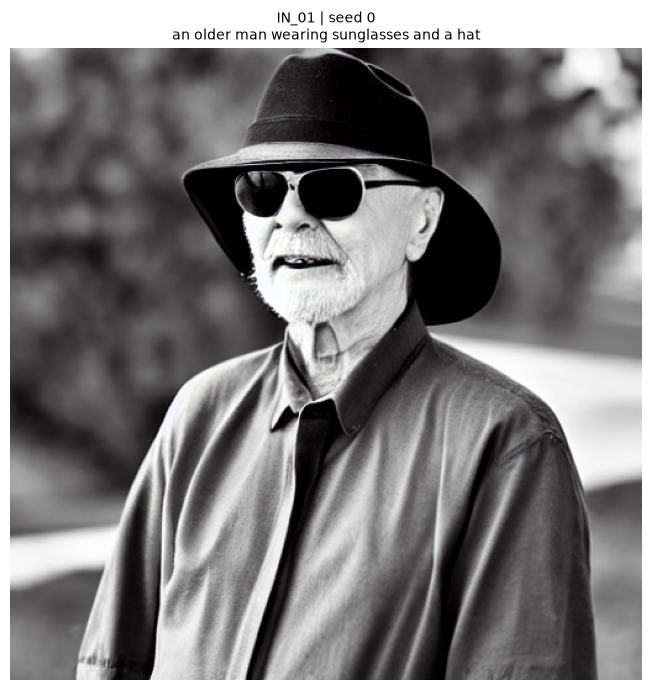


SMOKE TEST RESULTS
Generated image size      : (512, 512)
Generation time           : 33.08 seconds
Peak GPU allocated        : 2.886 GB
Peak GPU reserved         : 3.127 GB
NSFW detected             : False
Image saved               : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\generated_images\base_smoke_test\IN_01_seed_0_smoke.png
Summary saved             : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\results\base_model_smoke_test.json

POST-CLEANUP GPU MEMORY
----------------------------------------------------------------------------------------------------
Allocated                 : 0.576 GB
Reserved                  : 0.590 GB

BASE MODEL GPU SMOKE TEST COMPLETE


In [19]:
# ============================================================
# STABLE DIFFUSION V1.5 DOWNLOAD + GPU SMOKE TEST
# ============================================================

import gc
import json
import time

import matplotlib.pyplot as plt
import torch

from diffusers import StableDiffusionPipeline


# ============================================================
# SMOKE-TEST CONFIGURATION
# ============================================================

SMOKE_PROMPT_ID = "IN_01"
SMOKE_SEED = 0

SMOKE_HEIGHT = 512
SMOKE_WIDTH = 512

SMOKE_INFERENCE_STEPS = 20
SMOKE_GUIDANCE_SCALE = 7.5


# Retrieve the prompt from the already frozen manifest rather
# than typing a new prompt here.

smoke_prompt_rows = (
    evaluation_prompts_df[
        evaluation_prompts_df[
            "prompt_id"
        ] == SMOKE_PROMPT_ID
    ]
)

assert len(smoke_prompt_rows) == 1

SMOKE_PROMPT = (
    smoke_prompt_rows
    .iloc[0]["prompt"]
)


# ============================================================
# OUTPUT LOCATIONS
# ============================================================

SMOKE_OUTPUT_DIR = (
    PART2_ROOT
    / "generated_images"
    / "base_smoke_test"
)

SMOKE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_ROOT = (
    PART2_ROOT
    / "results"
)

RESULTS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

smoke_image_path = (
    SMOKE_OUTPUT_DIR
    / (
        f"{SMOKE_PROMPT_ID}"
        f"_seed_{SMOKE_SEED}"
        f"_smoke.png"
    )
)

smoke_summary_path = (
    RESULTS_ROOT
    / "base_model_smoke_test.json"
)

# ============================================================
# CLEAR GPU STATE BEFORE LOADING
# ============================================================

# If a previous smoke-test attempt stopped after creating the
# pipeline, explicitly release that object before reloading.
if "pipe" in globals():
    del pipe

gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()
print("=" * 100)
print("STABLE DIFFUSION V1.5 LOCAL GPU SMOKE TEST")
print("=" * 100)

print(
    f"Base model               : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Pinned revision           : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"Weight variant            : "
    f"fp16"
)

print(
    f"Weight format             : "
    f"safetensors"
)

print(
    f"GPU                       : "
    f"{torch.cuda.get_device_name(0)}"
)

print(
    f"GPU VRAM                  : "
    f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
)


# ============================================================
# DOWNLOAD AND LOAD PIPELINE
# ============================================================

print("")
print("=" * 100)
print("LOADING PINNED FP16 PIPELINE")
print("=" * 100)

load_start = time.perf_counter()

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL_ID,
    revision=BASE_MODEL_REVISION,
    variant="fp16",
    dtype=torch.float16,
    use_safetensors=True,
    cache_dir=str(HF_HUB_CACHE),
    low_cpu_mem_usage=True,
)

load_seconds = (
    time.perf_counter()
    - load_start
)


# ============================================================
# VERIFY INSTANTIATED COMPONENTS
# ============================================================

print("")
print("PIPELINE VERIFICATION")
print("-" * 100)

print(
    f"Pipeline class            : "
    f"{pipe.__class__.__name__}"
)

print(
    f"UNet class                : "
    f"{pipe.unet.__class__.__name__}"
)

print(
    f"VAE class                 : "
    f"{pipe.vae.__class__.__name__}"
)

print(
    f"Text encoder class        : "
    f"{pipe.text_encoder.__class__.__name__}"
)

print(
    f"Scheduler class           : "
    f"{pipe.scheduler.__class__.__name__}"
)

print(
    f"Safety checker present    : "
    f"{pipe.safety_checker is not None}"
)

print(
    f"UNet dtype                : "
    f"{pipe.unet.dtype}"
)

print(
    f"VAE dtype                 : "
    f"{pipe.vae.dtype}"
)

print(
    f"Text encoder dtype        : "
    f"{pipe.text_encoder.dtype}"
)

print(
    f"Pipeline load time        : "
    f"{load_seconds:.2f} seconds"
)


assert (
    pipe.__class__.__name__
    == "StableDiffusionPipeline"
)

assert (
    pipe.safety_checker
    is not None
)

assert (
    pipe.unet.dtype
    == torch.float16
)

assert (
    pipe.vae.dtype
    == torch.float16
)

assert (
    pipe.text_encoder.dtype
    == torch.float16
)


# ============================================================
# MEMORY-SAVING INFERENCE CONFIGURATION
# ============================================================

# Keep only the currently required major model component
# on the GPU.
pipe.enable_model_cpu_offload()

# Diffusers 0.42.x enables VAE slicing directly on the VAE.
pipe.vae.enable_slicing()


print("")
print("MEMORY STRATEGY")
print("-" * 100)

print(
    "Model CPU offload        : enabled"
)

print(
    "VAE slicing              : enabled"
)

print(
    "Attention slicing        : disabled"
)

print(
    "Sequential CPU offload   : disabled"
)


# ============================================================
# PREPARE DETERMINISTIC GENERATOR
# ============================================================

generator = (
    torch.Generator(
        device="cpu"
    )
    .manual_seed(
        SMOKE_SEED
    )
)


# Reset peak statistics immediately before inference.

gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

torch.cuda.synchronize()


# ============================================================
# RUN ONE IMAGE GENERATION
# ============================================================

print("")
print("=" * 100)
print("RUNNING ONE-IMAGE SMOKE TEST")
print("=" * 100)

print(
    f"Prompt ID                 : "
    f"{SMOKE_PROMPT_ID}"
)

print(
    f"Prompt                    : "
    f"{SMOKE_PROMPT}"
)

print(
    f"Seed                      : "
    f"{SMOKE_SEED}"
)

print(
    f"Resolution                : "
    f"{SMOKE_WIDTH} x {SMOKE_HEIGHT}"
)

print(
    f"Inference steps           : "
    f"{SMOKE_INFERENCE_STEPS}"
)

print(
    f"Guidance scale            : "
    f"{SMOKE_GUIDANCE_SCALE}"
)


generation_start = time.perf_counter()

with torch.inference_mode():

    smoke_output = pipe(
        prompt=SMOKE_PROMPT,
        height=SMOKE_HEIGHT,
        width=SMOKE_WIDTH,
        num_inference_steps=(
            SMOKE_INFERENCE_STEPS
        ),
        guidance_scale=(
            SMOKE_GUIDANCE_SCALE
        ),
        generator=generator,
        num_images_per_prompt=1,
    )


torch.cuda.synchronize()

generation_seconds = (
    time.perf_counter()
    - generation_start
)


# ============================================================
# COLLECT GPU MEMORY STATISTICS
# ============================================================

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ============================================================
# EXTRACT AND VERIFY IMAGE
# ============================================================

assert len(
    smoke_output.images
) == 1

smoke_image = (
    smoke_output.images[0]
)

assert smoke_image.size == (
    SMOKE_WIDTH,
    SMOKE_HEIGHT,
)


nsfw_detected = None

if (
    hasattr(
        smoke_output,
        "nsfw_content_detected",
    )
    and smoke_output.nsfw_content_detected
    is not None
):

    nsfw_detected = bool(
        smoke_output
        .nsfw_content_detected[0]
    )


smoke_image.save(
    smoke_image_path
)


# ============================================================
# DISPLAY GENERATED IMAGE
# ============================================================

plt.figure(
    figsize=(7, 7)
)

plt.imshow(
    smoke_image
)

plt.title(
    f"{SMOKE_PROMPT_ID} | "
    f"seed {SMOKE_SEED}\n"
    f"{SMOKE_PROMPT}",
    fontsize=10,
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ============================================================
# SAVE PROGRAMMATIC SMOKE-TEST RECORD
# ============================================================

smoke_test_summary = {
    "base_model_id": (
        BASE_MODEL_ID
    ),
    "base_model_revision": (
        BASE_MODEL_REVISION
    ),
    "weight_variant": "fp16",
    "weight_format": "safetensors",
    "pipeline_class": (
        pipe.__class__.__name__
    ),
    "scheduler_class": (
        pipe.scheduler
        .__class__.__name__
    ),
    "safety_checker_enabled": (
        pipe.safety_checker
        is not None
    ),
    "memory_strategy": (
        "model_cpu_offload"
    ),
    "vae_slicing": True,
    "attention_slicing": False,
    "prompt_id": (
        SMOKE_PROMPT_ID
    ),
    "prompt": (
        SMOKE_PROMPT
    ),
    "seed": (
        SMOKE_SEED
    ),
    "height": (
        SMOKE_HEIGHT
    ),
    "width": (
        SMOKE_WIDTH
    ),
    "num_inference_steps": (
        SMOKE_INFERENCE_STEPS
    ),
    "guidance_scale": (
        SMOKE_GUIDANCE_SCALE
    ),
    "load_seconds": (
        round(
            load_seconds,
            4,
        )
    ),
    "generation_seconds": (
        round(
            generation_seconds,
            4,
        )
    ),
    "peak_gpu_memory_allocated_gb": (
        round(
            peak_allocated_gb,
            4,
        )
    ),
    "peak_gpu_memory_reserved_gb": (
        round(
            peak_reserved_gb,
            4,
        )
    ),
    "nsfw_content_detected": (
        nsfw_detected
    ),
    "image_path": (
        str(
            smoke_image_path
        )
    ),
}


with open(
    smoke_summary_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        smoke_test_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL RESULTS
# ============================================================

print("")
print("=" * 100)
print("SMOKE TEST RESULTS")
print("=" * 100)

print(
    f"Generated image size      : "
    f"{smoke_image.size}"
)

print(
    f"Generation time           : "
    f"{generation_seconds:.2f} seconds"
)

print(
    f"Peak GPU allocated        : "
    f"{peak_allocated_gb:.3f} GB"
)

print(
    f"Peak GPU reserved         : "
    f"{peak_reserved_gb:.3f} GB"
)

print(
    f"NSFW detected             : "
    f"{nsfw_detected}"
)

print(
    f"Image saved               : "
    f"{smoke_image_path}"
)

print(
    f"Summary saved             : "
    f"{smoke_summary_path}"
)


# ============================================================
# RELEASE PIPELINE AND GPU MEMORY
# ============================================================

del smoke_output
del smoke_image
del generator
del pipe

gc.collect()

torch.cuda.empty_cache()

post_cleanup_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)

post_cleanup_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 100)

print(
    f"Allocated                 : "
    f"{post_cleanup_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{post_cleanup_reserved_gb:.3f} GB"
)

print("")
print("=" * 100)
print("BASE MODEL GPU SMOKE TEST COMPLETE")
print("=" * 100)

## 8. Frozen Generation Protocol

The image-generation protocol is fixed before official Base Model generation and before model fine-tuning.

All three experimental conditions will use exactly the same generation settings:

1. Base Stable Diffusion v1.5;
2. Fine-Tuning Run 1;
3. Fine-Tuning Run 2.

Fixed generation settings:

- Resolution: **512 × 512**
- Scheduler / sampler: **PNDMScheduler**
- Inference steps: **30**
- Classifier-free guidance scale: **7.5**
- Seeds: **0 and 1**
- Negative prompt: **None**
- Images per prompt per seed: **1**
- Safety checker: **enabled**
- Model precision: **FP16**
- Memory strategy: **model CPU offload**

The 20-prompt manifest was already frozen before model work. Therefore, each model condition will generate:

`20 prompts × 2 seeds = 40 images`

and the complete experiment will contain:

`40 images × 3 model conditions = 120 images`.

No generation hyperparameter will be changed between the Base Model, Run 1, and Run 2.

In [20]:
# ============================================================
# FREEZE OFFICIAL IMAGE-GENERATION PROTOCOL
# ============================================================

import json


# ============================================================
# FIXED EVALUATION GENERATION SETTINGS
# ============================================================

EVAL_HEIGHT = 512
EVAL_WIDTH = 512

EVAL_SCHEDULER_CLASS = (
    "PNDMScheduler"
)

EVAL_INFERENCE_STEPS = 30

EVAL_GUIDANCE_SCALE = 7.5

EVAL_GENERATION_SEEDS = [
    0,
    1,
]

EVAL_NEGATIVE_PROMPT = None

EVAL_IMAGES_PER_SEED = 1

EVAL_DTYPE = "float16"

EVAL_MEMORY_STRATEGY = (
    "model_cpu_offload"
)

EVAL_SAFETY_CHECKER = True


# ============================================================
# VERIFY AGAINST THE ALREADY FROZEN PROMPT MANIFEST
# ============================================================

assert len(
    evaluation_prompts_df
) == 20

assert EVAL_GENERATION_SEEDS == [
    0,
    1,
]

assert EVAL_HEIGHT == 512

assert EVAL_WIDTH == 512

assert EVAL_SCHEDULER_CLASS == (
    "PNDMScheduler"
)

assert EVAL_INFERENCE_STEPS > 0

assert EVAL_GUIDANCE_SCALE > 0

assert EVAL_IMAGES_PER_SEED == 1

assert EVAL_SAFETY_CHECKER is True


# ============================================================
# EXPECTED GENERATION COUNTS
# ============================================================

EVAL_PROMPT_COUNT = len(
    evaluation_prompts_df
)

EVAL_SEED_COUNT = len(
    EVAL_GENERATION_SEEDS
)

EVAL_IMAGES_PER_MODEL = (
    EVAL_PROMPT_COUNT
    * EVAL_SEED_COUNT
    * EVAL_IMAGES_PER_SEED
)

EVAL_MODEL_COUNT = 3

EVAL_TOTAL_IMAGES = (
    EVAL_IMAGES_PER_MODEL
    * EVAL_MODEL_COUNT
)


assert EVAL_IMAGES_PER_MODEL == 40

assert EVAL_TOTAL_IMAGES == 120


# ============================================================
# RECORD RELEVANT PINNED SCHEDULER CONFIGURATION
# ============================================================

frozen_scheduler_config = {
    "class_name": (
        scheduler_config.get(
            "_class_name"
        )
    ),
    "num_train_timesteps": (
        scheduler_config.get(
            "num_train_timesteps"
        )
    ),
    "beta_start": (
        scheduler_config.get(
            "beta_start"
        )
    ),
    "beta_end": (
        scheduler_config.get(
            "beta_end"
        )
    ),
    "beta_schedule": (
        scheduler_config.get(
            "beta_schedule"
        )
    ),
    "skip_prk_steps": (
        scheduler_config.get(
            "skip_prk_steps"
        )
    ),
    "steps_offset": (
        scheduler_config.get(
            "steps_offset"
        )
    ),
    "set_alpha_to_one": (
        scheduler_config.get(
            "set_alpha_to_one"
        )
    ),
    "prediction_type": (
        scheduler_config.get(
            "prediction_type"
        )
    ),
}


# ============================================================
# BUILD COMPLETE GENERATION PROTOCOL RECORD
# ============================================================

generation_protocol = {
    "protocol_status": (
        "frozen_before_official_generation"
    ),
    "base_model_id": (
        BASE_MODEL_ID
    ),
    "base_model_revision": (
        BASE_MODEL_REVISION
    ),
    "resolution": {
        "height": EVAL_HEIGHT,
        "width": EVAL_WIDTH,
    },
    "scheduler": (
        EVAL_SCHEDULER_CLASS
    ),
    "scheduler_config": (
        frozen_scheduler_config
    ),
    "num_inference_steps": (
        EVAL_INFERENCE_STEPS
    ),
    "guidance_scale": (
        EVAL_GUIDANCE_SCALE
    ),
    "generation_seeds": (
        EVAL_GENERATION_SEEDS
    ),
    "negative_prompt": (
        EVAL_NEGATIVE_PROMPT
    ),
    "images_per_seed": (
        EVAL_IMAGES_PER_SEED
    ),
    "dtype": (
        EVAL_DTYPE
    ),
    "safety_checker_enabled": (
        EVAL_SAFETY_CHECKER
    ),
    "memory_strategy": (
        EVAL_MEMORY_STRATEGY
    ),
    "prompt_count": (
        EVAL_PROMPT_COUNT
    ),
    "images_per_model": (
        EVAL_IMAGES_PER_MODEL
    ),
    "model_conditions": [
        "base",
        "run1",
        "run2",
    ],
    "total_planned_images": (
        EVAL_TOTAL_IMAGES
    ),
}


# ============================================================
# SAVE FROZEN PROTOCOL
# ============================================================

generation_protocol_path = (
    EVAL_ROOT
    / "generation_protocol.json"
)


with open(
    generation_protocol_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        generation_protocol,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# DISPLAY FROZEN PROTOCOL
# ============================================================

print("=" * 100)
print("FROZEN OFFICIAL GENERATION PROTOCOL")
print("=" * 100)

print(
    f"Base model                : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Base revision             : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"Resolution                : "
    f"{EVAL_WIDTH} x {EVAL_HEIGHT}"
)

print(
    f"Scheduler / sampler       : "
    f"{EVAL_SCHEDULER_CLASS}"
)

print(
    f"Inference steps           : "
    f"{EVAL_INFERENCE_STEPS}"
)

print(
    f"Guidance scale            : "
    f"{EVAL_GUIDANCE_SCALE}"
)

print(
    f"Seeds                     : "
    f"{EVAL_GENERATION_SEEDS}"
)

print(
    f"Negative prompt           : "
    f"{EVAL_NEGATIVE_PROMPT}"
)

print(
    f"Images per seed           : "
    f"{EVAL_IMAGES_PER_SEED}"
)

print(
    f"Precision                 : "
    f"{EVAL_DTYPE}"
)

print(
    f"Safety checker            : "
    f"{EVAL_SAFETY_CHECKER}"
)

print(
    f"Memory strategy           : "
    f"{EVAL_MEMORY_STRATEGY}"
)


print("")
print("PINNED SCHEDULER CONFIG")
print("-" * 100)

for key, value in (
    frozen_scheduler_config.items()
):

    print(
        f"{key:<27}: "
        f"{value}"
    )


print("")
print("GENERATION COUNTS")
print("-" * 100)

print(
    f"Evaluation prompts        : "
    f"{EVAL_PROMPT_COUNT}"
)

print(
    f"Seeds per prompt          : "
    f"{EVAL_SEED_COUNT}"
)

print(
    f"Images per model          : "
    f"{EVAL_IMAGES_PER_MODEL}"
)

print(
    f"Model conditions          : "
    f"{EVAL_MODEL_COUNT}"
)

print(
    f"Total planned images      : "
    f"{EVAL_TOTAL_IMAGES}"
)


print("")
print("SAVED PROTOCOL")
print("-" * 100)

print(
    f"Generation protocol       : "
    f"{generation_protocol_path}"
)


print("")
print("=" * 100)
print("OFFICIAL GENERATION PROTOCOL FROZEN")
print("=" * 100)

FROZEN OFFICIAL GENERATION PROTOCOL
Base model                : stable-diffusion-v1-5/stable-diffusion-v1-5
Base revision             : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Resolution                : 512 x 512
Scheduler / sampler       : PNDMScheduler
Inference steps           : 30
Guidance scale            : 7.5
Seeds                     : [0, 1]
Negative prompt           : None
Images per seed           : 1
Precision                 : float16
Safety checker            : True
Memory strategy           : model_cpu_offload

PINNED SCHEDULER CONFIG
----------------------------------------------------------------------------------------------------
class_name                 : PNDMScheduler
num_train_timesteps        : 1000
beta_start                 : 0.00085
beta_end                   : 0.012
beta_schedule              : scaled_linear
skip_prk_steps             : True
steps_offset               : 1
set_alpha_to_one           : False
prediction_type            : None

GENERATION COU

## 9. Official Base Model Generation

In [21]:
# ============================================================
# GENERATE 40 OFFICIAL BASE MODEL EVALUATION IMAGES
# ============================================================

import gc
import json
import time

from pathlib import Path

import pandas as pd
import torch

from diffusers import StableDiffusionPipeline


# ============================================================
# OUTPUT LOCATIONS
# ============================================================

BASE_GENERATION_DIR = (
    PART2_ROOT
    / "generated_images"
    / "official_base"
)

BASE_GENERATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

BASE_GENERATION_MANIFEST_PATH = (
    RESULTS_ROOT
    / "official_base_generation_manifest.csv"
)

BASE_GENERATION_SUMMARY_PATH = (
    RESULTS_ROOT
    / "official_base_generation_summary.json"
)


# ============================================================
# VERIFY FROZEN EXPERIMENT INPUTS
# ============================================================

assert len(
    evaluation_prompts_df
) == 20

assert EVAL_GENERATION_SEEDS == [
    0,
    1,
]

assert EVAL_IMAGES_PER_MODEL == 40

assert EVAL_WIDTH == 512
assert EVAL_HEIGHT == 512

assert EVAL_SCHEDULER_CLASS == (
    "PNDMScheduler"
)

assert EVAL_INFERENCE_STEPS == 30

assert EVAL_GUIDANCE_SCALE == 7.5

assert EVAL_NEGATIVE_PROMPT is None

assert EVAL_SAFETY_CHECKER is True


print("=" * 110)
print("OFFICIAL BASE MODEL GENERATION")
print("=" * 110)

print(
    f"Model                     : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Revision                  : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"Prompts                   : "
    f"{len(evaluation_prompts_df)}"
)

print(
    f"Seeds                     : "
    f"{EVAL_GENERATION_SEEDS}"
)

print(
    f"Expected images           : "
    f"{EVAL_IMAGES_PER_MODEL}"
)

print(
    f"Resolution                : "
    f"{EVAL_WIDTH} x {EVAL_HEIGHT}"
)

print(
    f"Scheduler                 : "
    f"{EVAL_SCHEDULER_CLASS}"
)

print(
    f"Inference steps           : "
    f"{EVAL_INFERENCE_STEPS}"
)

print(
    f"Guidance scale            : "
    f"{EVAL_GUIDANCE_SCALE}"
)

print(
    f"Safety checker            : "
    f"{EVAL_SAFETY_CHECKER}"
)

print(
    f"Output directory          : "
    f"{BASE_GENERATION_DIR}"
)


# ============================================================
# CLEAN PREVIOUS PIPELINE OBJECT, IF ANY
# ============================================================

if "pipe" in globals():
    del pipe

gc.collect()

torch.cuda.empty_cache()


# ============================================================
# LOAD PINNED BASE MODEL
# ============================================================

print("")
print("=" * 110)
print("LOADING OFFICIAL BASE PIPELINE")
print("=" * 110)

base_load_start = (
    time.perf_counter()
)

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL_ID,
    revision=BASE_MODEL_REVISION,
    variant="fp16",
    dtype=torch.float16,
    use_safetensors=True,
    cache_dir=str(HF_HUB_CACHE),
    low_cpu_mem_usage=True,
)

base_load_seconds = (
    time.perf_counter()
    - base_load_start
)


# ============================================================
# VERIFY PIPELINE AGAINST FROZEN PROTOCOL
# ============================================================

assert (
    pipe.__class__.__name__
    == "StableDiffusionPipeline"
)

assert (
    pipe.scheduler.__class__.__name__
    == EVAL_SCHEDULER_CLASS
)

assert (
    pipe.safety_checker
    is not None
)

assert (
    pipe.unet.dtype
    == torch.float16
)

assert (
    pipe.vae.dtype
    == torch.float16
)

assert (
    pipe.text_encoder.dtype
    == torch.float16
)


pipe.enable_model_cpu_offload()

pipe.vae.enable_slicing()


print(
    f"Pipeline load time        : "
    f"{base_load_seconds:.2f} seconds"
)

print(
    f"Pipeline class            : "
    f"{pipe.__class__.__name__}"
)

print(
    f"Scheduler class           : "
    f"{pipe.scheduler.__class__.__name__}"
)

print(
    f"Safety checker present    : "
    f"{pipe.safety_checker is not None}"
)

print(
    f"UNet dtype                : "
    f"{pipe.unet.dtype}"
)

print(
    f"Memory strategy           : "
    f"{EVAL_MEMORY_STRATEGY}"
)


# ============================================================
# LOAD ANY EXISTING PARTIAL MANIFEST
# ============================================================

manifest_columns = [
    "model_condition",
    "prompt_id",
    "category",
    "prompt",
    "seed",
    "image_filename",
    "image_path",
    "base_model_id",
    "base_model_revision",
    "scheduler",
    "num_inference_steps",
    "guidance_scale",
    "height",
    "width",
    "safety_checker_enabled",
    "nsfw_content_detected",
    "generation_seconds",
    "peak_gpu_allocated_gb",
    "peak_gpu_reserved_gb",
]


if BASE_GENERATION_MANIFEST_PATH.exists():

    existing_manifest_df = pd.read_csv(
        BASE_GENERATION_MANIFEST_PATH
    )

else:

    existing_manifest_df = pd.DataFrame(
        columns=manifest_columns
    )


generation_records = (
    existing_manifest_df
    .to_dict(
        orient="records"
    )
)


completed_keys = set()

for record in generation_records:

    record_image_path = Path(
        str(
            record[
                "image_path"
            ]
        )
    )

    if record_image_path.exists():

        completed_keys.add(
            (
                str(
                    record[
                        "prompt_id"
                    ]
                ),
                int(
                    record[
                        "seed"
                    ]
                ),
            )
        )


print("")
print("RESUME STATUS")
print("-" * 110)

print(
    f"Existing valid images     : "
    f"{len(completed_keys)}"
)

print(
    f"Images remaining          : "
    f"{EVAL_IMAGES_PER_MODEL - len(completed_keys)}"
)


# ============================================================
# GENERATE OFFICIAL BASE IMAGES
# ============================================================

base_generation_start = (
    time.perf_counter()
)

new_images_generated = 0


for prompt_number, prompt_row in (
    evaluation_prompts_df
    .reset_index(drop=True)
    .iterrows()
):

    prompt_id = str(
        prompt_row[
            "prompt_id"
        ]
    )

    category = str(
        prompt_row[
            "category"
        ]
    )

    prompt_text = str(
        prompt_row[
            "prompt"
        ]
    )


    for seed in EVAL_GENERATION_SEEDS:

        generation_key = (
            prompt_id,
            int(seed),
        )

        image_filename = (
            f"{prompt_id}"
            f"_seed_{seed}"
            f".png"
        )

        image_path = (
            BASE_GENERATION_DIR
            / image_filename
        )


        # ----------------------------------------------------
        # Resume support
        # ----------------------------------------------------

        if (
            generation_key
            in completed_keys
            and image_path.exists()
        ):

            print(
                f"[SKIP] "
                f"{prompt_id} | "
                f"seed {seed} | "
                f"already complete"
            )

            continue


        # ----------------------------------------------------
        # Remove stale manifest row for this key, if necessary
        # ----------------------------------------------------

        generation_records = [
            record
            for record
            in generation_records
            if not (
                str(
                    record[
                        "prompt_id"
                    ]
                ) == prompt_id
                and int(
                    record[
                        "seed"
                    ]
                ) == int(seed)
            )
        ]


        # ----------------------------------------------------
        # Deterministic generator
        # ----------------------------------------------------

        generator = (
            torch.Generator(
                device="cpu"
            )
            .manual_seed(
                int(seed)
            )
        )


        # ----------------------------------------------------
        # Reset per-image GPU statistics
        # ----------------------------------------------------

        gc.collect()

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()

        torch.cuda.synchronize()


        print("")
        print(
            f"[GENERATE] "
            f"{prompt_id} | "
            f"{category} | "
            f"seed {seed}"
        )

        print(
            f"Prompt: {prompt_text}"
        )


        # ----------------------------------------------------
        # Generate one official image
        # ----------------------------------------------------

        image_start = (
            time.perf_counter()
        )

        with torch.inference_mode():

            output = pipe(
                prompt=prompt_text,
                negative_prompt=(
                    EVAL_NEGATIVE_PROMPT
                ),
                height=EVAL_HEIGHT,
                width=EVAL_WIDTH,
                num_inference_steps=(
                    EVAL_INFERENCE_STEPS
                ),
                guidance_scale=(
                    EVAL_GUIDANCE_SCALE
                ),
                generator=generator,
                num_images_per_prompt=(
                    EVAL_IMAGES_PER_SEED
                ),
            )


        torch.cuda.synchronize()

        image_seconds = (
            time.perf_counter()
            - image_start
        )


        # ----------------------------------------------------
        # Validate output
        # ----------------------------------------------------

        assert len(
            output.images
        ) == 1

        generated_image = (
            output.images[0]
        )

        assert generated_image.size == (
            EVAL_WIDTH,
            EVAL_HEIGHT,
        )


        nsfw_detected = None

        if (
            hasattr(
                output,
                "nsfw_content_detected",
            )
            and output.nsfw_content_detected
            is not None
        ):

            nsfw_detected = bool(
                output
                .nsfw_content_detected[0]
            )


        # ----------------------------------------------------
        # Save image
        # ----------------------------------------------------

        generated_image.save(
            image_path
        )


        assert image_path.exists()

        assert image_path.stat().st_size > 0


        # ----------------------------------------------------
        # GPU memory
        # ----------------------------------------------------

        peak_allocated_gb = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )

        peak_reserved_gb = (
            torch.cuda.max_memory_reserved()
            / 1024**3
        )


        # ----------------------------------------------------
        # Record exact metadata
        # ----------------------------------------------------

        record = {
            "model_condition": (
                "base"
            ),
            "prompt_id": (
                prompt_id
            ),
            "category": (
                category
            ),
            "prompt": (
                prompt_text
            ),
            "seed": (
                int(seed)
            ),
            "image_filename": (
                image_filename
            ),
            "image_path": (
                str(
                    image_path
                )
            ),
            "base_model_id": (
                BASE_MODEL_ID
            ),
            "base_model_revision": (
                BASE_MODEL_REVISION
            ),
            "scheduler": (
                EVAL_SCHEDULER_CLASS
            ),
            "num_inference_steps": (
                EVAL_INFERENCE_STEPS
            ),
            "guidance_scale": (
                EVAL_GUIDANCE_SCALE
            ),
            "height": (
                EVAL_HEIGHT
            ),
            "width": (
                EVAL_WIDTH
            ),
            "safety_checker_enabled": (
                EVAL_SAFETY_CHECKER
            ),
            "nsfw_content_detected": (
                nsfw_detected
            ),
            "generation_seconds": (
                round(
                    image_seconds,
                    4,
                )
            ),
            "peak_gpu_allocated_gb": (
                round(
                    peak_allocated_gb,
                    4,
                )
            ),
            "peak_gpu_reserved_gb": (
                round(
                    peak_reserved_gb,
                    4,
                )
            ),
        }


        generation_records.append(
            record
        )


        # ----------------------------------------------------
        # Save progress immediately
        # ----------------------------------------------------

        progress_df = pd.DataFrame(
            generation_records
        )

        progress_df = (
            progress_df[
                manifest_columns
            ]
            .sort_values(
                [
                    "prompt_id",
                    "seed",
                ]
            )
            .reset_index(
                drop=True
            )
        )

        progress_df.to_csv(
            BASE_GENERATION_MANIFEST_PATH,
            index=False,
        )


        completed_keys.add(
            generation_key
        )

        new_images_generated += 1


        print(
            f"Saved                     : "
            f"{image_filename}"
        )

        print(
            f"Generation time           : "
            f"{image_seconds:.2f} seconds"
        )

        print(
            f"Peak GPU allocated        : "
            f"{peak_allocated_gb:.3f} GB"
        )

        print(
            f"Peak GPU reserved         : "
            f"{peak_reserved_gb:.3f} GB"
        )

        print(
            f"NSFW detected             : "
            f"{nsfw_detected}"
        )

        print(
            f"Completed                 : "
            f"{len(completed_keys)} / "
            f"{EVAL_IMAGES_PER_MODEL}"
        )


        # ----------------------------------------------------
        # Release per-image objects
        # ----------------------------------------------------

        del output
        del generated_image
        del generator

        gc.collect()


# ============================================================
# FINAL MANIFEST VALIDATION
# ============================================================

base_manifest_df = pd.read_csv(
    BASE_GENERATION_MANIFEST_PATH
)


# Keep only the exact expected Base condition rows.

base_manifest_df = (
    base_manifest_df[
        base_manifest_df[
            "model_condition"
        ] == "base"
    ]
    .copy()
)


assert len(
    base_manifest_df
) == EVAL_IMAGES_PER_MODEL


assert not base_manifest_df[
    [
        "prompt_id",
        "seed",
    ]
].duplicated().any()


expected_generation_keys = {
    (
        str(prompt_id),
        int(seed),
    )
    for prompt_id
    in evaluation_prompts_df[
        "prompt_id"
    ]
    for seed
    in EVAL_GENERATION_SEEDS
}


actual_generation_keys = {
    (
        str(row.prompt_id),
        int(row.seed),
    )
    for row
    in base_manifest_df.itertuples()
}


assert (
    actual_generation_keys
    == expected_generation_keys
)


all_images_exist = all(
    Path(
        str(path)
    ).exists()
    for path
    in base_manifest_df[
        "image_path"
    ]
)


assert all_images_exist


# ============================================================
# CATEGORY COUNTS
# ============================================================

base_category_counts = (
    base_manifest_df[
        "category"
    ]
    .value_counts()
    .to_dict()
)


assert (
    base_category_counts.get(
        "in_domain",
        0,
    )
    == 20
)

assert (
    base_category_counts.get(
        "out_of_domain",
        0,
    )
    == 10
)

assert (
    base_category_counts.get(
        "compositional",
        0,
    )
    == 10
)


# ============================================================
# SUMMARY STATISTICS
# ============================================================

base_generation_elapsed = (
    time.perf_counter()
    - base_generation_start
)


mean_generation_seconds = float(
    base_manifest_df[
        "generation_seconds"
    ].mean()
)

median_generation_seconds = float(
    base_manifest_df[
        "generation_seconds"
    ].median()
)

max_peak_allocated_gb = float(
    base_manifest_df[
        "peak_gpu_allocated_gb"
    ].max()
)

max_peak_reserved_gb = float(
    base_manifest_df[
        "peak_gpu_reserved_gb"
    ].max()
)


nsfw_true_count = int(
    (
        base_manifest_df[
            "nsfw_content_detected"
        ].astype(str)
        == "True"
    ).sum()
)


base_summary = {
    "model_condition": (
        "base"
    ),
    "base_model_id": (
        BASE_MODEL_ID
    ),
    "base_model_revision": (
        BASE_MODEL_REVISION
    ),
    "image_count": (
        int(
            len(
                base_manifest_df
            )
        )
    ),
    "category_image_counts": (
        base_category_counts
    ),
    "scheduler": (
        EVAL_SCHEDULER_CLASS
    ),
    "num_inference_steps": (
        EVAL_INFERENCE_STEPS
    ),
    "guidance_scale": (
        EVAL_GUIDANCE_SCALE
    ),
    "seeds": (
        EVAL_GENERATION_SEEDS
    ),
    "resolution": (
        [
            EVAL_WIDTH,
            EVAL_HEIGHT,
        ]
    ),
    "safety_checker_enabled": (
        EVAL_SAFETY_CHECKER
    ),
    "nsfw_flagged_images": (
        nsfw_true_count
    ),
    "pipeline_load_seconds": (
        round(
            base_load_seconds,
            4,
        )
    ),
    "mean_generation_seconds": (
        round(
            mean_generation_seconds,
            4,
        )
    ),
    "median_generation_seconds": (
        round(
            median_generation_seconds,
            4,
        )
    ),
    "maximum_peak_gpu_allocated_gb": (
        round(
            max_peak_allocated_gb,
            4,
        )
    ),
    "maximum_peak_gpu_reserved_gb": (
        round(
            max_peak_reserved_gb,
            4,
        )
    ),
    "new_images_generated_this_execution": (
        int(
            new_images_generated
        )
    ),
    "execution_elapsed_seconds": (
        round(
            base_generation_elapsed,
            4,
        )
    ),
    "all_images_exist": (
        bool(
            all_images_exist
        )
    ),
}


with open(
    BASE_GENERATION_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        base_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# DISPLAY FINAL BASE GENERATION SUMMARY
# ============================================================

print("")
print("=" * 110)
print("OFFICIAL BASE GENERATION COMPLETE")
print("=" * 110)

print(
    f"Total manifest rows       : "
    f"{len(base_manifest_df)}"
)

print(
    f"In-domain images          : "
    f"{base_category_counts.get('in_domain', 0)}"
)

print(
    f"Out-of-domain images      : "
    f"{base_category_counts.get('out_of_domain', 0)}"
)

print(
    f"Compositional images      : "
    f"{base_category_counts.get('compositional', 0)}"
)

print(
    f"NSFW-flagged images       : "
    f"{nsfw_true_count}"
)

print(
    f"Mean generation time      : "
    f"{mean_generation_seconds:.2f} seconds"
)

print(
    f"Median generation time    : "
    f"{median_generation_seconds:.2f} seconds"
)

print(
    f"Maximum peak allocated    : "
    f"{max_peak_allocated_gb:.3f} GB"
)

print(
    f"Maximum peak reserved     : "
    f"{max_peak_reserved_gb:.3f} GB"
)

print(
    f"All 40 images exist       : "
    f"{all_images_exist}"
)

print(
    f"Image directory           : "
    f"{BASE_GENERATION_DIR}"
)

print(
    f"Generation manifest       : "
    f"{BASE_GENERATION_MANIFEST_PATH}"
)

print(
    f"Generation summary        : "
    f"{BASE_GENERATION_SUMMARY_PATH}"
)


# ============================================================
# RELEASE BASE PIPELINE
# ============================================================

del pipe

gc.collect()

torch.cuda.empty_cache()


post_base_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)

post_base_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 110)

print(
    f"Allocated                 : "
    f"{post_base_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{post_base_reserved_gb:.3f} GB"
)

print("")
print("=" * 110)
print("BASE CONDITION READY FOR LATER EVALUATION")
print("=" * 110)

OFFICIAL BASE MODEL GENERATION
Model                     : stable-diffusion-v1-5/stable-diffusion-v1-5
Revision                  : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Prompts                   : 20
Seeds                     : [0, 1]
Expected images           : 40
Resolution                : 512 x 512
Scheduler                 : PNDMScheduler
Inference steps           : 30
Guidance scale            : 7.5
Safety checker            : True
Output directory          : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\generated_images\official_base

LOADING OFFICIAL BASE PIPELINE


Loading pipeline components...: 100%|██████████| 7/7 [00:08<00:00,  1.19s/it]


Pipeline load time        : 8.60 seconds
Pipeline class            : StableDiffusionPipeline
Scheduler class           : PNDMScheduler
Safety checker present    : True
UNet dtype                : torch.float16
Memory strategy           : model_cpu_offload

RESUME STATUS
--------------------------------------------------------------------------------------------------------------
Existing valid images     : 0
Images remaining          : 40

[GENERATE] IN_01 | in_domain | seed 0
Prompt: an older man wearing sunglasses and a hat


100%|██████████| 30/30 [00:21<00:00,  1.38it/s]


Saved                     : IN_01_seed_0.png
Generation time           : 25.15 seconds
Peak GPU allocated        : 2.886 GB
Peak GPU reserved         : 3.123 GB
NSFW detected             : False
Completed                 : 1 / 40

[GENERATE] IN_01 | in_domain | seed 1
Prompt: an older man wearing sunglasses and a hat


100%|██████████| 30/30 [00:04<00:00,  6.21it/s]


... (73 outputs left out)

100%|██████████| 30/30 [00:04<00:00,  6.42it/s]


Saved                     : COMP_05_seed_0.png
Generation time           : 6.15 seconds
Peak GPU allocated        : 2.886 GB
Peak GPU reserved         : 3.123 GB
NSFW detected             : False
Completed                 : 39 / 40

[GENERATE] COMP_05 | compositional | seed 1
Prompt: three ninja students in different colored outfits sharing bowls of ramen at an outdoor table


100%|██████████| 30/30 [00:04<00:00,  6.27it/s]


Saved                     : COMP_05_seed_1.png
Generation time           : 6.35 seconds
Peak GPU allocated        : 2.886 GB
Peak GPU reserved         : 3.123 GB
NSFW detected             : False
Completed                 : 40 / 40

OFFICIAL BASE GENERATION COMPLETE
Total manifest rows       : 40
In-domain images          : 20
Out-of-domain images      : 10
Compositional images      : 10
NSFW-flagged images       : 0
Mean generation time      : 6.73 seconds
Median generation time    : 6.24 seconds
Maximum peak allocated    : 2.886 GB
Maximum peak reserved     : 3.123 GB
All 40 images exist       : True
Image directory           : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\generated_images\official_base
Generation manifest       : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\results\official_base_generation_manifest.csv
Generation summary        : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\results\official_base_generation_summary.json

POST-CLEANUP GPU MEMORY
--------------------------------

## 10. Training Data Pipeline and Run 1 LoRA Setup

In [22]:
# ============================================================
# BUILD AND VERIFY TRAINING-ONLY DATA PIPELINE
# ============================================================

import json
import math

import torch

from torch.utils.data import (
    Dataset,
    DataLoader,
)

from torchvision import transforms

from transformers import CLIPTokenizer


# ============================================================
# RUN 1 INITIAL MEMORY-CONSERVATIVE CONFIGURATION
# ============================================================

RUN1_LORA_RANK = 4
RUN1_LORA_ALPHA = 4

RUN1_LEARNING_RATE = 1e-4

RUN1_TRAIN_BATCH_SIZE = 1

RUN1_GRADIENT_ACCUMULATION_STEPS = 4

RUN1_EFFECTIVE_BATCH_SIZE = (
    RUN1_TRAIN_BATCH_SIZE
    * RUN1_GRADIENT_ACCUMULATION_STEPS
)

RUN1_RESOLUTION = 512

RUN1_MIXED_PRECISION = "fp16"

RUN1_GRADIENT_CHECKPOINTING = True

RUN1_TARGET_MODULES = [
    "to_q",
    "to_k",
    "to_v",
    "to_out.0",
]


# Final optimization-step budget will be selected only after
# the one-step GPU training smoke test.
RUN1_MAX_TRAIN_STEPS = None


# ============================================================
# LOAD TOKENIZER FROM THE EXACT PINNED BASE MODEL
# ============================================================

train_tokenizer = CLIPTokenizer.from_pretrained(
    BASE_MODEL_ID,
    subfolder="tokenizer",
    revision=BASE_MODEL_REVISION,
    cache_dir=str(HF_HUB_CACHE),
)


# ============================================================
# DETERMINISTIC IMAGE PREPROCESSING
# ============================================================

train_image_transform = transforms.Compose(
    [
        transforms.Resize(
            RUN1_RESOLUTION,
            interpolation=(
                transforms
                .InterpolationMode
                .BILINEAR
            ),
        ),
        transforms.CenterCrop(
            RUN1_RESOLUTION
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.5],
            [0.5],
        ),
    ]
)


# ============================================================
# TRAINING DATASET WRAPPER
# ============================================================

class NarutoTrainingDataset(Dataset):

    def __init__(
        self,
        source_dataset,
        source_indices,
        tokenizer,
        image_transform,
    ):

        self.source_dataset = (
            source_dataset
        )

        self.source_indices = [
            int(index)
            for index
            in source_indices
        ]

        self.tokenizer = tokenizer

        self.image_transform = (
            image_transform
        )


    def __len__(self):

        return len(
            self.source_indices
        )


    def __getitem__(
        self,
        position,
    ):

        original_index = (
            self.source_indices[
                position
            ]
        )

        example = (
            self.source_dataset[
                original_index
            ]
        )

        image = (
            example["image"]
            .convert("RGB")
        )

        caption = str(
            example["text"]
        )

        pixel_values = (
            self.image_transform(
                image
            )
        )

        tokenized = (
            self.tokenizer(
                caption,
                max_length=(
                    self.tokenizer
                    .model_max_length
                ),
                padding="max_length",
                truncation=True,
                return_tensors="pt",
            )
        )

        input_ids = (
            tokenized
            .input_ids[0]
        )

        return {
            "pixel_values": (
                pixel_values
            ),
            "input_ids": (
                input_ids
            ),
            "caption": (
                caption
            ),
            "original_index": (
                original_index
            ),
        }


# ============================================================
# CREATE TRAINING DATASET
# ============================================================

run1_training_dataset = (
    NarutoTrainingDataset(
        source_dataset=raw_dataset,
        source_indices=(
            train_indices
        ),
        tokenizer=(
            train_tokenizer
        ),
        image_transform=(
            train_image_transform
        ),
    )
)


assert len(
    run1_training_dataset
) == len(
    train_indices
)

assert len(
    run1_training_dataset
) == 1098


# ============================================================
# PROVE THAT NO TEST INDEX IS IN TRAINING DATASET
# ============================================================

training_source_set = set(
    run1_training_dataset
    .source_indices
)

assert (
    training_source_set
    == train_set
)

assert (
    training_source_set
    .isdisjoint(
        test_set
    )
)


# ============================================================
# DETERMINISTIC DATA-LOADER GENERATOR
# ============================================================

RUN1_DATALOADER_SEED = SEED

run1_loader_generator = (
    torch.Generator()
    .manual_seed(
        RUN1_DATALOADER_SEED
    )
)


# ============================================================
# COLLATE FUNCTION
# ============================================================

def run1_collate_fn(
    examples,
):

    pixel_values = torch.stack(
        [
            example[
                "pixel_values"
            ]
            for example
            in examples
        ]
    )

    pixel_values = (
        pixel_values
        .to(
            memory_format=(
                torch.contiguous_format
            )
        )
        .float()
    )

    input_ids = torch.stack(
        [
            example[
                "input_ids"
            ]
            for example
            in examples
        ]
    )

    original_indices = [
        int(
            example[
                "original_index"
            ]
        )
        for example
        in examples
    ]

    captions = [
        example[
            "caption"
        ]
        for example
        in examples
    ]

    return {
        "pixel_values": (
            pixel_values
        ),
        "input_ids": (
            input_ids
        ),
        "original_indices": (
            original_indices
        ),
        "captions": (
            captions
        ),
    }


# ============================================================
# CREATE DATA LOADER
#
# num_workers=0 is intentional for Windows/Jupyter stability.
# ============================================================

run1_train_dataloader = (
    DataLoader(
        run1_training_dataset,
        shuffle=True,
        batch_size=(
            RUN1_TRAIN_BATCH_SIZE
        ),
        num_workers=0,
        pin_memory=True,
        collate_fn=(
            run1_collate_fn
        ),
        generator=(
            run1_loader_generator
        ),
        drop_last=False,
    )
)


# ============================================================
# INSPECT ONE BATCH
# ============================================================

inspection_batch = next(
    iter(
        run1_train_dataloader
    )
)


pixel_values = (
    inspection_batch[
        "pixel_values"
    ]
)

input_ids = (
    inspection_batch[
        "input_ids"
    ]
)


assert pixel_values.shape == (
    RUN1_TRAIN_BATCH_SIZE,
    3,
    RUN1_RESOLUTION,
    RUN1_RESOLUTION,
)

assert input_ids.shape == (
    RUN1_TRAIN_BATCH_SIZE,
    train_tokenizer.model_max_length,
)


assert torch.isfinite(
    pixel_values
).all()


# Normalized image tensor should be approximately [-1, 1].

assert float(
    pixel_values.min()
) >= -1.01

assert float(
    pixel_values.max()
) <= 1.01


# ============================================================
# DISPLAY TRAINING CONFIGURATION
# ============================================================

print("=" * 100)
print("RUN 1 TRAINING DATA PIPELINE")
print("=" * 100)

print(
    f"Training rows             : "
    f"{len(run1_training_dataset)}"
)

print(
    f"Held-out test rows        : "
    f"{len(test_indices)}"
)

print(
    f"Train/test overlap        : "
    f"{len(training_source_set & test_set)}"
)

print(
    f"Resolution                : "
    f"{RUN1_RESOLUTION} x "
    f"{RUN1_RESOLUTION}"
)

print(
    f"Physical batch size       : "
    f"{RUN1_TRAIN_BATCH_SIZE}"
)

print(
    f"Gradient accumulation     : "
    f"{RUN1_GRADIENT_ACCUMULATION_STEPS}"
)

print(
    f"Effective batch size      : "
    f"{RUN1_EFFECTIVE_BATCH_SIZE}"
)

print(
    f"LoRA rank                 : "
    f"{RUN1_LORA_RANK}"
)

print(
    f"LoRA alpha                : "
    f"{RUN1_LORA_ALPHA}"
)

print(
    f"Learning rate             : "
    f"{RUN1_LEARNING_RATE}"
)

print(
    f"Mixed precision           : "
    f"{RUN1_MIXED_PRECISION}"
)

print(
    f"Gradient checkpointing    : "
    f"{RUN1_GRADIENT_CHECKPOINTING}"
)

print(
    f"Target modules            : "
    f"{RUN1_TARGET_MODULES}"
)

print(
    f"DataLoader workers        : "
    f"{run1_train_dataloader.num_workers}"
)

print(
    f"DataLoader seed           : "
    f"{RUN1_DATALOADER_SEED}"
)


# ============================================================
# DISPLAY INSPECTION BATCH
# ============================================================

print("")
print("ONE-BATCH VALIDATION")
print("-" * 100)

print(
    f"Pixel tensor shape        : "
    f"{tuple(pixel_values.shape)}"
)

print(
    f"Pixel tensor dtype        : "
    f"{pixel_values.dtype}"
)

print(
    f"Pixel minimum             : "
    f"{float(pixel_values.min()):.4f}"
)

print(
    f"Pixel maximum             : "
    f"{float(pixel_values.max()):.4f}"
)

print(
    f"Token tensor shape        : "
    f"{tuple(input_ids.shape)}"
)

print(
    f"Tokenizer max length      : "
    f"{train_tokenizer.model_max_length}"
)

print(
    f"Original source index     : "
    f"{inspection_batch['original_indices'][0]}"
)

print(
    f"Caption                   : "
    f"{inspection_batch['captions'][0]}"
)


# ============================================================
# DECODE TOKENIZED CAPTION FOR SANITY CHECK
# ============================================================

decoded_caption = (
    train_tokenizer.decode(
        input_ids[0],
        skip_special_tokens=True,
    )
)

print(
    f"Decoded token text        : "
    f"{decoded_caption}"
)


# ============================================================
# SAVE DATA-PIPELINE CONFIGURATION
# ============================================================

run1_data_pipeline_config = {
    "base_model_id": (
        BASE_MODEL_ID
    ),
    "base_model_revision": (
        BASE_MODEL_REVISION
    ),
    "training_rows": (
        len(
            run1_training_dataset
        )
    ),
    "test_rows_excluded": (
        len(
            test_indices
        )
    ),
    "train_test_overlap": 0,
    "seed": (
        SEED
    ),
    "dataloader_seed": (
        RUN1_DATALOADER_SEED
    ),
    "resolution": (
        RUN1_RESOLUTION
    ),
    "image_preprocessing": [
        "RGB conversion",
        (
            "aspect-ratio-preserving "
            "resize shortest edge to 512"
        ),
        "center crop 512x512",
        "ToTensor",
        "Normalize(mean=0.5,std=0.5)",
    ],
    "tokenizer": (
        "CLIPTokenizer"
    ),
    "tokenizer_max_length": (
        train_tokenizer
        .model_max_length
    ),
    "physical_batch_size": (
        RUN1_TRAIN_BATCH_SIZE
    ),
    "gradient_accumulation_steps": (
        RUN1_GRADIENT_ACCUMULATION_STEPS
    ),
    "effective_batch_size": (
        RUN1_EFFECTIVE_BATCH_SIZE
    ),
    "lora_rank": (
        RUN1_LORA_RANK
    ),
    "lora_alpha": (
        RUN1_LORA_ALPHA
    ),
    "learning_rate": (
        RUN1_LEARNING_RATE
    ),
    "mixed_precision": (
        RUN1_MIXED_PRECISION
    ),
    "gradient_checkpointing": (
        RUN1_GRADIENT_CHECKPOINTING
    ),
    "target_modules": (
        RUN1_TARGET_MODULES
    ),
    "max_train_steps": (
        RUN1_MAX_TRAIN_STEPS
    ),
    "max_train_steps_status": (
        "pending_gpu_training_smoke_test"
    ),
}


run1_data_pipeline_config_path = (
    RESULTS_ROOT
    / "run1_data_pipeline_config.json"
)


with open(
    run1_data_pipeline_config_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        run1_data_pipeline_config,
        file,
        indent=2,
        ensure_ascii=False,
    )


print("")
print("SAVED DATA-PIPELINE CONFIGURATION")
print("-" * 100)

print(
    f"Configuration             : "
    f"{run1_data_pipeline_config_path}"
)

print("")
print("=" * 100)
print("TRAINING-ONLY DATA PIPELINE VERIFIED")
print("=" * 100)

RUN 1 TRAINING DATA PIPELINE
Training rows             : 1098
Held-out test rows        : 123
Train/test overlap        : 0
Resolution                : 512 x 512
Physical batch size       : 1
Gradient accumulation     : 4
Effective batch size      : 4
LoRA rank                 : 4
LoRA alpha                : 4
Learning rate             : 0.0001
Mixed precision           : fp16
Gradient checkpointing    : True
Target modules            : ['to_q', 'to_k', 'to_v', 'to_out.0']
DataLoader workers        : 0
DataLoader seed           : 266

ONE-BATCH VALIDATION
----------------------------------------------------------------------------------------------------
Pixel tensor shape        : (1, 3, 512, 512)
Pixel tensor dtype        : torch.float32
Pixel minimum             : -1.0000
Pixel maximum             : 1.0000
Token tensor shape        : (1, 77)
Tokenizer max length      : 77
Original source index     : 613
Caption                   : a man with a gun in his hand
Decoded token text     

### Run 1 LoRA One-Step GPU Memory Smoke Test

In [23]:
# ============================================================
# RUN 1 LoRA — ONE OPTIMIZER-STEP GPU MEMORY SMOKE TEST
# ============================================================

import gc
import json
import math
import time

import torch
import torch.nn.functional as F

from torch.utils.data import DataLoader

from diffusers import (
    AutoencoderKL,
    DDPMScheduler,
    UNet2DConditionModel,
)

from diffusers.training_utils import (
    cast_training_params,
)

from peft import LoraConfig

from transformers import CLIPTextModel


# ============================================================
# DIAGNOSTIC CONFIGURATION
# ============================================================

SMOKE_MICROBATCHES = (
    RUN1_GRADIENT_ACCUMULATION_STEPS
)

SMOKE_MAX_GRAD_NORM = 1.0

SMOKE_ADAM_BETA1 = 0.9
SMOKE_ADAM_BETA2 = 0.999
SMOKE_ADAM_WEIGHT_DECAY = 0.01
SMOKE_ADAM_EPSILON = 1e-8

SMOKE_DEVICE = torch.device(
    "cuda"
)

SMOKE_WEIGHT_DTYPE = (
    torch.float16
)


assert SMOKE_MICROBATCHES == 4

assert RUN1_TRAIN_BATCH_SIZE == 1

assert RUN1_EFFECTIVE_BATCH_SIZE == 4

assert RUN1_LORA_RANK == 4

assert RUN1_LORA_ALPHA == 4

assert RUN1_MIXED_PRECISION == "fp16"


# ============================================================
# RESET RANDOM STATE FOR THIS DIAGNOSTIC
# ============================================================

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

torch.cuda.manual_seed(SEED)

torch.cuda.manual_seed_all(SEED)


# ============================================================
# CLEAN UP ANY OLD MODEL OBJECTS
# ============================================================

for object_name in [
    "smoke_unet",
    "smoke_vae",
    "smoke_text_encoder",
]:

    if object_name in globals():
        del globals()[object_name]


gc.collect()

torch.cuda.empty_cache()


print("=" * 110)
print("RUN 1 LoRA ONE-STEP GPU MEMORY SMOKE TEST")
print("=" * 110)

print(
    f"Base model                : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Base revision             : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"GPU                       : "
    f"{torch.cuda.get_device_name(0)}"
)

print(
    f"GPU VRAM                  : "
    f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB"
)

print(
    f"LoRA rank                 : "
    f"{RUN1_LORA_RANK}"
)

print(
    f"LoRA alpha                : "
    f"{RUN1_LORA_ALPHA}"
)

print(
    f"Learning rate             : "
    f"{RUN1_LEARNING_RATE}"
)

print(
    f"Physical batch size       : "
    f"{RUN1_TRAIN_BATCH_SIZE}"
)

print(
    f"Accumulation steps        : "
    f"{RUN1_GRADIENT_ACCUMULATION_STEPS}"
)

print(
    f"Effective batch size      : "
    f"{RUN1_EFFECTIVE_BATCH_SIZE}"
)

print(
    f"Gradient checkpointing    : "
    f"{RUN1_GRADIENT_CHECKPOINTING}"
)


# ============================================================
# BUILD A FRESH DETERMINISTIC 4-MICROBATCH LOADER
# ============================================================

smoke_loader_generator = (
    torch.Generator()
    .manual_seed(
        SEED
    )
)


smoke_train_dataloader = DataLoader(
    run1_training_dataset,
    shuffle=True,
    batch_size=RUN1_TRAIN_BATCH_SIZE,
    num_workers=0,
    pin_memory=True,
    collate_fn=run1_collate_fn,
    generator=smoke_loader_generator,
    drop_last=False,
)


smoke_batches = []

smoke_iterator = iter(
    smoke_train_dataloader
)


for _ in range(
    SMOKE_MICROBATCHES
):

    smoke_batches.append(
        next(
            smoke_iterator
        )
    )


smoke_source_indices = [
    int(
        batch[
            "original_indices"
        ][0]
    )
    for batch in smoke_batches
]


assert len(
    smoke_source_indices
) == 4


assert all(
    index in train_set
    for index
    in smoke_source_indices
)


assert not any(
    index in test_set
    for index
    in smoke_source_indices
)


print("")
print("DIAGNOSTIC MICROBATCHES")
print("-" * 110)

for microbatch_number, batch in enumerate(
    smoke_batches,
    start=1,
):

    print(
        f"Microbatch {microbatch_number} "
        f"| source row "
        f"{batch['original_indices'][0]} "
        f"| {batch['captions'][0]}"
    )


# ============================================================
# LOAD TRAINING COMPONENTS
# ============================================================

print("")
print("=" * 110)
print("LOADING TRAINING COMPONENTS")
print("=" * 110)


component_load_start = (
    time.perf_counter()
)


smoke_noise_scheduler = (
    DDPMScheduler.from_pretrained(
        BASE_MODEL_ID,
        subfolder="scheduler",
        revision=BASE_MODEL_REVISION,
        cache_dir=str(HF_HUB_CACHE),
    )
)


smoke_vae = (
    AutoencoderKL.from_pretrained(
        BASE_MODEL_ID,
        subfolder="vae",
        revision=BASE_MODEL_REVISION,
        variant="fp16",
        cache_dir=str(HF_HUB_CACHE),
    )
)


smoke_text_encoder = (
    CLIPTextModel.from_pretrained(
        BASE_MODEL_ID,
        subfolder="text_encoder",
        revision=BASE_MODEL_REVISION,
        cache_dir=str(HF_HUB_CACHE),
    )
)


smoke_unet = (
    UNet2DConditionModel.from_pretrained(
        BASE_MODEL_ID,
        subfolder="unet",
        revision=BASE_MODEL_REVISION,
        variant="fp16",
        cache_dir=str(HF_HUB_CACHE),
    )
)


component_load_seconds = (
    time.perf_counter()
    - component_load_start
)


# ============================================================
# FREEZE ALL ORIGINAL PRETRAINED PARAMETERS
# ============================================================

smoke_vae.requires_grad_(
    False
)

smoke_text_encoder.requires_grad_(
    False
)

smoke_unet.requires_grad_(
    False
)


smoke_vae.eval()

smoke_text_encoder.eval()


print(
    f"Component load time       : "
    f"{component_load_seconds:.2f} seconds"
)

print(
    f"Training scheduler        : "
    f"{smoke_noise_scheduler.__class__.__name__}"
)

print(
    f"Prediction type           : "
    f"{smoke_noise_scheduler.config.prediction_type}"
)

print(
    f"VAE scaling factor        : "
    f"{smoke_vae.config.scaling_factor}"
)


assert (
    smoke_noise_scheduler
    .__class__.__name__
    == "DDPMScheduler"
)

assert (
    smoke_noise_scheduler
    .config.prediction_type
    in [
        "epsilon",
        "v_prediction",
    ]
)


# ============================================================
# STAGE 1 — COMPUTE FOUR VAE LATENTS
# ============================================================

gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()


smoke_vae.to(
    SMOKE_DEVICE,
    dtype=SMOKE_WEIGHT_DTYPE,
)


cached_latents = []


vae_stage_start = (
    time.perf_counter()
)


with torch.no_grad():

    for batch in smoke_batches:

        batch_pixels = (
            batch[
                "pixel_values"
            ]
            .to(
                SMOKE_DEVICE,
                dtype=SMOKE_WEIGHT_DTYPE,
                non_blocking=True,
            )
        )


        latent_distribution = (
            smoke_vae.encode(
                batch_pixels
            )
            .latent_dist
        )


        latents = (
            latent_distribution.sample()
        )


        latents = (
            latents
            * smoke_vae
            .config
            .scaling_factor
        )


        cached_latents.append(
            latents
            .detach()
            .cpu()
        )


        del batch_pixels
        del latent_distribution
        del latents


torch.cuda.synchronize()


vae_stage_seconds = (
    time.perf_counter()
    - vae_stage_start
)


vae_peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

vae_peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


smoke_vae.to(
    "cpu"
)

gc.collect()

torch.cuda.empty_cache()


# ============================================================
# STAGE 2 — COMPUTE FOUR CLIP TEXT EMBEDDINGS
# ============================================================

torch.cuda.reset_peak_memory_stats()


smoke_text_encoder.to(
    SMOKE_DEVICE,
    dtype=SMOKE_WEIGHT_DTYPE,
)


cached_text_embeddings = []


text_stage_start = (
    time.perf_counter()
)


with torch.no_grad():

    for batch in smoke_batches:

        batch_input_ids = (
            batch[
                "input_ids"
            ]
            .to(
                SMOKE_DEVICE,
                non_blocking=True,
            )
        )


        encoder_hidden_states = (
            smoke_text_encoder(
                batch_input_ids,
                return_dict=False,
            )[0]
        )


        cached_text_embeddings.append(
            encoder_hidden_states
            .detach()
            .cpu()
        )


        del batch_input_ids
        del encoder_hidden_states


torch.cuda.synchronize()


text_stage_seconds = (
    time.perf_counter()
    - text_stage_start
)


text_peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

text_peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


smoke_text_encoder.to(
    "cpu"
)

gc.collect()

torch.cuda.empty_cache()


# ============================================================
# STAGE 3 — MOVE UNET TO GPU AND ATTACH LoRA
# ============================================================

smoke_unet.to(
    SMOKE_DEVICE,
    dtype=SMOKE_WEIGHT_DTYPE,
)


smoke_lora_config = LoraConfig(
    r=RUN1_LORA_RANK,
    lora_alpha=RUN1_LORA_ALPHA,
    init_lora_weights="gaussian",
    target_modules=RUN1_TARGET_MODULES,
)


smoke_unet.add_adapter(
    smoke_lora_config
)


# Official Diffusers FP16 LoRA training keeps only the
# trainable adapter parameters in FP32.
cast_training_params(
    smoke_unet,
    dtype=torch.float32,
)


if RUN1_GRADIENT_CHECKPOINTING:

    smoke_unet.enable_gradient_checkpointing()


smoke_unet.train()


# ============================================================
# PARAMETER ACCOUNTING
# ============================================================

smoke_total_parameters = sum(
    parameter.numel()
    for parameter
    in smoke_unet.parameters()
)


smoke_trainable_parameters = sum(
    parameter.numel()
    for parameter
    in smoke_unet.parameters()
    if parameter.requires_grad
)


smoke_frozen_parameters = (
    smoke_total_parameters
    - smoke_trainable_parameters
)


smoke_trainable_percent = (
    100.0
    * smoke_trainable_parameters
    / smoke_total_parameters
)


lora_parameters = [
    parameter
    for parameter
    in smoke_unet.parameters()
    if parameter.requires_grad
]


assert len(
    lora_parameters
) > 0


assert all(
    parameter.dtype
    == torch.float32
    for parameter
    in lora_parameters
)


print("")
print("=" * 110)
print("LoRA PARAMETER ACCOUNTING")
print("=" * 110)

print(
    f"UNet total parameters     : "
    f"{smoke_total_parameters:,}"
)

print(
    f"Frozen parameters         : "
    f"{smoke_frozen_parameters:,}"
)

print(
    f"Trainable LoRA parameters : "
    f"{smoke_trainable_parameters:,}"
)

print(
    f"Trainable percentage      : "
    f"{smoke_trainable_percent:.6f}%"
)

print(
    f"LoRA parameter dtype      : "
    f"{lora_parameters[0].dtype}"
)

print(
    f"Target modules            : "
    f"{RUN1_TARGET_MODULES}"
)


# ============================================================
# OPTIMIZER + FP16 GRAD SCALER
# ============================================================

smoke_optimizer = torch.optim.AdamW(
    lora_parameters,
    lr=RUN1_LEARNING_RATE,
    betas=(
        SMOKE_ADAM_BETA1,
        SMOKE_ADAM_BETA2,
    ),
    weight_decay=(
        SMOKE_ADAM_WEIGHT_DECAY
    ),
    eps=(
        SMOKE_ADAM_EPSILON
    ),
)


smoke_scaler = (
    torch.amp.GradScaler(
        "cuda"
    )
)


smoke_optimizer.zero_grad(
    set_to_none=True
)


# Save adapter values before the diagnostic optimizer update.
adapter_values_before = [
    parameter
    .detach()
    .cpu()
    .clone()
    for parameter
    in lora_parameters
]


# ============================================================
# ONE TRUE OPTIMIZER STEP =
# FOUR GRADIENT-ACCUMULATION MICROBATCHES
# ============================================================

gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

torch.cuda.synchronize()


optimizer_step_start = (
    time.perf_counter()
)


microbatch_losses = []


for microbatch_index in range(
    SMOKE_MICROBATCHES
):

    latents = (
        cached_latents[
            microbatch_index
        ]
        .to(
            SMOKE_DEVICE,
            dtype=SMOKE_WEIGHT_DTYPE,
            non_blocking=True,
        )
    )


    encoder_hidden_states = (
        cached_text_embeddings[
            microbatch_index
        ]
        .to(
            SMOKE_DEVICE,
            dtype=SMOKE_WEIGHT_DTYPE,
            non_blocking=True,
        )
    )


    noise = torch.randn_like(
        latents
    )


    batch_size = (
        latents.shape[0]
    )


    timesteps = torch.randint(
        0,
        smoke_noise_scheduler
        .config
        .num_train_timesteps,
        (
            batch_size,
        ),
        device=SMOKE_DEVICE,
        dtype=torch.long,
    )


    noisy_latents = (
        smoke_noise_scheduler
        .add_noise(
            latents,
            noise,
            timesteps,
        )
    )


    if (
        smoke_noise_scheduler
        .config
        .prediction_type
        == "epsilon"
    ):

        target = noise


    elif (
        smoke_noise_scheduler
        .config
        .prediction_type
        == "v_prediction"
    ):

        target = (
            smoke_noise_scheduler
            .get_velocity(
                latents,
                noise,
                timesteps,
            )
        )


    else:

        raise ValueError(
            "Unsupported prediction type: "
            f"{smoke_noise_scheduler.config.prediction_type}"
        )


    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
    ):

        model_prediction = (
            smoke_unet(
                noisy_latents,
                timesteps,
                encoder_hidden_states,
            )
            .sample
        )


        raw_loss = F.mse_loss(
            model_prediction.float(),
            target.float(),
            reduction="mean",
        )


        accumulation_loss = (
            raw_loss
            / SMOKE_MICROBATCHES
        )


    assert torch.isfinite(
        raw_loss
    )


    microbatch_losses.append(
        float(
            raw_loss
            .detach()
            .cpu()
        )
    )


    smoke_scaler.scale(
        accumulation_loss
    ).backward()


    print(
        f"Microbatch "
        f"{microbatch_index + 1}/{SMOKE_MICROBATCHES} "
        f"| loss = "
        f"{microbatch_losses[-1]:.6f}"
    )


    del latents
    del encoder_hidden_states
    del noise
    del timesteps
    del noisy_latents
    del target
    del model_prediction
    del raw_loss
    del accumulation_loss


# ============================================================
# GRADIENT CHECK + CLIPPING
# ============================================================

smoke_scaler.unscale_(
    smoke_optimizer
)


gradient_norm = (
    torch.nn.utils
    .clip_grad_norm_(
        lora_parameters,
        max_norm=(
            SMOKE_MAX_GRAD_NORM
        ),
    )
)


gradient_norm_value = float(
    gradient_norm
    .detach()
    .cpu()
)


assert math.isfinite(
    gradient_norm_value
)


# ============================================================
# EXACTLY ONE OPTIMIZER UPDATE
# ============================================================

scaler_before = float(
    smoke_scaler.get_scale()
)


smoke_scaler.step(
    smoke_optimizer
)

smoke_scaler.update()


scaler_after = float(
    smoke_scaler.get_scale()
)


smoke_optimizer.zero_grad(
    set_to_none=True
)


torch.cuda.synchronize()


optimizer_step_seconds = (
    time.perf_counter()
    - optimizer_step_start
)


training_peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

training_peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ============================================================
# PROVE THAT LoRA PARAMETERS ACTUALLY CHANGED
# ============================================================

max_absolute_parameter_update = 0.0

changed_parameter_tensors = 0


for before, after_parameter in zip(
    adapter_values_before,
    lora_parameters,
):

    after = (
        after_parameter
        .detach()
        .cpu()
    )


    maximum_difference = float(
        (
            after
            - before
        )
        .abs()
        .max()
    )


    if maximum_difference > 0.0:

        changed_parameter_tensors += 1


    max_absolute_parameter_update = max(
        max_absolute_parameter_update,
        maximum_difference,
    )


optimizer_step_applied = (
    max_absolute_parameter_update
    > 0.0
)


assert optimizer_step_applied


# ============================================================
# SUMMARIZE STAGE MEMORY
# ============================================================

overall_peak_allocated_gb = max(
    vae_peak_allocated_gb,
    text_peak_allocated_gb,
    training_peak_allocated_gb,
)


overall_peak_reserved_gb = max(
    vae_peak_reserved_gb,
    text_peak_reserved_gb,
    training_peak_reserved_gb,
)


mean_smoke_loss = float(
    np.mean(
        microbatch_losses
    )
)


print("")
print("=" * 110)
print("ONE-STEP TRAINING SMOKE TEST RESULTS")
print("=" * 110)

print(
    f"Microbatch losses         : "
    f"{[round(value, 6) for value in microbatch_losses]}"
)

print(
    f"Mean raw loss             : "
    f"{mean_smoke_loss:.6f}"
)

print(
    f"Gradient norm             : "
    f"{gradient_norm_value:.6f}"
)

print(
    f"Optimizer step applied    : "
    f"{optimizer_step_applied}"
)

print(
    f"Changed LoRA tensors      : "
    f"{changed_parameter_tensors}"
)

print(
    f"Max parameter update      : "
    f"{max_absolute_parameter_update:.10f}"
)

print(
    f"GradScaler before         : "
    f"{scaler_before}"
)

print(
    f"GradScaler after          : "
    f"{scaler_after}"
)

print(
    f"Optimizer-step time       : "
    f"{optimizer_step_seconds:.2f} seconds"
)


print("")
print("GPU MEMORY BY STAGE")
print("-" * 110)

print(
    f"VAE feature preparation   : "
    f"{vae_peak_allocated_gb:.3f} GB allocated | "
    f"{vae_peak_reserved_gb:.3f} GB reserved"
)

print(
    f"CLIP feature preparation  : "
    f"{text_peak_allocated_gb:.3f} GB allocated | "
    f"{text_peak_reserved_gb:.3f} GB reserved"
)

print(
    f"LoRA training step        : "
    f"{training_peak_allocated_gb:.3f} GB allocated | "
    f"{training_peak_reserved_gb:.3f} GB reserved"
)

print(
    f"Overall diagnostic peak   : "
    f"{overall_peak_allocated_gb:.3f} GB allocated | "
    f"{overall_peak_reserved_gb:.3f} GB reserved"
)


# ============================================================
# SAVE DIAGNOSTIC RESULT
# ============================================================

run1_smoke_result = {
    "purpose": (
        "hardware_compatibility_only"
    ),
    "adapter_update_retained": False,
    "base_model_id": (
        BASE_MODEL_ID
    ),
    "base_model_revision": (
        BASE_MODEL_REVISION
    ),
    "gpu": (
        torch.cuda
        .get_device_name(0)
    ),
    "gpu_total_vram_gb": (
        round(
            torch.cuda
            .get_device_properties(0)
            .total_memory
            / 1024**3,
            4,
        )
    ),
    "training_rows": (
        len(
            run1_training_dataset
        )
    ),
    "test_rows_used": 0,
    "diagnostic_source_indices": (
        smoke_source_indices
    ),
    "lora_rank": (
        RUN1_LORA_RANK
    ),
    "lora_alpha": (
        RUN1_LORA_ALPHA
    ),
    "target_modules": (
        RUN1_TARGET_MODULES
    ),
    "total_unet_parameters": (
        smoke_total_parameters
    ),
    "trainable_lora_parameters": (
        smoke_trainable_parameters
    ),
    "trainable_percentage": (
        round(
            smoke_trainable_percent,
            8,
        )
    ),
    "learning_rate": (
        RUN1_LEARNING_RATE
    ),
    "physical_batch_size": (
        RUN1_TRAIN_BATCH_SIZE
    ),
    "gradient_accumulation_steps": (
        RUN1_GRADIENT_ACCUMULATION_STEPS
    ),
    "effective_batch_size": (
        RUN1_EFFECTIVE_BATCH_SIZE
    ),
    "mixed_precision": (
        RUN1_MIXED_PRECISION
    ),
    "gradient_checkpointing": (
        RUN1_GRADIENT_CHECKPOINTING
    ),
    "training_scheduler": (
        smoke_noise_scheduler
        .__class__.__name__
    ),
    "prediction_type": (
        smoke_noise_scheduler
        .config
        .prediction_type
    ),
    "microbatch_losses": (
        microbatch_losses
    ),
    "mean_raw_loss": (
        mean_smoke_loss
    ),
    "gradient_norm": (
        gradient_norm_value
    ),
    "optimizer_step_applied": (
        bool(
            optimizer_step_applied
        )
    ),
    "changed_lora_parameter_tensors": (
        changed_parameter_tensors
    ),
    "max_absolute_parameter_update": (
        max_absolute_parameter_update
    ),
    "optimizer_step_seconds": (
        round(
            optimizer_step_seconds,
            4,
        )
    ),
    "vae_peak_allocated_gb": (
        round(
            vae_peak_allocated_gb,
            4,
        )
    ),
    "text_encoder_peak_allocated_gb": (
        round(
            text_peak_allocated_gb,
            4,
        )
    ),
    "training_peak_allocated_gb": (
        round(
            training_peak_allocated_gb,
            4,
        )
    ),
    "overall_peak_allocated_gb": (
        round(
            overall_peak_allocated_gb,
            4,
        )
    ),
    "overall_peak_reserved_gb": (
        round(
            overall_peak_reserved_gb,
            4,
        )
    ),
}


run1_smoke_result_path = (
    RESULTS_ROOT
    / "run1_lora_one_step_smoke_test.json"
)


with open(
    run1_smoke_result_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        run1_smoke_result,
        file,
        indent=2,
        ensure_ascii=False,
    )


print("")
print("SAVED DIAGNOSTIC RESULT")
print("-" * 110)

print(
    f"Diagnostic JSON           : "
    f"{run1_smoke_result_path}"
)


# ============================================================
# DISCARD DIAGNOSTIC LoRA UPDATE COMPLETELY
# ============================================================

del adapter_values_before
del lora_parameters
del smoke_optimizer
del smoke_scaler

del cached_latents
del cached_text_embeddings
del smoke_batches

del smoke_unet
del smoke_vae
del smoke_text_encoder
del smoke_noise_scheduler

gc.collect()

torch.cuda.empty_cache()


post_smoke_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)

post_smoke_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 110)

print(
    f"Allocated                 : "
    f"{post_smoke_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{post_smoke_reserved_gb:.3f} GB"
)

print(
    "Diagnostic adapter        : "
    "DISCARDED"
)

print("")
print("=" * 110)
print("RUN 1 ONE-STEP LoRA GPU SMOKE TEST COMPLETE")
print("=" * 110)

RUN 1 LoRA ONE-STEP GPU MEMORY SMOKE TEST
Base model                : stable-diffusion-v1-5/stable-diffusion-v1-5
Base revision             : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
GPU                       : NVIDIA GeForce RTX 3060 Laptop GPU
GPU VRAM                  : 6.00 GB
LoRA rank                 : 4
LoRA alpha                : 4
Learning rate             : 0.0001
Physical batch size       : 1
Accumulation steps        : 4
Effective batch size      : 4
Gradient checkpointing    : True

DIAGNOSTIC MICROBATCHES
--------------------------------------------------------------------------------------------------------------
Microbatch 1 | source row 613 | a man with a gun in his hand
Microbatch 2 | source row 1166 | two pokemons fighting over each other pokemon
Microbatch 3 | source row 458 | a man with a hat and a hat on
Microbatch 4 | source row 264 | a man with long hair and a beard

LOADING TRAINING COMPONENTS


D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
Loading weights: 100%|██████████| 196/196 [00:00<00:00, 444.91it/s]


Component load time       : 59.23 seconds
Training scheduler        : DDPMScheduler
Prediction type           : epsilon
VAE scaling factor        : 0.18215


There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.



LoRA PARAMETER ACCOUNTING
UNet total parameters     : 860,318,148
Frozen parameters         : 859,520,964
Trainable LoRA parameters : 797,184
Trainable percentage      : 0.092662%
LoRA parameter dtype      : torch.float32
Target modules            : ['to_q', 'to_k', 'to_v', 'to_out.0']
Microbatch 1/4 | loss = 0.118184
Microbatch 2/4 | loss = 0.042533
Microbatch 3/4 | loss = 0.123724
Microbatch 4/4 | loss = 0.016121

ONE-STEP TRAINING SMOKE TEST RESULTS
Microbatch losses         : [0.118184, 0.042533, 0.123724, 0.016121]
Mean raw loss             : 0.075141
Gradient norm             : 0.039351
Optimizer step applied    : True
Changed LoRA tensors      : 256
Max parameter update      : 0.0000999998
GradScaler before         : 65536.0
GradScaler after          : 65536.0
Optimizer-step time       : 7.82 seconds

GPU MEMORY BY STAGE
--------------------------------------------------------------------------------------------------------------
VAE feature preparation   : 1.115 GB allocated |

## 11. Frozen Fine-Tuning Experimental Design

The two fine-tuning conditions are defined before either full training run begins.

Both runs use exactly the same:

- Stable Diffusion v1.5 base checkpoint;
- 1,098-image training split;
- held-out 123-image test split;
- image preprocessing;
- caption tokenizer;
- physical batch size;
- gradient accumulation;
- effective batch size;
- optimizer;
- learning rate;
- optimization-step budget;
- mixed precision;
- gradient checkpointing;
- LoRA target modules.

The only intentional experimental difference is LoRA adapter capacity.

### Run 1

- LoRA rank: 4
- LoRA alpha: 4

### Run 2

- LoRA rank: 16
- LoRA alpha: 16

Both runs use **1,000 optimizer steps** with an effective batch size of 4.

This corresponds to 4,000 training-example exposures, or approximately 3.64 equivalent passes over the 1,098-image training split.

The higher-rank Run 2 is fixed before observing the results of Run 1 so that the comparison is not selected post hoc.

In [24]:
# ============================================================
# FREEZE BOTH FINE-TUNING RUNS AND COMMON TRAINING BUDGET
# ============================================================

import json


# ============================================================
# COMMON TRAINING PROTOCOL
# ============================================================

COMMON_MAX_TRAIN_STEPS = 1000

COMMON_TRAIN_BATCH_SIZE = 1

COMMON_GRADIENT_ACCUMULATION_STEPS = 4

COMMON_EFFECTIVE_BATCH_SIZE = (
    COMMON_TRAIN_BATCH_SIZE
    * COMMON_GRADIENT_ACCUMULATION_STEPS
)

COMMON_LEARNING_RATE = 1e-4

COMMON_RESOLUTION = 512

COMMON_MIXED_PRECISION = "fp16"

COMMON_GRADIENT_CHECKPOINTING = True

COMMON_MAX_GRAD_NORM = 1.0

COMMON_ADAM_BETA1 = 0.9

COMMON_ADAM_BETA2 = 0.999

COMMON_ADAM_WEIGHT_DECAY = 0.01

COMMON_ADAM_EPSILON = 1e-8

COMMON_LR_SCHEDULER = "constant"

COMMON_LR_WARMUP_STEPS = 0

COMMON_TARGET_MODULES = [
    "to_q",
    "to_k",
    "to_v",
    "to_out.0",
]


# ============================================================
# RUN-SPECIFIC LoRA CAPACITY
# ============================================================

RUN1_CONFIG = {
    "run_id": "run1",
    "method": "LoRA",
    "lora_rank": 4,
    "lora_alpha": 4,
}


RUN2_CONFIG = {
    "run_id": "run2",
    "method": "LoRA",
    "lora_rank": 16,
    "lora_alpha": 16,
}


# ============================================================
# VERIFY RUN 1 MATCHES THE COMPLETED HARDWARE SMOKE TEST
# ============================================================

assert RUN1_CONFIG[
    "lora_rank"
] == RUN1_LORA_RANK

assert RUN1_CONFIG[
    "lora_alpha"
] == RUN1_LORA_ALPHA

assert (
    COMMON_LEARNING_RATE
    == RUN1_LEARNING_RATE
)

assert (
    COMMON_TRAIN_BATCH_SIZE
    == RUN1_TRAIN_BATCH_SIZE
)

assert (
    COMMON_GRADIENT_ACCUMULATION_STEPS
    == RUN1_GRADIENT_ACCUMULATION_STEPS
)

assert (
    COMMON_EFFECTIVE_BATCH_SIZE
    == RUN1_EFFECTIVE_BATCH_SIZE
)

assert (
    COMMON_RESOLUTION
    == RUN1_RESOLUTION
)

assert (
    COMMON_TARGET_MODULES
    == RUN1_TARGET_MODULES
)


# ============================================================
# COMPUTE TRAINING EXPOSURE
# ============================================================

TRAINING_ROW_COUNT = len(
    run1_training_dataset
)

COMMON_SAMPLE_EXPOSURES = (
    COMMON_MAX_TRAIN_STEPS
    * COMMON_EFFECTIVE_BATCH_SIZE
)

COMMON_EQUIVALENT_EPOCHS = (
    COMMON_SAMPLE_EXPOSURES
    / TRAINING_ROW_COUNT
)


# ============================================================
# ESTIMATE TRAINING TIME FROM THE HARDWARE SMOKE TEST
#
# This is only a planning estimate.
# Actual wall-clock training time will be measured later.
# ============================================================

SMOKE_OPTIMIZER_STEP_SECONDS = float(
    run1_smoke_result[
        "optimizer_step_seconds"
    ]
)


ESTIMATED_SECONDS_PER_RUN = (
    SMOKE_OPTIMIZER_STEP_SECONDS
    * COMMON_MAX_TRAIN_STEPS
)


ESTIMATED_HOURS_PER_RUN = (
    ESTIMATED_SECONDS_PER_RUN
    / 3600.0
)


ESTIMATED_HOURS_TWO_RUNS = (
    2
    * ESTIMATED_HOURS_PER_RUN
)


# ============================================================
# EXPERIMENTAL INTEGRITY CHECKS
# ============================================================

assert COMMON_MAX_TRAIN_STEPS == 1000

assert COMMON_EFFECTIVE_BATCH_SIZE == 4

assert TRAINING_ROW_COUNT == 1098

assert len(
    test_indices
) == 123

assert (
    train_set
    .isdisjoint(
        test_set
    )
)

assert (
    RUN1_CONFIG[
        "lora_rank"
    ]
    != RUN2_CONFIG[
        "lora_rank"
    ]
)

assert (
    RUN1_CONFIG[
        "method"
    ]
    == RUN2_CONFIG[
        "method"
    ]
)

assert (
    COMMON_MIXED_PRECISION
    == "fp16"
)

assert (
    COMMON_GRADIENT_CHECKPOINTING
    is True
)


# ============================================================
# BUILD FROZEN TRAINING PROTOCOL
# ============================================================

fine_tuning_protocol = {
    "protocol_status": (
        "frozen_before_full_training"
    ),

    "base_model": {
        "repo_id": (
            BASE_MODEL_ID
        ),
        "revision": (
            BASE_MODEL_REVISION
        ),
    },

    "dataset": {
        "dataset_id": (
            DATASET_ID
        ),
        "dataset_revision": (
            DATASET_REVISION
        ),
        "training_rows": (
            TRAINING_ROW_COUNT
        ),
        "test_rows_excluded": (
            len(
                test_indices
            )
        ),
        "train_test_overlap": 0,
        "split_seed": (
            SEED
        ),
    },

    "common_training_configuration": {
        "max_optimizer_steps": (
            COMMON_MAX_TRAIN_STEPS
        ),
        "physical_batch_size": (
            COMMON_TRAIN_BATCH_SIZE
        ),
        "gradient_accumulation_steps": (
            COMMON_GRADIENT_ACCUMULATION_STEPS
        ),
        "effective_batch_size": (
            COMMON_EFFECTIVE_BATCH_SIZE
        ),
        "sample_exposures": (
            COMMON_SAMPLE_EXPOSURES
        ),
        "equivalent_epochs": (
            COMMON_EQUIVALENT_EPOCHS
        ),
        "resolution": (
            COMMON_RESOLUTION
        ),
        "learning_rate": (
            COMMON_LEARNING_RATE
        ),
        "optimizer": (
            "AdamW"
        ),
        "adam_beta1": (
            COMMON_ADAM_BETA1
        ),
        "adam_beta2": (
            COMMON_ADAM_BETA2
        ),
        "adam_weight_decay": (
            COMMON_ADAM_WEIGHT_DECAY
        ),
        "adam_epsilon": (
            COMMON_ADAM_EPSILON
        ),
        "lr_scheduler": (
            COMMON_LR_SCHEDULER
        ),
        "lr_warmup_steps": (
            COMMON_LR_WARMUP_STEPS
        ),
        "max_grad_norm": (
            COMMON_MAX_GRAD_NORM
        ),
        "mixed_precision": (
            COMMON_MIXED_PRECISION
        ),
        "gradient_checkpointing": (
            COMMON_GRADIENT_CHECKPOINTING
        ),
        "target_modules": (
            COMMON_TARGET_MODULES
        ),
        "text_encoder_trainable": False,
        "vae_trainable": False,
        "base_unet_trainable": False,
    },

    "run1": (
        RUN1_CONFIG
    ),

    "run2": (
        RUN2_CONFIG
    ),

    "planning_estimate": {
        "measured_smoke_optimizer_step_seconds": (
            SMOKE_OPTIMIZER_STEP_SECONDS
        ),
        "estimated_hours_per_run": (
            ESTIMATED_HOURS_PER_RUN
        ),
        "estimated_hours_for_two_runs": (
            ESTIMATED_HOURS_TWO_RUNS
        ),
        "note": (
            "Planning estimate only; "
            "actual wall-clock times will be "
            "measured programmatically."
        ),
    },
}


# ============================================================
# SAVE FROZEN PROTOCOL
# ============================================================

fine_tuning_protocol_path = (
    EVAL_ROOT
    / "fine_tuning_protocol.json"
)


with open(
    fine_tuning_protocol_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        fine_tuning_protocol,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# DISPLAY FROZEN EXPERIMENT
# ============================================================

print("=" * 105)
print("FROZEN FINE-TUNING EXPERIMENTAL DESIGN")
print("=" * 105)

print(
    f"Base model                : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Base revision             : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"Training rows             : "
    f"{TRAINING_ROW_COUNT}"
)

print(
    f"Test rows excluded        : "
    f"{len(test_indices)}"
)

print(
    f"Train/test overlap        : "
    f"{len(train_set & test_set)}"
)


print("")
print("COMMON TRAINING BUDGET")
print("-" * 105)

print(
    f"Optimizer steps           : "
    f"{COMMON_MAX_TRAIN_STEPS}"
)

print(
    f"Physical batch size       : "
    f"{COMMON_TRAIN_BATCH_SIZE}"
)

print(
    f"Gradient accumulation     : "
    f"{COMMON_GRADIENT_ACCUMULATION_STEPS}"
)

print(
    f"Effective batch size      : "
    f"{COMMON_EFFECTIVE_BATCH_SIZE}"
)

print(
    f"Sample exposures          : "
    f"{COMMON_SAMPLE_EXPOSURES}"
)

print(
    f"Equivalent epochs         : "
    f"{COMMON_EQUIVALENT_EPOCHS:.4f}"
)

print(
    f"Learning rate             : "
    f"{COMMON_LEARNING_RATE}"
)

print(
    f"LR scheduler              : "
    f"{COMMON_LR_SCHEDULER}"
)

print(
    f"Warmup steps              : "
    f"{COMMON_LR_WARMUP_STEPS}"
)

print(
    f"Maximum gradient norm     : "
    f"{COMMON_MAX_GRAD_NORM}"
)

print(
    f"Mixed precision           : "
    f"{COMMON_MIXED_PRECISION}"
)

print(
    f"Gradient checkpointing    : "
    f"{COMMON_GRADIENT_CHECKPOINTING}"
)


print("")
print("RUN COMPARISON")
print("-" * 105)

print(
    f"Run 1                     : "
    f"LoRA rank "
    f"{RUN1_CONFIG['lora_rank']}, "
    f"alpha "
    f"{RUN1_CONFIG['lora_alpha']}"
)

print(
    f"Run 2                     : "
    f"LoRA rank "
    f"{RUN2_CONFIG['lora_rank']}, "
    f"alpha "
    f"{RUN2_CONFIG['lora_alpha']}"
)

print(
    f"Only intended difference  : "
    f"LoRA adapter capacity"
)


print("")
print("PLANNING ESTIMATE FROM GPU SMOKE TEST")
print("-" * 105)

print(
    f"Measured optimizer step   : "
    f"{SMOKE_OPTIMIZER_STEP_SECONDS:.2f} seconds"
)

print(
    f"Estimated time / run      : "
    f"{ESTIMATED_HOURS_PER_RUN:.2f} hours"
)

print(
    f"Estimated two-run time    : "
    f"{ESTIMATED_HOURS_TWO_RUNS:.2f} hours"
)

print(
    "Estimate status           : "
    "PLANNING ONLY"
)


print("")
print("SAVED FROZEN PROTOCOL")
print("-" * 105)

print(
    f"Protocol                  : "
    f"{fine_tuning_protocol_path}"
)

print("")
print("=" * 105)
print("BOTH FINE-TUNING RUNS FROZEN BEFORE FULL TRAINING")
print("=" * 105)

FROZEN FINE-TUNING EXPERIMENTAL DESIGN
Base model                : stable-diffusion-v1-5/stable-diffusion-v1-5
Base revision             : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Training rows             : 1098
Test rows excluded        : 123
Train/test overlap        : 0

COMMON TRAINING BUDGET
---------------------------------------------------------------------------------------------------------
Optimizer steps           : 1000
Physical batch size       : 1
Gradient accumulation     : 4
Effective batch size      : 4
Sample exposures          : 4000
Equivalent epochs         : 3.6430
Learning rate             : 0.0001
LR scheduler              : constant
Warmup steps              : 0
Maximum gradient norm     : 1.0
Mixed precision           : fp16
Gradient checkpointing    : True

RUN COMPARISON
---------------------------------------------------------------------------------------------------------
Run 1                     : LoRA rank 4, alpha 4
Run 2                     : LoRA 

## 12. Frozen Training-Feature Cache

The VAE and CLIP text encoder are frozen for both fine-tuning runs. Their deterministic feature computations are therefore precomputed once before training.

For each of the 1,098 training examples, the cache stores:

- VAE posterior mean;
- VAE posterior standard deviation;
- CLIP caption embedding;
- original dataset row index.

A single sampled VAE latent is **not** cached. Instead, the posterior distribution statistics are cached so that a fresh latent can still be sampled during every training exposure.

This preserves the stochastic latent-diffusion training objective while avoiding repeated VAE and CLIP forward passes during both 1,000-step fine-tuning runs.

The cache contains training rows only and is stored under the Git-ignored local `data/cache` directory.

In [25]:
# ============================================================
# PRECOMPUTE FROZEN TRAINING FEATURES
# ============================================================

import gc
import hashlib
import json
import time

from pathlib import Path

import numpy as np
import torch

from torch.utils.data import DataLoader

from diffusers import AutoencoderKL
from transformers import CLIPTextModel


# ============================================================
# CACHE CONFIGURATION
# ============================================================

FEATURE_CACHE_BATCH_SIZE = 4

FEATURE_CACHE_DTYPE = (
    torch.float16
)

FEATURE_CACHE_DIR = (
    DATA_ROOT
    / "cache"
    / "training_features"
)

FEATURE_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


TRAIN_FEATURE_CACHE_PATH = (
    FEATURE_CACHE_DIR
    / "sd15_naruto_train_features_fp16.pt"
)


TRAIN_FEATURE_SUMMARY_PATH = (
    RESULTS_ROOT
    / "training_feature_cache_summary.json"
)


# ============================================================
# SOURCE-DATA FINGERPRINTS
# ============================================================

train_indices_array = np.asarray(
    train_indices,
    dtype=np.int64,
)


train_index_sha256 = (
    hashlib.sha256(
        train_indices_array.tobytes()
    )
    .hexdigest()
)


training_captions = [
    str(
        raw_dataset[
            int(index)
        ]["text"]
    )
    for index
    in train_indices
]


caption_blob = "\n".join(
    f"{int(index)}\t{caption}"
    for index, caption
    in zip(
        train_indices,
        training_captions,
    )
)


caption_sha256 = (
    hashlib.sha256(
        caption_blob.encode(
            "utf-8"
        )
    )
    .hexdigest()
)


# ============================================================
# VERIFY TRAINING-ONLY SOURCE
# ============================================================

assert len(
    train_indices
) == 1098

assert len(
    training_captions
) == 1098

assert set(
    int(index)
    for index
    in train_indices
) == train_set

assert train_set.isdisjoint(
    test_set
)


# ============================================================
# SEQUENTIAL CACHE DATALOADER
#
# shuffle=False is essential because cache position must map
# exactly to the frozen training-index order.
# ============================================================

feature_cache_dataloader = (
    DataLoader(
        run1_training_dataset,
        shuffle=False,
        batch_size=(
            FEATURE_CACHE_BATCH_SIZE
        ),
        num_workers=0,
        pin_memory=True,
        collate_fn=(
            run1_collate_fn
        ),
        drop_last=False,
    )
)


# ============================================================
# CLEAN OLD MODEL OBJECTS
# ============================================================

for object_name in [
    "feature_vae",
    "feature_text_encoder",
]:

    if object_name in globals():
        del globals()[
            object_name
        ]


gc.collect()

torch.cuda.empty_cache()


print("=" * 110)
print("FROZEN TRAINING-FEATURE CACHE")
print("=" * 110)

print(
    f"Training examples         : "
    f"{len(run1_training_dataset)}"
)

print(
    f"Test examples used        : 0"
)

print(
    f"Cache batch size          : "
    f"{FEATURE_CACHE_BATCH_SIZE}"
)

print(
    f"Cache dtype               : "
    f"{FEATURE_CACHE_DTYPE}"
)

print(
    f"Cache path                : "
    f"{TRAIN_FEATURE_CACHE_PATH}"
)

print(
    f"Training-index SHA256     : "
    f"{train_index_sha256}"
)

print(
    f"Caption SHA256            : "
    f"{caption_sha256}"
)


# ============================================================
# LOAD FROZEN VAE DIRECTLY IN FP16
# ============================================================

print("")
print("=" * 110)
print("STAGE 1 — CACHE VAE POSTERIOR STATISTICS")
print("=" * 110)


vae_load_start = (
    time.perf_counter()
)


feature_vae = (
    AutoencoderKL.from_pretrained(
        BASE_MODEL_ID,
        subfolder="vae",
        revision=BASE_MODEL_REVISION,
        variant="fp16",
        torch_dtype=torch.float16,
        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


feature_vae.requires_grad_(
    False
)

feature_vae.eval()

feature_vae.to(
    "cuda"
)


vae_load_seconds = (
    time.perf_counter()
    - vae_load_start
)


VAE_LATENT_CHANNELS = int(
    feature_vae.config.latent_channels
)

VAE_LATENT_HEIGHT = (
    COMMON_RESOLUTION
    // 8
)

VAE_LATENT_WIDTH = (
    COMMON_RESOLUTION
    // 8
)

VAE_SCALING_FACTOR = float(
    feature_vae.config.scaling_factor
)


assert VAE_LATENT_CHANNELS == 4

assert VAE_LATENT_HEIGHT == 64

assert VAE_LATENT_WIDTH == 64

assert VAE_SCALING_FACTOR > 0


# ============================================================
# PREALLOCATE CPU CACHE TENSORS
# ============================================================

training_example_count = len(
    run1_training_dataset
)


vae_mean_cache = torch.empty(
    (
        training_example_count,
        VAE_LATENT_CHANNELS,
        VAE_LATENT_HEIGHT,
        VAE_LATENT_WIDTH,
    ),
    dtype=FEATURE_CACHE_DTYPE,
)


vae_std_cache = torch.empty(
    (
        training_example_count,
        VAE_LATENT_CHANNELS,
        VAE_LATENT_HEIGHT,
        VAE_LATENT_WIDTH,
    ),
    dtype=FEATURE_CACHE_DTYPE,
)


cached_original_indices = (
    torch.empty(
        training_example_count,
        dtype=torch.int64,
    )
)


# ============================================================
# ENCODE ALL TRAINING IMAGES
# ============================================================

gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

torch.cuda.synchronize()


vae_cache_start = (
    time.perf_counter()
)

cache_position = 0


with torch.no_grad():

    for batch_number, batch in enumerate(
        feature_cache_dataloader,
        start=1,
    ):

        batch_pixels = (
            batch[
                "pixel_values"
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        posterior = (
            feature_vae.encode(
                batch_pixels
            )
            .latent_dist
        )


        batch_size_actual = (
            batch_pixels.shape[0]
        )


        next_position = (
            cache_position
            + batch_size_actual
        )


        vae_mean_cache[
            cache_position:
            next_position
        ] = (
            posterior.mean
            .detach()
            .cpu()
            .to(
                FEATURE_CACHE_DTYPE
            )
        )


        vae_std_cache[
            cache_position:
            next_position
        ] = (
            posterior.std
            .detach()
            .cpu()
            .to(
                FEATURE_CACHE_DTYPE
            )
        )


        cached_original_indices[
            cache_position:
            next_position
        ] = torch.tensor(
            batch[
                "original_indices"
            ],
            dtype=torch.int64,
        )


        cache_position = (
            next_position
        )


        if (
            batch_number == 1
            or cache_position
            % 200 < FEATURE_CACHE_BATCH_SIZE
            or cache_position
            == training_example_count
        ):

            print(
                f"Encoded VAE features      : "
                f"{cache_position} / "
                f"{training_example_count}"
            )


        del batch_pixels
        del posterior


torch.cuda.synchronize()


vae_cache_seconds = (
    time.perf_counter()
    - vae_cache_start
)


vae_peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)


vae_peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


assert cache_position == (
    training_example_count
)


# ============================================================
# VERIFY VAE CACHE
# ============================================================

assert tuple(
    vae_mean_cache.shape
) == (
    1098,
    4,
    64,
    64,
)

assert (
    vae_std_cache.shape
    == vae_mean_cache.shape
)

assert torch.isfinite(
    vae_mean_cache
).all()

assert torch.isfinite(
    vae_std_cache
).all()

assert (
    vae_std_cache
    >= 0
).all()


expected_index_tensor = torch.tensor(
    [
        int(index)
        for index
        in train_indices
    ],
    dtype=torch.int64,
)


assert torch.equal(
    cached_original_indices,
    expected_index_tensor,
)


print("")
print(
    f"VAE load time             : "
    f"{vae_load_seconds:.2f} seconds"
)

print(
    f"VAE cache time            : "
    f"{vae_cache_seconds:.2f} seconds"
)

print(
    f"VAE peak allocated        : "
    f"{vae_peak_allocated_gb:.3f} GB"
)

print(
    f"VAE peak reserved         : "
    f"{vae_peak_reserved_gb:.3f} GB"
)

print(
    f"VAE posterior shape       : "
    f"{tuple(vae_mean_cache.shape)}"
)

print(
    f"VAE scaling factor        : "
    f"{VAE_SCALING_FACTOR}"
)


# ============================================================
# RELEASE VAE BEFORE LOADING CLIP
# ============================================================

feature_vae.to(
    "cpu"
)

del feature_vae

gc.collect()

torch.cuda.empty_cache()


# ============================================================
# LOAD FROZEN TEXT ENCODER DIRECTLY IN FP16
# ============================================================

print("")
print("=" * 110)
print("STAGE 2 — CACHE CLIP TEXT EMBEDDINGS")
print("=" * 110)


text_load_start = (
    time.perf_counter()
)


feature_text_encoder = (
    CLIPTextModel.from_pretrained(
        BASE_MODEL_ID,
        subfolder="text_encoder",
        revision=BASE_MODEL_REVISION,
        torch_dtype=torch.float16,
        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


feature_text_encoder.requires_grad_(
    False
)

feature_text_encoder.eval()

feature_text_encoder.to(
    "cuda"
)


text_load_seconds = (
    time.perf_counter()
    - text_load_start
)


TEXT_SEQUENCE_LENGTH = int(
    train_tokenizer.model_max_length
)

TEXT_HIDDEN_SIZE = int(
    feature_text_encoder.config.hidden_size
)


assert TEXT_SEQUENCE_LENGTH == 77

assert TEXT_HIDDEN_SIZE == 768


text_embedding_cache = torch.empty(
    (
        training_example_count,
        TEXT_SEQUENCE_LENGTH,
        TEXT_HIDDEN_SIZE,
    ),
    dtype=FEATURE_CACHE_DTYPE,
)


# ============================================================
# ENCODE ALL TRAINING CAPTIONS
# ============================================================

gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

torch.cuda.synchronize()


text_cache_start = (
    time.perf_counter()
)

cache_position = 0


with torch.no_grad():

    for batch_number, batch in enumerate(
        feature_cache_dataloader,
        start=1,
    ):

        current_indices = (
            torch.tensor(
                batch[
                    "original_indices"
                ],
                dtype=torch.int64,
            )
        )


        batch_size_actual = (
            current_indices.shape[0]
        )


        next_position = (
            cache_position
            + batch_size_actual
        )


        # Prove the second pass is in exactly the
        # same source-row order as the VAE pass.
        assert torch.equal(
            current_indices,
            cached_original_indices[
                cache_position:
                next_position
            ],
        )


        batch_input_ids = (
            batch[
                "input_ids"
            ]
            .to(
                "cuda",
                non_blocking=True,
            )
        )


        hidden_states = (
            feature_text_encoder(
                batch_input_ids,
                return_dict=False,
            )[0]
        )


        text_embedding_cache[
            cache_position:
            next_position
        ] = (
            hidden_states
            .detach()
            .cpu()
            .to(
                FEATURE_CACHE_DTYPE
            )
        )


        cache_position = (
            next_position
        )


        if (
            batch_number == 1
            or cache_position
            % 200 < FEATURE_CACHE_BATCH_SIZE
            or cache_position
            == training_example_count
        ):

            print(
                f"Encoded CLIP features     : "
                f"{cache_position} / "
                f"{training_example_count}"
            )


        del batch_input_ids
        del hidden_states


torch.cuda.synchronize()


text_cache_seconds = (
    time.perf_counter()
    - text_cache_start
)


text_peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)


text_peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


assert cache_position == (
    training_example_count
)


assert tuple(
    text_embedding_cache.shape
) == (
    1098,
    77,
    768,
)


assert torch.isfinite(
    text_embedding_cache
).all()


print("")
print(
    f"CLIP load time            : "
    f"{text_load_seconds:.2f} seconds"
)

print(
    f"CLIP cache time           : "
    f"{text_cache_seconds:.2f} seconds"
)

print(
    f"CLIP peak allocated       : "
    f"{text_peak_allocated_gb:.3f} GB"
)

print(
    f"CLIP peak reserved        : "
    f"{text_peak_reserved_gb:.3f} GB"
)

print(
    f"Text embedding shape      : "
    f"{tuple(text_embedding_cache.shape)}"
)


# ============================================================
# RELEASE TEXT ENCODER
# ============================================================

feature_text_encoder.to(
    "cpu"
)

del feature_text_encoder

gc.collect()

torch.cuda.empty_cache()


# ============================================================
# VERIFY THAT VAE STOCHASTICITY IS PRESERVED
# ============================================================

posterior_mean_example = (
    vae_mean_cache[0]
    .float()
)

posterior_std_example = (
    vae_std_cache[0]
    .float()
)


sample_generator_1 = (
    torch.Generator(
        device="cpu"
    )
    .manual_seed(
        1001
    )
)


sample_generator_2 = (
    torch.Generator(
        device="cpu"
    )
    .manual_seed(
        1002
    )
)


latent_sample_1 = (
    posterior_mean_example
    + posterior_std_example
    * torch.randn(
        posterior_std_example.shape,
        generator=(
            sample_generator_1
        ),
        dtype=torch.float32,
    )
)


latent_sample_2 = (
    posterior_mean_example
    + posterior_std_example
    * torch.randn(
        posterior_std_example.shape,
        generator=(
            sample_generator_2
        ),
        dtype=torch.float32,
    )
)


latent_sample_1 = (
    latent_sample_1
    * VAE_SCALING_FACTOR
)


latent_sample_2 = (
    latent_sample_2
    * VAE_SCALING_FACTOR
)


samples_are_different = (
    not torch.equal(
        latent_sample_1,
        latent_sample_2,
    )
)


assert samples_are_different


# ============================================================
# SAVE LOCAL TRAINING FEATURE CACHE
# ============================================================

feature_cache_payload = {
    "format_version": 1,

    "base_model_id": (
        BASE_MODEL_ID
    ),

    "base_model_revision": (
        BASE_MODEL_REVISION
    ),

    "dataset_id": (
        DATASET_ID
    ),

    "dataset_revision": (
        DATASET_REVISION
    ),

    "split_seed": (
        SEED
    ),

    "training_index_sha256": (
        train_index_sha256
    ),

    "caption_sha256": (
        caption_sha256
    ),

    "resolution": (
        COMMON_RESOLUTION
    ),

    "vae_scaling_factor": (
        VAE_SCALING_FACTOR
    ),

    "original_indices": (
        cached_original_indices
    ),

    "vae_mean": (
        vae_mean_cache
    ),

    "vae_std": (
        vae_std_cache
    ),

    "text_embeddings": (
        text_embedding_cache
    ),
}


cache_save_start = (
    time.perf_counter()
)


torch.save(
    feature_cache_payload,
    TRAIN_FEATURE_CACHE_PATH,
)


cache_save_seconds = (
    time.perf_counter()
    - cache_save_start
)


assert (
    TRAIN_FEATURE_CACHE_PATH
    .exists()
)

assert (
    TRAIN_FEATURE_CACHE_PATH
    .stat()
    .st_size
    > 0
)


cache_size_mb = (
    TRAIN_FEATURE_CACHE_PATH
    .stat()
    .st_size
    / 1024**2
)


# ============================================================
# RELOAD CACHE ON CPU AND VERIFY SAVED CONTENT
# ============================================================

del feature_cache_payload

del vae_mean_cache
del vae_std_cache
del text_embedding_cache

del latent_sample_1
del latent_sample_2

gc.collect()


verified_cache = torch.load(
    TRAIN_FEATURE_CACHE_PATH,
    map_location="cpu",
    weights_only=True,
)


assert torch.equal(
    verified_cache[
        "original_indices"
    ],
    expected_index_tensor,
)


assert tuple(
    verified_cache[
        "vae_mean"
    ].shape
) == (
    1098,
    4,
    64,
    64,
)


assert tuple(
    verified_cache[
        "vae_std"
    ].shape
) == (
    1098,
    4,
    64,
    64,
)


assert tuple(
    verified_cache[
        "text_embeddings"
    ].shape
) == (
    1098,
    77,
    768,
)


assert torch.isfinite(
    verified_cache[
        "vae_mean"
    ]
).all()


assert torch.isfinite(
    verified_cache[
        "vae_std"
    ]
).all()


assert torch.isfinite(
    verified_cache[
        "text_embeddings"
    ]
).all()


assert (
    verified_cache[
        "training_index_sha256"
    ]
    == train_index_sha256
)


assert (
    verified_cache[
        "caption_sha256"
    ]
    == caption_sha256
)


# ============================================================
# SAVE SMALL TRACKABLE SUMMARY
# ============================================================

feature_cache_summary = {
    "cache_status": (
        "verified"
    ),

    "cache_location": (
        str(
            TRAIN_FEATURE_CACHE_PATH
        )
    ),

    "cache_is_git_ignored_local_data": True,

    "cache_size_mb": (
        round(
            cache_size_mb,
            4,
        )
    ),

    "training_examples": 1098,

    "test_examples_used": 0,

    "training_index_sha256": (
        train_index_sha256
    ),

    "caption_sha256": (
        caption_sha256
    ),

    "cache_dtype": (
        str(
            FEATURE_CACHE_DTYPE
        )
    ),

    "vae_mean_shape": list(
        verified_cache[
            "vae_mean"
        ].shape
    ),

    "vae_std_shape": list(
        verified_cache[
            "vae_std"
        ].shape
    ),

    "text_embedding_shape": list(
        verified_cache[
            "text_embeddings"
        ].shape
    ),

    "vae_scaling_factor": (
        VAE_SCALING_FACTOR
    ),

    "vae_latent_sampling_preserved": True,

    "vae_load_seconds": (
        round(
            vae_load_seconds,
            4,
        )
    ),

    "vae_cache_seconds": (
        round(
            vae_cache_seconds,
            4,
        )
    ),

    "vae_peak_allocated_gb": (
        round(
            vae_peak_allocated_gb,
            4,
        )
    ),

    "text_encoder_load_seconds": (
        round(
            text_load_seconds,
            4,
        )
    ),

    "text_cache_seconds": (
        round(
            text_cache_seconds,
            4,
        )
    ),

    "text_peak_allocated_gb": (
        round(
            text_peak_allocated_gb,
            4,
        )
    ),

    "cache_save_seconds": (
        round(
            cache_save_seconds,
            4,
        )
    ),
}


with open(
    TRAIN_FEATURE_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        feature_cache_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL REPORT
# ============================================================

print("")
print("=" * 110)
print("TRAINING FEATURE CACHE VERIFICATION")
print("=" * 110)

print(
    f"Training examples cached  : "
    f"{len(verified_cache['original_indices'])}"
)

print(
    f"Test examples cached      : 0"
)

print(
    f"VAE mean shape            : "
    f"{tuple(verified_cache['vae_mean'].shape)}"
)

print(
    f"VAE std shape             : "
    f"{tuple(verified_cache['vae_std'].shape)}"
)

print(
    f"CLIP embedding shape      : "
    f"{tuple(verified_cache['text_embeddings'].shape)}"
)

print(
    f"Cache dtype               : "
    f"{verified_cache['vae_mean'].dtype}"
)

print(
    f"Fresh latent sampling     : "
    f"{samples_are_different}"
)

print(
    f"VAE scaling factor        : "
    f"{verified_cache['vae_scaling_factor']}"
)

print(
    f"Cache size                : "
    f"{cache_size_mb:.2f} MB"
)

print(
    f"Cache saved               : "
    f"{TRAIN_FEATURE_CACHE_PATH}"
)

print(
    f"Summary saved             : "
    f"{TRAIN_FEATURE_SUMMARY_PATH}"
)


# ============================================================
# CLEAN GPU STATE
# ============================================================

gc.collect()

torch.cuda.empty_cache()


post_cache_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)

post_cache_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 110)

print(
    f"Allocated                 : "
    f"{post_cache_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{post_cache_reserved_gb:.3f} GB"
)

print("")
print("=" * 110)
print("FROZEN TRAINING FEATURE CACHE READY")
print("=" * 110)

FROZEN TRAINING-FEATURE CACHE
Training examples         : 1098
Test examples used        : 0
Cache batch size          : 4
Cache dtype               : torch.float16
Cache path                : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\training_features\sd15_naruto_train_features_fp16.pt
Training-index SHA256     : 6f5f448ccb75aad08fb6535732afe0657dea0c6c31825c9781ef6a43f6d4574b
Caption SHA256            : 94a43204bd76f58dc7ccf24b5eebd6e2f0dc8e3eb2fc3e8e0d319c7c49bbfb72

STAGE 1 — CACHE VAE POSTERIOR STATISTICS
Encoded VAE features      : 4 / 1098
Encoded VAE features      : 200 / 1098
Encoded VAE features      : 400 / 1098
Encoded VAE features      : 600 / 1098
Encoded VAE features      : 800 / 1098
Encoded VAE features      : 1000 / 1098
Encoded VAE features      : 1098 / 1098

VAE load time             : 2.56 seconds
VAE cache time            : 138.39 seconds
VAE peak allocated        : 2.252 GB
VAE peak reserved         : 2.842 GB
VAE posterior shape       : (1098, 4, 64,

Loading weights: 100%|██████████| 196/196 [00:02<00:00, 73.38it/s]


Encoded CLIP features     : 4 / 1098
Encoded CLIP features     : 200 / 1098
Encoded CLIP features     : 400 / 1098
Encoded CLIP features     : 600 / 1098
Encoded CLIP features     : 800 / 1098
Encoded CLIP features     : 1000 / 1098
Encoded CLIP features     : 1098 / 1098

CLIP load time            : 4.78 seconds
CLIP cache time           : 65.59 seconds
CLIP peak allocated       : 0.828 GB
CLIP peak reserved        : 0.842 GB
Text embedding shape      : (1098, 77, 768)

TRAINING FEATURE CACHE VERIFICATION
Training examples cached  : 1098
Test examples cached      : 0
VAE mean shape            : (1098, 4, 64, 64)
VAE std shape             : (1098, 4, 64, 64)
CLIP embedding shape      : (1098, 77, 768)
Cache dtype               : torch.float16
Fresh latent sampling     : True
VAE scaling factor        : 0.18215
Cache size                : 192.48 MB
Cache saved               : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\training_features\sd15_naruto_train_features_fp16.pt
Summar

### Cached-Feature Training Benchmark


In [26]:
# ============================================================
# CACHED-FEATURE TRAINING BENCHMARK
# ============================================================

import gc
import json
import math
import statistics
import time

import numpy as np
import torch
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader,
)

from diffusers import (
    DDPMScheduler,
    UNet2DConditionModel,
)

from diffusers.training_utils import (
    cast_training_params,
)

from peft import LoraConfig


# ============================================================
# BENCHMARK CONFIGURATION
# ============================================================

CACHE_BENCHMARK_OPTIMIZER_STEPS = 10

CACHE_BENCHMARK_WARMUP_STEPS = 2

assert (
    CACHE_BENCHMARK_WARMUP_STEPS
    < CACHE_BENCHMARK_OPTIMIZER_STEPS
)

assert COMMON_MAX_TRAIN_STEPS == 1000

assert COMMON_TRAIN_BATCH_SIZE == 1

assert (
    COMMON_GRADIENT_ACCUMULATION_STEPS
    == 4
)

assert (
    COMMON_EFFECTIVE_BATCH_SIZE
    == 4
)


# ============================================================
# RELOAD AND VERIFY FEATURE CACHE
# ============================================================

benchmark_cache = torch.load(
    TRAIN_FEATURE_CACHE_PATH,
    map_location="cpu",
    weights_only=True,
)


assert (
    benchmark_cache[
        "training_index_sha256"
    ]
    == train_index_sha256
)

assert (
    benchmark_cache[
        "caption_sha256"
    ]
    == caption_sha256
)

assert tuple(
    benchmark_cache[
        "vae_mean"
    ].shape
) == (
    1098,
    4,
    64,
    64,
)

assert tuple(
    benchmark_cache[
        "vae_std"
    ].shape
) == (
    1098,
    4,
    64,
    64,
)

assert tuple(
    benchmark_cache[
        "text_embeddings"
    ].shape
) == (
    1098,
    77,
    768,
)

assert torch.equal(
    benchmark_cache[
        "original_indices"
    ],
    expected_index_tensor,
)


# ============================================================
# DATASET OVER CACHED TRAINING FEATURES
# ============================================================

class CachedTrainingFeatureDataset(
    Dataset
):

    def __init__(
        self,
        cache,
    ):

        self.vae_mean = (
            cache[
                "vae_mean"
            ]
        )

        self.vae_std = (
            cache[
                "vae_std"
            ]
        )

        self.text_embeddings = (
            cache[
                "text_embeddings"
            ]
        )

        self.original_indices = (
            cache[
                "original_indices"
            ]
        )


    def __len__(
        self,
    ):

        return len(
            self.original_indices
        )


    def __getitem__(
        self,
        position,
    ):

        return {
            "vae_mean": (
                self.vae_mean[
                    position
                ]
            ),
            "vae_std": (
                self.vae_std[
                    position
                ]
            ),
            "text_embeddings": (
                self.text_embeddings[
                    position
                ]
            ),
            "original_index": int(
                self.original_indices[
                    position
                ]
            ),
        }


benchmark_dataset = (
    CachedTrainingFeatureDataset(
        benchmark_cache
    )
)


assert len(
    benchmark_dataset
) == 1098


# ============================================================
# DETERMINISTIC DATA ORDER
# ============================================================

benchmark_loader_generator = (
    torch.Generator()
    .manual_seed(
        SEED
    )
)


benchmark_dataloader = DataLoader(
    benchmark_dataset,
    batch_size=(
        COMMON_TRAIN_BATCH_SIZE
    ),
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    generator=(
        benchmark_loader_generator
    ),
    drop_last=False,
)


benchmark_iterator = iter(
    benchmark_dataloader
)


# ============================================================
# CLEAN OLD TRAINING OBJECTS
# ============================================================

for object_name in [
    "benchmark_unet",
    "benchmark_noise_scheduler",
]:

    if object_name in globals():

        del globals()[
            object_name
        ]


gc.collect()

torch.cuda.empty_cache()


# ============================================================
# RESET RANDOMNESS
# ============================================================

random.seed(
    SEED
)

np.random.seed(
    SEED
)

torch.manual_seed(
    SEED
)

torch.cuda.manual_seed(
    SEED
)

torch.cuda.manual_seed_all(
    SEED
)


benchmark_cuda_generator = (
    torch.Generator(
        device="cuda"
    )
    .manual_seed(
        SEED
    )
)


# ============================================================
# LOAD TRAINING SCHEDULER + UNET
# ============================================================

print("=" * 110)
print("CACHED-FEATURE TRAINING BENCHMARK")
print("=" * 110)

print(
    f"Benchmark steps           : "
    f"{CACHE_BENCHMARK_OPTIMIZER_STEPS}"
)

print(
    f"Warm-up steps             : "
    f"{CACHE_BENCHMARK_WARMUP_STEPS}"
)

print(
    f"Training examples         : "
    f"{len(benchmark_dataset)}"
)

print(
    f"Test examples used        : 0"
)

print(
    f"Physical batch size       : "
    f"{COMMON_TRAIN_BATCH_SIZE}"
)

print(
    f"Gradient accumulation     : "
    f"{COMMON_GRADIENT_ACCUMULATION_STEPS}"
)

print(
    f"Effective batch size      : "
    f"{COMMON_EFFECTIVE_BATCH_SIZE}"
)

print(
    f"Run 1 LoRA rank           : "
    f"{RUN1_CONFIG['lora_rank']}"
)

print(
    f"Run 1 LoRA alpha          : "
    f"{RUN1_CONFIG['lora_alpha']}"
)


benchmark_component_load_start = (
    time.perf_counter()
)


benchmark_noise_scheduler = (
    DDPMScheduler.from_pretrained(
        BASE_MODEL_ID,
        subfolder="scheduler",
        revision=(
            BASE_MODEL_REVISION
        ),
        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


benchmark_unet = (
    UNet2DConditionModel
    .from_pretrained(
        BASE_MODEL_ID,
        subfolder="unet",
        revision=(
            BASE_MODEL_REVISION
        ),
        variant="fp16",
        torch_dtype=torch.float16,
        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


benchmark_unet.requires_grad_(
    False
)


benchmark_unet.to(
    "cuda"
)


benchmark_component_load_seconds = (
    time.perf_counter()
    - benchmark_component_load_start
)


# ============================================================
# ATTACH RUN 1 LoRA
# ============================================================

benchmark_lora_config = (
    LoraConfig(
        r=(
            RUN1_CONFIG[
                "lora_rank"
            ]
        ),
        lora_alpha=(
            RUN1_CONFIG[
                "lora_alpha"
            ]
        ),
        init_lora_weights=(
            "gaussian"
        ),
        target_modules=(
            COMMON_TARGET_MODULES
        ),
    )
)


benchmark_unet.add_adapter(
    benchmark_lora_config
)


# Trainable LoRA weights remain FP32.
cast_training_params(
    benchmark_unet,
    dtype=torch.float32,
)


if (
    COMMON_GRADIENT_CHECKPOINTING
):

    benchmark_unet.enable_gradient_checkpointing()


benchmark_unet.train()


# ============================================================
# PARAMETER ACCOUNTING
# ============================================================

benchmark_total_parameters = sum(
    parameter.numel()
    for parameter
    in benchmark_unet.parameters()
)


benchmark_trainable_parameters = sum(
    parameter.numel()
    for parameter
    in benchmark_unet.parameters()
    if parameter.requires_grad
)


benchmark_trainable_percent = (
    100.0
    * benchmark_trainable_parameters
    / benchmark_total_parameters
)


benchmark_lora_parameters = [
    parameter
    for parameter
    in benchmark_unet.parameters()
    if parameter.requires_grad
]


assert (
    benchmark_trainable_parameters
    == smoke_trainable_parameters
)


assert (
    benchmark_trainable_parameters
    == 797184
)


print("")
print("MODEL / LoRA VERIFICATION")
print("-" * 110)

print(
    f"Component load time       : "
    f"{benchmark_component_load_seconds:.2f} seconds"
)

print(
    f"Training scheduler        : "
    f"{benchmark_noise_scheduler.__class__.__name__}"
)

print(
    f"Prediction type           : "
    f"{benchmark_noise_scheduler.config.prediction_type}"
)

print(
    f"UNet total parameters     : "
    f"{benchmark_total_parameters:,}"
)

print(
    f"Trainable LoRA parameters : "
    f"{benchmark_trainable_parameters:,}"
)

print(
    f"Trainable percentage      : "
    f"{benchmark_trainable_percent:.6f}%"
)


# ============================================================
# OPTIMIZER + GRAD SCALER
# ============================================================

benchmark_optimizer = (
    torch.optim.AdamW(
        benchmark_lora_parameters,
        lr=(
            COMMON_LEARNING_RATE
        ),
        betas=(
            COMMON_ADAM_BETA1,
            COMMON_ADAM_BETA2,
        ),
        weight_decay=(
            COMMON_ADAM_WEIGHT_DECAY
        ),
        eps=(
            COMMON_ADAM_EPSILON
        ),
    )
)


benchmark_scaler = (
    torch.amp.GradScaler(
        "cuda"
    )
)


benchmark_optimizer.zero_grad(
    set_to_none=True
)


# ============================================================
# BENCHMARK TRAINING LOOP
# ============================================================

optimizer_step_times = []

optimizer_step_losses = []

optimizer_step_grad_norms = []

optimizer_step_source_rows = []


gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

torch.cuda.synchronize()


benchmark_training_start = (
    time.perf_counter()
)


for optimizer_step in range(
    1,
    CACHE_BENCHMARK_OPTIMIZER_STEPS
    + 1,
):

    step_start = (
        time.perf_counter()
    )


    microbatch_losses = []

    step_source_rows = []


    for accumulation_index in range(
        COMMON_GRADIENT_ACCUMULATION_STEPS
    ):

        try:

            batch = next(
                benchmark_iterator
            )

        except StopIteration:

            benchmark_iterator = iter(
                benchmark_dataloader
            )

            batch = next(
                benchmark_iterator
            )


        step_source_rows.append(
            int(
                batch[
                    "original_index"
                ][0]
            )
        )


        posterior_mean = (
            batch[
                "vae_mean"
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        posterior_std = (
            batch[
                "vae_std"
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        encoder_hidden_states = (
            batch[
                "text_embeddings"
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        # ----------------------------------------------------
        # FRESH VAE LATENT SAMPLE
        # ----------------------------------------------------

        latent_epsilon = torch.randn(
            posterior_mean.shape,
            generator=(
                benchmark_cuda_generator
            ),
            device="cuda",
            dtype=torch.float16,
        )


        latents = (
            posterior_mean
            + posterior_std
            * latent_epsilon
        )


        latents = (
            latents
            * VAE_SCALING_FACTOR
        )


        # ----------------------------------------------------
        # FRESH DIFFUSION NOISE + TIMESTEP
        # ----------------------------------------------------

        diffusion_noise = torch.randn(
            latents.shape,
            generator=(
                benchmark_cuda_generator
            ),
            device="cuda",
            dtype=torch.float16,
        )


        timesteps = torch.randint(
            low=0,
            high=(
                benchmark_noise_scheduler
                .config
                .num_train_timesteps
            ),
            size=(
                latents.shape[0],
            ),
            generator=(
                benchmark_cuda_generator
            ),
            device="cuda",
            dtype=torch.long,
        )


        noisy_latents = (
            benchmark_noise_scheduler
            .add_noise(
                latents,
                diffusion_noise,
                timesteps,
            )
        )


        if (
            benchmark_noise_scheduler
            .config
            .prediction_type
            == "epsilon"
        ):

            target = (
                diffusion_noise
            )


        elif (
            benchmark_noise_scheduler
            .config
            .prediction_type
            == "v_prediction"
        ):

            target = (
                benchmark_noise_scheduler
                .get_velocity(
                    latents,
                    diffusion_noise,
                    timesteps,
                )
            )


        else:

            raise ValueError(
                "Unsupported prediction type: "
                f"{benchmark_noise_scheduler.config.prediction_type}"
            )


        # ----------------------------------------------------
        # LoRA FORWARD + ACCUMULATED BACKWARD
        # ----------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):

            model_prediction = (
                benchmark_unet(
                    noisy_latents,
                    timesteps,
                    encoder_hidden_states,
                )
                .sample
            )


            raw_loss = F.mse_loss(
                model_prediction.float(),
                target.float(),
                reduction="mean",
            )


            accumulation_loss = (
                raw_loss
                / COMMON_GRADIENT_ACCUMULATION_STEPS
            )


        assert torch.isfinite(
            raw_loss
        )


        microbatch_losses.append(
            float(
                raw_loss
                .detach()
                .cpu()
            )
        )


        benchmark_scaler.scale(
            accumulation_loss
        ).backward()


        del batch
        del posterior_mean
        del posterior_std
        del encoder_hidden_states
        del latent_epsilon
        del latents
        del diffusion_noise
        del timesteps
        del noisy_latents
        del target
        del model_prediction
        del raw_loss
        del accumulation_loss


    # --------------------------------------------------------
    # ONE OPTIMIZER UPDATE
    # --------------------------------------------------------

    benchmark_scaler.unscale_(
        benchmark_optimizer
    )


    grad_norm = (
        torch.nn.utils
        .clip_grad_norm_(
            benchmark_lora_parameters,
            max_norm=(
                COMMON_MAX_GRAD_NORM
            ),
        )
    )


    grad_norm_value = float(
        grad_norm
        .detach()
        .cpu()
    )


    assert math.isfinite(
        grad_norm_value
    )


    benchmark_scaler.step(
        benchmark_optimizer
    )


    benchmark_scaler.update()


    benchmark_optimizer.zero_grad(
        set_to_none=True
    )


    torch.cuda.synchronize()


    step_seconds = (
        time.perf_counter()
        - step_start
    )


    step_mean_loss = float(
        np.mean(
            microbatch_losses
        )
    )


    optimizer_step_times.append(
        step_seconds
    )


    optimizer_step_losses.append(
        step_mean_loss
    )


    optimizer_step_grad_norms.append(
        grad_norm_value
    )


    optimizer_step_source_rows.append(
        step_source_rows
    )


    print(
        f"Step "
        f"{optimizer_step:02d}/"
        f"{CACHE_BENCHMARK_OPTIMIZER_STEPS} "
        f"| loss "
        f"{step_mean_loss:.6f} "
        f"| grad_norm "
        f"{grad_norm_value:.6f} "
        f"| time "
        f"{step_seconds:.3f}s "
        f"| rows "
        f"{step_source_rows}"
    )


torch.cuda.synchronize()


benchmark_training_seconds = (
    time.perf_counter()
    - benchmark_training_start
)


# ============================================================
# MEMORY STATISTICS
# ============================================================

benchmark_peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)


benchmark_peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


# ============================================================
# STEADY-STATE TIMING
# ============================================================

steady_state_times = (
    optimizer_step_times[
        CACHE_BENCHMARK_WARMUP_STEPS:
    ]
)


assert len(
    steady_state_times
) > 0


mean_all_step_seconds = float(
    statistics.mean(
        optimizer_step_times
    )
)


median_all_step_seconds = float(
    statistics.median(
        optimizer_step_times
    )
)


mean_steady_step_seconds = float(
    statistics.mean(
        steady_state_times
    )
)


median_steady_step_seconds = float(
    statistics.median(
        steady_state_times
    )
)


projected_run_seconds = (
    mean_steady_step_seconds
    * COMMON_MAX_TRAIN_STEPS
)


projected_run_hours = (
    projected_run_seconds
    / 3600.0
)


# ============================================================
# VERIFY STOCHASTIC / DATA INTEGRITY
# ============================================================

flat_source_rows = [
    row
    for step_rows
    in optimizer_step_source_rows
    for row
    in step_rows
]


assert len(
    flat_source_rows
) == (
    CACHE_BENCHMARK_OPTIMIZER_STEPS
    * COMMON_EFFECTIVE_BATCH_SIZE
)


assert all(
    row in train_set
    for row
    in flat_source_rows
)


assert not any(
    row in test_set
    for row
    in flat_source_rows
)


assert all(
    math.isfinite(
        loss
    )
    for loss
    in optimizer_step_losses
)


assert all(
    math.isfinite(
        value
    )
    for value
    in optimizer_step_grad_norms
)


# ============================================================
# FINAL BENCHMARK REPORT
# ============================================================

print("")
print("=" * 110)
print("CACHED-FEATURE BENCHMARK RESULTS")
print("=" * 110)

print(
    f"Optimizer steps completed : "
    f"{len(optimizer_step_times)}"
)

print(
    f"Training examples seen    : "
    f"{len(flat_source_rows)}"
)

print(
    f"Test examples seen        : 0"
)

print(
    f"All losses finite         : "
    f"{all(math.isfinite(v) for v in optimizer_step_losses)}"
)

print(
    f"All gradient norms finite : "
    f"{all(math.isfinite(v) for v in optimizer_step_grad_norms)}"
)

print(
    f"Mean step time — all      : "
    f"{mean_all_step_seconds:.3f} seconds"
)

print(
    f"Median step time — all    : "
    f"{median_all_step_seconds:.3f} seconds"
)

print(
    f"Mean steady-state time    : "
    f"{mean_steady_step_seconds:.3f} seconds"
)

print(
    f"Median steady-state time  : "
    f"{median_steady_step_seconds:.3f} seconds"
)

print(
    f"Projected 1000-step time  : "
    f"{projected_run_hours:.2f} hours"
)

print(
    f"Peak GPU allocated        : "
    f"{benchmark_peak_allocated_gb:.3f} GB"
)

print(
    f"Peak GPU reserved         : "
    f"{benchmark_peak_reserved_gb:.3f} GB"
)


# ============================================================
# SAVE BENCHMARK RESULT
# ============================================================

cached_benchmark_result = {
    "purpose": (
        "cached_feature_training_benchmark"
    ),

    "adapter_update_retained": False,

    "optimizer_steps": (
        CACHE_BENCHMARK_OPTIMIZER_STEPS
    ),

    "warmup_steps_excluded_for_steady_state": (
        CACHE_BENCHMARK_WARMUP_STEPS
    ),

    "training_examples_seen": (
        len(
            flat_source_rows
        )
    ),

    "test_examples_seen": 0,

    "lora_rank": (
        RUN1_CONFIG[
            "lora_rank"
        ]
    ),

    "lora_alpha": (
        RUN1_CONFIG[
            "lora_alpha"
        ]
    ),

    "trainable_lora_parameters": (
        benchmark_trainable_parameters
    ),

    "optimizer_step_times_seconds": (
        optimizer_step_times
    ),

    "optimizer_step_mean_losses": (
        optimizer_step_losses
    ),

    "optimizer_step_gradient_norms": (
        optimizer_step_grad_norms
    ),

    "source_rows_by_optimizer_step": (
        optimizer_step_source_rows
    ),

    "mean_all_step_seconds": (
        mean_all_step_seconds
    ),

    "median_all_step_seconds": (
        median_all_step_seconds
    ),

    "mean_steady_state_step_seconds": (
        mean_steady_step_seconds
    ),

    "median_steady_state_step_seconds": (
        median_steady_step_seconds
    ),

    "projected_1000_step_hours": (
        projected_run_hours
    ),

    "peak_gpu_allocated_gb": (
        benchmark_peak_allocated_gb
    ),

    "peak_gpu_reserved_gb": (
        benchmark_peak_reserved_gb
    ),

    "feature_cache_path": (
        str(
            TRAIN_FEATURE_CACHE_PATH
        )
    ),

    "training_index_sha256": (
        train_index_sha256
    ),

    "caption_sha256": (
        caption_sha256
    ),
}


cached_benchmark_result_path = (
    RESULTS_ROOT
    / "cached_feature_training_benchmark.json"
)


with open(
    cached_benchmark_result_path,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        cached_benchmark_result,
        file,
        indent=2,
        ensure_ascii=False,
    )


print("")
print("SAVED BENCHMARK RESULT")
print("-" * 110)

print(
    f"Benchmark JSON            : "
    f"{cached_benchmark_result_path}"
)


# ============================================================
# DISCARD BENCHMARK ADAPTER AND TRAINING STATE
# ============================================================

del benchmark_optimizer
del benchmark_scaler
del benchmark_lora_parameters

del benchmark_unet
del benchmark_noise_scheduler

del benchmark_iterator
del benchmark_dataloader
del benchmark_dataset
del benchmark_cache

gc.collect()

torch.cuda.empty_cache()


post_benchmark_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)


post_benchmark_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 110)

print(
    f"Allocated                 : "
    f"{post_benchmark_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{post_benchmark_reserved_gb:.3f} GB"
)

print(
    "Benchmark adapter         : "
    "DISCARDED"
)

print("")
print("=" * 110)
print("CACHED-FEATURE TRAINING BENCHMARK COMPLETE")
print("=" * 110)

CACHED-FEATURE TRAINING BENCHMARK
Benchmark steps           : 10
Warm-up steps             : 2
Training examples         : 1098
Test examples used        : 0
Physical batch size       : 1
Gradient accumulation     : 4
Effective batch size      : 4
Run 1 LoRA rank           : 4
Run 1 LoRA alpha          : 4

MODEL / LoRA VERIFICATION
--------------------------------------------------------------------------------------------------------------
Component load time       : 19.54 seconds
Training scheduler        : DDPMScheduler
Prediction type           : epsilon
UNet total parameters     : 860,318,148
Trainable LoRA parameters : 797,184
Trainable percentage      : 0.092662%
Step 01/10 | loss 0.106525 | grad_norm 0.031153 | time 2.656s | rows [613, 1166, 458, 264]
Step 02/10 | loss 0.098191 | grad_norm 0.027639 | time 2.684s | rows [377, 23, 219, 828]
Step 03/10 | loss 0.105707 | grad_norm 0.030883 | time 2.574s | rows [601, 82, 1004, 200]
Step 04/10 | loss 0.045949 | grad_norm 0.029552 | 

## 13. Fine-Tuning Run 1 — Rank-4 LoRA

Run 1 performs the first retained fine-tuning experiment.

Configuration:

- Base model: Stable Diffusion v1.5
- LoRA rank: 4
- LoRA alpha: 4
- Trainable component: UNet attention LoRA adapters only
- Training rows: 1,098
- Test rows used for training: 0
- Optimizer: AdamW
- Learning rate: 1e-4
- LR scheduler: constant
- Warmup steps: 0
- Physical batch size: 1
- Gradient accumulation: 4
- Effective batch size: 4
- Optimizer steps: 1,000
- Training-example exposures: 4,000
- Approximate equivalent epochs: 3.64
- Mixed precision: FP16
- Gradient checkpointing: enabled
- Maximum gradient norm: 1.0

The frozen VAE posterior statistics and CLIP text embeddings are reused from the verified local feature cache.

A deterministic 4,000-example training schedule is generated from seed 266. Run 2 will reuse exactly the same sample order. Fresh VAE posterior noise, diffusion noise, and diffusion timesteps are generated during training.

Restart checkpoints are written every 100 optimizer steps. These checkpoints are local and Git-ignored.

The final rank-4 LoRA adapter is saved in standard Diffusers safetensors format for later inference and Hugging Face upload.

In [27]:
# ============================================================
# FULL RUN 1 — RANK-4 LoRA, 1,000 OPTIMIZER STEPS
# ============================================================

import gc
import hashlib
import json
import math
import random
import statistics
import time

from datetime import (
    datetime,
    timezone,
)

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from diffusers import (
    DDPMScheduler,
    StableDiffusionPipeline,
    UNet2DConditionModel,
)

from diffusers.optimization import (
    get_scheduler,
)

from diffusers.training_utils import (
    cast_training_params,
)

from diffusers.utils import (
    convert_state_dict_to_diffusers,
)

from peft import LoraConfig

from peft.utils import (
    get_peft_model_state_dict,
)


# ============================================================
# RUN 1 PATHS
# ============================================================

RUN1_ROOT = (
    PART2_ROOT
    / "checkpoints"
    / "run1_rank4"
)

RUN1_STATE_DIR = (
    RUN1_ROOT
    / "training_state"
)

RUN1_FINAL_LORA_DIR = (
    RUN1_ROOT
    / "final_lora"
)

RUN1_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

RUN1_STATE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RUN1_FINAL_LORA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


RUN1_TRAINING_LOG_PATH = (
    RESULTS_ROOT
    / "run1_training_log.csv"
)

RUN1_TRAINING_SUMMARY_PATH = (
    RESULTS_ROOT
    / "run1_training_summary.json"
)

TRAINING_SAMPLE_SCHEDULE_PATH = (
    RESULTS_ROOT
    / "training_sample_schedule.csv"
)


# ============================================================
# CHECKPOINT / LOGGING FREQUENCY
# ============================================================

RUN1_CHECKPOINT_INTERVAL = 100

RUN1_LOG_INTERVAL = 10


assert COMMON_MAX_TRAIN_STEPS == 1000

assert (
    COMMON_GRADIENT_ACCUMULATION_STEPS
    == 4
)

assert (
    COMMON_EFFECTIVE_BATCH_SIZE
    == 4
)

assert (
    RUN1_CONFIG[
        "lora_rank"
    ]
    == 4
)

assert (
    RUN1_CONFIG[
        "lora_alpha"
    ]
    == 4
)


# ============================================================
# LOAD VERIFIED FEATURE CACHE
# ============================================================

run1_cache = torch.load(
    TRAIN_FEATURE_CACHE_PATH,
    map_location="cpu",
    weights_only=True,
)


assert (
    run1_cache[
        "training_index_sha256"
    ]
    == train_index_sha256
)

assert (
    run1_cache[
        "caption_sha256"
    ]
    == caption_sha256
)

assert torch.equal(
    run1_cache[
        "original_indices"
    ],
    expected_index_tensor,
)

assert tuple(
    run1_cache[
        "vae_mean"
    ].shape
) == (
    1098,
    4,
    64,
    64,
)

assert tuple(
    run1_cache[
        "vae_std"
    ].shape
) == (
    1098,
    4,
    64,
    64,
)

assert tuple(
    run1_cache[
        "text_embeddings"
    ].shape
) == (
    1098,
    77,
    768,
)


RUN1_VAE_SCALING_FACTOR = float(
    run1_cache[
        "vae_scaling_factor"
    ]
)


assert math.isclose(
    RUN1_VAE_SCALING_FACTOR,
    VAE_SCALING_FACTOR,
    rel_tol=0.0,
    abs_tol=1e-12,
)


# ============================================================
# CREATE EXACT DETERMINISTIC 4,000-SAMPLE TRAINING SCHEDULE
#
# Each complete epoch uses a fresh randperm with no replacement.
# We concatenate epochs until exactly 4,000 sample exposures exist.
#
# Run 2 will later use this exact same schedule.
# ============================================================

RUN1_TOTAL_SAMPLE_EXPOSURES = (
    COMMON_MAX_TRAIN_STEPS
    * COMMON_GRADIENT_ACCUMULATION_STEPS
)


assert RUN1_TOTAL_SAMPLE_EXPOSURES == 4000


schedule_generator = (
    torch.Generator(
        device="cpu"
    )
    .manual_seed(
        SEED
    )
)


schedule_positions = []

schedule_epoch_count = 0


while len(
    schedule_positions
) < RUN1_TOTAL_SAMPLE_EXPOSURES:

    epoch_permutation = (
        torch.randperm(
            len(
                run1_cache[
                    "original_indices"
                ]
            ),
            generator=(
                schedule_generator
            ),
        )
        .tolist()
    )

    schedule_positions.extend(
        epoch_permutation
    )

    schedule_epoch_count += 1


schedule_positions = (
    schedule_positions[
        :RUN1_TOTAL_SAMPLE_EXPOSURES
    ]
)


schedule_positions_array = np.asarray(
    schedule_positions,
    dtype=np.int64,
)


training_schedule_sha256 = (
    hashlib.sha256(
        schedule_positions_array
        .tobytes()
    )
    .hexdigest()
)


schedule_original_indices = (
    run1_cache[
        "original_indices"
    ][
        torch.tensor(
            schedule_positions,
            dtype=torch.long,
        )
    ]
    .numpy()
)


assert len(
    schedule_positions
) == 4000


assert all(
    int(index) in train_set
    for index
    in schedule_original_indices
)


assert not any(
    int(index) in test_set
    for index
    in schedule_original_indices
)


# ============================================================
# SAVE EXACT TRAINING SCHEDULE
# ============================================================

training_schedule_df = pd.DataFrame(
    {
        "optimizer_step": np.repeat(
            np.arange(
                1,
                COMMON_MAX_TRAIN_STEPS + 1,
                dtype=np.int64,
            ),
            COMMON_GRADIENT_ACCUMULATION_STEPS,
        ),

        "accumulation_slot": np.tile(
            np.arange(
                1,
                COMMON_GRADIENT_ACCUMULATION_STEPS + 1,
                dtype=np.int64,
            ),
            COMMON_MAX_TRAIN_STEPS,
        ),

        "cache_position": (
            schedule_positions_array
        ),

        "original_index": (
            schedule_original_indices
        ),
    }
)


assert len(
    training_schedule_df
) == 4000


training_schedule_df.to_csv(
    TRAINING_SAMPLE_SCHEDULE_PATH,
    index=False,
)


# ============================================================
# REPORT SCHEDULE STATISTICS
# ============================================================

schedule_row_counts = (
    training_schedule_df[
        "original_index"
    ]
    .value_counts()
)


print("=" * 112)
print("FULL RUN 1 — RANK-4 LoRA")
print("=" * 112)

print(
    f"Base model                : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Base revision             : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"Training rows             : "
    f"{len(run1_cache['original_indices'])}"
)

print(
    f"Test rows used            : 0"
)

print(
    f"Optimizer steps           : "
    f"{COMMON_MAX_TRAIN_STEPS}"
)

print(
    f"Physical batch size       : "
    f"{COMMON_TRAIN_BATCH_SIZE}"
)

print(
    f"Gradient accumulation     : "
    f"{COMMON_GRADIENT_ACCUMULATION_STEPS}"
)

print(
    f"Effective batch size      : "
    f"{COMMON_EFFECTIVE_BATCH_SIZE}"
)

print(
    f"Sample exposures          : "
    f"{RUN1_TOTAL_SAMPLE_EXPOSURES}"
)

print(
    f"LoRA rank                 : "
    f"{RUN1_CONFIG['lora_rank']}"
)

print(
    f"LoRA alpha                : "
    f"{RUN1_CONFIG['lora_alpha']}"
)

print(
    f"Learning rate             : "
    f"{COMMON_LEARNING_RATE}"
)

print(
    f"LR scheduler              : "
    f"{COMMON_LR_SCHEDULER}"
)

print(
    f"Mixed precision           : "
    f"{COMMON_MIXED_PRECISION}"
)

print(
    f"Gradient checkpointing    : "
    f"{COMMON_GRADIENT_CHECKPOINTING}"
)

print(
    f"Checkpoint interval       : "
    f"{RUN1_CHECKPOINT_INTERVAL}"
)

print(
    f"Training schedule SHA256  : "
    f"{training_schedule_sha256}"
)

print(
    f"Schedule epochs required  : "
    f"{schedule_epoch_count}"
)

print(
    f"Min exposures / row       : "
    f"{int(schedule_row_counts.min())}"
)

print(
    f"Max exposures / row       : "
    f"{int(schedule_row_counts.max())}"
)

print(
    f"Schedule saved            : "
    f"{TRAINING_SAMPLE_SCHEDULE_PATH}"
)


# ============================================================
# RESET MODEL-INITIALIZATION RANDOMNESS
# ============================================================

random.seed(
    SEED
)

np.random.seed(
    SEED
)

torch.manual_seed(
    SEED
)

torch.cuda.manual_seed(
    SEED
)

torch.cuda.manual_seed_all(
    SEED
)


# ============================================================
# CLEAN OLD TRAINING OBJECTS
# ============================================================

for object_name in [
    "run1_unet",
    "run1_noise_scheduler",
    "run1_optimizer",
    "run1_lr_scheduler",
    "run1_scaler",
]:

    if object_name in globals():

        del globals()[
            object_name
        ]


gc.collect()

torch.cuda.empty_cache()


# ============================================================
# LOAD BASE UNET + TRAINING NOISE SCHEDULER
# ============================================================

print("")
print("=" * 112)
print("LOADING RUN 1 TRAINING COMPONENTS")
print("=" * 112)


run1_setup_start = (
    time.perf_counter()
)


run1_noise_scheduler = (
    DDPMScheduler.from_pretrained(
        BASE_MODEL_ID,
        subfolder="scheduler",
        revision=(
            BASE_MODEL_REVISION
        ),
        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


run1_unet = (
    UNet2DConditionModel.from_pretrained(
        BASE_MODEL_ID,
        subfolder="unet",
        revision=(
            BASE_MODEL_REVISION
        ),
        variant="fp16",
        torch_dtype=torch.float16,
        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


run1_unet.requires_grad_(
    False
)


run1_unet.to(
    "cuda"
)


# ============================================================
# ATTACH RUN 1 LoRA
# ============================================================

run1_lora_config = LoraConfig(
    r=(
        RUN1_CONFIG[
            "lora_rank"
        ]
    ),

    lora_alpha=(
        RUN1_CONFIG[
            "lora_alpha"
        ]
    ),

    init_lora_weights=(
        "gaussian"
    ),

    target_modules=(
        COMMON_TARGET_MODULES
    ),
)


run1_unet.add_adapter(
    run1_lora_config
)


# Keep trainable LoRA parameters in FP32.
cast_training_params(
    run1_unet,
    dtype=torch.float32,
)


if (
    COMMON_GRADIENT_CHECKPOINTING
):

    run1_unet.enable_gradient_checkpointing()


run1_unet.train()


# ============================================================
# EXACT PARAMETER ACCOUNTING
# ============================================================

run1_total_parameters = sum(
    parameter.numel()
    for parameter
    in run1_unet.parameters()
)


run1_trainable_parameters = sum(
    parameter.numel()
    for parameter
    in run1_unet.parameters()
    if parameter.requires_grad
)


run1_frozen_parameters = (
    run1_total_parameters
    - run1_trainable_parameters
)


run1_trainable_percentage = (
    100.0
    * run1_trainable_parameters
    / run1_total_parameters
)


run1_trainable_named_parameters = {
    name: parameter
    for name, parameter
    in run1_unet.named_parameters()
    if parameter.requires_grad
}


run1_lora_parameters = list(
    run1_trainable_named_parameters
    .values()
)


assert (
    run1_trainable_parameters
    == 797184
)


assert all(
    parameter.dtype
    == torch.float32
    for parameter
    in run1_lora_parameters
)


# ============================================================
# OPTIMIZER
# ============================================================

run1_optimizer = torch.optim.AdamW(
    run1_lora_parameters,

    lr=(
        COMMON_LEARNING_RATE
    ),

    betas=(
        COMMON_ADAM_BETA1,
        COMMON_ADAM_BETA2,
    ),

    weight_decay=(
        COMMON_ADAM_WEIGHT_DECAY
    ),

    eps=(
        COMMON_ADAM_EPSILON
    ),
)


# ============================================================
# CONSTANT LR SCHEDULER
# ============================================================

run1_lr_scheduler = get_scheduler(
    COMMON_LR_SCHEDULER,

    optimizer=(
        run1_optimizer
    ),

    num_warmup_steps=(
        COMMON_LR_WARMUP_STEPS
    ),

    num_training_steps=(
        COMMON_MAX_TRAIN_STEPS
    ),
)


# ============================================================
# FP16 GRAD SCALER
# ============================================================

run1_scaler = (
    torch.amp.GradScaler(
        "cuda"
    )
)


run1_optimizer.zero_grad(
    set_to_none=True
)


run1_setup_seconds = (
    time.perf_counter()
    - run1_setup_start
)


print(
    f"Setup time                : "
    f"{run1_setup_seconds:.2f} seconds"
)

print(
    f"Training scheduler        : "
    f"{run1_noise_scheduler.__class__.__name__}"
)

print(
    f"Prediction type           : "
    f"{run1_noise_scheduler.config.prediction_type}"
)

print(
    f"UNet total parameters     : "
    f"{run1_total_parameters:,}"
)

print(
    f"Frozen parameters         : "
    f"{run1_frozen_parameters:,}"
)

print(
    f"Trainable LoRA parameters : "
    f"{run1_trainable_parameters:,}"
)

print(
    f"Trainable percentage      : "
    f"{run1_trainable_percentage:.6f}%"
)


# ============================================================
# DEDICATED TRAINING STOCHASTIC GENERATOR
#
# This generator controls:
# - VAE posterior sampling
# - diffusion noise
# - diffusion timesteps
#
# Run 2 will use the same initial seed.
# ============================================================

RUN1_STOCHASTIC_SEED = SEED


run1_cuda_generator = (
    torch.Generator(
        device="cuda"
    )
    .manual_seed(
        RUN1_STOCHASTIC_SEED
    )
)


# ============================================================
# TRAINING HISTORY DEFAULTS
# ============================================================

run1_completed_steps = 0

run1_previous_training_seconds = 0.0

run1_previous_peak_allocated_gb = 0.0

run1_previous_peak_reserved_gb = 0.0


run1_loss_history = []

run1_grad_norm_history = []

run1_step_time_history = []

run1_lr_history = []


# ============================================================
# FIND LATEST RESTART CHECKPOINT
# ============================================================

run1_checkpoint_files = sorted(
    RUN1_STATE_DIR.glob(
        "checkpoint_step_*.pt"
    )
)


run1_latest_checkpoint = (
    run1_checkpoint_files[-1]
    if run1_checkpoint_files
    else None
)


# ============================================================
# RESUME IF A CHECKPOINT EXISTS
# ============================================================

if (
    run1_latest_checkpoint
    is not None
):

    print("")
    print("=" * 112)
    print("RESUMING RUN 1 FROM CHECKPOINT")
    print("=" * 112)

    print(
        f"Checkpoint                : "
        f"{run1_latest_checkpoint}"
    )


    resume_state = torch.load(
        run1_latest_checkpoint,
        map_location="cpu",
        weights_only=True,
    )


    # --------------------------------------------------------
    # Verify that this checkpoint belongs to this experiment.
    # --------------------------------------------------------

    assert (
        resume_state[
            "base_model_revision"
        ]
        == BASE_MODEL_REVISION
    )

    assert (
        resume_state[
            "training_schedule_sha256"
        ]
        == training_schedule_sha256
    )

    assert (
        resume_state[
            "lora_rank"
        ]
        == RUN1_CONFIG[
            "lora_rank"
        ]
    )

    assert (
        resume_state[
            "lora_alpha"
        ]
        == RUN1_CONFIG[
            "lora_alpha"
        ]
    )

    assert (
        resume_state[
            "max_train_steps"
        ]
        == COMMON_MAX_TRAIN_STEPS
    )


    # --------------------------------------------------------
    # Restore trainable LoRA tensors.
    # --------------------------------------------------------

    saved_trainable_state = (
        resume_state[
            "trainable_state"
        ]
    )


    assert (
        set(
            saved_trainable_state.keys()
        )
        == set(
            run1_trainable_named_parameters.keys()
        )
    )


    with torch.no_grad():

        for (
            parameter_name,
            parameter,
        ) in (
            run1_trainable_named_parameters
            .items()
        ):

            parameter.copy_(
                saved_trainable_state[
                    parameter_name
                ]
                .to(
                    device=(
                        parameter.device
                    ),
                    dtype=(
                        parameter.dtype
                    ),
                )
            )


    # --------------------------------------------------------
    # Restore optimizer, scheduler and GradScaler.
    # --------------------------------------------------------

    run1_optimizer.load_state_dict(
        resume_state[
            "optimizer_state"
        ]
    )


    # Ensure optimizer state tensors follow their CUDA params.
    for (
        optimizer_parameter,
        optimizer_state,
    ) in run1_optimizer.state.items():

        for state_key, state_value in (
            optimizer_state.items()
        ):

            if torch.is_tensor(
                state_value
            ):

                optimizer_state[
                    state_key
                ] = (
                    state_value.to(
                        optimizer_parameter.device
                    )
                )


    run1_lr_scheduler.load_state_dict(
        resume_state[
            "lr_scheduler_state"
        ]
    )


    run1_scaler.load_state_dict(
        resume_state[
            "grad_scaler_state"
        ]
    )


    run1_cuda_generator.set_state(
        resume_state[
            "cuda_generator_state"
        ]
    )


    # --------------------------------------------------------
    # Restore counters and histories.
    # --------------------------------------------------------

    run1_completed_steps = int(
        resume_state[
            "global_step"
        ]
    )


    run1_previous_training_seconds = float(
        resume_state[
            "cumulative_training_seconds"
        ]
    )


    run1_previous_peak_allocated_gb = float(
        resume_state[
            "cumulative_peak_allocated_gb"
        ]
    )


    run1_previous_peak_reserved_gb = float(
        resume_state[
            "cumulative_peak_reserved_gb"
        ]
    )


    run1_loss_history = [
        float(value)
        for value
        in resume_state[
            "loss_history"
        ]
    ]


    run1_grad_norm_history = [
        float(value)
        for value
        in resume_state[
            "grad_norm_history"
        ]
    ]


    run1_step_time_history = [
        float(value)
        for value
        in resume_state[
            "step_time_history"
        ]
    ]


    run1_lr_history = [
        float(value)
        for value
        in resume_state[
            "lr_history"
        ]
    ]


    assert len(
        run1_loss_history
    ) == run1_completed_steps


    assert len(
        run1_grad_norm_history
    ) == run1_completed_steps


    assert len(
        run1_step_time_history
    ) == run1_completed_steps


    print(
        f"Completed steps restored  : "
        f"{run1_completed_steps}"
    )

    print(
        f"Steps remaining           : "
        f"{COMMON_MAX_TRAIN_STEPS - run1_completed_steps}"
    )

    print(
        f"Previous train time       : "
        f"{run1_previous_training_seconds / 60:.2f} minutes"
    )


else:

    print("")
    print("=" * 112)
    print("STARTING RUN 1 FROM STEP 0")
    print("=" * 112)

    print(
        "Restart checkpoint        : "
        "NONE"
    )


# ============================================================
# CHECKPOINT-SAVE FUNCTION
# ============================================================

def save_run1_checkpoint(
    completed_step,
    cumulative_training_seconds,
    cumulative_peak_allocated_gb,
    cumulative_peak_reserved_gb,
):

    checkpoint_path = (
        RUN1_STATE_DIR
        / (
            f"checkpoint_step_"
            f"{completed_step:04d}.pt"
        )
    )


    temporary_path = (
        RUN1_STATE_DIR
        / (
            f"checkpoint_step_"
            f"{completed_step:04d}.tmp"
        )
    )


    trainable_state = {
        name: (
            parameter
            .detach()
            .cpu()
            .clone()
        )

        for name, parameter
        in (
            run1_trainable_named_parameters
            .items()
        )
    }


    checkpoint_state = {
        "format_version": 1,

        "run_id": "run1",

        "timestamp_utc": (
            datetime.now(
                timezone.utc
            )
            .isoformat()
        ),

        "base_model_id": (
            BASE_MODEL_ID
        ),

        "base_model_revision": (
            BASE_MODEL_REVISION
        ),

        "training_schedule_sha256": (
            training_schedule_sha256
        ),

        "training_index_sha256": (
            train_index_sha256
        ),

        "caption_sha256": (
            caption_sha256
        ),

        "lora_rank": (
            RUN1_CONFIG[
                "lora_rank"
            ]
        ),

        "lora_alpha": (
            RUN1_CONFIG[
                "lora_alpha"
            ]
        ),

        "max_train_steps": (
            COMMON_MAX_TRAIN_STEPS
        ),

        "global_step": (
            int(
                completed_step
            )
        ),

        "cumulative_training_seconds": (
            float(
                cumulative_training_seconds
            )
        ),

        "cumulative_peak_allocated_gb": (
            float(
                cumulative_peak_allocated_gb
            )
        ),

        "cumulative_peak_reserved_gb": (
            float(
                cumulative_peak_reserved_gb
            )
        ),

        "trainable_state": (
            trainable_state
        ),

        "optimizer_state": (
            run1_optimizer
            .state_dict()
        ),

        "lr_scheduler_state": (
            run1_lr_scheduler
            .state_dict()
        ),

        "grad_scaler_state": (
            run1_scaler
            .state_dict()
        ),

        "cuda_generator_state": (
            run1_cuda_generator
            .get_state()
            .cpu()
        ),

        "loss_history": (
            run1_loss_history
        ),

        "grad_norm_history": (
            run1_grad_norm_history
        ),

        "step_time_history": (
            run1_step_time_history
        ),

        "lr_history": (
            run1_lr_history
        ),
    }


    # Atomic save:
    # write temporary file first, then replace target.
    torch.save(
        checkpoint_state,
        temporary_path,
    )


    temporary_path.replace(
        checkpoint_path
    )


    # --------------------------------------------------------
    # Save small trackable training log at every checkpoint.
    # --------------------------------------------------------

    training_log_df = pd.DataFrame(
        {
            "optimizer_step": np.arange(
                1,
                len(
                    run1_loss_history
                ) + 1,
            ),

            "mean_loss": (
                run1_loss_history
            ),

            "gradient_norm": (
                run1_grad_norm_history
            ),

            "step_seconds": (
                run1_step_time_history
            ),

            "learning_rate": (
                run1_lr_history
            ),
        }
    )


    training_log_df.to_csv(
        RUN1_TRAINING_LOG_PATH,
        index=False,
    )


    return checkpoint_path


# ============================================================
# BEGIN / CONTINUE REAL TRAINING
# ============================================================

print("")
print("=" * 112)
print("RUN 1 TRAINING")
print("=" * 112)

print(
    f"Starting optimizer step   : "
    f"{run1_completed_steps + 1}"
    if run1_completed_steps
       < COMMON_MAX_TRAIN_STEPS
    else
    "Training already complete"
)


gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

torch.cuda.synchronize()


run1_session_training_start = (
    time.perf_counter()
)


# ============================================================
# TRAINING LOOP
# ============================================================

for zero_based_step in range(
    run1_completed_steps,
    COMMON_MAX_TRAIN_STEPS,
):

    global_step = (
        zero_based_step
        + 1
    )


    step_start = (
        time.perf_counter()
    )


    microbatch_losses = []


    # ========================================================
    # FOUR MICROBATCHES PER OPTIMIZER STEP
    # ========================================================

    for accumulation_slot in range(
        COMMON_GRADIENT_ACCUMULATION_STEPS
    ):

        schedule_offset = (
            zero_based_step
            * COMMON_GRADIENT_ACCUMULATION_STEPS
            + accumulation_slot
        )


        cache_position = int(
            schedule_positions[
                schedule_offset
            ]
        )


        # ----------------------------------------------------
        # Load cached VAE posterior statistics.
        # ----------------------------------------------------

        posterior_mean = (
            run1_cache[
                "vae_mean"
            ][
                cache_position:
                cache_position + 1
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        posterior_std = (
            run1_cache[
                "vae_std"
            ][
                cache_position:
                cache_position + 1
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        # ----------------------------------------------------
        # Load cached CLIP embedding.
        # ----------------------------------------------------

        encoder_hidden_states = (
            run1_cache[
                "text_embeddings"
            ][
                cache_position:
                cache_position + 1
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        # ----------------------------------------------------
        # FRESH VAE POSTERIOR SAMPLE
        # ----------------------------------------------------

        latent_epsilon = torch.randn(
            posterior_mean.shape,

            generator=(
                run1_cuda_generator
            ),

            device="cuda",

            dtype=torch.float16,
        )


        latents = (
            posterior_mean
            + posterior_std
            * latent_epsilon
        )


        latents = (
            latents
            * RUN1_VAE_SCALING_FACTOR
        )


        # ----------------------------------------------------
        # FRESH DIFFUSION NOISE
        # ----------------------------------------------------

        diffusion_noise = torch.randn(
            latents.shape,

            generator=(
                run1_cuda_generator
            ),

            device="cuda",

            dtype=torch.float16,
        )


        # ----------------------------------------------------
        # FRESH DIFFUSION TIMESTEP
        # ----------------------------------------------------

        timesteps = torch.randint(
            low=0,

            high=(
                run1_noise_scheduler
                .config
                .num_train_timesteps
            ),

            size=(
                latents.shape[0],
            ),

            generator=(
                run1_cuda_generator
            ),

            device="cuda",

            dtype=torch.long,
        )


        noisy_latents = (
            run1_noise_scheduler
            .add_noise(
                latents,
                diffusion_noise,
                timesteps,
            )
        )


        # ----------------------------------------------------
        # TRAINING TARGET
        # ----------------------------------------------------

        if (
            run1_noise_scheduler
            .config
            .prediction_type
            == "epsilon"
        ):

            target = (
                diffusion_noise
            )


        elif (
            run1_noise_scheduler
            .config
            .prediction_type
            == "v_prediction"
        ):

            target = (
                run1_noise_scheduler
                .get_velocity(
                    latents,
                    diffusion_noise,
                    timesteps,
                )
            )


        else:

            raise ValueError(
                "Unsupported prediction type: "
                f"{run1_noise_scheduler.config.prediction_type}"
            )


        # ----------------------------------------------------
        # FORWARD + ACCUMULATED BACKWARD
        # ----------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):

            model_prediction = (
                run1_unet(
                    noisy_latents,
                    timesteps,
                    encoder_hidden_states,
                )
                .sample
            )


            raw_loss = F.mse_loss(
                model_prediction.float(),
                target.float(),
                reduction="mean",
            )


            accumulation_loss = (
                raw_loss
                / COMMON_GRADIENT_ACCUMULATION_STEPS
            )


        if not torch.isfinite(
            raw_loss
        ):

            raise RuntimeError(
                f"Non-finite Run 1 loss at "
                f"optimizer step {global_step}"
            )


        microbatch_losses.append(
            float(
                raw_loss
                .detach()
                .cpu()
            )
        )


        run1_scaler.scale(
            accumulation_loss
        ).backward()


        # ----------------------------------------------------
        # RELEASE MICROBATCH OBJECTS
        # ----------------------------------------------------

        del posterior_mean
        del posterior_std
        del encoder_hidden_states
        del latent_epsilon
        del latents
        del diffusion_noise
        del timesteps
        del noisy_latents
        del target
        del model_prediction
        del raw_loss
        del accumulation_loss


    # ========================================================
    # GRADIENT UNSCALE + CLIPPING
    # ========================================================

    run1_scaler.unscale_(
        run1_optimizer
    )


    gradient_norm = (
        torch.nn.utils
        .clip_grad_norm_(
            run1_lora_parameters,
            max_norm=(
                COMMON_MAX_GRAD_NORM
            ),
        )
    )


    gradient_norm_value = float(
        gradient_norm
        .detach()
        .cpu()
    )


    if not math.isfinite(
        gradient_norm_value
    ):

        raise RuntimeError(
            f"Non-finite Run 1 gradient norm "
            f"at optimizer step {global_step}"
        )


    # ========================================================
    # EXACTLY ONE OPTIMIZER UPDATE
    # ========================================================

    scaler_before = float(
        run1_scaler.get_scale()
    )


    run1_scaler.step(
        run1_optimizer
    )


    run1_scaler.update()


    scaler_after = float(
        run1_scaler.get_scale()
    )


    # A scale decrease means an overflow caused GradScaler
    # to skip the optimizer update. Stop instead of silently
    # counting a non-update as one of the 1,000 steps.
    if scaler_after < scaler_before:

        raise RuntimeError(
            "GradScaler detected FP16 overflow at "
            f"optimizer step {global_step}. "
            "The step was not accepted."
        )


    run1_lr_scheduler.step()


    run1_optimizer.zero_grad(
        set_to_none=True
    )


    torch.cuda.synchronize()


    step_seconds = (
        time.perf_counter()
        - step_start
    )


    step_mean_loss = float(
        np.mean(
            microbatch_losses
        )
    )


    current_lr = float(
        run1_optimizer
        .param_groups[0][
            "lr"
        ]
    )


    # ========================================================
    # APPEND TRAINING HISTORY
    # ========================================================

    run1_loss_history.append(
        step_mean_loss
    )


    run1_grad_norm_history.append(
        gradient_norm_value
    )


    run1_step_time_history.append(
        step_seconds
    )


    run1_lr_history.append(
        current_lr
    )


    # ========================================================
    # PERIODIC CONSOLE LOG
    # ========================================================

    if (
        global_step == 1
        or global_step
        % RUN1_LOG_INTERVAL
        == 0
        or global_step
        == COMMON_MAX_TRAIN_STEPS
    ):

        recent_window = min(
            10,
            len(
                run1_loss_history
            ),
        )


        recent_mean_loss = float(
            np.mean(
                run1_loss_history[
                    -recent_window:
                ]
            )
        )


        elapsed_current_session = (
            time.perf_counter()
            - run1_session_training_start
        )


        cumulative_elapsed = (
            run1_previous_training_seconds
            + elapsed_current_session
        )


        completed_fraction = (
            global_step
            / COMMON_MAX_TRAIN_STEPS
        )


        if completed_fraction > 0:

            estimated_total_seconds = (
                cumulative_elapsed
                / completed_fraction
            )

            estimated_remaining_minutes = max(
                0.0,
                (
                    estimated_total_seconds
                    - cumulative_elapsed
                )
                / 60.0,
            )

        else:

            estimated_remaining_minutes = (
                float(
                    "nan"
                )
            )


        print(
            f"Step "
            f"{global_step:04d}/"
            f"{COMMON_MAX_TRAIN_STEPS} "
            f"| loss "
            f"{step_mean_loss:.6f} "
            f"| mean10 "
            f"{recent_mean_loss:.6f} "
            f"| grad "
            f"{gradient_norm_value:.6f} "
            f"| lr "
            f"{current_lr:.6f} "
            f"| {step_seconds:.3f}s "
            f"| remaining ~"
            f"{estimated_remaining_minutes:.1f} min"
        )


    # ========================================================
    # RESTART CHECKPOINT EVERY 100 STEPS
    # ========================================================

    if (
        global_step
        % RUN1_CHECKPOINT_INTERVAL
        == 0
        or global_step
        == COMMON_MAX_TRAIN_STEPS
    ):

        torch.cuda.synchronize()


        elapsed_current_session = (
            time.perf_counter()
            - run1_session_training_start
        )


        cumulative_training_seconds = (
            run1_previous_training_seconds
            + elapsed_current_session
        )


        current_peak_allocated_gb = (
            torch.cuda.max_memory_allocated()
            / 1024**3
        )


        current_peak_reserved_gb = (
            torch.cuda.max_memory_reserved()
            / 1024**3
        )


        cumulative_peak_allocated_gb = max(
            run1_previous_peak_allocated_gb,
            current_peak_allocated_gb,
        )


        cumulative_peak_reserved_gb = max(
            run1_previous_peak_reserved_gb,
            current_peak_reserved_gb,
        )


        saved_checkpoint_path = (
            save_run1_checkpoint(
                completed_step=(
                    global_step
                ),

                cumulative_training_seconds=(
                    cumulative_training_seconds
                ),

                cumulative_peak_allocated_gb=(
                    cumulative_peak_allocated_gb
                ),

                cumulative_peak_reserved_gb=(
                    cumulative_peak_reserved_gb
                ),
            )
        )


        print(
            f"  -> checkpoint saved: "
            f"{saved_checkpoint_path.name}"
        )


# ============================================================
# TRAINING LOOP COMPLETE
# ============================================================

torch.cuda.synchronize()


run1_session_training_seconds = (
    time.perf_counter()
    - run1_session_training_start
)


run1_total_training_seconds = (
    run1_previous_training_seconds
    + run1_session_training_seconds
)


current_session_peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)


current_session_peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


run1_peak_allocated_gb = max(
    run1_previous_peak_allocated_gb,
    current_session_peak_allocated_gb,
)


run1_peak_reserved_gb = max(
    run1_previous_peak_reserved_gb,
    current_session_peak_reserved_gb,
)


assert len(
    run1_loss_history
) == COMMON_MAX_TRAIN_STEPS


assert len(
    run1_grad_norm_history
) == COMMON_MAX_TRAIN_STEPS


assert len(
    run1_step_time_history
) == COMMON_MAX_TRAIN_STEPS


assert all(
    math.isfinite(
        value
    )
    for value
    in run1_loss_history
)


assert all(
    math.isfinite(
        value
    )
    for value
    in run1_grad_norm_history
)


# ============================================================
# FINAL TRAINING LOG
# ============================================================

run1_training_log_df = pd.DataFrame(
    {
        "optimizer_step": np.arange(
            1,
            COMMON_MAX_TRAIN_STEPS + 1,
        ),

        "mean_loss": (
            run1_loss_history
        ),

        "gradient_norm": (
            run1_grad_norm_history
        ),

        "step_seconds": (
            run1_step_time_history
        ),

        "learning_rate": (
            run1_lr_history
        ),
    }
)


run1_training_log_df.to_csv(
    RUN1_TRAINING_LOG_PATH,
    index=False,
)


# ============================================================
# EXPORT STANDARD DIFFUSERS LoRA SAFETENSORS
# ============================================================

print("")
print("=" * 112)
print("SAVING FINAL RUN 1 LoRA ADAPTER")
print("=" * 112)


run1_peft_state_dict = (
    get_peft_model_state_dict(
        run1_unet
    )
)


run1_diffusers_lora_state = (
    convert_state_dict_to_diffusers(
        run1_peft_state_dict
    )
)


StableDiffusionPipeline.save_lora_weights(
    save_directory=str(
        RUN1_FINAL_LORA_DIR
    ),

    unet_lora_layers=(
        run1_diffusers_lora_state
    ),

    safe_serialization=True,
)


# ============================================================
# VERIFY SAVED STANDARD LoRA
# ============================================================

saved_lora_files = sorted(
    RUN1_FINAL_LORA_DIR.glob(
        "*.safetensors"
    )
)


assert len(
    saved_lora_files
) >= 1


saved_lora_size_mb = sum(
    file_path.stat().st_size
    for file_path
    in saved_lora_files
) / 1024**2


reloaded_lora_state_dict, (
    reloaded_network_alphas
) = (
    StableDiffusionPipeline
    .lora_state_dict(
        str(
            RUN1_FINAL_LORA_DIR
        )
    )
)


assert len(
    reloaded_lora_state_dict
) > 0


print(
    f"Safetensor files          : "
    f"{[p.name for p in saved_lora_files]}"
)

print(
    f"LoRA size                 : "
    f"{saved_lora_size_mb:.2f} MB"
)

print(
    f"Reloaded LoRA tensors     : "
    f"{len(reloaded_lora_state_dict)}"
)


# ============================================================
# FINAL RUN 1 STATISTICS
# ============================================================

RUN1_LOSS_WINDOW = 50


run1_first50_mean_loss = float(
    np.mean(
        run1_loss_history[
            :RUN1_LOSS_WINDOW
        ]
    )
)


run1_last50_mean_loss = float(
    np.mean(
        run1_loss_history[
            -RUN1_LOSS_WINDOW:
        ]
    )
)


run1_overall_mean_loss = float(
    np.mean(
        run1_loss_history
    )
)


run1_median_step_seconds = float(
    statistics.median(
        run1_step_time_history
    )
)


run1_mean_step_seconds = float(
    statistics.mean(
        run1_step_time_history
    )
)


run1_gpu_hours = (
    run1_total_training_seconds
    / 3600.0
)


run1_optimizer_steps_per_second = (
    COMMON_MAX_TRAIN_STEPS
    / run1_total_training_seconds
)


run1_training_samples_per_second = (
    RUN1_TOTAL_SAMPLE_EXPOSURES
    / run1_total_training_seconds
)


# ============================================================
# SAVE FINAL RUN 1 SUMMARY
# ============================================================

run1_training_summary = {
    "run_id": "run1",

    "status": "complete",

    "method": "LoRA",

    "base_model_id": (
        BASE_MODEL_ID
    ),

    "base_model_revision": (
        BASE_MODEL_REVISION
    ),

    "dataset_id": (
        DATASET_ID
    ),

    "dataset_revision": (
        DATASET_REVISION
    ),

    "training_rows": 1098,

    "test_rows_used": 0,

    "training_schedule_sha256": (
        training_schedule_sha256
    ),

    "training_index_sha256": (
        train_index_sha256
    ),

    "caption_sha256": (
        caption_sha256
    ),

    "lora_rank": (
        RUN1_CONFIG[
            "lora_rank"
        ]
    ),

    "lora_alpha": (
        RUN1_CONFIG[
            "lora_alpha"
        ]
    ),

    "target_modules": (
        COMMON_TARGET_MODULES
    ),

    "unet_total_parameters": (
        run1_total_parameters
    ),

    "frozen_parameters": (
        run1_frozen_parameters
    ),

    "trainable_lora_parameters": (
        run1_trainable_parameters
    ),

    "trainable_percentage": (
        run1_trainable_percentage
    ),

    "optimizer": "AdamW",

    "learning_rate": (
        COMMON_LEARNING_RATE
    ),

    "lr_scheduler": (
        COMMON_LR_SCHEDULER
    ),

    "warmup_steps": (
        COMMON_LR_WARMUP_STEPS
    ),

    "physical_batch_size": (
        COMMON_TRAIN_BATCH_SIZE
    ),

    "gradient_accumulation_steps": (
        COMMON_GRADIENT_ACCUMULATION_STEPS
    ),

    "effective_batch_size": (
        COMMON_EFFECTIVE_BATCH_SIZE
    ),

    "optimizer_steps": (
        COMMON_MAX_TRAIN_STEPS
    ),

    "sample_exposures": (
        RUN1_TOTAL_SAMPLE_EXPOSURES
    ),

    "equivalent_epochs": (
        COMMON_EQUIVALENT_EPOCHS
    ),

    "mixed_precision": (
        COMMON_MIXED_PRECISION
    ),

    "gradient_checkpointing": (
        COMMON_GRADIENT_CHECKPOINTING
    ),

    "max_gradient_norm": (
        COMMON_MAX_GRAD_NORM
    ),

    "training_scheduler": (
        run1_noise_scheduler
        .__class__.__name__
    ),

    "prediction_type": (
        run1_noise_scheduler
        .config
        .prediction_type
    ),

    "vae_scaling_factor": (
        RUN1_VAE_SCALING_FACTOR
    ),

    "stochastic_training_seed": (
        RUN1_STOCHASTIC_SEED
    ),

    "first_50_step_mean_loss": (
        run1_first50_mean_loss
    ),

    "last_50_step_mean_loss": (
        run1_last50_mean_loss
    ),

    "overall_mean_loss": (
        run1_overall_mean_loss
    ),

    "mean_optimizer_step_seconds": (
        run1_mean_step_seconds
    ),

    "median_optimizer_step_seconds": (
        run1_median_step_seconds
    ),

    "training_seconds": (
        run1_total_training_seconds
    ),

    "training_minutes": (
        run1_total_training_seconds
        / 60.0
    ),

    "gpu_hours": (
        run1_gpu_hours
    ),

    "optimizer_steps_per_second": (
        run1_optimizer_steps_per_second
    ),

    "training_samples_per_second": (
        run1_training_samples_per_second
    ),

    "peak_gpu_allocated_gb": (
        run1_peak_allocated_gb
    ),

    "peak_gpu_reserved_gb": (
        run1_peak_reserved_gb
    ),

    "final_grad_scaler": (
        float(
            run1_scaler.get_scale()
        )
    ),

    "checkpoint_interval_steps": (
        RUN1_CHECKPOINT_INTERVAL
    ),

    "restart_checkpoints_created": (
        len(
            list(
                RUN1_STATE_DIR.glob(
                    "checkpoint_step_*.pt"
                )
            )
        )
    ),

    "final_lora_directory": (
        str(
            RUN1_FINAL_LORA_DIR
        )
    ),

    "final_lora_safetensor_files": [
        file_path.name
        for file_path
        in saved_lora_files
    ],

    "final_lora_size_mb": (
        saved_lora_size_mb
    ),

    "standard_lora_reload_verified": True,
}


with open(
    RUN1_TRAINING_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        run1_training_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL NOTEBOOK OUTPUT
# ============================================================

print("")
print("=" * 112)
print("RUN 1 TRAINING COMPLETE")
print("=" * 112)

print(
    f"Method                    : "
    f"LoRA"
)

print(
    f"LoRA rank / alpha         : "
    f"{RUN1_CONFIG['lora_rank']} / "
    f"{RUN1_CONFIG['lora_alpha']}"
)

print(
    f"Optimizer steps           : "
    f"{COMMON_MAX_TRAIN_STEPS}"
)

print(
    f"Sample exposures          : "
    f"{RUN1_TOTAL_SAMPLE_EXPOSURES}"
)

print(
    f"Trainable parameters      : "
    f"{run1_trainable_parameters:,}"
)

print(
    f"Trainable percentage      : "
    f"{run1_trainable_percentage:.6f}%"
)

print(
    f"Learning rate             : "
    f"{COMMON_LEARNING_RATE}"
)

print(
    f"Physical batch size       : "
    f"{COMMON_TRAIN_BATCH_SIZE}"
)

print(
    f"Effective batch size      : "
    f"{COMMON_EFFECTIVE_BATCH_SIZE}"
)

print(
    f"First-50 mean loss        : "
    f"{run1_first50_mean_loss:.6f}"
)

print(
    f"Last-50 mean loss         : "
    f"{run1_last50_mean_loss:.6f}"
)

print(
    f"Overall mean loss         : "
    f"{run1_overall_mean_loss:.6f}"
)

print(
    f"Mean step time            : "
    f"{run1_mean_step_seconds:.3f} seconds"
)

print(
    f"Median step time          : "
    f"{run1_median_step_seconds:.3f} seconds"
)

print(
    f"Training time             : "
    f"{run1_total_training_seconds / 60:.2f} minutes"
)

print(
    f"GPU-hours                 : "
    f"{run1_gpu_hours:.4f}"
)

print(
    f"Peak GPU allocated        : "
    f"{run1_peak_allocated_gb:.3f} GB"
)

print(
    f"Peak GPU reserved         : "
    f"{run1_peak_reserved_gb:.3f} GB"
)

print(
    f"Final GradScaler          : "
    f"{float(run1_scaler.get_scale())}"
)

print(
    f"Restart checkpoints       : "
    f"{len(list(RUN1_STATE_DIR.glob('checkpoint_step_*.pt')))}"
)

print(
    f"Final LoRA size           : "
    f"{saved_lora_size_mb:.2f} MB"
)

print(
    f"LoRA reload verified      : "
    f"{True}"
)

print(
    f"Training log              : "
    f"{RUN1_TRAINING_LOG_PATH}"
)

print(
    f"Training summary          : "
    f"{RUN1_TRAINING_SUMMARY_PATH}"
)

print(
    f"Final LoRA directory      : "
    f"{RUN1_FINAL_LORA_DIR}"
)


# ============================================================
# RELEASE RUN 1 TRAINING OBJECTS
# ============================================================

del run1_peft_state_dict
del run1_diffusers_lora_state
del reloaded_lora_state_dict
del reloaded_network_alphas

del run1_optimizer
del run1_lr_scheduler
del run1_scaler
del run1_lora_parameters

del run1_unet
del run1_noise_scheduler
del run1_cache

gc.collect()

torch.cuda.empty_cache()


run1_post_cleanup_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)


run1_post_cleanup_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 112)

print(
    f"Allocated                 : "
    f"{run1_post_cleanup_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{run1_post_cleanup_reserved_gb:.3f} GB"
)

print("")
print("=" * 112)
print("RUN 1 RANK-4 LoRA READY FOR EVALUATION")
print("=" * 112)

FULL RUN 1 — RANK-4 LoRA
Base model                : stable-diffusion-v1-5/stable-diffusion-v1-5
Base revision             : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Training rows             : 1098
Test rows used            : 0
Optimizer steps           : 1000
Physical batch size       : 1
Gradient accumulation     : 4
Effective batch size      : 4
Sample exposures          : 4000
LoRA rank                 : 4
LoRA alpha                : 4
Learning rate             : 0.0001
LR scheduler              : constant
Mixed precision           : fp16
Gradient checkpointing    : True
Checkpoint interval       : 100
Training schedule SHA256  : fd89961bd868e07d308345cc6de4b5633c9ea78eb69b7b54a69af9241ea28712
Schedule epochs required  : 4
Min exposures / row       : 3
Max exposures / row       : 4
Schedule saved            : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\results\training_sample_schedule.csv

LOADING RUN 1 TRAINING COMPONENTS


D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Setup time                : 8.14 seconds
Training scheduler        : DDPMScheduler
Prediction type           : epsilon
UNet total parameters     : 860,318,148
Frozen parameters         : 859,520,964
Trainable LoRA parameters : 797,184
Trainable percentage      : 0.092662%

STARTING RUN 1 FROM STEP 0
Restart checkpoint        : NONE

RUN 1 TRAINING
Starting optimizer step   : 1
Step 0001/1000 | loss 0.081602 | mean10 0.081602 | grad 0.024830 | lr 0.000100 | 3.175s | remaining ~52.9 min
Step 0010/1000 | loss 0.237738 | mean10 0.098782 | grad 0.062712 | lr 0.000100 | 3.177s | remaining ~48.3 min
Step 0020/1000 | loss 0.130825 | mean10 0.083398 | grad 0.038337 | lr 0.000100 | 2.775s | remaining ~47.4 min
Step 0030/1000 | loss 0.200863 | mean10 0.106332 | grad 0.050699 | lr 0.000100 | 3.000s | remaining ~47.0 min
Step 0040/1000 | loss 0.254827 | mean10 0.100367 | grad 0.044486 | lr 0.000100 | 2.740s | remaining ~46.3 min
Step 0050/1000 | loss 0.032668 | mean10 0.066241 | grad 0.017261 | lr 

## 14. Official Run 1 Generation — Rank-4 LoRA

The completed rank-4 LoRA adapter is evaluated using exactly the same frozen generation protocol as the untouched Base Model.

The adapter is loaded onto the same pinned Stable Diffusion v1.5 checkpoint with LoRA scale **1.0**.

No generation hyperparameter is changed:

- 20 frozen prompts;
- seeds 0 and 1;
- 512 × 512 resolution;
- PNDMScheduler;
- 30 inference steps;
- guidance scale 7.5;
- no negative prompt;
- FP16 precision;
- safety checker enabled.

This produces exactly 40 official Run 1 images.

The generation process is restart-safe and saves a manifest after every completed image.

In [28]:
# ============================================================
# GENERATE 40 OFFICIAL RUN 1 IMAGES
# ============================================================

import gc
import json
import time

from pathlib import Path

import pandas as pd
import torch

from diffusers import StableDiffusionPipeline


# ============================================================
# RUN 1 ADAPTER
# ============================================================

RUN1_LORA_WEIGHT_NAME = (
    "pytorch_lora_weights.safetensors"
)

RUN1_ADAPTER_NAME = (
    "run1_rank4"
)

RUN1_ADAPTER_SCALE = 1.0


RUN1_LORA_FILE = (
    RUN1_FINAL_LORA_DIR
    / RUN1_LORA_WEIGHT_NAME
)


assert RUN1_LORA_FILE.exists()

assert RUN1_LORA_FILE.stat().st_size > 0


# ============================================================
# OUTPUT LOCATIONS
# ============================================================

RUN1_GENERATION_DIR = (
    PART2_ROOT
    / "generated_images"
    / "official_run1_rank4"
)

RUN1_GENERATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


RUN1_GENERATION_MANIFEST_PATH = (
    RESULTS_ROOT
    / "official_run1_generation_manifest.csv"
)


RUN1_GENERATION_SUMMARY_PATH = (
    RESULTS_ROOT
    / "official_run1_generation_summary.json"
)


# ============================================================
# VERIFY FROZEN EVALUATION PROTOCOL
# ============================================================

assert len(
    evaluation_prompts_df
) == 20

assert EVAL_GENERATION_SEEDS == [
    0,
    1,
]

assert EVAL_IMAGES_PER_MODEL == 40

assert EVAL_WIDTH == 512

assert EVAL_HEIGHT == 512

assert EVAL_SCHEDULER_CLASS == (
    "PNDMScheduler"
)

assert EVAL_INFERENCE_STEPS == 30

assert EVAL_GUIDANCE_SCALE == 7.5

assert EVAL_NEGATIVE_PROMPT is None

assert EVAL_SAFETY_CHECKER is True


print("=" * 112)
print("OFFICIAL RUN 1 GENERATION — RANK-4 LoRA")
print("=" * 112)

print(
    f"Base model                : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Base revision             : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"LoRA adapter              : "
    f"{RUN1_LORA_FILE}"
)

print(
    f"LoRA rank / alpha         : "
    f"{RUN1_CONFIG['lora_rank']} / "
    f"{RUN1_CONFIG['lora_alpha']}"
)

print(
    f"Adapter scale             : "
    f"{RUN1_ADAPTER_SCALE}"
)

print(
    f"Prompts                   : "
    f"{len(evaluation_prompts_df)}"
)

print(
    f"Seeds                     : "
    f"{EVAL_GENERATION_SEEDS}"
)

print(
    f"Expected images           : "
    f"{EVAL_IMAGES_PER_MODEL}"
)

print(
    f"Resolution                : "
    f"{EVAL_WIDTH} x {EVAL_HEIGHT}"
)

print(
    f"Scheduler                 : "
    f"{EVAL_SCHEDULER_CLASS}"
)

print(
    f"Inference steps           : "
    f"{EVAL_INFERENCE_STEPS}"
)

print(
    f"Guidance scale            : "
    f"{EVAL_GUIDANCE_SCALE}"
)

print(
    f"Safety checker            : "
    f"{EVAL_SAFETY_CHECKER}"
)

print(
    f"Output directory          : "
    f"{RUN1_GENERATION_DIR}"
)


# ============================================================
# CLEAN PREVIOUS PIPELINE OBJECT
# ============================================================

if "pipe" in globals():

    del pipe


gc.collect()

torch.cuda.empty_cache()


# ============================================================
# LOAD SAME PINNED BASE MODEL
# ============================================================

print("")
print("=" * 112)
print("LOADING RUN 1 INFERENCE PIPELINE")
print("=" * 112)


run1_inference_load_start = (
    time.perf_counter()
)


pipe = (
    StableDiffusionPipeline
    .from_pretrained(
        BASE_MODEL_ID,
        revision=(
            BASE_MODEL_REVISION
        ),
        variant="fp16",
        dtype=torch.float16,
        use_safetensors=True,
        cache_dir=str(
            HF_HUB_CACHE
        ),
        low_cpu_mem_usage=True,
    )
)


# ============================================================
# LOAD THE RETAINED RUN 1 LoRA
# ============================================================

pipe.load_lora_weights(
    str(
        RUN1_FINAL_LORA_DIR
    ),
    weight_name=(
        RUN1_LORA_WEIGHT_NAME
    ),
    adapter_name=(
        RUN1_ADAPTER_NAME
    ),
)


pipe.set_adapters(
    RUN1_ADAPTER_NAME,
    adapter_weights=(
        RUN1_ADAPTER_SCALE
    ),
)


run1_inference_load_seconds = (
    time.perf_counter()
    - run1_inference_load_start
)


# ============================================================
# VERIFY PIPELINE / ADAPTER
# ============================================================

assert (
    pipe.__class__.__name__
    == "StableDiffusionPipeline"
)

assert (
    pipe.scheduler.__class__.__name__
    == EVAL_SCHEDULER_CLASS
)

assert (
    pipe.safety_checker
    is not None
)

assert (
    pipe.unet.dtype
    == torch.float16
)


active_adapters = (
    pipe.get_active_adapters()
)


assert RUN1_ADAPTER_NAME in (
    active_adapters
)


pipe.enable_model_cpu_offload()

pipe.vae.enable_slicing()


print(
    f"Pipeline load time        : "
    f"{run1_inference_load_seconds:.2f} seconds"
)

print(
    f"Pipeline class            : "
    f"{pipe.__class__.__name__}"
)

print(
    f"Scheduler class           : "
    f"{pipe.scheduler.__class__.__name__}"
)

print(
    f"Safety checker present    : "
    f"{pipe.safety_checker is not None}"
)

print(
    f"Active adapters           : "
    f"{active_adapters}"
)

print(
    f"Adapter scale             : "
    f"{RUN1_ADAPTER_SCALE}"
)

print(
    f"Memory strategy           : "
    f"{EVAL_MEMORY_STRATEGY}"
)


# ============================================================
# MANIFEST SCHEMA
# ============================================================

run1_manifest_columns = [
    "model_condition",
    "prompt_id",
    "category",
    "prompt",
    "seed",
    "image_filename",
    "image_path",
    "base_model_id",
    "base_model_revision",
    "lora_rank",
    "lora_alpha",
    "lora_scale",
    "lora_weight_name",
    "scheduler",
    "num_inference_steps",
    "guidance_scale",
    "height",
    "width",
    "safety_checker_enabled",
    "nsfw_content_detected",
    "generation_seconds",
    "peak_gpu_allocated_gb",
    "peak_gpu_reserved_gb",
]


# ============================================================
# LOAD PARTIAL MANIFEST IF THIS CELL IS BEING RESUMED
# ============================================================

if RUN1_GENERATION_MANIFEST_PATH.exists():

    existing_run1_manifest_df = (
        pd.read_csv(
            RUN1_GENERATION_MANIFEST_PATH
        )
    )

else:

    existing_run1_manifest_df = (
        pd.DataFrame(
            columns=(
                run1_manifest_columns
            )
        )
    )


run1_generation_records = (
    existing_run1_manifest_df
    .to_dict(
        orient="records"
    )
)


run1_completed_keys = set()


for record in (
    run1_generation_records
):

    record_image_path = Path(
        str(
            record[
                "image_path"
            ]
        )
    )


    if record_image_path.exists():

        run1_completed_keys.add(
            (
                str(
                    record[
                        "prompt_id"
                    ]
                ),

                int(
                    record[
                        "seed"
                    ]
                ),
            )
        )


print("")
print("RESUME STATUS")
print("-" * 112)

print(
    f"Existing valid images     : "
    f"{len(run1_completed_keys)}"
)

print(
    f"Images remaining          : "
    f"{EVAL_IMAGES_PER_MODEL - len(run1_completed_keys)}"
)


# ============================================================
# GENERATE OFFICIAL RUN 1 IMAGES
# ============================================================

run1_generation_start = (
    time.perf_counter()
)

run1_new_images_generated = 0


for _, prompt_row in (
    evaluation_prompts_df
    .reset_index(
        drop=True
    )
    .iterrows()
):

    prompt_id = str(
        prompt_row[
            "prompt_id"
        ]
    )


    category = str(
        prompt_row[
            "category"
        ]
    )


    prompt_text = str(
        prompt_row[
            "prompt"
        ]
    )


    for seed in (
        EVAL_GENERATION_SEEDS
    ):

        generation_key = (
            prompt_id,
            int(seed),
        )


        image_filename = (
            f"{prompt_id}"
            f"_seed_{seed}"
            f".png"
        )


        image_path = (
            RUN1_GENERATION_DIR
            / image_filename
        )


        # ====================================================
        # RESTART SUPPORT
        # ====================================================

        if (
            generation_key
            in run1_completed_keys
            and image_path.exists()
        ):

            print(
                f"[SKIP] "
                f"{prompt_id} | "
                f"seed {seed} | "
                f"already complete"
            )

            continue


        # Remove stale manifest row for the same key.
        run1_generation_records = [
            record

            for record
            in run1_generation_records

            if not (
                str(
                    record[
                        "prompt_id"
                    ]
                )
                == prompt_id

                and int(
                    record[
                        "seed"
                    ]
                )
                == int(seed)
            )
        ]


        # ====================================================
        # SAME DETERMINISTIC GENERATOR AS BASE CONDITION
        # ====================================================

        generator = (
            torch.Generator(
                device="cpu"
            )
            .manual_seed(
                int(seed)
            )
        )


        gc.collect()

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()

        torch.cuda.synchronize()


        print("")
        print(
            f"[GENERATE] "
            f"{prompt_id} | "
            f"{category} | "
            f"seed {seed}"
        )

        print(
            f"Prompt: "
            f"{prompt_text}"
        )


        image_start = (
            time.perf_counter()
        )


        with torch.inference_mode():

            output = pipe(
                prompt=(
                    prompt_text
                ),

                negative_prompt=(
                    EVAL_NEGATIVE_PROMPT
                ),

                height=(
                    EVAL_HEIGHT
                ),

                width=(
                    EVAL_WIDTH
                ),

                num_inference_steps=(
                    EVAL_INFERENCE_STEPS
                ),

                guidance_scale=(
                    EVAL_GUIDANCE_SCALE
                ),

                generator=(
                    generator
                ),

                num_images_per_prompt=(
                    EVAL_IMAGES_PER_SEED
                ),
            )


        torch.cuda.synchronize()


        image_seconds = (
            time.perf_counter()
            - image_start
        )


        # ====================================================
        # VALIDATE OUTPUT
        # ====================================================

        assert len(
            output.images
        ) == 1


        generated_image = (
            output.images[0]
        )


        assert (
            generated_image.size
            == (
                EVAL_WIDTH,
                EVAL_HEIGHT,
            )
        )


        nsfw_detected = None


        if (
            hasattr(
                output,
                "nsfw_content_detected",
            )
            and (
                output
                .nsfw_content_detected
                is not None
            )
        ):

            nsfw_detected = bool(
                output
                .nsfw_content_detected[0]
            )


        # ====================================================
        # SAVE IMAGE
        # ====================================================

        generated_image.save(
            image_path
        )


        assert image_path.exists()

        assert (
            image_path
            .stat()
            .st_size
            > 0
        )


        # ====================================================
        # MEMORY
        # ====================================================

        peak_allocated_gb = (
            torch.cuda
            .max_memory_allocated()
            / 1024**3
        )


        peak_reserved_gb = (
            torch.cuda
            .max_memory_reserved()
            / 1024**3
        )


        # ====================================================
        # MANIFEST RECORD
        # ====================================================

        record = {
            "model_condition": (
                "run1_rank4"
            ),

            "prompt_id": (
                prompt_id
            ),

            "category": (
                category
            ),

            "prompt": (
                prompt_text
            ),

            "seed": (
                int(seed)
            ),

            "image_filename": (
                image_filename
            ),

            "image_path": (
                str(
                    image_path
                )
            ),

            "base_model_id": (
                BASE_MODEL_ID
            ),

            "base_model_revision": (
                BASE_MODEL_REVISION
            ),

            "lora_rank": (
                RUN1_CONFIG[
                    "lora_rank"
                ]
            ),

            "lora_alpha": (
                RUN1_CONFIG[
                    "lora_alpha"
                ]
            ),

            "lora_scale": (
                RUN1_ADAPTER_SCALE
            ),

            "lora_weight_name": (
                RUN1_LORA_WEIGHT_NAME
            ),

            "scheduler": (
                EVAL_SCHEDULER_CLASS
            ),

            "num_inference_steps": (
                EVAL_INFERENCE_STEPS
            ),

            "guidance_scale": (
                EVAL_GUIDANCE_SCALE
            ),

            "height": (
                EVAL_HEIGHT
            ),

            "width": (
                EVAL_WIDTH
            ),

            "safety_checker_enabled": (
                EVAL_SAFETY_CHECKER
            ),

            "nsfw_content_detected": (
                nsfw_detected
            ),

            "generation_seconds": (
                round(
                    image_seconds,
                    4,
                )
            ),

            "peak_gpu_allocated_gb": (
                round(
                    peak_allocated_gb,
                    4,
                )
            ),

            "peak_gpu_reserved_gb": (
                round(
                    peak_reserved_gb,
                    4,
                )
            ),
        }


        run1_generation_records.append(
            record
        )


        # ====================================================
        # SAVE PROGRESS AFTER EVERY IMAGE
        # ====================================================

        run1_progress_df = (
            pd.DataFrame(
                run1_generation_records
            )
        )


        run1_progress_df = (
            run1_progress_df[
                run1_manifest_columns
            ]
            .sort_values(
                [
                    "prompt_id",
                    "seed",
                ]
            )
            .reset_index(
                drop=True
            )
        )


        run1_progress_df.to_csv(
            RUN1_GENERATION_MANIFEST_PATH,
            index=False,
        )


        run1_completed_keys.add(
            generation_key
        )


        run1_new_images_generated += 1


        print(
            f"Saved                     : "
            f"{image_filename}"
        )

        print(
            f"Generation time           : "
            f"{image_seconds:.2f} seconds"
        )

        print(
            f"Peak GPU allocated        : "
            f"{peak_allocated_gb:.3f} GB"
        )

        print(
            f"Peak GPU reserved         : "
            f"{peak_reserved_gb:.3f} GB"
        )

        print(
            f"NSFW detected             : "
            f"{nsfw_detected}"
        )

        print(
            f"Completed                 : "
            f"{len(run1_completed_keys)} / "
            f"{EVAL_IMAGES_PER_MODEL}"
        )


        del output
        del generated_image
        del generator

        gc.collect()


# ============================================================
# FINAL MANIFEST VERIFICATION
# ============================================================

run1_manifest_df = pd.read_csv(
    RUN1_GENERATION_MANIFEST_PATH
)


run1_manifest_df = (
    run1_manifest_df[
        run1_manifest_df[
            "model_condition"
        ]
        == "run1_rank4"
    ]
    .copy()
)


assert len(
    run1_manifest_df
) == 40


assert not run1_manifest_df[
    [
        "prompt_id",
        "seed",
    ]
].duplicated().any()


expected_generation_keys = {
    (
        str(prompt_id),
        int(seed),
    )

    for prompt_id
    in evaluation_prompts_df[
        "prompt_id"
    ]

    for seed
    in EVAL_GENERATION_SEEDS
}


actual_run1_generation_keys = {
    (
        str(
            row.prompt_id
        ),
        int(
            row.seed
        ),
    )

    for row
    in run1_manifest_df.itertuples()
}


assert (
    actual_run1_generation_keys
    == expected_generation_keys
)


run1_all_images_exist = all(
    Path(
        str(path)
    ).exists()

    for path
    in run1_manifest_df[
        "image_path"
    ]
)


assert run1_all_images_exist


# ============================================================
# CATEGORY COUNTS
# ============================================================

run1_category_counts = (
    run1_manifest_df[
        "category"
    ]
    .value_counts()
    .to_dict()
)


assert (
    run1_category_counts.get(
        "in_domain",
        0,
    )
    == 20
)

assert (
    run1_category_counts.get(
        "out_of_domain",
        0,
    )
    == 10
)

assert (
    run1_category_counts.get(
        "compositional",
        0,
    )
    == 10
)


# ============================================================
# SUMMARY STATISTICS
# ============================================================

run1_generation_elapsed = (
    time.perf_counter()
    - run1_generation_start
)


run1_mean_generation_seconds = float(
    run1_manifest_df[
        "generation_seconds"
    ].mean()
)


run1_median_generation_seconds = float(
    run1_manifest_df[
        "generation_seconds"
    ].median()
)


run1_max_peak_allocated_gb = float(
    run1_manifest_df[
        "peak_gpu_allocated_gb"
    ].max()
)


run1_max_peak_reserved_gb = float(
    run1_manifest_df[
        "peak_gpu_reserved_gb"
    ].max()
)


run1_nsfw_true_count = int(
    (
        run1_manifest_df[
            "nsfw_content_detected"
        ]
        .astype(str)
        == "True"
    )
    .sum()
)


# ============================================================
# SAVE RUN 1 GENERATION SUMMARY
# ============================================================

run1_generation_summary = {
    "model_condition": (
        "run1_rank4"
    ),

    "method": "LoRA",

    "base_model_id": (
        BASE_MODEL_ID
    ),

    "base_model_revision": (
        BASE_MODEL_REVISION
    ),

    "lora_rank": (
        RUN1_CONFIG[
            "lora_rank"
        ]
    ),

    "lora_alpha": (
        RUN1_CONFIG[
            "lora_alpha"
        ]
    ),

    "lora_scale": (
        RUN1_ADAPTER_SCALE
    ),

    "lora_weight_name": (
        RUN1_LORA_WEIGHT_NAME
    ),

    "image_count": (
        int(
            len(
                run1_manifest_df
            )
        )
    ),

    "category_image_counts": (
        run1_category_counts
    ),

    "scheduler": (
        EVAL_SCHEDULER_CLASS
    ),

    "num_inference_steps": (
        EVAL_INFERENCE_STEPS
    ),

    "guidance_scale": (
        EVAL_GUIDANCE_SCALE
    ),

    "seeds": (
        EVAL_GENERATION_SEEDS
    ),

    "resolution": [
        EVAL_WIDTH,
        EVAL_HEIGHT,
    ],

    "safety_checker_enabled": (
        EVAL_SAFETY_CHECKER
    ),

    "nsfw_flagged_images": (
        run1_nsfw_true_count
    ),

    "pipeline_and_lora_load_seconds": (
        round(
            run1_inference_load_seconds,
            4,
        )
    ),

    "mean_generation_seconds": (
        round(
            run1_mean_generation_seconds,
            4,
        )
    ),

    "median_generation_seconds": (
        round(
            run1_median_generation_seconds,
            4,
        )
    ),

    "maximum_peak_gpu_allocated_gb": (
        round(
            run1_max_peak_allocated_gb,
            4,
        )
    ),

    "maximum_peak_gpu_reserved_gb": (
        round(
            run1_max_peak_reserved_gb,
            4,
        )
    ),

    "new_images_generated_this_execution": (
        int(
            run1_new_images_generated
        )
    ),

    "execution_elapsed_seconds": (
        round(
            run1_generation_elapsed,
            4,
        )
    ),

    "all_images_exist": (
        bool(
            run1_all_images_exist
        )
    ),
}


with open(
    RUN1_GENERATION_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        run1_generation_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL OUTPUT
# ============================================================

print("")
print("=" * 112)
print("OFFICIAL RUN 1 GENERATION COMPLETE")
print("=" * 112)

print(
    f"Total manifest rows       : "
    f"{len(run1_manifest_df)}"
)

print(
    f"In-domain images          : "
    f"{run1_category_counts.get('in_domain', 0)}"
)

print(
    f"Out-of-domain images      : "
    f"{run1_category_counts.get('out_of_domain', 0)}"
)

print(
    f"Compositional images      : "
    f"{run1_category_counts.get('compositional', 0)}"
)

print(
    f"NSFW-flagged images       : "
    f"{run1_nsfw_true_count}"
)

print(
    f"Mean generation time      : "
    f"{run1_mean_generation_seconds:.2f} seconds"
)

print(
    f"Median generation time    : "
    f"{run1_median_generation_seconds:.2f} seconds"
)

print(
    f"Maximum peak allocated    : "
    f"{run1_max_peak_allocated_gb:.3f} GB"
)

print(
    f"Maximum peak reserved     : "
    f"{run1_max_peak_reserved_gb:.3f} GB"
)

print(
    f"All 40 images exist       : "
    f"{run1_all_images_exist}"
)

print(
    f"Image directory           : "
    f"{RUN1_GENERATION_DIR}"
)

print(
    f"Generation manifest       : "
    f"{RUN1_GENERATION_MANIFEST_PATH}"
)

print(
    f"Generation summary        : "
    f"{RUN1_GENERATION_SUMMARY_PATH}"
)


# ============================================================
# RELEASE PIPELINE
# ============================================================

pipe.unload_lora_weights()

del pipe

gc.collect()

torch.cuda.empty_cache()


run1_generation_post_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)


run1_generation_post_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 112)

print(
    f"Allocated                 : "
    f"{run1_generation_post_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{run1_generation_post_reserved_gb:.3f} GB"
)

print("")
print("=" * 112)
print("RUN 1 CONDITION READY FOR LATER EVALUATION")
print("=" * 112)

OFFICIAL RUN 1 GENERATION — RANK-4 LoRA
Base model                : stable-diffusion-v1-5/stable-diffusion-v1-5
Base revision             : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
LoRA adapter              : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\checkpoints\run1_rank4\final_lora\pytorch_lora_weights.safetensors
LoRA rank / alpha         : 4 / 4
Adapter scale             : 1.0
Prompts                   : 20
Seeds                     : [0, 1]
Expected images           : 40
Resolution                : 512 x 512
Scheduler                 : PNDMScheduler
Inference steps           : 30
Guidance scale            : 7.5
Safety checker            : True
Output directory          : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\generated_images\official_run1_rank4

LOADING RUN 1 INFERENCE PIPELINE


Loading pipeline components...: 100%|██████████| 7/7 [00:10<00:00,  1.55s/it]
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Pipeline load time        : 11.74 seconds
Pipeline class            : StableDiffusionPipeline
Scheduler class           : PNDMScheduler
Safety checker present    : True
Active adapters           : ['run1_rank4']
Adapter scale             : 1.0
Memory strategy           : model_cpu_offload

RESUME STATUS
----------------------------------------------------------------------------------------------------------------
Existing valid images     : 0
Images remaining          : 40

[GENERATE] IN_01 | in_domain | seed 0
Prompt: an older man wearing sunglasses and a hat


100%|██████████| 30/30 [00:23<00:00,  1.30it/s]


Saved                     : IN_01_seed_0.png
Generation time           : 28.63 seconds
Peak GPU allocated        : 2.900 GB
Peak GPU reserved         : 3.137 GB
NSFW detected             : False
Completed                 : 1 / 40

[GENERATE] IN_01 | in_domain | seed 1
Prompt: an older man wearing sunglasses and a hat


100%|██████████| 30/30 [00:05<00:00,  5.20it/s]


... (73 outputs left out)

100%|██████████| 30/30 [00:05<00:00,  5.38it/s]


Saved                     : COMP_05_seed_0.png
Generation time           : 7.31 seconds
Peak GPU allocated        : 2.900 GB
Peak GPU reserved         : 3.137 GB
NSFW detected             : False
Completed                 : 39 / 40

[GENERATE] COMP_05 | compositional | seed 1
Prompt: three ninja students in different colored outfits sharing bowls of ramen at an outdoor table


100%|██████████| 30/30 [00:05<00:00,  5.67it/s]


Saved                     : COMP_05_seed_1.png
Generation time           : 7.06 seconds
Peak GPU allocated        : 2.900 GB
Peak GPU reserved         : 3.137 GB
NSFW detected             : False
Completed                 : 40 / 40

OFFICIAL RUN 1 GENERATION COMPLETE
Total manifest rows       : 40
In-domain images          : 20
Out-of-domain images      : 10
Compositional images      : 10
NSFW-flagged images       : 5
Mean generation time      : 7.84 seconds
Median generation time    : 7.26 seconds
Maximum peak allocated    : 2.900 GB
Maximum peak reserved     : 3.137 GB
All 40 images exist       : True
Image directory           : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\generated_images\official_run1_rank4
Generation manifest       : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\results\official_run1_generation_manifest.csv
Generation summary        : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\results\official_run1_generation_summary.json

POST-CLEANUP GPU MEMORY
-------------------------

## 15. Fine-Tuning Run 2 — Rank-16 LoRA

Run 2 is the second pre-specified fine-tuning experiment.

It uses exactly the same:

- Stable Diffusion v1.5 base checkpoint;
- 1,098-image training split;
- zero test examples for optimization;
- cached VAE posterior statistics;
- cached CLIP text embeddings;
- exact 4,000-example sample schedule;
- stochastic seed 266;
- optimizer;
- learning rate;
- physical batch size;
- gradient accumulation;
- effective batch size;
- 1,000 optimizer-step budget;
- mixed precision;
- gradient checkpointing;
- maximum gradient norm;
- LoRA target modules.

The only intended experimental difference from Run 1 is LoRA adapter capacity:

- Run 1: rank 4, alpha 4
- Run 2: rank 16, alpha 16

Restart checkpoints are saved every 100 optimizer steps. The final rank-16 LoRA adapter is retained for official generation and evaluation.

In [29]:
# ============================================================
# FULL RUN 2 — RANK-16 LoRA, 1,000 OPTIMIZER STEPS
# ============================================================

import gc
import hashlib
import json
import math
import random
import statistics
import time

from datetime import (
    datetime,
    timezone,
)

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from diffusers import (
    DDPMScheduler,
    StableDiffusionPipeline,
    UNet2DConditionModel,
)

from diffusers.optimization import (
    get_scheduler,
)

from diffusers.training_utils import (
    cast_training_params,
)

from diffusers.utils import (
    convert_state_dict_to_diffusers,
)

from peft import LoraConfig

from peft.utils import (
    get_peft_model_state_dict,
)


# ============================================================
# RUN 2 PATHS
# ============================================================

RUN2_ROOT = (
    PART2_ROOT
    / "checkpoints"
    / "run2_rank16"
)

RUN2_STATE_DIR = (
    RUN2_ROOT
    / "training_state"
)

RUN2_FINAL_LORA_DIR = (
    RUN2_ROOT
    / "final_lora"
)

RUN2_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

RUN2_STATE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RUN2_FINAL_LORA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


RUN2_TRAINING_LOG_PATH = (
    RESULTS_ROOT
    / "run2_training_log.csv"
)

RUN2_TRAINING_SUMMARY_PATH = (
    RESULTS_ROOT
    / "run2_training_summary.json"
)

TRAINING_SAMPLE_SCHEDULE_PATH = (
    RESULTS_ROOT
    / "training_sample_schedule.csv"
)


# ============================================================
# CHECKPOINT / LOGGING FREQUENCY
# ============================================================

RUN2_CHECKPOINT_INTERVAL = 100

RUN2_LOG_INTERVAL = 10


# ============================================================
# VERIFY FROZEN RUN 2 CONFIGURATION
# ============================================================

assert COMMON_MAX_TRAIN_STEPS == 1000

assert COMMON_TRAIN_BATCH_SIZE == 1

assert (
    COMMON_GRADIENT_ACCUMULATION_STEPS
    == 4
)

assert (
    COMMON_EFFECTIVE_BATCH_SIZE
    == 4
)

assert (
    COMMON_LEARNING_RATE
    == 1e-4
)

assert (
    RUN2_CONFIG[
        "lora_rank"
    ]
    == 16
)

assert (
    RUN2_CONFIG[
        "lora_alpha"
    ]
    == 16
)

assert (
    RUN2_CONFIG[
        "method"
    ]
    == "LoRA"
)


# ============================================================
# LOAD VERIFIED FEATURE CACHE
# ============================================================

run2_cache = torch.load(
    TRAIN_FEATURE_CACHE_PATH,
    map_location="cpu",
    weights_only=True,
)


assert (
    run2_cache[
        "training_index_sha256"
    ]
    == train_index_sha256
)

assert (
    run2_cache[
        "caption_sha256"
    ]
    == caption_sha256
)

assert torch.equal(
    run2_cache[
        "original_indices"
    ],
    expected_index_tensor,
)

assert tuple(
    run2_cache[
        "vae_mean"
    ].shape
) == (
    1098,
    4,
    64,
    64,
)

assert tuple(
    run2_cache[
        "vae_std"
    ].shape
) == (
    1098,
    4,
    64,
    64,
)

assert tuple(
    run2_cache[
        "text_embeddings"
    ].shape
) == (
    1098,
    77,
    768,
)


RUN2_VAE_SCALING_FACTOR = float(
    run2_cache[
        "vae_scaling_factor"
    ]
)


assert math.isclose(
    RUN2_VAE_SCALING_FACTOR,
    VAE_SCALING_FACTOR,
    rel_tol=0.0,
    abs_tol=1e-12,
)


# ============================================================
# LOAD THE EXACT COMMITTED RUN 1 / RUN 2 SHARED SCHEDULE
# ============================================================

assert (
    TRAINING_SAMPLE_SCHEDULE_PATH
    .exists()
)


run2_schedule_df = pd.read_csv(
    TRAINING_SAMPLE_SCHEDULE_PATH
)


assert len(
    run2_schedule_df
) == 4000


assert list(
    run2_schedule_df.columns
) == [
    "optimizer_step",
    "accumulation_slot",
    "cache_position",
    "original_index",
]


run2_schedule_positions_array = (
    run2_schedule_df[
        "cache_position"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


run2_schedule_positions = (
    run2_schedule_positions_array
    .tolist()
)


# ============================================================
# RECOMPUTE AND VERIFY THE EXACT SCHEDULE HASH
# ============================================================

run2_training_schedule_sha256 = (
    hashlib.sha256(
        run2_schedule_positions_array
        .tobytes()
    )
    .hexdigest()
)


EXPECTED_TRAINING_SCHEDULE_SHA256 = (
    "fd89961bd868e07d308345cc6de4b563"
    "3c9ea78eb69b7b54a69af9241ea28712"
)


assert (
    run2_training_schedule_sha256
    == EXPECTED_TRAINING_SCHEDULE_SHA256
)


# ============================================================
# VERIFY CACHE POSITION -> ORIGINAL ROW MAPPING
# ============================================================

mapped_original_indices = (
    run2_cache[
        "original_indices"
    ][
        torch.tensor(
            run2_schedule_positions,
            dtype=torch.long,
        )
    ]
    .numpy()
)


csv_original_indices = (
    run2_schedule_df[
        "original_index"
    ]
    .to_numpy(
        dtype=np.int64
    )
)


assert np.array_equal(
    mapped_original_indices,
    csv_original_indices,
)


assert all(
    int(index) in train_set
    for index
    in csv_original_indices
)


assert not any(
    int(index) in test_set
    for index
    in csv_original_indices
)


# ============================================================
# VERIFY SCHEDULE STRUCTURE
# ============================================================

assert np.array_equal(
    run2_schedule_df[
        "optimizer_step"
    ]
    .to_numpy(),
    np.repeat(
        np.arange(
            1,
            1001,
        ),
        4,
    ),
)


assert np.array_equal(
    run2_schedule_df[
        "accumulation_slot"
    ]
    .to_numpy(),
    np.tile(
        np.arange(
            1,
            5,
        ),
        1000,
    ),
)


schedule_row_counts = (
    run2_schedule_df[
        "original_index"
    ]
    .value_counts()
)


assert int(
    schedule_row_counts.min()
) == 3


assert int(
    schedule_row_counts.max()
) == 4


# ============================================================
# INITIAL RUN 2 REPORT
# ============================================================

print("=" * 112)
print("FULL RUN 2 — RANK-16 LoRA")
print("=" * 112)

print(
    f"Base model                : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Base revision             : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"Training rows             : "
    f"{len(run2_cache['original_indices'])}"
)

print(
    f"Test rows used            : 0"
)

print(
    f"Optimizer steps           : "
    f"{COMMON_MAX_TRAIN_STEPS}"
)

print(
    f"Physical batch size       : "
    f"{COMMON_TRAIN_BATCH_SIZE}"
)

print(
    f"Gradient accumulation     : "
    f"{COMMON_GRADIENT_ACCUMULATION_STEPS}"
)

print(
    f"Effective batch size      : "
    f"{COMMON_EFFECTIVE_BATCH_SIZE}"
)

print(
    f"Sample exposures          : "
    f"{len(run2_schedule_df)}"
)

print(
    f"LoRA rank                 : "
    f"{RUN2_CONFIG['lora_rank']}"
)

print(
    f"LoRA alpha                : "
    f"{RUN2_CONFIG['lora_alpha']}"
)

print(
    f"Learning rate             : "
    f"{COMMON_LEARNING_RATE}"
)

print(
    f"LR scheduler              : "
    f"{COMMON_LR_SCHEDULER}"
)

print(
    f"Mixed precision           : "
    f"{COMMON_MIXED_PRECISION}"
)

print(
    f"Gradient checkpointing    : "
    f"{COMMON_GRADIENT_CHECKPOINTING}"
)

print(
    f"Checkpoint interval       : "
    f"{RUN2_CHECKPOINT_INTERVAL}"
)

print(
    f"Training schedule SHA256  : "
    f"{run2_training_schedule_sha256}"
)

print(
    f"Matches Run 1 schedule    : "
    f"{run2_training_schedule_sha256 == EXPECTED_TRAINING_SCHEDULE_SHA256}"
)

print(
    f"Min exposures / row       : "
    f"{int(schedule_row_counts.min())}"
)

print(
    f"Max exposures / row       : "
    f"{int(schedule_row_counts.max())}"
)


# ============================================================
# RESET MODEL-INITIALIZATION RANDOMNESS
# ============================================================

random.seed(
    SEED
)

np.random.seed(
    SEED
)

torch.manual_seed(
    SEED
)

torch.cuda.manual_seed(
    SEED
)

torch.cuda.manual_seed_all(
    SEED
)


# ============================================================
# CLEAN OLD TRAINING OBJECTS
# ============================================================

for object_name in [
    "run2_unet",
    "run2_noise_scheduler",
    "run2_optimizer",
    "run2_lr_scheduler",
    "run2_scaler",
]:

    if object_name in globals():

        del globals()[
            object_name
        ]


gc.collect()

torch.cuda.empty_cache()


# ============================================================
# LOAD BASE UNET + TRAINING SCHEDULER
# ============================================================

print("")
print("=" * 112)
print("LOADING RUN 2 TRAINING COMPONENTS")
print("=" * 112)


run2_setup_start = (
    time.perf_counter()
)


run2_noise_scheduler = (
    DDPMScheduler.from_pretrained(
        BASE_MODEL_ID,
        subfolder="scheduler",
        revision=(
            BASE_MODEL_REVISION
        ),
        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


run2_unet = (
    UNet2DConditionModel
    .from_pretrained(
        BASE_MODEL_ID,
        subfolder="unet",
        revision=(
            BASE_MODEL_REVISION
        ),
        variant="fp16",
        torch_dtype=torch.float16,
        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


run2_unet.requires_grad_(
    False
)


run2_unet.to(
    "cuda"
)


# ============================================================
# ATTACH RUN 2 RANK-16 LoRA
# ============================================================

run2_lora_config = LoraConfig(
    r=(
        RUN2_CONFIG[
            "lora_rank"
        ]
    ),

    lora_alpha=(
        RUN2_CONFIG[
            "lora_alpha"
        ]
    ),

    init_lora_weights=(
        "gaussian"
    ),

    target_modules=(
        COMMON_TARGET_MODULES
    ),
)


run2_unet.add_adapter(
    run2_lora_config
)


cast_training_params(
    run2_unet,
    dtype=torch.float32,
)


if (
    COMMON_GRADIENT_CHECKPOINTING
):

    run2_unet.enable_gradient_checkpointing()


run2_unet.train()


# ============================================================
# PARAMETER ACCOUNTING
# ============================================================

run2_total_parameters = sum(
    parameter.numel()
    for parameter
    in run2_unet.parameters()
)


run2_trainable_parameters = sum(
    parameter.numel()
    for parameter
    in run2_unet.parameters()
    if parameter.requires_grad
)


run2_frozen_parameters = (
    run2_total_parameters
    - run2_trainable_parameters
)


run2_trainable_percentage = (
    100.0
    * run2_trainable_parameters
    / run2_total_parameters
)


run2_trainable_named_parameters = {
    name: parameter

    for name, parameter
    in run2_unet.named_parameters()

    if parameter.requires_grad
}


run2_lora_parameters = list(
    run2_trainable_named_parameters
    .values()
)


assert (
    run2_trainable_parameters
    == 3_188_736
)


assert (
    run2_frozen_parameters
    == 859_520_964
)


assert (
    run2_total_parameters
    == 862_709_700
)


assert all(
    parameter.dtype
    == torch.float32
    for parameter
    in run2_lora_parameters
)


# ============================================================
# OPTIMIZER
# ============================================================

run2_optimizer = torch.optim.AdamW(
    run2_lora_parameters,

    lr=(
        COMMON_LEARNING_RATE
    ),

    betas=(
        COMMON_ADAM_BETA1,
        COMMON_ADAM_BETA2,
    ),

    weight_decay=(
        COMMON_ADAM_WEIGHT_DECAY
    ),

    eps=(
        COMMON_ADAM_EPSILON
    ),
)


# ============================================================
# CONSTANT LR SCHEDULER
# ============================================================

run2_lr_scheduler = get_scheduler(
    COMMON_LR_SCHEDULER,

    optimizer=(
        run2_optimizer
    ),

    num_warmup_steps=(
        COMMON_LR_WARMUP_STEPS
    ),

    num_training_steps=(
        COMMON_MAX_TRAIN_STEPS
    ),
)


# ============================================================
# FP16 GRAD SCALER
# ============================================================

run2_scaler = (
    torch.amp.GradScaler(
        "cuda"
    )
)


run2_optimizer.zero_grad(
    set_to_none=True
)


run2_setup_seconds = (
    time.perf_counter()
    - run2_setup_start
)


print(
    f"Setup time                : "
    f"{run2_setup_seconds:.2f} seconds"
)

print(
    f"Training scheduler        : "
    f"{run2_noise_scheduler.__class__.__name__}"
)

print(
    f"Prediction type           : "
    f"{run2_noise_scheduler.config.prediction_type}"
)

print(
    f"UNet total parameters     : "
    f"{run2_total_parameters:,}"
)

print(
    f"Frozen parameters         : "
    f"{run2_frozen_parameters:,}"
)

print(
    f"Trainable LoRA parameters : "
    f"{run2_trainable_parameters:,}"
)

print(
    f"Trainable percentage      : "
    f"{run2_trainable_percentage:.6f}%"
)


# ============================================================
# SAME STOCHASTIC TRAINING SEED AS RUN 1
# ============================================================

RUN2_STOCHASTIC_SEED = SEED


run2_cuda_generator = (
    torch.Generator(
        device="cuda"
    )
    .manual_seed(
        RUN2_STOCHASTIC_SEED
    )
)


print(
    f"Stochastic seed           : "
    f"{RUN2_STOCHASTIC_SEED}"
)


# ============================================================
# HISTORY DEFAULTS
# ============================================================

run2_completed_steps = 0

run2_previous_training_seconds = 0.0

run2_previous_peak_allocated_gb = 0.0

run2_previous_peak_reserved_gb = 0.0


run2_loss_history = []

run2_grad_norm_history = []

run2_step_time_history = []

run2_lr_history = []


# ============================================================
# FIND LATEST VALID RESTART CHECKPOINT
# ============================================================

run2_checkpoint_files = sorted(
    RUN2_STATE_DIR.glob(
        "checkpoint_step_*.pt"
    )
)


run2_latest_checkpoint = (
    run2_checkpoint_files[-1]
    if run2_checkpoint_files
    else None
)


# ============================================================
# RESUME IF NECESSARY
# ============================================================

if (
    run2_latest_checkpoint
    is not None
):

    print("")
    print("=" * 112)
    print("RESUMING RUN 2 FROM CHECKPOINT")
    print("=" * 112)

    print(
        f"Checkpoint                : "
        f"{run2_latest_checkpoint}"
    )


    resume_state = torch.load(
        run2_latest_checkpoint,
        map_location="cpu",
        weights_only=True,
    )


    assert (
        resume_state[
            "base_model_revision"
        ]
        == BASE_MODEL_REVISION
    )

    assert (
        resume_state[
            "training_schedule_sha256"
        ]
        == run2_training_schedule_sha256
    )

    assert (
        resume_state[
            "lora_rank"
        ]
        == RUN2_CONFIG[
            "lora_rank"
        ]
    )

    assert (
        resume_state[
            "lora_alpha"
        ]
        == RUN2_CONFIG[
            "lora_alpha"
        ]
    )

    assert (
        resume_state[
            "max_train_steps"
        ]
        == COMMON_MAX_TRAIN_STEPS
    )


    saved_trainable_state = (
        resume_state[
            "trainable_state"
        ]
    )


    assert (
        set(
            saved_trainable_state.keys()
        )
        == set(
            run2_trainable_named_parameters.keys()
        )
    )


    with torch.no_grad():

        for (
            parameter_name,
            parameter,
        ) in (
            run2_trainable_named_parameters
            .items()
        ):

            parameter.copy_(
                saved_trainable_state[
                    parameter_name
                ]
                .to(
                    device=(
                        parameter.device
                    ),
                    dtype=(
                        parameter.dtype
                    ),
                )
            )


    run2_optimizer.load_state_dict(
        resume_state[
            "optimizer_state"
        ]
    )


    for (
        optimizer_parameter,
        optimizer_state,
    ) in run2_optimizer.state.items():

        for state_key, state_value in (
            optimizer_state.items()
        ):

            if torch.is_tensor(
                state_value
            ):

                optimizer_state[
                    state_key
                ] = (
                    state_value.to(
                        optimizer_parameter.device
                    )
                )


    run2_lr_scheduler.load_state_dict(
        resume_state[
            "lr_scheduler_state"
        ]
    )


    run2_scaler.load_state_dict(
        resume_state[
            "grad_scaler_state"
        ]
    )


    run2_cuda_generator.set_state(
        resume_state[
            "cuda_generator_state"
        ]
    )


    run2_completed_steps = int(
        resume_state[
            "global_step"
        ]
    )


    run2_previous_training_seconds = float(
        resume_state[
            "cumulative_training_seconds"
        ]
    )


    run2_previous_peak_allocated_gb = float(
        resume_state[
            "cumulative_peak_allocated_gb"
        ]
    )


    run2_previous_peak_reserved_gb = float(
        resume_state[
            "cumulative_peak_reserved_gb"
        ]
    )


    run2_loss_history = [
        float(value)
        for value
        in resume_state[
            "loss_history"
        ]
    ]


    run2_grad_norm_history = [
        float(value)
        for value
        in resume_state[
            "grad_norm_history"
        ]
    ]


    run2_step_time_history = [
        float(value)
        for value
        in resume_state[
            "step_time_history"
        ]
    ]


    run2_lr_history = [
        float(value)
        for value
        in resume_state[
            "lr_history"
        ]
    ]


    assert len(
        run2_loss_history
    ) == run2_completed_steps


    print(
        f"Completed steps restored  : "
        f"{run2_completed_steps}"
    )

    print(
        f"Steps remaining           : "
        f"{COMMON_MAX_TRAIN_STEPS - run2_completed_steps}"
    )

    print(
        f"Previous train time       : "
        f"{run2_previous_training_seconds / 60:.2f} minutes"
    )


else:

    print("")
    print("=" * 112)
    print("STARTING RUN 2 FROM STEP 0")
    print("=" * 112)

    print(
        "Restart checkpoint        : "
        "NONE"
    )


# ============================================================
# CHECKPOINT FUNCTION
# ============================================================

def save_run2_checkpoint(
    completed_step,
    cumulative_training_seconds,
    cumulative_peak_allocated_gb,
    cumulative_peak_reserved_gb,
):

    checkpoint_path = (
        RUN2_STATE_DIR
        / (
            f"checkpoint_step_"
            f"{completed_step:04d}.pt"
        )
    )


    temporary_path = (
        RUN2_STATE_DIR
        / (
            f"checkpoint_step_"
            f"{completed_step:04d}.tmp"
        )
    )


    trainable_state = {
        name: (
            parameter
            .detach()
            .cpu()
            .clone()
        )

        for name, parameter
        in (
            run2_trainable_named_parameters
            .items()
        )
    }


    checkpoint_state = {
        "format_version": 1,

        "run_id": "run2",

        "timestamp_utc": (
            datetime.now(
                timezone.utc
            )
            .isoformat()
        ),

        "base_model_id": (
            BASE_MODEL_ID
        ),

        "base_model_revision": (
            BASE_MODEL_REVISION
        ),

        "training_schedule_sha256": (
            run2_training_schedule_sha256
        ),

        "training_index_sha256": (
            train_index_sha256
        ),

        "caption_sha256": (
            caption_sha256
        ),

        "lora_rank": (
            RUN2_CONFIG[
                "lora_rank"
            ]
        ),

        "lora_alpha": (
            RUN2_CONFIG[
                "lora_alpha"
            ]
        ),

        "max_train_steps": (
            COMMON_MAX_TRAIN_STEPS
        ),

        "global_step": (
            int(
                completed_step
            )
        ),

        "cumulative_training_seconds": (
            float(
                cumulative_training_seconds
            )
        ),

        "cumulative_peak_allocated_gb": (
            float(
                cumulative_peak_allocated_gb
            )
        ),

        "cumulative_peak_reserved_gb": (
            float(
                cumulative_peak_reserved_gb
            )
        ),

        "trainable_state": (
            trainable_state
        ),

        "optimizer_state": (
            run2_optimizer.state_dict()
        ),

        "lr_scheduler_state": (
            run2_lr_scheduler.state_dict()
        ),

        "grad_scaler_state": (
            run2_scaler.state_dict()
        ),

        "cuda_generator_state": (
            run2_cuda_generator
            .get_state()
            .cpu()
        ),

        "loss_history": (
            run2_loss_history
        ),

        "grad_norm_history": (
            run2_grad_norm_history
        ),

        "step_time_history": (
            run2_step_time_history
        ),

        "lr_history": (
            run2_lr_history
        ),
    }


    torch.save(
        checkpoint_state,
        temporary_path,
    )


    temporary_path.replace(
        checkpoint_path
    )


    training_log_df = pd.DataFrame(
        {
            "optimizer_step": np.arange(
                1,
                len(
                    run2_loss_history
                ) + 1,
            ),

            "mean_loss": (
                run2_loss_history
            ),

            "gradient_norm": (
                run2_grad_norm_history
            ),

            "step_seconds": (
                run2_step_time_history
            ),

            "learning_rate": (
                run2_lr_history
            ),
        }
    )


    training_log_df.to_csv(
        RUN2_TRAINING_LOG_PATH,
        index=False,
    )


    return checkpoint_path


# ============================================================
# BEGIN / CONTINUE RUN 2
# ============================================================

print("")
print("=" * 112)
print("RUN 2 TRAINING")
print("=" * 112)


if (
    run2_completed_steps
    < COMMON_MAX_TRAIN_STEPS
):

    print(
        f"Starting optimizer step   : "
        f"{run2_completed_steps + 1}"
    )

else:

    print(
        "Training already complete"
    )


gc.collect()

torch.cuda.empty_cache()

torch.cuda.reset_peak_memory_stats()

torch.cuda.synchronize()


run2_session_training_start = (
    time.perf_counter()
)


# ============================================================
# TRAINING LOOP
# ============================================================

for zero_based_step in range(
    run2_completed_steps,
    COMMON_MAX_TRAIN_STEPS,
):

    global_step = (
        zero_based_step
        + 1
    )


    step_start = (
        time.perf_counter()
    )


    microbatch_losses = []


    # ========================================================
    # FOUR ACCUMULATED MICROBATCHES
    # ========================================================

    for accumulation_slot in range(
        COMMON_GRADIENT_ACCUMULATION_STEPS
    ):

        schedule_offset = (
            zero_based_step
            * COMMON_GRADIENT_ACCUMULATION_STEPS
            + accumulation_slot
        )


        cache_position = int(
            run2_schedule_positions[
                schedule_offset
            ]
        )


        # ----------------------------------------------------
        # CACHED VAE POSTERIOR STATISTICS
        # ----------------------------------------------------

        posterior_mean = (
            run2_cache[
                "vae_mean"
            ][
                cache_position:
                cache_position + 1
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        posterior_std = (
            run2_cache[
                "vae_std"
            ][
                cache_position:
                cache_position + 1
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        # ----------------------------------------------------
        # CACHED CLIP EMBEDDING
        # ----------------------------------------------------

        encoder_hidden_states = (
            run2_cache[
                "text_embeddings"
            ][
                cache_position:
                cache_position + 1
            ]
            .to(
                "cuda",
                dtype=torch.float16,
                non_blocking=True,
            )
        )


        # ----------------------------------------------------
        # FRESH VAE POSTERIOR SAMPLE
        #
        # Same stochastic generator seed/progression as Run 1.
        # ----------------------------------------------------

        latent_epsilon = torch.randn(
            posterior_mean.shape,

            generator=(
                run2_cuda_generator
            ),

            device="cuda",

            dtype=torch.float16,
        )


        latents = (
            posterior_mean
            + posterior_std
            * latent_epsilon
        )


        latents = (
            latents
            * RUN2_VAE_SCALING_FACTOR
        )


        # ----------------------------------------------------
        # FRESH DIFFUSION NOISE
        # ----------------------------------------------------

        diffusion_noise = torch.randn(
            latents.shape,

            generator=(
                run2_cuda_generator
            ),

            device="cuda",

            dtype=torch.float16,
        )


        # ----------------------------------------------------
        # SAME STOCHASTIC TIMESTEP SEQUENCE AS RUN 1
        # ----------------------------------------------------

        timesteps = torch.randint(
            low=0,

            high=(
                run2_noise_scheduler
                .config
                .num_train_timesteps
            ),

            size=(
                latents.shape[0],
            ),

            generator=(
                run2_cuda_generator
            ),

            device="cuda",

            dtype=torch.long,
        )


        noisy_latents = (
            run2_noise_scheduler
            .add_noise(
                latents,
                diffusion_noise,
                timesteps,
            )
        )


        # ----------------------------------------------------
        # TRAINING TARGET
        # ----------------------------------------------------

        if (
            run2_noise_scheduler
            .config
            .prediction_type
            == "epsilon"
        ):

            target = (
                diffusion_noise
            )


        elif (
            run2_noise_scheduler
            .config
            .prediction_type
            == "v_prediction"
        ):

            target = (
                run2_noise_scheduler
                .get_velocity(
                    latents,
                    diffusion_noise,
                    timesteps,
                )
            )


        else:

            raise ValueError(
                "Unsupported prediction type: "
                f"{run2_noise_scheduler.config.prediction_type}"
            )


        # ----------------------------------------------------
        # FORWARD + BACKWARD
        # ----------------------------------------------------

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):

            model_prediction = (
                run2_unet(
                    noisy_latents,
                    timesteps,
                    encoder_hidden_states,
                )
                .sample
            )


            raw_loss = F.mse_loss(
                model_prediction.float(),
                target.float(),
                reduction="mean",
            )


            accumulation_loss = (
                raw_loss
                / COMMON_GRADIENT_ACCUMULATION_STEPS
            )


        if not torch.isfinite(
            raw_loss
        ):

            raise RuntimeError(
                f"Non-finite Run 2 loss at "
                f"optimizer step {global_step}"
            )


        microbatch_losses.append(
            float(
                raw_loss
                .detach()
                .cpu()
            )
        )


        run2_scaler.scale(
            accumulation_loss
        ).backward()


        del posterior_mean
        del posterior_std
        del encoder_hidden_states
        del latent_epsilon
        del latents
        del diffusion_noise
        del timesteps
        del noisy_latents
        del target
        del model_prediction
        del raw_loss
        del accumulation_loss


    # ========================================================
    # GRADIENT UNSCALE + CLIPPING
    # ========================================================

    run2_scaler.unscale_(
        run2_optimizer
    )


    gradient_norm = (
        torch.nn.utils
        .clip_grad_norm_(
            run2_lora_parameters,
            max_norm=(
                COMMON_MAX_GRAD_NORM
            ),
        )
    )


    gradient_norm_value = float(
        gradient_norm
        .detach()
        .cpu()
    )


    if not math.isfinite(
        gradient_norm_value
    ):

        raise RuntimeError(
            f"Non-finite Run 2 gradient norm "
            f"at optimizer step {global_step}"
        )


    # ========================================================
    # OPTIMIZER UPDATE
    # ========================================================

    scaler_before = float(
        run2_scaler.get_scale()
    )


    run2_scaler.step(
        run2_optimizer
    )


    run2_scaler.update()


    scaler_after = float(
        run2_scaler.get_scale()
    )


    if scaler_after < scaler_before:

        raise RuntimeError(
            "GradScaler detected FP16 overflow at "
            f"Run 2 optimizer step {global_step}. "
            "The step was not accepted."
        )


    run2_lr_scheduler.step()


    run2_optimizer.zero_grad(
        set_to_none=True
    )


    torch.cuda.synchronize()


    step_seconds = (
        time.perf_counter()
        - step_start
    )


    step_mean_loss = float(
        np.mean(
            microbatch_losses
        )
    )


    current_lr = float(
        run2_optimizer
        .param_groups[0][
            "lr"
        ]
    )


    run2_loss_history.append(
        step_mean_loss
    )


    run2_grad_norm_history.append(
        gradient_norm_value
    )


    run2_step_time_history.append(
        step_seconds
    )


    run2_lr_history.append(
        current_lr
    )


    # ========================================================
    # LOG EVERY 10 STEPS
    # ========================================================

    if (
        global_step == 1
        or global_step
        % RUN2_LOG_INTERVAL
        == 0
        or global_step
        == COMMON_MAX_TRAIN_STEPS
    ):

        recent_window = min(
            10,
            len(
                run2_loss_history
            ),
        )


        recent_mean_loss = float(
            np.mean(
                run2_loss_history[
                    -recent_window:
                ]
            )
        )


        elapsed_current_session = (
            time.perf_counter()
            - run2_session_training_start
        )


        cumulative_elapsed = (
            run2_previous_training_seconds
            + elapsed_current_session
        )


        completed_fraction = (
            global_step
            / COMMON_MAX_TRAIN_STEPS
        )


        estimated_total_seconds = (
            cumulative_elapsed
            / completed_fraction
        )


        estimated_remaining_minutes = max(
            0.0,
            (
                estimated_total_seconds
                - cumulative_elapsed
            )
            / 60.0,
        )


        print(
            f"Step "
            f"{global_step:04d}/"
            f"{COMMON_MAX_TRAIN_STEPS} "
            f"| loss "
            f"{step_mean_loss:.6f} "
            f"| mean10 "
            f"{recent_mean_loss:.6f} "
            f"| grad "
            f"{gradient_norm_value:.6f} "
            f"| lr "
            f"{current_lr:.6f} "
            f"| {step_seconds:.3f}s "
            f"| remaining ~"
            f"{estimated_remaining_minutes:.1f} min"
        )


    # ========================================================
    # CHECKPOINT EVERY 100 STEPS
    # ========================================================

    if (
        global_step
        % RUN2_CHECKPOINT_INTERVAL
        == 0
        or global_step
        == COMMON_MAX_TRAIN_STEPS
    ):

        torch.cuda.synchronize()


        elapsed_current_session = (
            time.perf_counter()
            - run2_session_training_start
        )


        cumulative_training_seconds = (
            run2_previous_training_seconds
            + elapsed_current_session
        )


        current_peak_allocated_gb = (
            torch.cuda
            .max_memory_allocated()
            / 1024**3
        )


        current_peak_reserved_gb = (
            torch.cuda
            .max_memory_reserved()
            / 1024**3
        )


        cumulative_peak_allocated_gb = max(
            run2_previous_peak_allocated_gb,
            current_peak_allocated_gb,
        )


        cumulative_peak_reserved_gb = max(
            run2_previous_peak_reserved_gb,
            current_peak_reserved_gb,
        )


        saved_checkpoint_path = (
            save_run2_checkpoint(
                completed_step=(
                    global_step
                ),

                cumulative_training_seconds=(
                    cumulative_training_seconds
                ),

                cumulative_peak_allocated_gb=(
                    cumulative_peak_allocated_gb
                ),

                cumulative_peak_reserved_gb=(
                    cumulative_peak_reserved_gb
                ),
            )
        )


        print(
            f"  -> checkpoint saved: "
            f"{saved_checkpoint_path.name}"
        )


# ============================================================
# TRAINING COMPLETE
# ============================================================

torch.cuda.synchronize()


run2_session_training_seconds = (
    time.perf_counter()
    - run2_session_training_start
)


run2_total_training_seconds = (
    run2_previous_training_seconds
    + run2_session_training_seconds
)


current_session_peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)


current_session_peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)


run2_peak_allocated_gb = max(
    run2_previous_peak_allocated_gb,
    current_session_peak_allocated_gb,
)


run2_peak_reserved_gb = max(
    run2_previous_peak_reserved_gb,
    current_session_peak_reserved_gb,
)


assert len(
    run2_loss_history
) == COMMON_MAX_TRAIN_STEPS


assert len(
    run2_grad_norm_history
) == COMMON_MAX_TRAIN_STEPS


assert len(
    run2_step_time_history
) == COMMON_MAX_TRAIN_STEPS


assert len(
    run2_lr_history
) == COMMON_MAX_TRAIN_STEPS


assert all(
    math.isfinite(
        value
    )
    for value
    in run2_loss_history
)


assert all(
    math.isfinite(
        value
    )
    for value
    in run2_grad_norm_history
)


# ============================================================
# SAVE FINAL TRAINING LOG
# ============================================================

run2_training_log_df = pd.DataFrame(
    {
        "optimizer_step": np.arange(
            1,
            COMMON_MAX_TRAIN_STEPS + 1,
        ),

        "mean_loss": (
            run2_loss_history
        ),

        "gradient_norm": (
            run2_grad_norm_history
        ),

        "step_seconds": (
            run2_step_time_history
        ),

        "learning_rate": (
            run2_lr_history
        ),
    }
)


run2_training_log_df.to_csv(
    RUN2_TRAINING_LOG_PATH,
    index=False,
)


# ============================================================
# EXPORT STANDARD DIFFUSERS LoRA
# ============================================================

print("")
print("=" * 112)
print("SAVING FINAL RUN 2 LoRA ADAPTER")
print("=" * 112)


run2_peft_state_dict = (
    get_peft_model_state_dict(
        run2_unet
    )
)


run2_diffusers_lora_state = (
    convert_state_dict_to_diffusers(
        run2_peft_state_dict
    )
)


StableDiffusionPipeline.save_lora_weights(
    save_directory=str(
        RUN2_FINAL_LORA_DIR
    ),

    unet_lora_layers=(
        run2_diffusers_lora_state
    ),

    safe_serialization=True,
)


# ============================================================
# VERIFY FINAL ADAPTER
# ============================================================

saved_run2_lora_files = sorted(
    RUN2_FINAL_LORA_DIR.glob(
        "*.safetensors"
    )
)


assert len(
    saved_run2_lora_files
) >= 1


run2_lora_size_mb = sum(
    file_path.stat().st_size
    for file_path
    in saved_run2_lora_files
) / 1024**2


(
    reloaded_run2_lora_state_dict,
    reloaded_run2_network_alphas,
) = (
    StableDiffusionPipeline
    .lora_state_dict(
        str(
            RUN2_FINAL_LORA_DIR
        )
    )
)


assert len(
    reloaded_run2_lora_state_dict
) > 0


print(
    f"Safetensor files          : "
    f"{[p.name for p in saved_run2_lora_files]}"
)

print(
    f"LoRA size                 : "
    f"{run2_lora_size_mb:.2f} MB"
)

print(
    f"Reloaded LoRA tensors     : "
    f"{len(reloaded_run2_lora_state_dict)}"
)


# ============================================================
# FINAL STATISTICS
# ============================================================

RUN2_LOSS_WINDOW = 50


run2_first50_mean_loss = float(
    np.mean(
        run2_loss_history[
            :RUN2_LOSS_WINDOW
        ]
    )
)


run2_last50_mean_loss = float(
    np.mean(
        run2_loss_history[
            -RUN2_LOSS_WINDOW:
        ]
    )
)


run2_overall_mean_loss = float(
    np.mean(
        run2_loss_history
    )
)


run2_mean_step_seconds = float(
    statistics.mean(
        run2_step_time_history
    )
)


run2_median_step_seconds = float(
    statistics.median(
        run2_step_time_history
    )
)


run2_gpu_hours = (
    run2_total_training_seconds
    / 3600.0
)


run2_optimizer_steps_per_second = (
    COMMON_MAX_TRAIN_STEPS
    / run2_total_training_seconds
)


run2_training_samples_per_second = (
    len(
        run2_schedule_df
    )
    / run2_total_training_seconds
)


# ============================================================
# SAVE RUN 2 SUMMARY
# ============================================================

run2_training_summary = {
    "run_id": "run2",

    "status": "complete",

    "method": "LoRA",

    "base_model_id": (
        BASE_MODEL_ID
    ),

    "base_model_revision": (
        BASE_MODEL_REVISION
    ),

    "dataset_id": (
        DATASET_ID
    ),

    "dataset_revision": (
        DATASET_REVISION
    ),

    "training_rows": 1098,

    "test_rows_used": 0,

    "training_schedule_sha256": (
        run2_training_schedule_sha256
    ),

    "same_schedule_as_run1": True,

    "training_index_sha256": (
        train_index_sha256
    ),

    "caption_sha256": (
        caption_sha256
    ),

    "lora_rank": (
        RUN2_CONFIG[
            "lora_rank"
        ]
    ),

    "lora_alpha": (
        RUN2_CONFIG[
            "lora_alpha"
        ]
    ),

    "target_modules": (
        COMMON_TARGET_MODULES
    ),

    "unet_total_parameters": (
        run2_total_parameters
    ),

    "frozen_parameters": (
        run2_frozen_parameters
    ),

    "trainable_lora_parameters": (
        run2_trainable_parameters
    ),

    "trainable_percentage": (
        run2_trainable_percentage
    ),

    "optimizer": "AdamW",

    "learning_rate": (
        COMMON_LEARNING_RATE
    ),

    "lr_scheduler": (
        COMMON_LR_SCHEDULER
    ),

    "warmup_steps": (
        COMMON_LR_WARMUP_STEPS
    ),

    "physical_batch_size": (
        COMMON_TRAIN_BATCH_SIZE
    ),

    "gradient_accumulation_steps": (
        COMMON_GRADIENT_ACCUMULATION_STEPS
    ),

    "effective_batch_size": (
        COMMON_EFFECTIVE_BATCH_SIZE
    ),

    "optimizer_steps": (
        COMMON_MAX_TRAIN_STEPS
    ),

    "sample_exposures": 4000,

    "equivalent_epochs": (
        COMMON_EQUIVALENT_EPOCHS
    ),

    "mixed_precision": (
        COMMON_MIXED_PRECISION
    ),

    "gradient_checkpointing": (
        COMMON_GRADIENT_CHECKPOINTING
    ),

    "max_gradient_norm": (
        COMMON_MAX_GRAD_NORM
    ),

    "training_scheduler": (
        run2_noise_scheduler
        .__class__.__name__
    ),

    "prediction_type": (
        run2_noise_scheduler
        .config
        .prediction_type
    ),

    "vae_scaling_factor": (
        RUN2_VAE_SCALING_FACTOR
    ),

    "stochastic_training_seed": (
        RUN2_STOCHASTIC_SEED
    ),

    "first_50_step_mean_loss": (
        run2_first50_mean_loss
    ),

    "last_50_step_mean_loss": (
        run2_last50_mean_loss
    ),

    "overall_mean_loss": (
        run2_overall_mean_loss
    ),

    "mean_optimizer_step_seconds": (
        run2_mean_step_seconds
    ),

    "median_optimizer_step_seconds": (
        run2_median_step_seconds
    ),

    "training_seconds": (
        run2_total_training_seconds
    ),

    "training_minutes": (
        run2_total_training_seconds
        / 60.0
    ),

    "gpu_hours": (
        run2_gpu_hours
    ),

    "optimizer_steps_per_second": (
        run2_optimizer_steps_per_second
    ),

    "training_samples_per_second": (
        run2_training_samples_per_second
    ),

    "peak_gpu_allocated_gb": (
        run2_peak_allocated_gb
    ),

    "peak_gpu_reserved_gb": (
        run2_peak_reserved_gb
    ),

    "final_grad_scaler": (
        float(
            run2_scaler.get_scale()
        )
    ),

    "checkpoint_interval_steps": (
        RUN2_CHECKPOINT_INTERVAL
    ),

    "restart_checkpoints_created": (
        len(
            list(
                RUN2_STATE_DIR.glob(
                    "checkpoint_step_*.pt"
                )
            )
        )
    ),

    "final_lora_directory": (
        str(
            RUN2_FINAL_LORA_DIR
        )
    ),

    "final_lora_safetensor_files": [
        file_path.name
        for file_path
        in saved_run2_lora_files
    ],

    "final_lora_size_mb": (
        run2_lora_size_mb
    ),

    "standard_lora_reload_verified": True,
}


with open(
    RUN2_TRAINING_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        run2_training_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL NOTEBOOK OUTPUT
# ============================================================

print("")
print("=" * 112)
print("RUN 2 TRAINING COMPLETE")
print("=" * 112)

print(
    f"Method                    : "
    f"LoRA"
)

print(
    f"LoRA rank / alpha         : "
    f"{RUN2_CONFIG['lora_rank']} / "
    f"{RUN2_CONFIG['lora_alpha']}"
)

print(
    f"Same schedule as Run 1    : "
    f"{run2_training_schedule_sha256 == EXPECTED_TRAINING_SCHEDULE_SHA256}"
)

print(
    f"Training schedule SHA256  : "
    f"{run2_training_schedule_sha256}"
)

print(
    f"Optimizer steps           : "
    f"{COMMON_MAX_TRAIN_STEPS}"
)

print(
    f"Sample exposures          : "
    f"{len(run2_schedule_df)}"
)

print(
    f"Trainable parameters      : "
    f"{run2_trainable_parameters:,}"
)

print(
    f"Trainable percentage      : "
    f"{run2_trainable_percentage:.6f}%"
)

print(
    f"Learning rate             : "
    f"{COMMON_LEARNING_RATE}"
)

print(
    f"Physical batch size       : "
    f"{COMMON_TRAIN_BATCH_SIZE}"
)

print(
    f"Effective batch size      : "
    f"{COMMON_EFFECTIVE_BATCH_SIZE}"
)

print(
    f"First-50 mean loss        : "
    f"{run2_first50_mean_loss:.6f}"
)

print(
    f"Last-50 mean loss         : "
    f"{run2_last50_mean_loss:.6f}"
)

print(
    f"Overall mean loss         : "
    f"{run2_overall_mean_loss:.6f}"
)

print(
    f"Mean step time            : "
    f"{run2_mean_step_seconds:.3f} seconds"
)

print(
    f"Median step time          : "
    f"{run2_median_step_seconds:.3f} seconds"
)

print(
    f"Training time             : "
    f"{run2_total_training_seconds / 60:.2f} minutes"
)

print(
    f"GPU-hours                 : "
    f"{run2_gpu_hours:.4f}"
)

print(
    f"Peak GPU allocated        : "
    f"{run2_peak_allocated_gb:.3f} GB"
)

print(
    f"Peak GPU reserved         : "
    f"{run2_peak_reserved_gb:.3f} GB"
)

print(
    f"Final GradScaler          : "
    f"{float(run2_scaler.get_scale())}"
)

print(
    f"Restart checkpoints       : "
    f"{len(list(RUN2_STATE_DIR.glob('checkpoint_step_*.pt')))}"
)

print(
    f"Final LoRA size           : "
    f"{run2_lora_size_mb:.2f} MB"
)

print(
    f"LoRA reload verified      : "
    f"{True}"
)

print(
    f"Training log              : "
    f"{RUN2_TRAINING_LOG_PATH}"
)

print(
    f"Training summary          : "
    f"{RUN2_TRAINING_SUMMARY_PATH}"
)

print(
    f"Final LoRA directory      : "
    f"{RUN2_FINAL_LORA_DIR}"
)


# ============================================================
# CLEAN UP
# ============================================================

del run2_peft_state_dict
del run2_diffusers_lora_state
del reloaded_run2_lora_state_dict
del reloaded_run2_network_alphas

del run2_optimizer
del run2_lr_scheduler
del run2_scaler
del run2_lora_parameters

del run2_unet
del run2_noise_scheduler
del run2_cache

gc.collect()

torch.cuda.empty_cache()


run2_post_cleanup_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)


run2_post_cleanup_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 112)

print(
    f"Allocated                 : "
    f"{run2_post_cleanup_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{run2_post_cleanup_reserved_gb:.3f} GB"
)

print("")
print("=" * 112)
print("RUN 2 RANK-16 LoRA READY FOR EVALUATION")
print("=" * 112)

FULL RUN 2 — RANK-16 LoRA
Base model                : stable-diffusion-v1-5/stable-diffusion-v1-5
Base revision             : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
Training rows             : 1098
Test rows used            : 0
Optimizer steps           : 1000
Physical batch size       : 1
Gradient accumulation     : 4
Effective batch size      : 4
Sample exposures          : 4000
LoRA rank                 : 16
LoRA alpha                : 16
Learning rate             : 0.0001
LR scheduler              : constant
Mixed precision           : fp16
Gradient checkpointing    : True
Checkpoint interval       : 100
Training schedule SHA256  : fd89961bd868e07d308345cc6de4b5633c9ea78eb69b7b54a69af9241ea28712
Matches Run 1 schedule    : True
Min exposures / row       : 3
Max exposures / row       : 4

LOADING RUN 2 TRAINING COMPONENTS


D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Setup time                : 13.57 seconds
Training scheduler        : DDPMScheduler
Prediction type           : epsilon
UNet total parameters     : 862,709,700
Frozen parameters         : 859,520,964
Trainable LoRA parameters : 3,188,736
Trainable percentage      : 0.369619%
Stochastic seed           : 266

STARTING RUN 2 FROM STEP 0
Restart checkpoint        : NONE

RUN 2 TRAINING
Starting optimizer step   : 1
Step 0001/1000 | loss 0.081602 | mean10 0.081602 | grad 0.012509 | lr 0.000100 | 3.257s | remaining ~54.2 min
Step 0010/1000 | loss 0.237659 | mean10 0.098768 | grad 0.030741 | lr 0.000100 | 3.142s | remaining ~49.1 min
Step 0020/1000 | loss 0.130755 | mean10 0.083363 | grad 0.019167 | lr 0.000100 | 2.933s | remaining ~48.3 min
Step 0030/1000 | loss 0.200869 | mean10 0.106332 | grad 0.024842 | lr 0.000100 | 3.135s | remaining ~48.1 min
Step 0040/1000 | loss 0.254751 | mean10 0.100292 | grad 0.021382 | lr 0.000100 | 3.111s | remaining ~48.3 min
Step 0050/1000 | loss 0.032610 | me

## 16. Official Run 2 Generation — Rank-16 LoRA

The completed rank-16 LoRA adapter is evaluated using exactly the same frozen generation protocol used for the Base Model and Run 1.

The adapter is loaded onto the same pinned Stable Diffusion v1.5 checkpoint with LoRA scale 1.0.

Generation remains fixed at:

- 20 frozen prompts;
- seeds 0 and 1;
- 512 × 512 resolution;
- PNDMScheduler;
- 30 inference steps;
- guidance scale 7.5;
- no negative prompt;
- FP16 precision;
- safety checker enabled.

Exactly 40 official Run 2 images are generated.

Any safety-checker-blackened output is retained unchanged as part of the official experimental condition.

In [30]:
# ============================================================
# GENERATE 40 OFFICIAL RUN 2 IMAGES
# ============================================================

import gc
import json
import time

from pathlib import Path

import pandas as pd
import torch

from diffusers import StableDiffusionPipeline


# ============================================================
# RUN 2 ADAPTER
# ============================================================

RUN2_LORA_WEIGHT_NAME = (
    "pytorch_lora_weights.safetensors"
)

RUN2_ADAPTER_NAME = (
    "run2_rank16"
)

RUN2_ADAPTER_SCALE = 1.0


RUN2_LORA_FILE = (
    RUN2_FINAL_LORA_DIR
    / RUN2_LORA_WEIGHT_NAME
)


assert RUN2_LORA_FILE.exists()

assert RUN2_LORA_FILE.stat().st_size > 0


# ============================================================
# OUTPUT LOCATIONS
# ============================================================

RUN2_GENERATION_DIR = (
    PART2_ROOT
    / "generated_images"
    / "official_run2_rank16"
)

RUN2_GENERATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


RUN2_GENERATION_MANIFEST_PATH = (
    RESULTS_ROOT
    / "official_run2_generation_manifest.csv"
)


RUN2_GENERATION_SUMMARY_PATH = (
    RESULTS_ROOT
    / "official_run2_generation_summary.json"
)


# ============================================================
# VERIFY FROZEN GENERATION PROTOCOL
# ============================================================

assert len(
    evaluation_prompts_df
) == 20

assert EVAL_GENERATION_SEEDS == [
    0,
    1,
]

assert EVAL_IMAGES_PER_MODEL == 40

assert EVAL_WIDTH == 512

assert EVAL_HEIGHT == 512

assert (
    EVAL_SCHEDULER_CLASS
    == "PNDMScheduler"
)

assert EVAL_INFERENCE_STEPS == 30

assert EVAL_GUIDANCE_SCALE == 7.5

assert EVAL_NEGATIVE_PROMPT is None

assert EVAL_SAFETY_CHECKER is True


print("=" * 112)
print("OFFICIAL RUN 2 GENERATION — RANK-16 LoRA")
print("=" * 112)

print(
    f"Base model                : "
    f"{BASE_MODEL_ID}"
)

print(
    f"Base revision             : "
    f"{BASE_MODEL_REVISION}"
)

print(
    f"LoRA adapter              : "
    f"{RUN2_LORA_FILE}"
)

print(
    f"LoRA rank / alpha         : "
    f"{RUN2_CONFIG['lora_rank']} / "
    f"{RUN2_CONFIG['lora_alpha']}"
)

print(
    f"Adapter scale             : "
    f"{RUN2_ADAPTER_SCALE}"
)

print(
    f"Prompts                   : "
    f"{len(evaluation_prompts_df)}"
)

print(
    f"Seeds                     : "
    f"{EVAL_GENERATION_SEEDS}"
)

print(
    f"Expected images           : "
    f"{EVAL_IMAGES_PER_MODEL}"
)

print(
    f"Resolution                : "
    f"{EVAL_WIDTH} x {EVAL_HEIGHT}"
)

print(
    f"Scheduler                 : "
    f"{EVAL_SCHEDULER_CLASS}"
)

print(
    f"Inference steps           : "
    f"{EVAL_INFERENCE_STEPS}"
)

print(
    f"Guidance scale            : "
    f"{EVAL_GUIDANCE_SCALE}"
)

print(
    f"Safety checker            : "
    f"{EVAL_SAFETY_CHECKER}"
)

print(
    f"Output directory          : "
    f"{RUN2_GENERATION_DIR}"
)


# ============================================================
# CLEAN ANY PREVIOUS PIPELINE
# ============================================================

if "pipe" in globals():

    del pipe


gc.collect()

torch.cuda.empty_cache()


# ============================================================
# LOAD IDENTICAL PINNED BASE MODEL
# ============================================================

print("")
print("=" * 112)
print("LOADING RUN 2 INFERENCE PIPELINE")
print("=" * 112)


run2_inference_load_start = (
    time.perf_counter()
)


pipe = (
    StableDiffusionPipeline
    .from_pretrained(
        BASE_MODEL_ID,

        revision=(
            BASE_MODEL_REVISION
        ),

        variant="fp16",

        dtype=torch.float16,

        use_safetensors=True,

        cache_dir=str(
            HF_HUB_CACHE
        ),

        low_cpu_mem_usage=True,
    )
)


# ============================================================
# LOAD RUN 2 RANK-16 ADAPTER
# ============================================================

pipe.load_lora_weights(
    str(
        RUN2_FINAL_LORA_DIR
    ),

    weight_name=(
        RUN2_LORA_WEIGHT_NAME
    ),

    adapter_name=(
        RUN2_ADAPTER_NAME
    ),
)


pipe.set_adapters(
    RUN2_ADAPTER_NAME,

    adapter_weights=(
        RUN2_ADAPTER_SCALE
    ),
)


run2_inference_load_seconds = (
    time.perf_counter()
    - run2_inference_load_start
)


# ============================================================
# VERIFY PIPELINE
# ============================================================

assert (
    pipe.__class__.__name__
    == "StableDiffusionPipeline"
)

assert (
    pipe.scheduler
    .__class__.__name__
    == EVAL_SCHEDULER_CLASS
)

assert pipe.safety_checker is not None

assert (
    pipe.unet.dtype
    == torch.float16
)


active_run2_adapters = (
    pipe.get_active_adapters()
)


assert (
    RUN2_ADAPTER_NAME
    in active_run2_adapters
)


pipe.enable_model_cpu_offload()

pipe.vae.enable_slicing()


print(
    f"Pipeline load time        : "
    f"{run2_inference_load_seconds:.2f} seconds"
)

print(
    f"Pipeline class            : "
    f"{pipe.__class__.__name__}"
)

print(
    f"Scheduler class           : "
    f"{pipe.scheduler.__class__.__name__}"
)

print(
    f"Safety checker present    : "
    f"{pipe.safety_checker is not None}"
)

print(
    f"Active adapters           : "
    f"{active_run2_adapters}"
)

print(
    f"Adapter scale             : "
    f"{RUN2_ADAPTER_SCALE}"
)

print(
    f"Memory strategy           : "
    f"{EVAL_MEMORY_STRATEGY}"
)


# ============================================================
# MANIFEST SCHEMA
# ============================================================

run2_manifest_columns = [
    "model_condition",
    "prompt_id",
    "category",
    "prompt",
    "seed",
    "image_filename",
    "image_path",
    "base_model_id",
    "base_model_revision",
    "lora_rank",
    "lora_alpha",
    "lora_scale",
    "lora_weight_name",
    "scheduler",
    "num_inference_steps",
    "guidance_scale",
    "height",
    "width",
    "safety_checker_enabled",
    "nsfw_content_detected",
    "generation_seconds",
    "peak_gpu_allocated_gb",
    "peak_gpu_reserved_gb",
]


# ============================================================
# RESUME SUPPORT
# ============================================================

if RUN2_GENERATION_MANIFEST_PATH.exists():

    existing_run2_manifest_df = (
        pd.read_csv(
            RUN2_GENERATION_MANIFEST_PATH
        )
    )

else:

    existing_run2_manifest_df = (
        pd.DataFrame(
            columns=(
                run2_manifest_columns
            )
        )
    )


run2_generation_records = (
    existing_run2_manifest_df
    .to_dict(
        orient="records"
    )
)


run2_completed_keys = set()


for record in (
    run2_generation_records
):

    record_image_path = Path(
        str(
            record[
                "image_path"
            ]
        )
    )


    if record_image_path.exists():

        run2_completed_keys.add(
            (
                str(
                    record[
                        "prompt_id"
                    ]
                ),

                int(
                    record[
                        "seed"
                    ]
                ),
            )
        )


print("")
print("RESUME STATUS")
print("-" * 112)

print(
    f"Existing valid images     : "
    f"{len(run2_completed_keys)}"
)

print(
    f"Images remaining          : "
    f"{EVAL_IMAGES_PER_MODEL - len(run2_completed_keys)}"
)


# ============================================================
# GENERATE OFFICIAL RUN 2 IMAGES
# ============================================================

run2_generation_start = (
    time.perf_counter()
)


run2_new_images_generated = 0


for _, prompt_row in (
    evaluation_prompts_df
    .reset_index(
        drop=True
    )
    .iterrows()
):

    prompt_id = str(
        prompt_row[
            "prompt_id"
        ]
    )


    category = str(
        prompt_row[
            "category"
        ]
    )


    prompt_text = str(
        prompt_row[
            "prompt"
        ]
    )


    for seed in (
        EVAL_GENERATION_SEEDS
    ):

        generation_key = (
            prompt_id,
            int(seed),
        )


        image_filename = (
            f"{prompt_id}"
            f"_seed_{seed}"
            f".png"
        )


        image_path = (
            RUN2_GENERATION_DIR
            / image_filename
        )


        # ----------------------------------------------------
        # Resume support
        # ----------------------------------------------------

        if (
            generation_key
            in run2_completed_keys
            and image_path.exists()
        ):

            print(
                f"[SKIP] "
                f"{prompt_id} | "
                f"seed {seed} | "
                f"already complete"
            )

            continue


        # Remove any stale manifest row for the same key.
        run2_generation_records = [
            record

            for record
            in run2_generation_records

            if not (
                str(
                    record[
                        "prompt_id"
                    ]
                )
                == prompt_id

                and int(
                    record[
                        "seed"
                    ]
                )
                == int(seed)
            )
        ]


        # ----------------------------------------------------
        # SAME SEED BEHAVIOR AS BASE + RUN 1
        # ----------------------------------------------------

        generator = (
            torch.Generator(
                device="cpu"
            )
            .manual_seed(
                int(seed)
            )
        )


        gc.collect()

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()

        torch.cuda.synchronize()


        print("")
        print(
            f"[GENERATE] "
            f"{prompt_id} | "
            f"{category} | "
            f"seed {seed}"
        )

        print(
            f"Prompt: "
            f"{prompt_text}"
        )


        image_start = (
            time.perf_counter()
        )


        with torch.inference_mode():

            output = pipe(
                prompt=(
                    prompt_text
                ),

                negative_prompt=(
                    EVAL_NEGATIVE_PROMPT
                ),

                height=(
                    EVAL_HEIGHT
                ),

                width=(
                    EVAL_WIDTH
                ),

                num_inference_steps=(
                    EVAL_INFERENCE_STEPS
                ),

                guidance_scale=(
                    EVAL_GUIDANCE_SCALE
                ),

                generator=(
                    generator
                ),

                num_images_per_prompt=(
                    EVAL_IMAGES_PER_SEED
                ),
            )


        torch.cuda.synchronize()


        image_seconds = (
            time.perf_counter()
            - image_start
        )


        # ----------------------------------------------------
        # Validate output
        # ----------------------------------------------------

        assert len(
            output.images
        ) == 1


        generated_image = (
            output.images[0]
        )


        assert (
            generated_image.size
            == (
                EVAL_WIDTH,
                EVAL_HEIGHT,
            )
        )


        nsfw_detected = None


        if (
            hasattr(
                output,
                "nsfw_content_detected",
            )
            and (
                output
                .nsfw_content_detected
                is not None
            )
        ):

            nsfw_detected = bool(
                output
                .nsfw_content_detected[0]
            )


        # ----------------------------------------------------
        # Save official output unchanged
        # ----------------------------------------------------

        generated_image.save(
            image_path
        )


        assert image_path.exists()

        assert (
            image_path.stat().st_size
            > 0
        )


        # ----------------------------------------------------
        # GPU memory
        # ----------------------------------------------------

        peak_allocated_gb = (
            torch.cuda
            .max_memory_allocated()
            / 1024**3
        )


        peak_reserved_gb = (
            torch.cuda
            .max_memory_reserved()
            / 1024**3
        )


        # ----------------------------------------------------
        # Record manifest row
        # ----------------------------------------------------

        record = {
            "model_condition": (
                "run2_rank16"
            ),

            "prompt_id": (
                prompt_id
            ),

            "category": (
                category
            ),

            "prompt": (
                prompt_text
            ),

            "seed": (
                int(seed)
            ),

            "image_filename": (
                image_filename
            ),

            "image_path": (
                str(
                    image_path
                )
            ),

            "base_model_id": (
                BASE_MODEL_ID
            ),

            "base_model_revision": (
                BASE_MODEL_REVISION
            ),

            "lora_rank": (
                RUN2_CONFIG[
                    "lora_rank"
                ]
            ),

            "lora_alpha": (
                RUN2_CONFIG[
                    "lora_alpha"
                ]
            ),

            "lora_scale": (
                RUN2_ADAPTER_SCALE
            ),

            "lora_weight_name": (
                RUN2_LORA_WEIGHT_NAME
            ),

            "scheduler": (
                EVAL_SCHEDULER_CLASS
            ),

            "num_inference_steps": (
                EVAL_INFERENCE_STEPS
            ),

            "guidance_scale": (
                EVAL_GUIDANCE_SCALE
            ),

            "height": (
                EVAL_HEIGHT
            ),

            "width": (
                EVAL_WIDTH
            ),

            "safety_checker_enabled": (
                EVAL_SAFETY_CHECKER
            ),

            "nsfw_content_detected": (
                nsfw_detected
            ),

            "generation_seconds": (
                round(
                    image_seconds,
                    4,
                )
            ),

            "peak_gpu_allocated_gb": (
                round(
                    peak_allocated_gb,
                    4,
                )
            ),

            "peak_gpu_reserved_gb": (
                round(
                    peak_reserved_gb,
                    4,
                )
            ),
        }


        run2_generation_records.append(
            record
        )


        # ----------------------------------------------------
        # Save progress after every image
        # ----------------------------------------------------

        run2_progress_df = (
            pd.DataFrame(
                run2_generation_records
            )
        )


        run2_progress_df = (
            run2_progress_df[
                run2_manifest_columns
            ]
            .sort_values(
                [
                    "prompt_id",
                    "seed",
                ]
            )
            .reset_index(
                drop=True
            )
        )


        run2_progress_df.to_csv(
            RUN2_GENERATION_MANIFEST_PATH,
            index=False,
        )


        run2_completed_keys.add(
            generation_key
        )


        run2_new_images_generated += 1


        print(
            f"Saved                     : "
            f"{image_filename}"
        )

        print(
            f"Generation time           : "
            f"{image_seconds:.2f} seconds"
        )

        print(
            f"Peak GPU allocated        : "
            f"{peak_allocated_gb:.3f} GB"
        )

        print(
            f"Peak GPU reserved         : "
            f"{peak_reserved_gb:.3f} GB"
        )

        print(
            f"NSFW detected             : "
            f"{nsfw_detected}"
        )

        print(
            f"Completed                 : "
            f"{len(run2_completed_keys)} / "
            f"{EVAL_IMAGES_PER_MODEL}"
        )


        del output
        del generated_image
        del generator

        gc.collect()


# ============================================================
# FINAL MANIFEST VERIFICATION
# ============================================================

run2_manifest_df = pd.read_csv(
    RUN2_GENERATION_MANIFEST_PATH
)


run2_manifest_df = (
    run2_manifest_df[
        run2_manifest_df[
            "model_condition"
        ]
        == "run2_rank16"
    ]
    .copy()
)


assert len(
    run2_manifest_df
) == 40


assert not run2_manifest_df[
    [
        "prompt_id",
        "seed",
    ]
].duplicated().any()


expected_run2_generation_keys = {
    (
        str(prompt_id),
        int(seed),
    )

    for prompt_id
    in evaluation_prompts_df[
        "prompt_id"
    ]

    for seed
    in EVAL_GENERATION_SEEDS
}


actual_run2_generation_keys = {
    (
        str(
            row.prompt_id
        ),
        int(
            row.seed
        ),
    )

    for row
    in run2_manifest_df.itertuples()
}


assert (
    actual_run2_generation_keys
    == expected_run2_generation_keys
)


run2_all_images_exist = all(
    Path(
        str(path)
    ).exists()

    for path
    in run2_manifest_df[
        "image_path"
    ]
)


assert run2_all_images_exist


# ============================================================
# CATEGORY COUNTS
# ============================================================

run2_category_counts = (
    run2_manifest_df[
        "category"
    ]
    .value_counts()
    .to_dict()
)


assert (
    run2_category_counts.get(
        "in_domain",
        0,
    )
    == 20
)

assert (
    run2_category_counts.get(
        "out_of_domain",
        0,
    )
    == 10
)

assert (
    run2_category_counts.get(
        "compositional",
        0,
    )
    == 10
)


# ============================================================
# SAFETY FLAG AUDIT
# ============================================================

run2_flagged_df = (
    run2_manifest_df[
        run2_manifest_df[
            "nsfw_content_detected"
        ]
        .astype(str)
        == "True"
    ]
    [
        [
            "prompt_id",
            "seed",
            "category",
            "image_filename",
        ]
    ]
    .copy()
)


run2_nsfw_true_count = int(
    len(
        run2_flagged_df
    )
)


# ============================================================
# GENERATION STATISTICS
# ============================================================

run2_generation_elapsed = (
    time.perf_counter()
    - run2_generation_start
)


run2_mean_generation_seconds = float(
    run2_manifest_df[
        "generation_seconds"
    ]
    .mean()
)


run2_median_generation_seconds = float(
    run2_manifest_df[
        "generation_seconds"
    ]
    .median()
)


run2_max_peak_allocated_gb = float(
    run2_manifest_df[
        "peak_gpu_allocated_gb"
    ]
    .max()
)


run2_max_peak_reserved_gb = float(
    run2_manifest_df[
        "peak_gpu_reserved_gb"
    ]
    .max()
)


# ============================================================
# SAVE SUMMARY
# ============================================================

run2_generation_summary = {
    "model_condition": (
        "run2_rank16"
    ),

    "method": "LoRA",

    "base_model_id": (
        BASE_MODEL_ID
    ),

    "base_model_revision": (
        BASE_MODEL_REVISION
    ),

    "lora_rank": (
        RUN2_CONFIG[
            "lora_rank"
        ]
    ),

    "lora_alpha": (
        RUN2_CONFIG[
            "lora_alpha"
        ]
    ),

    "lora_scale": (
        RUN2_ADAPTER_SCALE
    ),

    "lora_weight_name": (
        RUN2_LORA_WEIGHT_NAME
    ),

    "image_count": (
        int(
            len(
                run2_manifest_df
            )
        )
    ),

    "category_image_counts": (
        run2_category_counts
    ),

    "scheduler": (
        EVAL_SCHEDULER_CLASS
    ),

    "num_inference_steps": (
        EVAL_INFERENCE_STEPS
    ),

    "guidance_scale": (
        EVAL_GUIDANCE_SCALE
    ),

    "seeds": (
        EVAL_GENERATION_SEEDS
    ),

    "resolution": [
        EVAL_WIDTH,
        EVAL_HEIGHT,
    ],

    "safety_checker_enabled": (
        EVAL_SAFETY_CHECKER
    ),

    "nsfw_flagged_images": (
        run2_nsfw_true_count
    ),

    "flagged_outputs": (
        run2_flagged_df
        .to_dict(
            orient="records"
        )
    ),

    "pipeline_and_lora_load_seconds": (
        round(
            run2_inference_load_seconds,
            4,
        )
    ),

    "mean_generation_seconds": (
        round(
            run2_mean_generation_seconds,
            4,
        )
    ),

    "median_generation_seconds": (
        round(
            run2_median_generation_seconds,
            4,
        )
    ),

    "maximum_peak_gpu_allocated_gb": (
        round(
            run2_max_peak_allocated_gb,
            4,
        )
    ),

    "maximum_peak_gpu_reserved_gb": (
        round(
            run2_max_peak_reserved_gb,
            4,
        )
    ),

    "new_images_generated_this_execution": (
        int(
            run2_new_images_generated
        )
    ),

    "execution_elapsed_seconds": (
        round(
            run2_generation_elapsed,
            4,
        )
    ),

    "all_images_exist": (
        bool(
            run2_all_images_exist
        )
    ),
}


with open(
    RUN2_GENERATION_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        run2_generation_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL REPORT
# ============================================================

print("")
print("=" * 112)
print("OFFICIAL RUN 2 GENERATION COMPLETE")
print("=" * 112)

print(
    f"Total manifest rows       : "
    f"{len(run2_manifest_df)}"
)

print(
    f"In-domain images          : "
    f"{run2_category_counts.get('in_domain', 0)}"
)

print(
    f"Out-of-domain images      : "
    f"{run2_category_counts.get('out_of_domain', 0)}"
)

print(
    f"Compositional images      : "
    f"{run2_category_counts.get('compositional', 0)}"
)

print(
    f"NSFW-flagged images       : "
    f"{run2_nsfw_true_count}"
)

print(
    f"Mean generation time      : "
    f"{run2_mean_generation_seconds:.2f} seconds"
)

print(
    f"Median generation time    : "
    f"{run2_median_generation_seconds:.2f} seconds"
)

print(
    f"Maximum peak allocated    : "
    f"{run2_max_peak_allocated_gb:.3f} GB"
)

print(
    f"Maximum peak reserved     : "
    f"{run2_max_peak_reserved_gb:.3f} GB"
)

print(
    f"All 40 images exist       : "
    f"{run2_all_images_exist}"
)

print(
    f"Image directory           : "
    f"{RUN2_GENERATION_DIR}"
)

print(
    f"Generation manifest       : "
    f"{RUN2_GENERATION_MANIFEST_PATH}"
)

print(
    f"Generation summary        : "
    f"{RUN2_GENERATION_SUMMARY_PATH}"
)


print("")
print("RUN 2 SAFETY-FLAG DETAILS")
print("-" * 112)

if (
    run2_nsfw_true_count
    == 0
):

    print(
        "No Run 2 images were flagged."
    )

else:

    print(
        run2_flagged_df
        .to_string(
            index=False
        )
    )


# ============================================================
# CLEAN UP
# ============================================================

pipe.unload_lora_weights()

del pipe

gc.collect()

torch.cuda.empty_cache()


run2_generation_post_allocated_gb = (
    torch.cuda.memory_allocated()
    / 1024**3
)


run2_generation_post_reserved_gb = (
    torch.cuda.memory_reserved()
    / 1024**3
)


print("")
print("POST-CLEANUP GPU MEMORY")
print("-" * 112)

print(
    f"Allocated                 : "
    f"{run2_generation_post_allocated_gb:.3f} GB"
)

print(
    f"Reserved                  : "
    f"{run2_generation_post_reserved_gb:.3f} GB"
)

print("")
print("=" * 112)
print("RUN 2 CONDITION READY FOR LATER EVALUATION")
print("=" * 112)

OFFICIAL RUN 2 GENERATION — RANK-16 LoRA
Base model                : stable-diffusion-v1-5/stable-diffusion-v1-5
Base revision             : 451f4fe16113bff5a5d2269ed5ad43b0592e9a14
LoRA adapter              : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\checkpoints\run2_rank16\final_lora\pytorch_lora_weights.safetensors
LoRA rank / alpha         : 16 / 16
Adapter scale             : 1.0
Prompts                   : 20
Seeds                     : [0, 1]
Expected images           : 40
Resolution                : 512 x 512
Scheduler                 : PNDMScheduler
Inference steps           : 30
Guidance scale            : 7.5
Safety checker            : True
Output directory          : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\generated_images\official_run2_rank16

LOADING RUN 2 INFERENCE PIPELINE


Loading pipeline components...: 100%|██████████| 7/7 [00:11<00:00,  1.58s/it]
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


Pipeline load time        : 11.75 seconds
Pipeline class            : StableDiffusionPipeline
Scheduler class           : PNDMScheduler
Safety checker present    : True
Active adapters           : ['run2_rank16']
Adapter scale             : 1.0
Memory strategy           : model_cpu_offload

RESUME STATUS
----------------------------------------------------------------------------------------------------------------
Existing valid images     : 0
Images remaining          : 40

[GENERATE] IN_01 | in_domain | seed 0
Prompt: an older man wearing sunglasses and a hat


100%|██████████| 30/30 [00:22<00:00,  1.32it/s]


Saved                     : IN_01_seed_0.png
Generation time           : 26.83 seconds
Peak GPU allocated        : 2.917 GB
Peak GPU reserved         : 3.152 GB
NSFW detected             : False
Completed                 : 1 / 40

[GENERATE] IN_01 | in_domain | seed 1
Prompt: an older man wearing sunglasses and a hat


100%|██████████| 30/30 [00:05<00:00,  5.24it/s]


... (73 outputs left out)

100%|██████████| 30/30 [00:05<00:00,  5.09it/s]


Saved                     : COMP_05_seed_0.png
Generation time           : 7.74 seconds
Peak GPU allocated        : 2.917 GB
Peak GPU reserved         : 3.152 GB
NSFW detected             : False
Completed                 : 39 / 40

[GENERATE] COMP_05 | compositional | seed 1
Prompt: three ninja students in different colored outfits sharing bowls of ramen at an outdoor table


100%|██████████| 30/30 [00:05<00:00,  5.08it/s]


Saved                     : COMP_05_seed_1.png
Generation time           : 7.82 seconds
Peak GPU allocated        : 2.917 GB
Peak GPU reserved         : 3.152 GB
NSFW detected             : False
Completed                 : 40 / 40

OFFICIAL RUN 2 GENERATION COMPLETE
Total manifest rows       : 40
In-domain images          : 20
Out-of-domain images      : 10
Compositional images      : 10
NSFW-flagged images       : 3
Mean generation time      : 8.56 seconds
Median generation time    : 7.72 seconds
Maximum peak allocated    : 2.917 GB
Maximum peak reserved     : 3.152 GB
All 40 images exist       : True
Image directory           : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\generated_images\official_run2_rank16
Generation manifest       : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\results\official_run2_generation_manifest.csv
Generation summary        : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\results\official_run2_generation_summary.json

RUN 2 SAFETY-FLAG DETAILS
----------------------

## 17. Quantitative Evaluation — Kernel Inception Distance (KID)

Kernel Inception Distance (KID) measures distributional similarity between real and generated image features. Lower KID indicates that the generated-image distribution is closer to the real reference distribution.

For this experiment, KID is computed only for the in-domain generation subset because the out-of-domain and compositional prompts intentionally do not represent the Naruto test-image distribution.

Reference distribution:

- all 123 held-out real test images.

Generated distribution per model:

- 10 frozen in-domain prompts;
- 2 seeds per prompt;
- 20 generated in-domain images per model.

Models compared:

1. Base Stable Diffusion v1.5
2. Run 1 — LoRA rank 4
3. Run 2 — LoRA rank 16

KID configuration:

- Inception feature dimension: 2048
- subsets: 100
- subset size: 20
- polynomial degree: 3
- uint8 image inputs
- deterministic evaluation seed: 266

The official saved generated outputs are evaluated unchanged. Safety-checker-blackened outputs therefore remain part of the corresponding model condition.

In [31]:
# ============================================================
# KID — BASE vs RUN 1 vs RUN 2
# ============================================================

import gc
import json
import random
import time

from pathlib import Path

import numpy as np
import pandas as pd
import torch

from PIL import Image

from torchvision import transforms

from torchmetrics.image.kid import (
    KernelInceptionDistance,
)


# ============================================================
# KID CONFIGURATION
# ============================================================

KID_EVAL_SEED = 266

KID_FEATURE_DIM = 2048

KID_SUBSETS = 100

KID_SUBSET_SIZE = 20

KID_DEGREE = 3

KID_NORMALIZE = False

KID_REAL_BATCH_SIZE = 8

KID_FAKE_BATCH_SIZE = 8


assert len(
    test_indices
) == 123

assert KID_SUBSET_SIZE == 20

assert KID_SUBSET_SIZE <= 123


KID_RESULTS_PATH = (
    RESULTS_ROOT
    / "kid_results.csv"
)


KID_SUMMARY_PATH = (
    RESULTS_ROOT
    / "kid_summary.json"
)


# ============================================================
# GEOMETRIC PREPROCESSING FOR REAL TEST IMAGES
#
# Same image geometry used by the training pipeline:
# resize shortest edge to 512 followed by center crop.
#
# PILToTensor preserves uint8 [0,255], which is the expected
# TorchMetrics format when normalize=False.
# ============================================================

kid_real_transform = transforms.Compose(
    [
        transforms.Resize(
            COMMON_RESOLUTION,
            interpolation=(
                transforms
                .InterpolationMode
                .BILINEAR
            ),
        ),

        transforms.CenterCrop(
            COMMON_RESOLUTION
        ),

        transforms.PILToTensor(),
    ]
)


kid_generated_transform = (
    transforms.PILToTensor()
)


# ============================================================
# LOAD / VERIFY GENERATION MANIFESTS
# ============================================================

base_kid_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_base_generation_manifest.csv"
)


run1_kid_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_run1_generation_manifest.csv"
)


run2_kid_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_run2_generation_manifest.csv"
)


assert len(
    base_kid_manifest
) == 40

assert len(
    run1_kid_manifest
) == 40

assert len(
    run2_kid_manifest
) == 40


# ============================================================
# FILTER TO THE OFFICIAL 20 IN-DOMAIN IMAGES / CONDITION
# ============================================================

base_kid_in_domain = (
    base_kid_manifest[
        base_kid_manifest[
            "category"
        ]
        == "in_domain"
    ]
    .sort_values(
        [
            "prompt_id",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


run1_kid_in_domain = (
    run1_kid_manifest[
        run1_kid_manifest[
            "category"
        ]
        == "in_domain"
    ]
    .sort_values(
        [
            "prompt_id",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


run2_kid_in_domain = (
    run2_kid_manifest[
        run2_kid_manifest[
            "category"
        ]
        == "in_domain"
    ]
    .sort_values(
        [
            "prompt_id",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


assert len(
    base_kid_in_domain
) == 20

assert len(
    run1_kid_in_domain
) == 20

assert len(
    run2_kid_in_domain
) == 20


# ============================================================
# VERIFY IDENTICAL PROMPT / SEED KEYS
# ============================================================

def manifest_keys(
    dataframe,
):

    return list(
        zip(
            dataframe[
                "prompt_id"
            ]
            .astype(str),

            dataframe[
                "seed"
            ]
            .astype(int),
        )
    )


base_kid_keys = manifest_keys(
    base_kid_in_domain
)

run1_kid_keys = manifest_keys(
    run1_kid_in_domain
)

run2_kid_keys = manifest_keys(
    run2_kid_in_domain
)


assert (
    base_kid_keys
    == run1_kid_keys
    == run2_kid_keys
)


# ============================================================
# SAFETY-FILTER COUNTS WITHIN KID IMAGE SET
# ============================================================

def count_flagged(
    dataframe,
):

    return int(
        (
            dataframe[
                "nsfw_content_detected"
            ]
            .astype(str)
            == "True"
        )
        .sum()
    )


base_kid_flagged = count_flagged(
    base_kid_in_domain
)

run1_kid_flagged = count_flagged(
    run1_kid_in_domain
)

run2_kid_flagged = count_flagged(
    run2_kid_in_domain
)


assert base_kid_flagged == 0

assert run1_kid_flagged == 5

assert run2_kid_flagged == 3


# ============================================================
# VERIFY ALL GENERATED FILES EXIST
# ============================================================

for dataframe in [
    base_kid_in_domain,
    run1_kid_in_domain,
    run2_kid_in_domain,
]:

    assert all(
        Path(
            str(path)
        ).exists()

        for path
        in dataframe[
            "image_path"
        ]
    )


# ============================================================
# LOAD ALL 123 REAL HELD-OUT TEST IMAGES
# ============================================================

real_test_tensors = []


for source_index in (
    test_indices
):

    sample = raw_dataset[
        int(
            source_index
        )
    ]


    real_image = sample[
        "image"
    ]


    if (
        real_image.mode
        != "RGB"
    ):

        real_image = (
            real_image
            .convert(
                "RGB"
            )
        )


    real_tensor = (
        kid_real_transform(
            real_image
        )
    )


    assert (
        real_tensor.dtype
        == torch.uint8
    )


    assert tuple(
        real_tensor.shape
    ) == (
        3,
        512,
        512,
    )


    real_test_tensors.append(
        real_tensor
    )


real_test_tensor = torch.stack(
    real_test_tensors,
    dim=0,
)


assert tuple(
    real_test_tensor.shape
) == (
    123,
    3,
    512,
    512,
)


assert (
    real_test_tensor.dtype
    == torch.uint8
)


# ============================================================
# GENERATED-IMAGE LOADER
# ============================================================

def load_generated_uint8_images(
    dataframe,
):

    tensors = []


    for image_path_string in (
        dataframe[
            "image_path"
        ]
    ):

        image_path = Path(
            str(
                image_path_string
            )
        )


        with Image.open(
            image_path
        ) as image:

            image = image.convert(
                "RGB"
            )


            assert image.size == (
                512,
                512,
            )


            tensor = (
                kid_generated_transform(
                    image
                )
            )


        assert tensor.dtype == (
            torch.uint8
        )


        assert tuple(
            tensor.shape
        ) == (
            3,
            512,
            512,
        )


        tensors.append(
            tensor
        )


    result = torch.stack(
        tensors,
        dim=0,
    )


    assert tuple(
        result.shape
    ) == (
        20,
        3,
        512,
        512,
    )


    return result


base_kid_tensor = (
    load_generated_uint8_images(
        base_kid_in_domain
    )
)


run1_kid_tensor = (
    load_generated_uint8_images(
        run1_kid_in_domain
    )
)


run2_kid_tensor = (
    load_generated_uint8_images(
        run2_kid_in_domain
    )
)


# ============================================================
# INPUT AUDIT
# ============================================================

print("=" * 112)
print("KID INPUT AUDIT")
print("=" * 112)

print(
    f"Real held-out test images : "
    f"{real_test_tensor.shape[0]}"
)

print(
    f"Base in-domain images     : "
    f"{base_kid_tensor.shape[0]}"
)

print(
    f"Run 1 in-domain images    : "
    f"{run1_kid_tensor.shape[0]}"
)

print(
    f"Run 2 in-domain images    : "
    f"{run2_kid_tensor.shape[0]}"
)

print(
    f"Image tensor shape        : "
    f"{tuple(real_test_tensor.shape[1:])}"
)

print(
    f"Image dtype               : "
    f"{real_test_tensor.dtype}"
)

print(
    f"KID feature dimension     : "
    f"{KID_FEATURE_DIM}"
)

print(
    f"KID subsets               : "
    f"{KID_SUBSETS}"
)

print(
    f"KID subset size           : "
    f"{KID_SUBSET_SIZE}"
)

print(
    f"KID evaluation seed       : "
    f"{KID_EVAL_SEED}"
)

print(
    f"Base safety-filtered      : "
    f"{base_kid_flagged}"
)

print(
    f"Run 1 safety-filtered     : "
    f"{run1_kid_flagged}"
)

print(
    f"Run 2 safety-filtered     : "
    f"{run2_kid_flagged}"
)


# ============================================================
# DEVICE
# ============================================================

KID_DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


print(
    f"KID device                : "
    f"{KID_DEVICE}"
)


# ============================================================
# DETERMINISTIC SEED HELPER
# ============================================================

def reset_kid_seed():

    random.seed(
        KID_EVAL_SEED
    )

    np.random.seed(
        KID_EVAL_SEED
    )

    torch.manual_seed(
        KID_EVAL_SEED
    )


    if torch.cuda.is_available():

        torch.cuda.manual_seed(
            KID_EVAL_SEED
        )

        torch.cuda.manual_seed_all(
            KID_EVAL_SEED
        )


# ============================================================
# KID EVALUATION FUNCTION
# ============================================================

def compute_kid_for_condition(
    condition_name,
    fake_images,
    safety_filtered_count,
):

    reset_kid_seed()


    metric = (
        KernelInceptionDistance(
            feature=(
                KID_FEATURE_DIM
            ),

            subsets=(
                KID_SUBSETS
            ),

            subset_size=(
                KID_SUBSET_SIZE
            ),

            degree=(
                KID_DEGREE
            ),

            normalize=(
                KID_NORMALIZE
            ),

            reset_real_features=True,
        )
        .to(
            KID_DEVICE
        )
    )


    if KID_DEVICE.type == "cuda":

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()


    evaluation_start = (
        time.perf_counter()
    )


    # --------------------------------------------------------
    # Real held-out distribution: all 123 test images.
    # --------------------------------------------------------

    for batch_start in range(
        0,
        len(
            real_test_tensor
        ),
        KID_REAL_BATCH_SIZE,
    ):

        real_batch = (
            real_test_tensor[
                batch_start:
                batch_start
                + KID_REAL_BATCH_SIZE
            ]
            .to(
                KID_DEVICE
            )
        )


        metric.update(
            real_batch,
            real=True,
        )


        del real_batch


    # --------------------------------------------------------
    # Generated in-domain distribution: all 20 images.
    # --------------------------------------------------------

    for batch_start in range(
        0,
        len(
            fake_images
        ),
        KID_FAKE_BATCH_SIZE,
    ):

        fake_batch = (
            fake_images[
                batch_start:
                batch_start
                + KID_FAKE_BATCH_SIZE
            ]
            .to(
                KID_DEVICE
            )
        )


        metric.update(
            fake_batch,
            real=False,
        )


        del fake_batch


    # Reset the sampling RNG immediately before compute so
    # each model receives identical deterministic subset
    # sampling behavior.
    reset_kid_seed()


    kid_mean_tensor, (
        kid_std_tensor
    ) = metric.compute()


    if KID_DEVICE.type == "cuda":

        torch.cuda.synchronize()


    evaluation_seconds = (
        time.perf_counter()
        - evaluation_start
    )


    kid_mean = float(
        kid_mean_tensor
        .detach()
        .cpu()
    )


    kid_std = float(
        kid_std_tensor
        .detach()
        .cpu()
    )


    if KID_DEVICE.type == "cuda":

        peak_gpu_allocated_gb = (
            torch.cuda
            .max_memory_allocated()
            / 1024**3
        )

        peak_gpu_reserved_gb = (
            torch.cuda
            .max_memory_reserved()
            / 1024**3
        )

    else:

        peak_gpu_allocated_gb = 0.0

        peak_gpu_reserved_gb = 0.0


    print("")
    print(
        f"{condition_name}"
    )

    print(
        "-" * 112
    )

    print(
        f"KID mean                  : "
        f"{kid_mean:.8f}"
    )

    print(
        f"KID std                   : "
        f"{kid_std:.8f}"
    )

    print(
        f"Safety-filtered images    : "
        f"{safety_filtered_count} / 20"
    )

    print(
        f"Evaluation seconds        : "
        f"{evaluation_seconds:.2f}"
    )

    print(
        f"Peak GPU allocated        : "
        f"{peak_gpu_allocated_gb:.3f} GB"
    )


    del metric

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return {
        "model_condition": (
            condition_name
        ),

        "kid_mean": (
            kid_mean
        ),

        "kid_std": (
            kid_std
        ),

        "real_image_count": 123,

        "generated_image_count": 20,

        "safety_filtered_generated_images": (
            int(
                safety_filtered_count
            )
        ),

        "feature_dimension": (
            KID_FEATURE_DIM
        ),

        "subsets": (
            KID_SUBSETS
        ),

        "subset_size": (
            KID_SUBSET_SIZE
        ),

        "evaluation_seed": (
            KID_EVAL_SEED
        ),

        "evaluation_seconds": (
            evaluation_seconds
        ),

        "peak_gpu_allocated_gb": (
            peak_gpu_allocated_gb
        ),

        "peak_gpu_reserved_gb": (
            peak_gpu_reserved_gb
        ),
    }


# ============================================================
# COMPUTE ALL THREE CONDITIONS
# ============================================================

print("")
print("=" * 112)
print("KID EVALUATION")
print("=" * 112)


kid_records = []


kid_records.append(
    compute_kid_for_condition(
        condition_name=(
            "base"
        ),

        fake_images=(
            base_kid_tensor
        ),

        safety_filtered_count=(
            base_kid_flagged
        ),
    )
)


kid_records.append(
    compute_kid_for_condition(
        condition_name=(
            "run1_rank4"
        ),

        fake_images=(
            run1_kid_tensor
        ),

        safety_filtered_count=(
            run1_kid_flagged
        ),
    )
)


kid_records.append(
    compute_kid_for_condition(
        condition_name=(
            "run2_rank16"
        ),

        fake_images=(
            run2_kid_tensor
        ),

        safety_filtered_count=(
            run2_kid_flagged
        ),
    )
)


# ============================================================
# RESULTS TABLE
# ============================================================

kid_results_df = (
    pd.DataFrame(
        kid_records
    )
    .sort_values(
        "kid_mean",
        ascending=True,
    )
    .reset_index(
        drop=True
    )
)


kid_results_df[
    "rank_by_kid"
] = (
    np.arange(
        1,
        len(
            kid_results_df
        ) + 1,
    )
)


kid_results_df.to_csv(
    KID_RESULTS_PATH,
    index=False,
)


# ============================================================
# VERIFY ALL RESULTS FINITE
# ============================================================

assert len(
    kid_results_df
) == 3


assert np.isfinite(
    kid_results_df[
        "kid_mean"
    ]
).all()


assert np.isfinite(
    kid_results_df[
        "kid_std"
    ]
).all()


# ============================================================
# IDENTIFY BEST CONDITION
# ============================================================

best_kid_condition = str(
    kid_results_df
    .iloc[0][
        "model_condition"
    ]
)


best_kid_mean = float(
    kid_results_df
    .iloc[0][
        "kid_mean"
    ]
)


# ============================================================
# SAVE SUMMARY JSON
# ============================================================

kid_summary = {
    "metric": (
        "Kernel Inception Distance"
    ),

    "interpretation": (
        "lower_is_better"
    ),

    "scope": (
        "in_domain_generated_images_only"
    ),

    "real_reference": (
        "all_123_held_out_test_images"
    ),

    "generated_images_per_condition": 20,

    "include_safety_filtered_outputs": True,

    "feature_dimension": (
        KID_FEATURE_DIM
    ),

    "subsets": (
        KID_SUBSETS
    ),

    "subset_size": (
        KID_SUBSET_SIZE
    ),

    "evaluation_seed": (
        KID_EVAL_SEED
    ),

    "best_condition": (
        best_kid_condition
    ),

    "best_kid_mean": (
        best_kid_mean
    ),

    "results": (
        kid_results_df
        .to_dict(
            orient="records"
        )
    ),
}


with open(
    KID_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        kid_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL KID REPORT
# ============================================================

print("")
print("=" * 112)
print("KID RESULTS — LOWER IS BETTER")
print("=" * 112)

print(
    kid_results_df[
        [
            "rank_by_kid",
            "model_condition",
            "kid_mean",
            "kid_std",
            "safety_filtered_generated_images",
        ]
    ]
    .to_string(
        index=False
    )
)


print("")
print(
    f"Best KID condition        : "
    f"{best_kid_condition}"
)

print(
    f"Best KID mean             : "
    f"{best_kid_mean:.8f}"
)

print(
    f"Results CSV               : "
    f"{KID_RESULTS_PATH}"
)

print(
    f"Summary JSON              : "
    f"{KID_SUMMARY_PATH}"
)


# ============================================================
# CLEANUP
# ============================================================

del real_test_tensor
del real_test_tensors

del base_kid_tensor
del run1_kid_tensor
del run2_kid_tensor

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


print("")
print("POST-KID GPU MEMORY")
print("-" * 112)

print(
    f"Allocated                 : "
    f"{torch.cuda.memory_allocated() / 1024**3:.3f} GB"
    if torch.cuda.is_available()
    else
    "Allocated                 : CPU evaluation"
)

print(
    f"Reserved                  : "
    f"{torch.cuda.memory_reserved() / 1024**3:.3f} GB"
    if torch.cuda.is_available()
    else
    "Reserved                  : CPU evaluation"
)

print("")
print("=" * 112)
print("KID EVALUATION COMPLETE")
print("=" * 112)

KID INPUT AUDIT
Real held-out test images : 123
Base in-domain images     : 20
Run 1 in-domain images    : 20
Run 2 in-domain images    : 20
Image tensor shape        : (3, 512, 512)
Image dtype               : torch.uint8
KID feature dimension     : 2048
KID subsets               : 100
KID subset size           : 20
KID evaluation seed       : 266
Base safety-filtered      : 0
Run 1 safety-filtered     : 5
Run 2 safety-filtered     : 3
KID device                : cuda

KID EVALUATION


D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\.venv\Lib\site-packages\torchmetrics\utilities\prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:02<00:00, 32.0MB/s]



base
----------------------------------------------------------------------------------------------------------------
KID mean                  : 0.14405842
KID std                   : 0.01382299
Safety-filtered images    : 0 / 20
Evaluation seconds        : 3.81
Peak GPU allocated        : 0.802 GB

run1_rank4
----------------------------------------------------------------------------------------------------------------
KID mean                  : 0.08921152
KID std                   : 0.00884665
Safety-filtered images    : 5 / 20
Evaluation seconds        : 0.94
Peak GPU allocated        : 0.802 GB

run2_rank16
----------------------------------------------------------------------------------------------------------------
KID mean                  : 0.03497504
KID std                   : 0.00539084
Safety-filtered images    : 3 / 20
Evaluation seconds        : 0.80
Peak GPU allocated        : 0.802 GB

KID RESULTS — LOWER IS BETTER
 rank_by_kid model_condition  kid_mean  kid_std  s

## 18. Quantitative Evaluation — CLIP Prompt Alignment

CLIP prompt alignment measures semantic correspondence between each generated image and its conditioning prompt.

The evaluation uses the pretrained `openai/clip-vit-base-patch32` model.

For every official generated image:

1. the image is encoded by CLIP's image encoder;
2. its exact frozen prompt is encoded by CLIP's text encoder;
3. both embeddings are L2-normalized;
4. cosine similarity is computed for the matching image-prompt pair.

Higher cosine similarity indicates stronger semantic prompt alignment.

All 40 official outputs from each model condition are evaluated:

- 20 in-domain images;
- 10 out-of-domain images;
- 10 compositional images.

The primary metric includes safety-checker-blackened outputs unchanged because they are part of the official model output.

Results are reported both overall and by prompt category, while the overall 40-image mean is the primary CLIP alignment score used for model comparison.

In [32]:
# ============================================================
# CLIP PROMPT ALIGNMENT — BASE vs RUN 1 vs RUN 2
# ============================================================

import gc
import json
import math
import time

from pathlib import Path

import numpy as np
import pandas as pd
import torch

from PIL import Image

from huggingface_hub import HfApi

from transformers import (
    CLIPModel,
    CLIPProcessor,
)


# ============================================================
# CLIP CONFIGURATION
# ============================================================

CLIP_EVAL_MODEL_ID = (
    "openai/clip-vit-base-patch32"
)

CLIP_EVAL_BATCH_SIZE = 8

CLIP_EVAL_DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


CLIP_PER_IMAGE_RESULTS_PATH = (
    RESULTS_ROOT
    / "clip_alignment_per_image.csv"
)


CLIP_RESULTS_PATH = (
    RESULTS_ROOT
    / "clip_alignment_results.csv"
)


CLIP_CATEGORY_RESULTS_PATH = (
    RESULTS_ROOT
    / "clip_alignment_by_category.csv"
)


CLIP_SUMMARY_PATH = (
    RESULTS_ROOT
    / "clip_alignment_summary.json"
)


# ============================================================
# PIN EXACT CLIP MODEL REVISION
# ============================================================

clip_model_info = (
    HfApi()
    .model_info(
        CLIP_EVAL_MODEL_ID
    )
)


CLIP_EVAL_MODEL_REVISION = (
    clip_model_info.sha
)


assert (
    CLIP_EVAL_MODEL_REVISION
    is not None
)

assert len(
    CLIP_EVAL_MODEL_REVISION
) == 40


# ============================================================
# LOAD OFFICIAL GENERATION MANIFESTS
# ============================================================

clip_base_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_base_generation_manifest.csv"
)


clip_run1_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_run1_generation_manifest.csv"
)


clip_run2_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_run2_generation_manifest.csv"
)


assert len(
    clip_base_manifest
) == 40

assert len(
    clip_run1_manifest
) == 40

assert len(
    clip_run2_manifest
) == 40


# ============================================================
# STANDARDIZE CONDITION LABELS
# ============================================================

clip_base_manifest = (
    clip_base_manifest.copy()
)

clip_run1_manifest = (
    clip_run1_manifest.copy()
)

clip_run2_manifest = (
    clip_run2_manifest.copy()
)


clip_base_manifest[
    "evaluation_condition"
] = "base"


clip_run1_manifest[
    "evaluation_condition"
] = "run1_rank4"


clip_run2_manifest[
    "evaluation_condition"
] = "run2_rank16"


# ============================================================
# VERIFY IDENTICAL PROMPT / SEED EVALUATION KEYS
# ============================================================

def get_clip_keys(
    dataframe,
):

    return list(
        zip(
            dataframe[
                "prompt_id"
            ]
            .astype(str),

            dataframe[
                "seed"
            ]
            .astype(int),
        )
    )


clip_base_sorted = (
    clip_base_manifest
    .sort_values(
        [
            "prompt_id",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


clip_run1_sorted = (
    clip_run1_manifest
    .sort_values(
        [
            "prompt_id",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


clip_run2_sorted = (
    clip_run2_manifest
    .sort_values(
        [
            "prompt_id",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


assert (
    get_clip_keys(
        clip_base_sorted
    )
    == get_clip_keys(
        clip_run1_sorted
    )
    == get_clip_keys(
        clip_run2_sorted
    )
)


# ============================================================
# VERIFY PROMPT TEXT IS IDENTICAL ACROSS CONDITIONS
# ============================================================

assert (
    clip_base_sorted[
        "prompt"
    ]
    .astype(str)
    .tolist()
    ==
    clip_run1_sorted[
        "prompt"
    ]
    .astype(str)
    .tolist()
    ==
    clip_run2_sorted[
        "prompt"
    ]
    .astype(str)
    .tolist()
)


# ============================================================
# VERIFY CATEGORY COUNTS
# ============================================================

for dataframe in [
    clip_base_sorted,
    clip_run1_sorted,
    clip_run2_sorted,
]:

    category_counts = (
        dataframe[
            "category"
        ]
        .value_counts()
        .to_dict()
    )


    assert (
        category_counts.get(
            "in_domain",
            0,
        )
        == 20
    )


    assert (
        category_counts.get(
            "out_of_domain",
            0,
        )
        == 10
    )


    assert (
        category_counts.get(
            "compositional",
            0,
        )
        == 10
    )


# ============================================================
# VERIFY ALL 120 FILES EXIST
# ============================================================

for dataframe in [
    clip_base_sorted,
    clip_run1_sorted,
    clip_run2_sorted,
]:

    assert all(
        Path(
            str(path)
        ).exists()

        for path
        in dataframe[
            "image_path"
        ]
    )


# ============================================================
# SAFETY-FILTER COUNTS
# ============================================================

def clip_count_safety_filtered(
    dataframe,
):

    return int(
        (
            dataframe[
                "nsfw_content_detected"
            ]
            .astype(str)
            == "True"
        )
        .sum()
    )


clip_base_safety_count = (
    clip_count_safety_filtered(
        clip_base_sorted
    )
)


clip_run1_safety_count = (
    clip_count_safety_filtered(
        clip_run1_sorted
    )
)


clip_run2_safety_count = (
    clip_count_safety_filtered(
        clip_run2_sorted
    )
)


assert (
    clip_base_safety_count
    == 0
)

assert (
    clip_run1_safety_count
    == 5
)

assert (
    clip_run2_safety_count
    == 3
)


# ============================================================
# INPUT AUDIT
# ============================================================

print("=" * 112)
print("CLIP ALIGNMENT INPUT AUDIT")
print("=" * 112)

print(
    f"CLIP model                : "
    f"{CLIP_EVAL_MODEL_ID}"
)

print(
    f"CLIP revision             : "
    f"{CLIP_EVAL_MODEL_REVISION}"
)

print(
    f"Device                    : "
    f"{CLIP_EVAL_DEVICE}"
)

print(
    f"Batch size                : "
    f"{CLIP_EVAL_BATCH_SIZE}"
)

print(
    f"Base images               : "
    f"{len(clip_base_sorted)}"
)

print(
    f"Run 1 images              : "
    f"{len(clip_run1_sorted)}"
)

print(
    f"Run 2 images              : "
    f"{len(clip_run2_sorted)}"
)

print(
    f"Total prompt-image pairs  : "
    f"{len(clip_base_sorted) + len(clip_run1_sorted) + len(clip_run2_sorted)}"
)

print(
    f"Base safety-filtered      : "
    f"{clip_base_safety_count}"
)

print(
    f"Run 1 safety-filtered     : "
    f"{clip_run1_safety_count}"
)

print(
    f"Run 2 safety-filtered     : "
    f"{clip_run2_safety_count}"
)


# ============================================================
# LOAD PINNED CLIP PROCESSOR + MODEL
# ============================================================

print("")
print("=" * 112)
print("LOADING CLIP ALIGNMENT MODEL")
print("=" * 112)


clip_load_start = (
    time.perf_counter()
)


clip_processor = (
    CLIPProcessor.from_pretrained(
        CLIP_EVAL_MODEL_ID,

        revision=(
            CLIP_EVAL_MODEL_REVISION
        ),

        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


clip_model = (
    CLIPModel.from_pretrained(
        CLIP_EVAL_MODEL_ID,

        revision=(
            CLIP_EVAL_MODEL_REVISION
        ),

        cache_dir=str(
            HF_HUB_CACHE
        ),
    )
)


clip_model.requires_grad_(
    False
)


clip_model.eval()


clip_model.to(
    CLIP_EVAL_DEVICE
)


clip_load_seconds = (
    time.perf_counter()
    - clip_load_start
)


print(
    f"Load time                 : "
    f"{clip_load_seconds:.2f} seconds"
)

print(
    f"Model class               : "
    f"{clip_model.__class__.__name__}"
)

print(
    f"Projection dimension      : "
    f"{clip_model.config.projection_dim}"
)

print(
    f"Vision model type         : "
    f"{clip_model.config.vision_config.model_type}"
)

print(
    f"Text model type           : "
    f"{clip_model.config.text_config.model_type}"
)


# ============================================================
# SCORE ONE MODEL CONDITION
# ============================================================

def score_clip_condition(
    dataframe,
    condition_name,
):

    condition_records = []


    print("")
    print(
        f"SCORING {condition_name}"
    )

    print(
        "-" * 112
    )


    for batch_start in range(
        0,
        len(
            dataframe
        ),
        CLIP_EVAL_BATCH_SIZE,
    ):

        batch_df = (
            dataframe.iloc[
                batch_start:
                batch_start
                + CLIP_EVAL_BATCH_SIZE
            ]
        )


        batch_images = []


        for image_path_string in (
            batch_df[
                "image_path"
            ]
        ):

            image_path = Path(
                str(
                    image_path_string
                )
            )


            with Image.open(
                image_path
            ) as image:

                batch_images.append(
                    image.convert(
                        "RGB"
                    )
                    .copy()
                )


        batch_prompts = (
            batch_df[
                "prompt"
            ]
            .astype(str)
            .tolist()
        )


        inputs = (
            clip_processor(
                text=(
                    batch_prompts
                ),

                images=(
                    batch_images
                ),

                return_tensors="pt",

                padding=True,

                truncation=True,
            )
        )


        inputs = {
            key: value.to(
                CLIP_EVAL_DEVICE
            )

            for key, value
            in inputs.items()
        }


        with torch.inference_mode():

            outputs = (
                clip_model(
                    **inputs
                )
            )


            image_embeddings = (
                outputs.image_embeds
                .float()
            )


            text_embeddings = (
                outputs.text_embeds
                .float()
            )


            image_embeddings = (
                image_embeddings
                / image_embeddings.norm(
                    dim=-1,
                    keepdim=True,
                )
                .clamp_min(
                    1e-12
                )
            )


            text_embeddings = (
                text_embeddings
                / text_embeddings.norm(
                    dim=-1,
                    keepdim=True,
                )
                .clamp_min(
                    1e-12
                )
            )


            pairwise_cosine = (
                image_embeddings
                * text_embeddings
            ).sum(
                dim=-1
            )


        pairwise_cosine_cpu = (
            pairwise_cosine
            .detach()
            .cpu()
            .numpy()
        )


        assert len(
            pairwise_cosine_cpu
        ) == len(
            batch_df
        )


        assert np.isfinite(
            pairwise_cosine_cpu
        ).all()


        for (
            (_, row),
            cosine_similarity,
        ) in zip(
            batch_df.iterrows(),
            pairwise_cosine_cpu,
        ):

            condition_records.append(
                {
                    "model_condition": (
                        condition_name
                    ),

                    "prompt_id": str(
                        row[
                            "prompt_id"
                        ]
                    ),

                    "category": str(
                        row[
                            "category"
                        ]
                    ),

                    "seed": int(
                        row[
                            "seed"
                        ]
                    ),

                    "prompt": str(
                        row[
                            "prompt"
                        ]
                    ),

                    "image_filename": str(
                        row[
                            "image_filename"
                        ]
                    ),

                    "image_path": str(
                        row[
                            "image_path"
                        ]
                    ),

                    "safety_filtered": (
                        str(
                            row[
                                "nsfw_content_detected"
                            ]
                        )
                        == "True"
                    ),

                    "clip_cosine_similarity": float(
                        cosine_similarity
                    ),
                }
            )


        completed_count = min(
            batch_start
            + CLIP_EVAL_BATCH_SIZE,
            len(
                dataframe
            ),
        )


        print(
            f"Scored                    : "
            f"{completed_count} / "
            f"{len(dataframe)}"
        )


        del batch_images
        del inputs
        del outputs
        del image_embeddings
        del text_embeddings
        del pairwise_cosine


    condition_df = (
        pd.DataFrame(
            condition_records
        )
    )


    assert len(
        condition_df
    ) == 40


    assert np.isfinite(
        condition_df[
            "clip_cosine_similarity"
        ]
    ).all()


    return condition_df


# ============================================================
# SCORE ALL THREE MODEL CONDITIONS
# ============================================================

if (
    CLIP_EVAL_DEVICE.type
    == "cuda"
):

    torch.cuda.empty_cache()

    torch.cuda.reset_peak_memory_stats()


clip_evaluation_start = (
    time.perf_counter()
)


base_clip_scores_df = (
    score_clip_condition(
        clip_base_sorted,
        "base",
    )
)


run1_clip_scores_df = (
    score_clip_condition(
        clip_run1_sorted,
        "run1_rank4",
    )
)


run2_clip_scores_df = (
    score_clip_condition(
        clip_run2_sorted,
        "run2_rank16",
    )
)


if (
    CLIP_EVAL_DEVICE.type
    == "cuda"
):

    torch.cuda.synchronize()


clip_evaluation_seconds = (
    time.perf_counter()
    - clip_evaluation_start
)


# ============================================================
# COMBINE ALL 120 PER-IMAGE SCORES
# ============================================================

clip_per_image_df = pd.concat(
    [
        base_clip_scores_df,
        run1_clip_scores_df,
        run2_clip_scores_df,
    ],

    ignore_index=True,
)


assert len(
    clip_per_image_df
) == 120


assert (
    clip_per_image_df[
        [
            "model_condition",
            "prompt_id",
            "seed",
        ]
    ]
    .duplicated()
    .sum()
    == 0
)


clip_per_image_df.to_csv(
    CLIP_PER_IMAGE_RESULTS_PATH,
    index=False,
)


# ============================================================
# OVERALL PRIMARY CLIP RESULTS
# ============================================================

clip_results_records = []


for condition_name in [
    "base",
    "run1_rank4",
    "run2_rank16",
]:

    condition_df = (
        clip_per_image_df[
            clip_per_image_df[
                "model_condition"
            ]
            == condition_name
        ]
    )


    similarities = (
        condition_df[
            "clip_cosine_similarity"
        ]
    )


    safety_filtered_count = int(
        condition_df[
            "safety_filtered"
        ]
        .sum()
    )


    clip_results_records.append(
        {
            "model_condition": (
                condition_name
            ),

            "image_count": int(
                len(
                    condition_df
                )
            ),

            "mean_clip_similarity": float(
                similarities.mean()
            ),

            "median_clip_similarity": float(
                similarities.median()
            ),

            "std_clip_similarity": float(
                similarities.std(
                    ddof=1
                )
            ),

            "min_clip_similarity": float(
                similarities.min()
            ),

            "max_clip_similarity": float(
                similarities.max()
            ),

            "safety_filtered_images": (
                safety_filtered_count
            ),
        }
    )


clip_results_df = pd.DataFrame(
    clip_results_records
)


clip_results_df = (
    clip_results_df
    .sort_values(
        "mean_clip_similarity",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


clip_results_df[
    "rank_by_clip"
] = np.arange(
    1,
    len(
        clip_results_df
    ) + 1,
)


clip_results_df.to_csv(
    CLIP_RESULTS_PATH,
    index=False,
)


# ============================================================
# CATEGORY-LEVEL CLIP RESULTS
# ============================================================

clip_category_results_df = (
    clip_per_image_df
    .groupby(
        [
            "model_condition",
            "category",
        ],

        as_index=False,
    )
    .agg(
        image_count=(
            "clip_cosine_similarity",
            "count",
        ),

        mean_clip_similarity=(
            "clip_cosine_similarity",
            "mean",
        ),

        median_clip_similarity=(
            "clip_cosine_similarity",
            "median",
        ),

        std_clip_similarity=(
            "clip_cosine_similarity",
            "std",
        ),

        safety_filtered_images=(
            "safety_filtered",
            "sum",
        ),
    )
)


category_order = {
    "in_domain": 0,
    "out_of_domain": 1,
    "compositional": 2,
}


condition_order = {
    "base": 0,
    "run1_rank4": 1,
    "run2_rank16": 2,
}


clip_category_results_df[
    "_condition_order"
] = (
    clip_category_results_df[
        "model_condition"
    ]
    .map(
        condition_order
    )
)


clip_category_results_df[
    "_category_order"
] = (
    clip_category_results_df[
        "category"
    ]
    .map(
        category_order
    )
)


clip_category_results_df = (
    clip_category_results_df
    .sort_values(
        [
            "_condition_order",
            "_category_order",
        ]
    )
    .drop(
        columns=[
            "_condition_order",
            "_category_order",
        ]
    )
    .reset_index(
        drop=True
    )
)


clip_category_results_df.to_csv(
    CLIP_CATEGORY_RESULTS_PATH,
    index=False,
)


# ============================================================
# VERIFY CATEGORY COUNTS
# ============================================================

expected_category_count_map = {
    "in_domain": 20,
    "out_of_domain": 10,
    "compositional": 10,
}


for condition_name in [
    "base",
    "run1_rank4",
    "run2_rank16",
]:

    condition_category_df = (
        clip_category_results_df[
            clip_category_results_df[
                "model_condition"
            ]
            == condition_name
        ]
    )


    assert len(
        condition_category_df
    ) == 3


    for row in (
        condition_category_df
        .itertuples()
    ):

        assert int(
            row.image_count
        ) == expected_category_count_map[
            row.category
        ]


# ============================================================
# IDENTIFY BEST PRIMARY CLIP CONDITION
# ============================================================

best_clip_condition = str(
    clip_results_df
    .iloc[0][
        "model_condition"
    ]
)


best_clip_mean = float(
    clip_results_df
    .iloc[0][
        "mean_clip_similarity"
    ]
)


# ============================================================
# GPU MEMORY
# ============================================================

if (
    CLIP_EVAL_DEVICE.type
    == "cuda"
):

    clip_peak_allocated_gb = (
        torch.cuda
        .max_memory_allocated()
        / 1024**3
    )


    clip_peak_reserved_gb = (
        torch.cuda
        .max_memory_reserved()
        / 1024**3
    )

else:

    clip_peak_allocated_gb = 0.0

    clip_peak_reserved_gb = 0.0


# ============================================================
# SAVE SUMMARY
# ============================================================

clip_summary = {
    "metric": (
        "CLIP prompt-image cosine similarity"
    ),

    "interpretation": (
        "higher_is_better"
    ),

    "primary_scope": (
        "all_40_official_generated_images_per_condition"
    ),

    "include_safety_filtered_outputs": True,

    "clip_model_id": (
        CLIP_EVAL_MODEL_ID
    ),

    "clip_model_revision": (
        CLIP_EVAL_MODEL_REVISION
    ),

    "clip_projection_dimension": int(
        clip_model.config.projection_dim
    ),

    "images_per_condition": 40,

    "total_prompt_image_pairs": 120,

    "best_condition": (
        best_clip_condition
    ),

    "best_mean_clip_similarity": (
        best_clip_mean
    ),

    "evaluation_seconds": (
        clip_evaluation_seconds
    ),

    "peak_gpu_allocated_gb": (
        clip_peak_allocated_gb
    ),

    "peak_gpu_reserved_gb": (
        clip_peak_reserved_gb
    ),

    "overall_results": (
        clip_results_df
        .to_dict(
            orient="records"
        )
    ),

    "category_results": (
        clip_category_results_df
        .to_dict(
            orient="records"
        )
    ),
}


with open(
    CLIP_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        clip_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL REPORT
# ============================================================

print("")
print("=" * 112)
print("CLIP ALIGNMENT RESULTS — HIGHER IS BETTER")
print("=" * 112)

print(
    clip_results_df[
        [
            "rank_by_clip",
            "model_condition",
            "mean_clip_similarity",
            "median_clip_similarity",
            "std_clip_similarity",
            "safety_filtered_images",
        ]
    ]
    .to_string(
        index=False
    )
)


print("")
print("=" * 112)
print("CLIP ALIGNMENT BY PROMPT CATEGORY")
print("=" * 112)

print(
    clip_category_results_df[
        [
            "model_condition",
            "category",
            "image_count",
            "mean_clip_similarity",
            "median_clip_similarity",
            "safety_filtered_images",
        ]
    ]
    .to_string(
        index=False
    )
)


print("")
print(
    f"Best CLIP condition       : "
    f"{best_clip_condition}"
)

print(
    f"Best mean similarity      : "
    f"{best_clip_mean:.6f}"
)

print(
    f"Evaluation seconds        : "
    f"{clip_evaluation_seconds:.2f}"
)

print(
    f"Peak GPU allocated        : "
    f"{clip_peak_allocated_gb:.3f} GB"
)

print(
    f"Per-image CSV             : "
    f"{CLIP_PER_IMAGE_RESULTS_PATH}"
)

print(
    f"Overall results CSV       : "
    f"{CLIP_RESULTS_PATH}"
)

print(
    f"Category results CSV      : "
    f"{CLIP_CATEGORY_RESULTS_PATH}"
)

print(
    f"Summary JSON              : "
    f"{CLIP_SUMMARY_PATH}"
)


# ============================================================
# CLEANUP
# ============================================================

del clip_model
del clip_processor

del base_clip_scores_df
del run1_clip_scores_df
del run2_clip_scores_df

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


print("")
print("POST-CLIP GPU MEMORY")
print("-" * 112)

print(
    f"Allocated                 : "
    f"{torch.cuda.memory_allocated() / 1024**3:.3f} GB"
    if torch.cuda.is_available()
    else
    "Allocated                 : CPU evaluation"
)

print(
    f"Reserved                  : "
    f"{torch.cuda.memory_reserved() / 1024**3:.3f} GB"
    if torch.cuda.is_available()
    else
    "Reserved                  : CPU evaluation"
)

print("")
print("=" * 112)
print("CLIP PROMPT ALIGNMENT EVALUATION COMPLETE")
print("=" * 112)

CLIP ALIGNMENT INPUT AUDIT
CLIP model                : openai/clip-vit-base-patch32
CLIP revision             : 3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268
Device                    : cuda
Batch size                : 8
Base images               : 40
Run 1 images              : 40
Run 2 images              : 40
Total prompt-image pairs  : 120
Base safety-filtered      : 0
Run 1 safety-filtered     : 5
Run 2 safety-filtered     : 3

LOADING CLIP ALIGNMENT MODEL


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 11024.96it/s]


Load time                 : 30.44 seconds
Model class               : CLIPModel
Projection dimension      : 512
Vision model type         : clip_vision_model
Text model type           : clip_text_model

SCORING base
----------------------------------------------------------------------------------------------------------------
Scored                    : 8 / 40
Scored                    : 16 / 40
Scored                    : 24 / 40
Scored                    : 32 / 40
Scored                    : 40 / 40

SCORING run1_rank4
----------------------------------------------------------------------------------------------------------------
Scored                    : 8 / 40
Scored                    : 16 / 40
Scored                    : 24 / 40
Scored                    : 32 / 40
Scored                    : 40 / 40

SCORING run2_rank16
----------------------------------------------------------------------------------------------------------------
Scored                    : 8 / 40
Scored     

## 19. Quantitative Evaluation — LPIPS Seed Diversity

Learned Perceptual Image Patch Similarity (LPIPS) measures perceptual difference between two images.

For this experiment, LPIPS is used specifically to measure diversity across generation seeds.

For each of the 20 frozen prompts:

- the seed-0 image is compared with the seed-1 image;
- this produces one LPIPS value per prompt;
- therefore each model condition has 20 LPIPS seed-pair comparisons.

Models compared:

1. Base Stable Diffusion v1.5
2. Run 1 — LoRA rank 4
3. Run 2 — LoRA rank 16

LPIPS configuration:

- AlexNet feature backbone;
- official 512 × 512 generated images;
- inputs normalized to the [0,1] range;
- 20 seed pairs per model;
- 60 total pairwise comparisons.

Interpretation:

- lower LPIPS = seed-0 and seed-1 outputs are more perceptually similar;
- higher LPIPS = greater perceptual diversity between seeds.

The primary score includes every official saved output, including safety-checker-blackened images.

Because black safety-filter outputs can distort perceptual-distance measurements, a secondary clean-pair diagnostic is also reported using only prompt pairs for which neither seed was safety-filtered. This diagnostic is used only to interpret the primary LPIPS result and does not replace it.

In [33]:
# ============================================================
# LPIPS SEED DIVERSITY — BASE vs RUN 1 vs RUN 2
# ============================================================

import gc
import json
import time

from pathlib import Path

import numpy as np
import pandas as pd
import torch

from PIL import Image

from torchvision import transforms

from torchmetrics.image.lpip import (
    LearnedPerceptualImagePatchSimilarity,
)


# ============================================================
# LPIPS CONFIGURATION
# ============================================================

LPIPS_BACKBONE = "alex"

LPIPS_BATCH_SIZE = 4

LPIPS_NORMALIZE = True

LPIPS_DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


LPIPS_PER_PAIR_RESULTS_PATH = (
    RESULTS_ROOT
    / "lpips_per_prompt_pair.csv"
)


LPIPS_RESULTS_PATH = (
    RESULTS_ROOT
    / "lpips_results.csv"
)


LPIPS_CATEGORY_RESULTS_PATH = (
    RESULTS_ROOT
    / "lpips_by_category.csv"
)


LPIPS_SUMMARY_PATH = (
    RESULTS_ROOT
    / "lpips_summary.json"
)


# ============================================================
# LOAD OFFICIAL GENERATION MANIFESTS
# ============================================================

lpips_base_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_base_generation_manifest.csv"
)


lpips_run1_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_run1_generation_manifest.csv"
)


lpips_run2_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_run2_generation_manifest.csv"
)


assert len(
    lpips_base_manifest
) == 40

assert len(
    lpips_run1_manifest
) == 40

assert len(
    lpips_run2_manifest
) == 40


# ============================================================
# BOOLEAN HELPER
# ============================================================

def lpips_to_bool(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        == "true"
    )


# ============================================================
# BUILD EXACT SEED-0 / SEED-1 PROMPT PAIRS
# ============================================================

def build_lpips_pairs(
    dataframe,
    condition_name,
):

    records = []


    assert (
        dataframe[
            [
                "prompt_id",
                "seed",
            ]
        ]
        .duplicated()
        .sum()
        == 0
    )


    for (
        prompt_id,
        prompt_group,
    ) in dataframe.groupby(
        "prompt_id",
        sort=False,
    ):

        prompt_group = (
            prompt_group
            .sort_values(
                "seed"
            )
            .reset_index(
                drop=True
            )
        )


        assert len(
            prompt_group
        ) == 2


        assert set(
            prompt_group[
                "seed"
            ]
            .astype(int)
            .tolist()
        ) == {
            0,
            1,
        }


        seed0_row = (
            prompt_group[
                prompt_group[
                    "seed"
                ]
                .astype(int)
                == 0
            ]
            .iloc[0]
        )


        seed1_row = (
            prompt_group[
                prompt_group[
                    "seed"
                ]
                .astype(int)
                == 1
            ]
            .iloc[0]
        )


        assert (
            str(
                seed0_row[
                    "prompt"
                ]
            )
            ==
            str(
                seed1_row[
                    "prompt"
                ]
            )
        )


        assert (
            str(
                seed0_row[
                    "category"
                ]
            )
            ==
            str(
                seed1_row[
                    "category"
                ]
            )
        )


        seed0_flagged = (
            lpips_to_bool(
                seed0_row[
                    "nsfw_content_detected"
                ]
            )
        )


        seed1_flagged = (
            lpips_to_bool(
                seed1_row[
                    "nsfw_content_detected"
                ]
            )
        )


        pair_safety_affected = (
            seed0_flagged
            or seed1_flagged
        )


        seed0_path = Path(
            str(
                seed0_row[
                    "image_path"
                ]
            )
        )


        seed1_path = Path(
            str(
                seed1_row[
                    "image_path"
                ]
            )
        )


        assert seed0_path.exists()

        assert seed1_path.exists()


        records.append(
            {
                "model_condition": (
                    condition_name
                ),

                "prompt_id": str(
                    prompt_id
                ),

                "category": str(
                    seed0_row[
                        "category"
                    ]
                ),

                "prompt": str(
                    seed0_row[
                        "prompt"
                    ]
                ),

                "seed0_image_path": str(
                    seed0_path
                ),

                "seed1_image_path": str(
                    seed1_path
                ),

                "seed0_safety_filtered": (
                    seed0_flagged
                ),

                "seed1_safety_filtered": (
                    seed1_flagged
                ),

                "pair_safety_affected": (
                    pair_safety_affected
                ),
            }
        )


    result = (
        pd.DataFrame(
            records
        )
        .sort_values(
            "prompt_id"
        )
        .reset_index(
            drop=True
        )
    )


    assert len(
        result
    ) == 20


    return result


base_lpips_pairs = (
    build_lpips_pairs(
        lpips_base_manifest,
        "base",
    )
)


run1_lpips_pairs = (
    build_lpips_pairs(
        lpips_run1_manifest,
        "run1_rank4",
    )
)


run2_lpips_pairs = (
    build_lpips_pairs(
        lpips_run2_manifest,
        "run2_rank16",
    )
)


# ============================================================
# VERIFY THE SAME 20 PROMPTS ACROSS ALL CONDITIONS
# ============================================================

assert (
    base_lpips_pairs[
        "prompt_id"
    ]
    .tolist()
    ==
    run1_lpips_pairs[
        "prompt_id"
    ]
    .tolist()
    ==
    run2_lpips_pairs[
        "prompt_id"
    ]
    .tolist()
)


assert (
    base_lpips_pairs[
        "prompt"
    ]
    .tolist()
    ==
    run1_lpips_pairs[
        "prompt"
    ]
    .tolist()
    ==
    run2_lpips_pairs[
        "prompt"
    ]
    .tolist()
)


# ============================================================
# SAFETY-AFFECTED PAIR COUNTS
# ============================================================

base_lpips_safety_pairs = int(
    base_lpips_pairs[
        "pair_safety_affected"
    ]
    .sum()
)


run1_lpips_safety_pairs = int(
    run1_lpips_pairs[
        "pair_safety_affected"
    ]
    .sum()
)


run2_lpips_safety_pairs = int(
    run2_lpips_pairs[
        "pair_safety_affected"
    ]
    .sum()
)


# Expected from the official generation manifests:
#
# Run 1:
# IN_06 -> one flagged seed
# IN_07 -> both flagged
# IN_10 -> both flagged
# = 3 affected prompt pairs
#
# Run 2:
# IN_07 -> seed 0 flagged
# IN_08 -> seed 0 flagged
# IN_10 -> seed 1 flagged
# = 3 affected prompt pairs

assert (
    base_lpips_safety_pairs
    == 0
)

assert (
    run1_lpips_safety_pairs
    == 3
)

assert (
    run2_lpips_safety_pairs
    == 3
)


# ============================================================
# INPUT AUDIT
# ============================================================

print("=" * 112)
print("LPIPS INPUT AUDIT")
print("=" * 112)

print(
    f"LPIPS backbone            : "
    f"{LPIPS_BACKBONE}"
)

print(
    f"Device                    : "
    f"{LPIPS_DEVICE}"
)

print(
    f"Batch size                : "
    f"{LPIPS_BATCH_SIZE}"
)

print(
    f"Input normalization       : "
    f"[0,1] with normalize=True"
)

print(
    f"Base prompt pairs         : "
    f"{len(base_lpips_pairs)}"
)

print(
    f"Run 1 prompt pairs        : "
    f"{len(run1_lpips_pairs)}"
)

print(
    f"Run 2 prompt pairs        : "
    f"{len(run2_lpips_pairs)}"
)

print(
    f"Total pair comparisons    : "
    f"{len(base_lpips_pairs) + len(run1_lpips_pairs) + len(run2_lpips_pairs)}"
)

print(
    f"Base safety-affected pairs: "
    f"{base_lpips_safety_pairs}"
)

print(
    f"Run 1 safety-affected pairs: "
    f"{run1_lpips_safety_pairs}"
)

print(
    f"Run 2 safety-affected pairs: "
    f"{run2_lpips_safety_pairs}"
)


# ============================================================
# IMAGE CONVERSION
#
# normalize=True means TorchMetrics expects [0,1].
# ============================================================

lpips_to_tensor = transforms.ToTensor()


def load_lpips_image(
    path_string,
):

    image_path = Path(
        str(
            path_string
        )
    )


    with Image.open(
        image_path
    ) as image:

        image = (
            image
            .convert(
                "RGB"
            )
        )


        assert image.size == (
            512,
            512,
        )


        tensor = (
            lpips_to_tensor(
                image
            )
        )


    assert (
        tensor.dtype
        == torch.float32
    )


    assert tuple(
        tensor.shape
    ) == (
        3,
        512,
        512,
    )


    assert float(
        tensor.min()
    ) >= 0.0


    assert float(
        tensor.max()
    ) <= 1.0


    return tensor


# ============================================================
# LOAD LPIPS MODEL
# ============================================================

print("")
print("=" * 112)
print("LOADING LPIPS MODEL")
print("=" * 112)


if (
    LPIPS_DEVICE.type
    == "cuda"
):

    torch.cuda.empty_cache()

    torch.cuda.reset_peak_memory_stats()


lpips_load_start = (
    time.perf_counter()
)


lpips_metric = (
    LearnedPerceptualImagePatchSimilarity(
        net_type=(
            LPIPS_BACKBONE
        ),

        reduction="none",

        normalize=(
            LPIPS_NORMALIZE
        ),
    )
    .to(
        LPIPS_DEVICE
    )
)


lpips_metric.eval()


lpips_load_seconds = (
    time.perf_counter()
    - lpips_load_start
)


print(
    f"Load time                 : "
    f"{lpips_load_seconds:.2f} seconds"
)

print(
    f"Metric class              : "
    f"{lpips_metric.__class__.__name__}"
)

print(
    f"Backbone                  : "
    f"{LPIPS_BACKBONE}"
)

print(
    f"Reduction                 : "
    f"none"
)

print(
    f"Normalize                 : "
    f"{LPIPS_NORMALIZE}"
)


# ============================================================
# SCORE ONE CONDITION
# ============================================================

def score_lpips_condition(
    pair_dataframe,
    condition_name,
):

    scored_records = []


    print("")
    print(
        f"SCORING {condition_name}"
    )

    print(
        "-" * 112
    )


    for batch_start in range(
        0,
        len(
            pair_dataframe
        ),
        LPIPS_BATCH_SIZE,
    ):

        batch_df = (
            pair_dataframe.iloc[
                batch_start:
                batch_start
                + LPIPS_BATCH_SIZE
            ]
        )


        seed0_tensors = []

        seed1_tensors = []


        for row in (
            batch_df
            .itertuples()
        ):

            seed0_tensors.append(
                load_lpips_image(
                    row.seed0_image_path
                )
            )


            seed1_tensors.append(
                load_lpips_image(
                    row.seed1_image_path
                )
            )


        seed0_batch = (
            torch.stack(
                seed0_tensors,
                dim=0,
            )
            .to(
                LPIPS_DEVICE
            )
        )


        seed1_batch = (
            torch.stack(
                seed1_tensors,
                dim=0,
            )
            .to(
                LPIPS_DEVICE
            )
        )


        assert (
            seed0_batch.shape
            ==
            seed1_batch.shape
        )


        with torch.inference_mode():

            batch_distances = (
                lpips_metric(
                    seed0_batch,
                    seed1_batch,
                )
            )


        batch_distances = (
            batch_distances
            .reshape(
                -1
            )
            .detach()
            .cpu()
            .numpy()
        )


        # Prevent state accumulation across batches.
        lpips_metric.reset()


        assert len(
            batch_distances
        ) == len(
            batch_df
        )


        assert np.isfinite(
            batch_distances
        ).all()


        for (
            (_, row),
            distance,
        ) in zip(
            batch_df.iterrows(),
            batch_distances,
        ):

            record = (
                row.to_dict()
            )


            record[
                "lpips_distance"
            ] = float(
                distance
            )


            scored_records.append(
                record
            )


        completed_count = min(
            batch_start
            + LPIPS_BATCH_SIZE,
            len(
                pair_dataframe
            ),
        )


        print(
            f"Scored                    : "
            f"{completed_count} / "
            f"{len(pair_dataframe)}"
        )


        del seed0_tensors
        del seed1_tensors
        del seed0_batch
        del seed1_batch
        del batch_distances


    scored_df = (
        pd.DataFrame(
            scored_records
        )
    )


    assert len(
        scored_df
    ) == 20


    assert np.isfinite(
        scored_df[
            "lpips_distance"
        ]
    ).all()


    return scored_df


# ============================================================
# SCORE ALL THREE CONDITIONS
# ============================================================

lpips_evaluation_start = (
    time.perf_counter()
)


base_lpips_scored = (
    score_lpips_condition(
        base_lpips_pairs,
        "base",
    )
)


run1_lpips_scored = (
    score_lpips_condition(
        run1_lpips_pairs,
        "run1_rank4",
    )
)


run2_lpips_scored = (
    score_lpips_condition(
        run2_lpips_pairs,
        "run2_rank16",
    )
)


if (
    LPIPS_DEVICE.type
    == "cuda"
):

    torch.cuda.synchronize()


lpips_evaluation_seconds = (
    time.perf_counter()
    - lpips_evaluation_start
)


# ============================================================
# COMBINE ALL 60 PROMPT PAIRS
# ============================================================

lpips_per_pair_df = (
    pd.concat(
        [
            base_lpips_scored,
            run1_lpips_scored,
            run2_lpips_scored,
        ],

        ignore_index=True,
    )
)


assert len(
    lpips_per_pair_df
) == 60


assert (
    lpips_per_pair_df[
        [
            "model_condition",
            "prompt_id",
        ]
    ]
    .duplicated()
    .sum()
    == 0
)


lpips_per_pair_df.to_csv(
    LPIPS_PER_PAIR_RESULTS_PATH,
    index=False,
)


# ============================================================
# PRIMARY OVERALL RESULTS
#
# Higher LPIPS here means more seed diversity.
# ============================================================

lpips_result_records = []


for condition_name in [
    "base",
    "run1_rank4",
    "run2_rank16",
]:

    condition_df = (
        lpips_per_pair_df[
            lpips_per_pair_df[
                "model_condition"
            ]
            == condition_name
        ]
        .copy()
    )


    assert len(
        condition_df
    ) == 20


    official_values = (
        condition_df[
            "lpips_distance"
        ]
    )


    clean_df = (
        condition_df[
            ~condition_df[
                "pair_safety_affected"
            ]
            .astype(bool)
        ]
    )


    clean_values = (
        clean_df[
            "lpips_distance"
        ]
    )


    lpips_result_records.append(
        {
            "model_condition": (
                condition_name
            ),

            "prompt_pair_count": int(
                len(
                    condition_df
                )
            ),

            "mean_lpips": float(
                official_values.mean()
            ),

            "median_lpips": float(
                official_values.median()
            ),

            "std_lpips": float(
                official_values.std(
                    ddof=1
                )
            ),

            "min_lpips": float(
                official_values.min()
            ),

            "max_lpips": float(
                official_values.max()
            ),

            "safety_affected_pairs": int(
                condition_df[
                    "pair_safety_affected"
                ]
                .sum()
            ),

            "clean_pair_count": int(
                len(
                    clean_df
                )
            ),

            "clean_mean_lpips": float(
                clean_values.mean()
            ),

            "clean_median_lpips": float(
                clean_values.median()
            ),

            "clean_std_lpips": float(
                clean_values.std(
                    ddof=1
                )
            ),
        }
    )


lpips_results_df = (
    pd.DataFrame(
        lpips_result_records
    )
    .sort_values(
        "mean_lpips",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


lpips_results_df[
    "rank_by_official_lpips_diversity"
] = np.arange(
    1,
    len(
        lpips_results_df
    ) + 1,
)


lpips_results_df.to_csv(
    LPIPS_RESULTS_PATH,
    index=False,
)


# ============================================================
# CATEGORY RESULTS
# ============================================================

lpips_category_records = []


for (
    condition_name,
    category_name,
), category_df in (
    lpips_per_pair_df.groupby(
        [
            "model_condition",
            "category",
        ]
    )
):

    clean_category_df = (
        category_df[
            ~category_df[
                "pair_safety_affected"
            ]
            .astype(bool)
        ]
    )


    category_record = {
        "model_condition": (
            condition_name
        ),

        "category": (
            category_name
        ),

        "prompt_pair_count": int(
            len(
                category_df
            )
        ),

        "mean_lpips": float(
            category_df[
                "lpips_distance"
            ]
            .mean()
        ),

        "median_lpips": float(
            category_df[
                "lpips_distance"
            ]
            .median()
        ),

        "std_lpips": float(
            category_df[
                "lpips_distance"
            ]
            .std(
                ddof=1
            )
        ),

        "safety_affected_pairs": int(
            category_df[
                "pair_safety_affected"
            ]
            .sum()
        ),

        "clean_pair_count": int(
            len(
                clean_category_df
            )
        ),

        "clean_mean_lpips": (
            float(
                clean_category_df[
                    "lpips_distance"
                ]
                .mean()
            )

            if len(
                clean_category_df
            ) > 0

            else None
        ),
    }


    lpips_category_records.append(
        category_record
    )


lpips_category_results_df = (
    pd.DataFrame(
        lpips_category_records
    )
)


condition_order = {
    "base": 0,
    "run1_rank4": 1,
    "run2_rank16": 2,
}


category_order = {
    "in_domain": 0,
    "out_of_domain": 1,
    "compositional": 2,
}


lpips_category_results_df[
    "_condition_order"
] = (
    lpips_category_results_df[
        "model_condition"
    ]
    .map(
        condition_order
    )
)


lpips_category_results_df[
    "_category_order"
] = (
    lpips_category_results_df[
        "category"
    ]
    .map(
        category_order
    )
)


lpips_category_results_df = (
    lpips_category_results_df
    .sort_values(
        [
            "_condition_order",
            "_category_order",
        ]
    )
    .drop(
        columns=[
            "_condition_order",
            "_category_order",
        ]
    )
    .reset_index(
        drop=True
    )
)


lpips_category_results_df.to_csv(
    LPIPS_CATEGORY_RESULTS_PATH,
    index=False,
)


# ============================================================
# VERIFY CATEGORY PAIR COUNTS
# ============================================================

expected_lpips_category_counts = {
    "in_domain": 10,
    "out_of_domain": 5,
    "compositional": 5,
}


for row in (
    lpips_category_results_df
    .itertuples()
):

    assert int(
        row.prompt_pair_count
    ) == expected_lpips_category_counts[
        row.category
    ]


# ============================================================
# PRIMARY BEST DIVERSITY CONDITION
# ============================================================

best_official_lpips_condition = str(
    lpips_results_df
    .iloc[0][
        "model_condition"
    ]
)


best_official_lpips_mean = float(
    lpips_results_df
    .iloc[0][
        "mean_lpips"
    ]
)


# ============================================================
# GPU MEMORY
# ============================================================

if (
    LPIPS_DEVICE.type
    == "cuda"
):

    lpips_peak_allocated_gb = (
        torch.cuda
        .max_memory_allocated()
        / 1024**3
    )


    lpips_peak_reserved_gb = (
        torch.cuda
        .max_memory_reserved()
        / 1024**3
    )

else:

    lpips_peak_allocated_gb = 0.0

    lpips_peak_reserved_gb = 0.0


# ============================================================
# SAVE SUMMARY
# ============================================================

lpips_summary = {
    "metric": (
        "Learned Perceptual Image Patch Similarity"
    ),

    "evaluation_role": (
        "seed_diversity"
    ),

    "interpretation_for_diversity": (
        "higher_lpips_means_greater_perceptual_difference_between_seed_0_and_seed_1"
    ),

    "backbone": (
        LPIPS_BACKBONE
    ),

    "normalize_inputs": (
        LPIPS_NORMALIZE
    ),

    "official_prompt_pairs_per_condition": 20,

    "total_pairwise_comparisons": 60,

    "primary_includes_safety_filtered_outputs": True,

    "secondary_clean_pair_diagnostic": True,

    "best_official_diversity_condition": (
        best_official_lpips_condition
    ),

    "best_official_mean_lpips": (
        best_official_lpips_mean
    ),

    "evaluation_seconds": (
        lpips_evaluation_seconds
    ),

    "peak_gpu_allocated_gb": (
        lpips_peak_allocated_gb
    ),

    "peak_gpu_reserved_gb": (
        lpips_peak_reserved_gb
    ),

    "overall_results": (
        lpips_results_df
        .to_dict(
            orient="records"
        )
    ),

    "category_results": (
        lpips_category_results_df
        .to_dict(
            orient="records"
        )
    ),
}


with open(
    LPIPS_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        lpips_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# FINAL REPORT
# ============================================================

print("")
print("=" * 112)
print("LPIPS SEED-DIVERSITY RESULTS — HIGHER MEANS MORE DIVERSE")
print("=" * 112)

print(
    lpips_results_df[
        [
            "rank_by_official_lpips_diversity",
            "model_condition",
            "mean_lpips",
            "median_lpips",
            "std_lpips",
            "safety_affected_pairs",
            "clean_pair_count",
            "clean_mean_lpips",
        ]
    ]
    .to_string(
        index=False
    )
)


print("")
print("=" * 112)
print("LPIPS BY PROMPT CATEGORY")
print("=" * 112)

print(
    lpips_category_results_df[
        [
            "model_condition",
            "category",
            "prompt_pair_count",
            "mean_lpips",
            "median_lpips",
            "safety_affected_pairs",
            "clean_pair_count",
            "clean_mean_lpips",
        ]
    ]
    .to_string(
        index=False
    )
)


print("")
print(
    f"Highest official diversity: "
    f"{best_official_lpips_condition}"
)

print(
    f"Official mean LPIPS       : "
    f"{best_official_lpips_mean:.6f}"
)

print(
    f"Evaluation seconds        : "
    f"{lpips_evaluation_seconds:.2f}"
)

print(
    f"Peak GPU allocated        : "
    f"{lpips_peak_allocated_gb:.3f} GB"
)

print(
    f"Per-pair CSV              : "
    f"{LPIPS_PER_PAIR_RESULTS_PATH}"
)

print(
    f"Overall results CSV       : "
    f"{LPIPS_RESULTS_PATH}"
)

print(
    f"Category results CSV      : "
    f"{LPIPS_CATEGORY_RESULTS_PATH}"
)

print(
    f"Summary JSON              : "
    f"{LPIPS_SUMMARY_PATH}"
)


# ============================================================
# CLEANUP
# ============================================================

del lpips_metric

del base_lpips_scored
del run1_lpips_scored
del run2_lpips_scored

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


print("")
print("POST-LPIPS GPU MEMORY")
print("-" * 112)

print(
    f"Allocated                 : "
    f"{torch.cuda.memory_allocated() / 1024**3:.3f} GB"
    if torch.cuda.is_available()
    else
    "Allocated                 : CPU evaluation"
)

print(
    f"Reserved                  : "
    f"{torch.cuda.memory_reserved() / 1024**3:.3f} GB"
    if torch.cuda.is_available()
    else
    "Reserved                  : CPU evaluation"
)

print("")
print("=" * 112)
print("LPIPS SEED-DIVERSITY EVALUATION COMPLETE")
print("=" * 112)

LPIPS INPUT AUDIT
LPIPS backbone            : alex
Device                    : cuda
Batch size                : 4
Input normalization       : [0,1] with normalize=True
Base prompt pairs         : 20
Run 1 prompt pairs        : 20
Run 2 prompt pairs        : 20
Total pair comparisons    : 60
Base safety-affected pairs: 0
Run 1 safety-affected pairs: 3
Run 2 safety-affected pairs: 3

LOADING LPIPS MODEL
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\data\cache\torch\hub\checkpoints\alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:12<00:00, 20.1MB/s] 


Load time                 : 13.72 seconds
Metric class              : LearnedPerceptualImagePatchSimilarity
Backbone                  : alex
Reduction                 : none
Normalize                 : True

SCORING base
----------------------------------------------------------------------------------------------------------------
Scored                    : 4 / 20
Scored                    : 8 / 20
Scored                    : 12 / 20
Scored                    : 16 / 20
Scored                    : 20 / 20

SCORING run1_rank4
----------------------------------------------------------------------------------------------------------------
Scored                    : 4 / 20
Scored                    : 8 / 20
Scored                    : 12 / 20
Scored                    : 16 / 20
Scored                    : 20 / 20

SCORING run2_rank16
----------------------------------------------------------------------------------------------------------------
Scored                    : 4 / 20
Scored  

## 20. Final Candidate Selection and Blinded Human-Evaluation Design

Before collecting human ratings, the final fine-tuned candidate is frozen using only the already-completed automated evaluation results.

Selected fine-tuned model:

**Run 2 — rank-16 LoRA**

Rationale:

- best KID among all three conditions;
- better overall CLIP alignment than Run 1;
- best compositional CLIP alignment;
- fewer safety-checker flags than Run 1;
- similar training cost to Run 1.

Although the Base Model has the best overall CLIP alignment and seed diversity, the assignment requires selecting a fine-tuned final model and comparing it against Base. Run 2 is therefore selected as the final fine-tuned candidate.

Human-evaluation protocol:

- comparison: Base vs Run 2;
- 25 matched prompt-seed image pairs;
- deterministic pair sampling seed: 266;
- random left/right placement per pair;
- model identities hidden from raters;
- at least 3 independent raters;
- raters choose Left, Right, or Tie based on which image better matches the prompt and has better overall visual quality.

The selection and left/right randomization are frozen before any human ratings are collected.

In [34]:
# ============================================================
# FREEZE FINAL FINE-TUNED MODEL + HUMAN-EVAL PAIR SET
# ============================================================

import json

from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# FINAL FINE-TUNED MODEL SELECTION
# ============================================================

FINAL_MODEL_CONDITION = (
    "run2_rank16"
)

FINAL_MODEL_DISPLAY_NAME = (
    "Run 2 — Rank-16 LoRA"
)

HUMAN_EVAL_BASE_CONDITION = (
    "base"
)

HUMAN_EVAL_FINAL_CONDITION = (
    FINAL_MODEL_CONDITION
)

HUMAN_EVAL_PAIR_COUNT = 25

HUMAN_EVAL_SEED = 266


FINAL_SELECTION_PATH = (
    EVAL_ROOT
    / "final_model_selection_pre_human.json"
)


HUMAN_EVAL_RATER_MANIFEST_PATH = (
    EVAL_ROOT
    / "human_eval_25_pairs_blinded.csv"
)


HUMAN_EVAL_PRIVATE_KEY_PATH = (
    EVAL_ROOT
    / "human_eval_25_pairs_private_key.csv"
)


HUMAN_EVAL_RATING_TEMPLATE_PATH = (
    EVAL_ROOT
    / "human_eval_rating_template.csv"
)


# ============================================================
# LOAD AUTOMATED RESULTS
# ============================================================

kid_df = pd.read_csv(
    RESULTS_ROOT
    / "kid_results.csv"
)


clip_df = pd.read_csv(
    RESULTS_ROOT
    / "clip_alignment_results.csv"
)


lpips_df = pd.read_csv(
    RESULTS_ROOT
    / "lpips_results.csv"
)


run1_generation_summary = json.loads(
    (
        RESULTS_ROOT
        / "official_run1_generation_summary.json"
    )
    .read_text(
        encoding="utf-8"
    )
)


run2_generation_summary = json.loads(
    (
        RESULTS_ROOT
        / "official_run2_generation_summary.json"
    )
    .read_text(
        encoding="utf-8"
    )
)


run1_training_summary = json.loads(
    (
        RESULTS_ROOT
        / "run1_training_summary.json"
    )
    .read_text(
        encoding="utf-8"
    )
)


run2_training_summary = json.loads(
    (
        RESULTS_ROOT
        / "run2_training_summary.json"
    )
    .read_text(
        encoding="utf-8"
    )
)


# ============================================================
# EXTRACT RUN 1 / RUN 2 AUTOMATED METRICS
# ============================================================

def get_metric_row(
    dataframe,
    condition_name,
):

    rows = dataframe[
        dataframe[
            "model_condition"
        ]
        == condition_name
    ]


    assert len(
        rows
    ) == 1


    return rows.iloc[0]


run1_kid_row = get_metric_row(
    kid_df,
    "run1_rank4",
)


run2_kid_row = get_metric_row(
    kid_df,
    "run2_rank16",
)


run1_clip_row = get_metric_row(
    clip_df,
    "run1_rank4",
)


run2_clip_row = get_metric_row(
    clip_df,
    "run2_rank16",
)


run1_lpips_row = get_metric_row(
    lpips_df,
    "run1_rank4",
)


run2_lpips_row = get_metric_row(
    lpips_df,
    "run2_rank16",
)


# ============================================================
# VERIFY THE PRE-HUMAN SELECTION RATIONALE
# ============================================================

assert float(
    run2_kid_row[
        "kid_mean"
    ]
) < float(
    run1_kid_row[
        "kid_mean"
    ]
)


assert float(
    run2_clip_row[
        "mean_clip_similarity"
    ]
) > float(
    run1_clip_row[
        "mean_clip_similarity"
    ]
)


assert int(
    run2_generation_summary[
        "nsfw_flagged_images"
    ]
) < int(
    run1_generation_summary[
        "nsfw_flagged_images"
    ]
)


# ============================================================
# SAVE PRE-HUMAN FINAL-MODEL SELECTION
# ============================================================

final_model_selection = {
    "selection_stage": (
        "before_human_evaluation"
    ),

    "selected_final_finetuned_condition": (
        FINAL_MODEL_CONDITION
    ),

    "selected_final_finetuned_display_name": (
        FINAL_MODEL_DISPLAY_NAME
    ),

    "comparison_baseline": (
        HUMAN_EVAL_BASE_CONDITION
    ),

    "selection_basis": {
        "run1_rank4": {
            "kid_mean": float(
                run1_kid_row[
                    "kid_mean"
                ]
            ),

            "clip_mean": float(
                run1_clip_row[
                    "mean_clip_similarity"
                ]
            ),

            "official_lpips_mean": float(
                run1_lpips_row[
                    "mean_lpips"
                ]
            ),

            "clean_lpips_mean": float(
                run1_lpips_row[
                    "clean_mean_lpips"
                ]
            ),

            "safety_flags": int(
                run1_generation_summary[
                    "nsfw_flagged_images"
                ]
            ),

            "training_gpu_hours": float(
                run1_training_summary[
                    "gpu_hours"
                ]
            ),
        },

        "run2_rank16": {
            "kid_mean": float(
                run2_kid_row[
                    "kid_mean"
                ]
            ),

            "clip_mean": float(
                run2_clip_row[
                    "mean_clip_similarity"
                ]
            ),

            "official_lpips_mean": float(
                run2_lpips_row[
                    "mean_lpips"
                ]
            ),

            "clean_lpips_mean": float(
                run2_lpips_row[
                    "clean_mean_lpips"
                ]
            ),

            "safety_flags": int(
                run2_generation_summary[
                    "nsfw_flagged_images"
                ]
            ),

            "training_gpu_hours": float(
                run2_training_summary[
                    "gpu_hours"
                ]
            ),
        },
    },

    "decision": (
        "Run 2 rank-16 LoRA selected as the final "
        "fine-tuned candidate before human evaluation."
    ),

    "decision_rationale": (
        "Run 2 had substantially better KID than Run 1, "
        "slightly better overall CLIP alignment, fewer "
        "safety-checker flags, and similar training cost. "
        "Run 1 retained a modest clean-LPIPS diversity advantage."
    ),
}


with open(
    FINAL_SELECTION_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        final_model_selection,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# LOAD BASE + FINAL MODEL MANIFESTS
# ============================================================

human_base_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_base_generation_manifest.csv"
)


human_final_manifest = pd.read_csv(
    RESULTS_ROOT
    / "official_run2_generation_manifest.csv"
)


assert len(
    human_base_manifest
) == 40


assert len(
    human_final_manifest
) == 40


# ============================================================
# BUILD MATCHED 40-PAIR MASTER TABLE
# ============================================================

human_base = (
    human_base_manifest[
        [
            "prompt_id",
            "category",
            "prompt",
            "seed",
            "image_path",
            "nsfw_content_detected",
        ]
    ]
    .copy()
)


human_base = (
    human_base.rename(
        columns={
            "image_path": (
                "base_image_path"
            ),

            "nsfw_content_detected": (
                "base_nsfw"
            ),
        }
    )
)


human_final = (
    human_final_manifest[
        [
            "prompt_id",
            "category",
            "prompt",
            "seed",
            "image_path",
            "nsfw_content_detected",
        ]
    ]
    .copy()
)


human_final = (
    human_final.rename(
        columns={
            "image_path": (
                "final_image_path"
            ),

            "nsfw_content_detected": (
                "final_nsfw"
            ),
        }
    )
)


human_master_pairs = (
    human_base.merge(
        human_final,

        on=[
            "prompt_id",
            "category",
            "prompt",
            "seed",
        ],

        how="inner",

        validate="one_to_one",
    )
)


assert len(
    human_master_pairs
) == 40


human_master_pairs = (
    human_master_pairs
    .sort_values(
        [
            "prompt_id",
            "seed",
        ]
    )
    .reset_index(
        drop=True
    )
)


assert all(
    Path(
        str(path)
    ).exists()

    for path
    in human_master_pairs[
        "base_image_path"
    ]
)


assert all(
    Path(
        str(path)
    ).exists()

    for path
    in human_master_pairs[
        "final_image_path"
    ]
)


# ============================================================
# DETERMINISTIC 25-PAIR SAMPLE
# ============================================================

human_rng = np.random.default_rng(
    HUMAN_EVAL_SEED
)


selected_positions = (
    human_rng.choice(
        len(
            human_master_pairs
        ),

        size=(
            HUMAN_EVAL_PAIR_COUNT
        ),

        replace=False,
    )
)


selected_positions = np.sort(
    selected_positions
)


human_selected_pairs = (
    human_master_pairs
    .iloc[
        selected_positions
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


assert len(
    human_selected_pairs
) == 25


# ============================================================
# RANDOM LEFT / RIGHT ASSIGNMENT
#
# 0 = Base left, Final right
# 1 = Final left, Base right
# ============================================================

left_right_assignments = (
    human_rng.integers(
        low=0,
        high=2,
        size=(
            HUMAN_EVAL_PAIR_COUNT
        ),
    )
)


# ============================================================
# BUILD PRIVATE KEY + BLINDED MANIFEST
# ============================================================

private_records = []

blinded_records = []


for pair_number, (
    (_, row),
    assignment,
) in enumerate(
    zip(
        human_selected_pairs.iterrows(),
        left_right_assignments,
    ),
    start=1,
):

    pair_id = (
        f"PAIR_{pair_number:02d}"
    )


    if int(
        assignment
    ) == 0:

        left_model = "base"

        right_model = (
            FINAL_MODEL_CONDITION
        )

        left_image_path = str(
            row[
                "base_image_path"
            ]
        )

        right_image_path = str(
            row[
                "final_image_path"
            ]
        )


    else:

        left_model = (
            FINAL_MODEL_CONDITION
        )

        right_model = "base"

        left_image_path = str(
            row[
                "final_image_path"
            ]
        )

        right_image_path = str(
            row[
                "base_image_path"
            ]
        )


    private_records.append(
        {
            "pair_id": (
                pair_id
            ),

            "prompt_id": str(
                row[
                    "prompt_id"
                ]
            ),

            "category": str(
                row[
                    "category"
                ]
            ),

            "seed": int(
                row[
                    "seed"
                ]
            ),

            "prompt": str(
                row[
                    "prompt"
                ]
            ),

            "left_model": (
                left_model
            ),

            "right_model": (
                right_model
            ),

            "left_image_path": (
                left_image_path
            ),

            "right_image_path": (
                right_image_path
            ),

            "base_nsfw": str(
                row[
                    "base_nsfw"
                ]
            ),

            "final_nsfw": str(
                row[
                    "final_nsfw"
                ]
            ),
        }
    )


    blinded_records.append(
        {
            "pair_id": (
                pair_id
            ),

            "prompt_id": str(
                row[
                    "prompt_id"
                ]
            ),

            "category": str(
                row[
                    "category"
                ]
            ),

            "seed": int(
                row[
                    "seed"
                ]
            ),

            "prompt": str(
                row[
                    "prompt"
                ]
            ),

            "left_image_path": (
                left_image_path
            ),

            "right_image_path": (
                right_image_path
            ),
        }
    )


human_private_key_df = (
    pd.DataFrame(
        private_records
    )
)


human_blinded_df = (
    pd.DataFrame(
        blinded_records
    )
)


# ============================================================
# AUDIT RANDOMIZATION
# ============================================================

assert len(
    human_private_key_df
) == 25


assert len(
    human_blinded_df
) == 25


assert not human_private_key_df[
    "pair_id"
].duplicated().any()


assert set(
    human_private_key_df[
        "left_model"
    ]
) <= {
    "base",
    FINAL_MODEL_CONDITION,
}


assert set(
    human_private_key_df[
        "right_model"
    ]
) <= {
    "base",
    FINAL_MODEL_CONDITION,
}


assert all(
    left != right

    for left, right
    in zip(
        human_private_key_df[
            "left_model"
        ],

        human_private_key_df[
            "right_model"
        ],
    )
)


base_left_count = int(
    (
        human_private_key_df[
            "left_model"
        ]
        == "base"
    )
    .sum()
)


final_left_count = int(
    (
        human_private_key_df[
            "left_model"
        ]
        == FINAL_MODEL_CONDITION
    )
    .sum()
)


# ============================================================
# SAVE MANIFESTS
# ============================================================

human_private_key_df.to_csv(
    HUMAN_EVAL_PRIVATE_KEY_PATH,
    index=False,
)


human_blinded_df.to_csv(
    HUMAN_EVAL_RATER_MANIFEST_PATH,
    index=False,
)


# ============================================================
# CREATE BLANK RATING TEMPLATE
# ============================================================

rating_template_df = (
    human_blinded_df[
        [
            "pair_id",
            "prompt_id",
            "category",
            "seed",
            "prompt",
        ]
    ]
    .copy()
)


rating_template_df[
    "rater_id"
] = ""


rating_template_df[
    "choice"
] = ""


rating_template_df[
    "optional_comment"
] = ""


rating_template_df.to_csv(
    HUMAN_EVAL_RATING_TEMPLATE_PATH,
    index=False,
)


# ============================================================
# CATEGORY AUDIT
# ============================================================

human_category_counts = (
    human_blinded_df[
        "category"
    ]
    .value_counts()
    .to_dict()
)


# ============================================================
# PRINT FINAL FROZEN DESIGN
# ============================================================

print("=" * 112)
print("PRE-HUMAN FINAL MODEL SELECTION")
print("=" * 112)

print(
    f"Selected final model      : "
    f"{FINAL_MODEL_CONDITION}"
)

print(
    f"Display name              : "
    f"{FINAL_MODEL_DISPLAY_NAME}"
)

print(
    f"Human comparison          : "
    f"base vs {FINAL_MODEL_CONDITION}"
)

print("")
print("AUTOMATED METRIC BASIS")
print("-" * 112)

print(
    f"Run 1 KID                 : "
    f"{float(run1_kid_row['kid_mean']):.6f}"
)

print(
    f"Run 2 KID                 : "
    f"{float(run2_kid_row['kid_mean']):.6f}"
)

print(
    f"Run 1 CLIP                : "
    f"{float(run1_clip_row['mean_clip_similarity']):.6f}"
)

print(
    f"Run 2 CLIP                : "
    f"{float(run2_clip_row['mean_clip_similarity']):.6f}"
)

print(
    f"Run 1 clean LPIPS         : "
    f"{float(run1_lpips_row['clean_mean_lpips']):.6f}"
)

print(
    f"Run 2 clean LPIPS         : "
    f"{float(run2_lpips_row['clean_mean_lpips']):.6f}"
)

print(
    f"Run 1 safety flags        : "
    f"{run1_generation_summary['nsfw_flagged_images']}"
)

print(
    f"Run 2 safety flags        : "
    f"{run2_generation_summary['nsfw_flagged_images']}"
)

print("")
print("=" * 112)
print("BLINDED HUMAN-EVALUATION DESIGN")
print("=" * 112)

print(
    f"Candidate matched pairs   : "
    f"{len(human_master_pairs)}"
)

print(
    f"Selected pairs            : "
    f"{len(human_blinded_df)}"
)

print(
    f"Selection seed            : "
    f"{HUMAN_EVAL_SEED}"
)

print(
    f"Base on left              : "
    f"{base_left_count}"
)

print(
    f"Final model on left       : "
    f"{final_left_count}"
)

print(
    f"In-domain pairs           : "
    f"{human_category_counts.get('in_domain', 0)}"
)

print(
    f"Out-of-domain pairs       : "
    f"{human_category_counts.get('out_of_domain', 0)}"
)

print(
    f"Compositional pairs       : "
    f"{human_category_counts.get('compositional', 0)}"
)

print("")
print(
    f"Blinded rater manifest    : "
    f"{HUMAN_EVAL_RATER_MANIFEST_PATH}"
)

print(
    f"Private answer key        : "
    f"{HUMAN_EVAL_PRIVATE_KEY_PATH}"
)

print(
    f"Blank rating template     : "
    f"{HUMAN_EVAL_RATING_TEMPLATE_PATH}"
)

print(
    f"Final selection record    : "
    f"{FINAL_SELECTION_PATH}"
)

print("")
print("=" * 112)
print("FINAL CANDIDATE AND HUMAN-EVAL SAMPLE FROZEN")
print("=" * 112)

PRE-HUMAN FINAL MODEL SELECTION
Selected final model      : run2_rank16
Display name              : Run 2 — Rank-16 LoRA
Human comparison          : base vs run2_rank16

AUTOMATED METRIC BASIS
----------------------------------------------------------------------------------------------------------------
Run 1 KID                 : 0.089212
Run 2 KID                 : 0.034975
Run 1 CLIP                : 0.309442
Run 2 CLIP                : 0.312618
Run 1 clean LPIPS         : 0.725435
Run 2 clean LPIPS         : 0.715023
Run 1 safety flags        : 5
Run 2 safety flags        : 3

BLINDED HUMAN-EVALUATION DESIGN
Candidate matched pairs   : 40
Selected pairs            : 25
Selection seed            : 266
Base on left              : 11
Final model on left       : 14
In-domain pairs           : 11
Out-of-domain pairs       : 8
Compositional pairs       : 6

Blinded rater manifest    : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\eval\human_eval_25_pairs_blinded.csv
Private answer key      

## 21. Blinded Human-Evaluation Stimuli

For each of the 25 frozen human-evaluation pairs, a standardized side-by-side comparison image is created.

Each rater-facing stimulus contains only:

- the anonymous pair ID;
- the exact generation prompt;
- a LEFT image;
- a RIGHT image.

Model identities, adapter information, safety flags, file-system paths, and experimental condition names are not displayed.

The previously frozen random left/right assignment is used without modification.

Safety-checker-blackened images are retained unchanged as official model outputs.

Raters should evaluate each pair using the following instruction:

> Considering both prompt correspondence and overall visual quality, which image is better?

Allowed responses:

- Left
- Right
- Tie

In [36]:
# ============================================================
# FIGURES DIRECTORY
# ============================================================

FIGURES_ROOT = (
    PART2_ROOT
    / "figures"
)

FIGURES_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    f"FIGURES_ROOT              : "
    f"{FIGURES_ROOT}"
)

print(
    f"Exists                    : "
    f"{FIGURES_ROOT.exists()}"
)

FIGURES_ROOT              : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\figures
Exists                    : True


In [37]:
# ============================================================
# CREATE 25 BLINDED HUMAN-EVALUATION SIDE-BY-SIDE STIMULI
# ============================================================

import json
import textwrap

from pathlib import Path

import pandas as pd

from PIL import (
    Image,
    ImageDraw,
    ImageFont,
)


# ============================================================
# INPUT / OUTPUT PATHS
# ============================================================

HUMAN_EVAL_STIMULUS_DIR = (
    FIGURES_ROOT
    / "human_eval_blinded_pairs"
)


HUMAN_EVAL_STIMULUS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


HUMAN_EVAL_STIMULUS_MANIFEST_PATH = (
    EVAL_ROOT
    / "human_eval_stimulus_manifest.csv"
)


HUMAN_EVAL_INSTRUCTIONS_PATH = (
    EVAL_ROOT
    / "human_eval_rater_instructions.txt"
)


# ============================================================
# LOAD FROZEN BLINDED MANIFEST
# ============================================================

human_blinded_for_stimuli = pd.read_csv(
    HUMAN_EVAL_RATER_MANIFEST_PATH
)


assert len(
    human_blinded_for_stimuli
) == 25


assert not human_blinded_for_stimuli[
    "pair_id"
].duplicated().any()


# ============================================================
# VERIFY PRIVATE KEY EXISTS BUT DO NOT USE MODEL LABELS
# IN THE RATER-FACING OUTPUT
# ============================================================

assert (
    HUMAN_EVAL_PRIVATE_KEY_PATH
    .exists()
)


human_private_for_audit = pd.read_csv(
    HUMAN_EVAL_PRIVATE_KEY_PATH
)


assert len(
    human_private_for_audit
) == 25


assert (
    human_blinded_for_stimuli[
        "pair_id"
    ]
    .tolist()
    ==
    human_private_for_audit[
        "pair_id"
    ]
    .tolist()
)


# ============================================================
# CANVAS CONFIGURATION
# ============================================================

SOURCE_IMAGE_SIZE = 512

OUTER_MARGIN = 40

IMAGE_GAP = 40

HEADER_HEIGHT = 190

BOTTOM_MARGIN = 45


CANVAS_WIDTH = (
    OUTER_MARGIN
    + SOURCE_IMAGE_SIZE
    + IMAGE_GAP
    + SOURCE_IMAGE_SIZE
    + OUTER_MARGIN
)


CANVAS_HEIGHT = (
    HEADER_HEIGHT
    + SOURCE_IMAGE_SIZE
    + BOTTOM_MARGIN
)


# ============================================================
# FONTS
#
# Use built-in/common Windows fonts when available.
# Fall back to Pillow's default font if necessary.
# ============================================================

windows_font_candidates = [
    Path(
        r"C:\Windows\Fonts\arial.ttf"
    ),

    Path(
        r"C:\Windows\Fonts\segoeui.ttf"
    ),
]


selected_font_path = None


for candidate in (
    windows_font_candidates
):

    if candidate.exists():

        selected_font_path = (
            candidate
        )

        break


if (
    selected_font_path
    is not None
):

    title_font = ImageFont.truetype(
        str(
            selected_font_path
        ),
        size=28,
    )


    prompt_font = ImageFont.truetype(
        str(
            selected_font_path
        ),
        size=22,
    )


    side_font = ImageFont.truetype(
        str(
            selected_font_path
        ),
        size=26,
    )


else:

    title_font = (
        ImageFont.load_default()
    )

    prompt_font = (
        ImageFont.load_default()
    )

    side_font = (
        ImageFont.load_default()
    )


# ============================================================
# TEXT WRAPPING HELPER
# ============================================================

def wrap_prompt_text(
    text,
    width=82,
):

    return "\n".join(
        textwrap.wrap(
            str(
                text
            ),
            width=width,
        )
    )


# ============================================================
# CENTERED TEXT HELPER
# ============================================================

def draw_centered_text(
    draw,
    text,
    center_x,
    y,
    font,
):

    bbox = draw.textbbox(
        (
            0,
            0,
        ),
        text,
        font=font,
    )


    text_width = (
        bbox[2]
        - bbox[0]
    )


    draw.text(
        (
            center_x
            - text_width / 2,
            y,
        ),
        text,
        fill="black",
        font=font,
    )


# ============================================================
# CREATE EACH BLINDED STIMULUS
# ============================================================

stimulus_records = []


for row in (
    human_blinded_for_stimuli
    .itertuples(
        index=False
    )
):

    pair_id = str(
        row.pair_id
    )


    prompt_id = str(
        row.prompt_id
    )


    category = str(
        row.category
    )


    seed = int(
        row.seed
    )


    prompt_text = str(
        row.prompt
    )


    left_path = Path(
        str(
            row.left_image_path
        )
    )


    right_path = Path(
        str(
            row.right_image_path
        )
    )


    assert left_path.exists()

    assert right_path.exists()


    # ========================================================
    # LOAD IMAGES
    # ========================================================

    with Image.open(
        left_path
    ) as image:

        left_image = (
            image
            .convert(
                "RGB"
            )
            .copy()
        )


    with Image.open(
        right_path
    ) as image:

        right_image = (
            image
            .convert(
                "RGB"
            )
            .copy()
        )


    assert left_image.size == (
        SOURCE_IMAGE_SIZE,
        SOURCE_IMAGE_SIZE,
    )


    assert right_image.size == (
        SOURCE_IMAGE_SIZE,
        SOURCE_IMAGE_SIZE,
    )


    # ========================================================
    # CREATE WHITE CANVAS
    # ========================================================

    canvas = Image.new(
        mode="RGB",

        size=(
            CANVAS_WIDTH,
            CANVAS_HEIGHT,
        ),

        color="white",
    )


    draw = ImageDraw.Draw(
        canvas
    )


    # ========================================================
    # HEADER
    # ========================================================

    draw_centered_text(
        draw=draw,
        text=pair_id,
        center_x=(
            CANVAS_WIDTH
            / 2
        ),
        y=20,
        font=title_font,
    )


    wrapped_prompt = (
        wrap_prompt_text(
            prompt_text
        )
    )


    prompt_bbox = draw.multiline_textbbox(
        (
            0,
            0,
        ),
        wrapped_prompt,
        font=prompt_font,
        spacing=5,
        align="center",
    )


    prompt_width = (
        prompt_bbox[2]
        - prompt_bbox[0]
    )


    draw.multiline_text(
        (
            (
                CANVAS_WIDTH
                - prompt_width
            )
            / 2,
            62,
        ),

        wrapped_prompt,

        fill="black",

        font=prompt_font,

        spacing=5,

        align="center",
    )


    # ========================================================
    # IMAGE POSITIONS
    # ========================================================

    left_x = (
        OUTER_MARGIN
    )


    right_x = (
        OUTER_MARGIN
        + SOURCE_IMAGE_SIZE
        + IMAGE_GAP
    )


    image_y = (
        HEADER_HEIGHT
    )


    canvas.paste(
        left_image,
        (
            left_x,
            image_y,
        ),
    )


    canvas.paste(
        right_image,
        (
            right_x,
            image_y,
        ),
    )


    # ========================================================
    # LEFT / RIGHT LABELS
    # ========================================================

    draw_centered_text(
        draw=draw,
        text="LEFT",
        center_x=(
            left_x
            + SOURCE_IMAGE_SIZE
            / 2
        ),
        y=(
            image_y
            - 38
        ),
        font=side_font,
    )


    draw_centered_text(
        draw=draw,
        text="RIGHT",
        center_x=(
            right_x
            + SOURCE_IMAGE_SIZE
            / 2
        ),
        y=(
            image_y
            - 38
        ),
        font=side_font,
    )


    # ========================================================
    # SAVE BLINDED STIMULUS
    # ========================================================

    output_filename = (
        f"{pair_id}.png"
    )


    output_path = (
        HUMAN_EVAL_STIMULUS_DIR
        / output_filename
    )


    canvas.save(
        output_path,
        format="PNG",
    )


    assert output_path.exists()

    assert (
        output_path
        .stat()
        .st_size
        > 0
    )


    stimulus_records.append(
        {
            "pair_id": (
                pair_id
            ),

            "prompt_id": (
                prompt_id
            ),

            "category": (
                category
            ),

            "seed": (
                seed
            ),

            "prompt": (
                prompt_text
            ),

            "stimulus_filename": (
                output_filename
            ),

            "stimulus_path": (
                str(
                    output_path
                )
            ),
        }
    )


# ============================================================
# SAVE RATER-FACING STIMULUS MANIFEST
# ============================================================

human_stimulus_manifest_df = (
    pd.DataFrame(
        stimulus_records
    )
)


assert len(
    human_stimulus_manifest_df
) == 25


assert not human_stimulus_manifest_df[
    "pair_id"
].duplicated().any()


assert all(
    Path(
        str(path)
    ).exists()

    for path
    in human_stimulus_manifest_df[
        "stimulus_path"
    ]
)


human_stimulus_manifest_df.to_csv(
    HUMAN_EVAL_STIMULUS_MANIFEST_PATH,
    index=False,
)


# ============================================================
# RATER INSTRUCTIONS
# ============================================================

rater_instructions = """BLINDED HUMAN EVALUATION

You will evaluate 25 image pairs.

For each pair:

1. Read the prompt shown above the images.
2. Compare the LEFT and RIGHT images.
3. Consider BOTH:
   - how well the image matches the prompt, and
   - overall visual quality.
4. Choose exactly one response:
   - Left
   - Right
   - Tie

Use Tie only when neither image is meaningfully preferable overall.

Do not attempt to identify which model generated either image.

Please evaluate every pair independently.

Do not discuss your choices with other raters before submitting your ratings.
"""


HUMAN_EVAL_INSTRUCTIONS_PATH.write_text(
    rater_instructions,
    encoding="utf-8",
)


# ============================================================
# BLINDING AUDIT
#
# Check that stimulus filenames/manifest do not expose model
# identities.
# ============================================================

for forbidden_term in [
    "base",
    "run1",
    "run2",
    "rank4",
    "rank16",
    "lora",
]:

    assert not any(
        forbidden_term
        in str(
            filename
        )
        .lower()

        for filename
        in human_stimulus_manifest_df[
            "stimulus_filename"
        ]
    )


# ============================================================
# FINAL AUDIT
# ============================================================

stimulus_files = sorted(
    HUMAN_EVAL_STIMULUS_DIR.glob(
        "PAIR_*.png"
    )
)


assert len(
    stimulus_files
) == 25


print("=" * 112)
print("BLINDED HUMAN-EVALUATION STIMULI CREATED")
print("=" * 112)

print(
    f"Stimulus images created   : "
    f"{len(stimulus_files)}"
)

print(
    f"Expected stimulus images  : "
    f"{HUMAN_EVAL_PAIR_COUNT}"
)

print(
    f"Canvas size               : "
    f"{CANVAS_WIDTH} x "
    f"{CANVAS_HEIGHT}"
)

print(
    f"Source image size         : "
    f"{SOURCE_IMAGE_SIZE} x "
    f"{SOURCE_IMAGE_SIZE}"
)

print(
    f"Font source               : "
    f"{selected_font_path}"
)

print(
    f"Model labels displayed    : "
    f"False"
)

print(
    f"Safety labels displayed   : "
    f"False"
)

print(
    f"Left/right assignment     : "
    f"Frozen from Step 62"
)

print("")
print(
    f"Stimulus directory        : "
    f"{HUMAN_EVAL_STIMULUS_DIR}"
)

print(
    f"Stimulus manifest         : "
    f"{HUMAN_EVAL_STIMULUS_MANIFEST_PATH}"
)

print(
    f"Rater instructions        : "
    f"{HUMAN_EVAL_INSTRUCTIONS_PATH}"
)


print("")
print("FIRST FIVE STIMULI")
print("-" * 112)

print(
    human_stimulus_manifest_df[
        [
            "pair_id",
            "prompt_id",
            "category",
            "seed",
            "stimulus_filename",
        ]
    ]
    .head(
        5
    )
    .to_string(
        index=False
    )
)


print("")
print("=" * 112)
print("HUMAN-EVALUATION STIMULUS SET READY")
print("=" * 112)

BLINDED HUMAN-EVALUATION STIMULI CREATED
Stimulus images created   : 25
Expected stimulus images  : 25
Canvas size               : 1144 x 747
Source image size         : 512 x 512
Font source               : C:\Windows\Fonts\arial.ttf
Model labels displayed    : False
Safety labels displayed   : False
Left/right assignment     : Frozen from Step 62

Stimulus directory        : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\figures\human_eval_blinded_pairs
Stimulus manifest         : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\eval\human_eval_stimulus_manifest.csv
Rater instructions        : D:\DATA 266 Gen AI\Lab2\Part2\AnshikaGoel\eval\human_eval_rater_instructions.txt

FIRST FIVE STIMULI
----------------------------------------------------------------------------------------------------------------
pair_id prompt_id      category  seed stimulus_filename
PAIR_01   COMP_01 compositional     1       PAIR_01.png
PAIR_02   COMP_02 compositional     1       PAIR_02.png
PAIR_03   COMP_03 compositi

In [38]:
# ============================================================
# FORCE-REPAIR RATER-FACING HUMAN-EVAL MANIFEST
# ============================================================

from pathlib import Path

import pandas as pd


# ============================================================
# PATHS
# ============================================================

SAFE_BLINDED_MANIFEST_PATH = (
    EVAL_ROOT
    / "human_eval_25_pairs_blinded.csv"
)

STIMULUS_MANIFEST_PATH = (
    EVAL_ROOT
    / "human_eval_stimulus_manifest.csv"
)


# ============================================================
# LOAD THE SAFE STIMULUS MANIFEST
#
# This manifest contains neutral stimulus filenames and does
# NOT contain Base / Run 2 source-image paths.
# ============================================================

stimulus_manifest_for_repair = (
    pd.read_csv(
        STIMULUS_MANIFEST_PATH
    )
)


assert len(
    stimulus_manifest_for_repair
) == 25


required_source_columns = [
    "pair_id",
    "prompt_id",
    "category",
    "seed",
    "prompt",
    "stimulus_filename",
]


assert all(
    column
    in stimulus_manifest_for_repair.columns

    for column
    in required_source_columns
)


# ============================================================
# BUILD THE RATER-FACING MANIFEST
# ============================================================

safe_blinded_manifest_df = (
    stimulus_manifest_for_repair[
        required_source_columns
    ]
    .copy()
)


assert len(
    safe_blinded_manifest_df
) == 25


assert not safe_blinded_manifest_df[
    "pair_id"
].duplicated().any()


# ============================================================
# VERIFY THERE ARE NO PATH COLUMNS
# ============================================================

path_columns = [
    column

    for column
    in safe_blinded_manifest_df.columns

    if "path"
    in str(
        column
    ).lower()
]


assert path_columns == []


# ============================================================
# VERIFY NO MODEL-IDENTITY LEAKS
# ============================================================

safe_text = (
    safe_blinded_manifest_df
    .to_csv(
        index=False
    )
    .lower()
)


for forbidden_term in [
    "run2_rank16",
    "rank16",
    "rank-16",
    "lora",
    "official_run2",
    "official_base",
    "left_model",
    "right_model",
    "generated_images",
]:

    assert (
        forbidden_term
        not in safe_text
    ), (
        f"Blinding leak remains: "
        f"{forbidden_term}"
    )


# ============================================================
# OVERWRITE OLD UNSAFE CSV
# ============================================================

safe_blinded_manifest_df.to_csv(
    SAFE_BLINDED_MANIFEST_PATH,
    index=False,
)


# ============================================================
# RELOAD FROM DISK AND VERIFY ACTUAL SAVED FILE
# ============================================================

saved_safe_blinded_df = pd.read_csv(
    SAFE_BLINDED_MANIFEST_PATH
)


assert len(
    saved_safe_blinded_df
) == 25


assert list(
    saved_safe_blinded_df.columns
) == required_source_columns


saved_text = (
    SAFE_BLINDED_MANIFEST_PATH
    .read_text(
        encoding="utf-8"
    )
    .lower()
)


for forbidden_term in [
    "run2_rank16",
    "rank16",
    "rank-16",
    "lora",
    "official_run2",
    "official_base",
    "left_model",
    "right_model",
    "generated_images",
]:

    assert (
        forbidden_term
        not in saved_text
    )


# ============================================================
# REPORT
# ============================================================

print("=" * 112)
print("RATER-FACING MANIFEST FORCE-REPAIRED")
print("=" * 112)

print(
    f"Rows                      : "
    f"{len(saved_safe_blinded_df)}"
)

print(
    f"Columns                   : "
    f"{saved_safe_blinded_df.columns.tolist()}"
)

print(
    f"Contains path columns     : "
    f"{any('path' in c.lower() for c in saved_safe_blinded_df.columns)}"
)

print(
    f"Contains model identities : "
    f"{False}"
)

print("")
print("FIRST FIVE ROWS")
print("-" * 112)

print(
    saved_safe_blinded_df
    .head()
    .to_string(
        index=False
    )
)

print("")
print(
    f"Saved manifest            : "
    f"{SAFE_BLINDED_MANIFEST_PATH}"
)

print("")
print("=" * 112)
print("BLINDING REPAIR PASSED")
print("=" * 112)

RATER-FACING MANIFEST FORCE-REPAIRED
Rows                      : 25
Columns                   : ['pair_id', 'prompt_id', 'category', 'seed', 'prompt', 'stimulus_filename']
Contains path columns     : False
Contains model identities : False

FIRST FIVE ROWS
----------------------------------------------------------------------------------------------------------------
pair_id prompt_id      category  seed                                                                                              prompt stimulus_filename
PAIR_01   COMP_01 compositional     1       a young ninja with silver hair wearing a blue cloak standing beside a red torii gate at night       PAIR_01.png
PAIR_02   COMP_02 compositional     1           two anime warriors facing each other, one holding a sword and the other holding a lantern       PAIR_02.png
PAIR_03   COMP_03 compositional     0 a girl with green eyes and long black hair sitting under a cherry blossom tree while holding a book       PAIR_03.png
PAIR_0

## 22. Freeze Completed Blinded Human Ratings

Three independent raters completed all 25 blinded comparisons.

Before unblinding, the submitted rating files are:

1. validated against the frozen 25-pair manifest;
2. checked for complete pair coverage and unique rater IDs;
3. checked for missing or invalid responses;
4. normalized only for response capitalization (`left/right/tie` → `Left/Right/Tie`);
5. combined into one 75-judgment table;
6. hashed to preserve the exact submitted rating files;
7. frozen before the private left/right model mapping is used.

No Base-vs-final preference result is calculated in this step.

In [39]:
# ============================================================
# VALIDATE + FREEZE THREE COMPLETED BLINDED RATER FILES
# ============================================================

import hashlib
import json
import re

from pathlib import Path

import pandas as pd


# ============================================================
# INPUT FILES
# ============================================================

HUMAN_RATER_FILES = {
    "R01": (
        EVAL_ROOT
        / "human_eval_rater_01.csv"
    ),

    "R02": (
        EVAL_ROOT
        / "human_eval_rater_02.csv"
    ),

    "R03": (
        EVAL_ROOT
        / "human_eval_rater_03.csv"
    ),
}


BLINDED_MANIFEST_PATH = (
    EVAL_ROOT
    / "human_eval_25_pairs_blinded.csv"
)


PRIVATE_KEY_PATH = (
    EVAL_ROOT
    / "human_eval_25_pairs_private_key.csv"
)


PRIVATE_KEY_HASH_RECORD_PATH = (
    EVAL_ROOT
    / "human_eval_private_key_sha256.txt"
)


COMBINED_BLINDED_RATINGS_PATH = (
    RESULTS_ROOT
    / "human_eval_blinded_ratings_combined.csv"
)


HUMAN_RATING_VALIDATION_SUMMARY_PATH = (
    RESULTS_ROOT
    / "human_eval_blinded_validation_summary.json"
)


# ============================================================
# EXPECTED STRUCTURE
# ============================================================

EXPECTED_COLUMNS = [
    "pair_id",
    "prompt_id",
    "category",
    "seed",
    "prompt",
    "rater_id",
    "choice",
    "optional_comment",
]


EXPECTED_PAIR_IDS = [
    f"PAIR_{index:02d}"
    for index
    in range(
        1,
        26,
    )
]


CHOICE_NORMALIZATION = {
    "left": "Left",
    "right": "Right",
    "tie": "Tie",
}


# ============================================================
# LOAD FROZEN BLINDED MANIFEST
# ============================================================

frozen_blinded_manifest_df = (
    pd.read_csv(
        BLINDED_MANIFEST_PATH
    )
)


assert len(
    frozen_blinded_manifest_df
) == 25


assert (
    frozen_blinded_manifest_df[
        "pair_id"
    ]
    .tolist()
    == EXPECTED_PAIR_IDS
)


assert not frozen_blinded_manifest_df[
    "pair_id"
].duplicated().any()


# ============================================================
# VERIFY PRIVATE ANSWER KEY HAS NOT CHANGED
#
# Hash only. Do NOT inspect or merge its model mapping yet.
# ============================================================

assert PRIVATE_KEY_PATH.exists()

assert (
    PRIVATE_KEY_HASH_RECORD_PATH
    .exists()
)


private_key_current_sha256 = (
    hashlib.sha256(
        PRIVATE_KEY_PATH.read_bytes()
    )
    .hexdigest()
)


hash_record_text = (
    PRIVATE_KEY_HASH_RECORD_PATH
    .read_text(
        encoding="utf-8-sig"
    )
)


hash_matches = re.findall(
    r"\b[0-9a-fA-F]{64}\b",
    hash_record_text,
)


assert len(
    hash_matches
) >= 1


private_key_frozen_sha256 = (
    hash_matches[-1]
    .lower()
)


assert (
    private_key_current_sha256
    == private_key_frozen_sha256
)


# ============================================================
# VALIDATE EACH RATER FILE
# ============================================================

validated_rater_frames = []

rater_file_hashes = {}

rater_choice_counts = {}


for expected_rater_id, file_path in (
    HUMAN_RATER_FILES.items()
):

    assert file_path.exists(), (
        f"Missing rater file: "
        f"{file_path}"
    )


    # --------------------------------------------------------
    # Hash exact submitted file
    # --------------------------------------------------------

    file_sha256 = (
        hashlib.sha256(
            file_path.read_bytes()
        )
        .hexdigest()
    )


    rater_file_hashes[
        expected_rater_id
    ] = file_sha256


    # --------------------------------------------------------
    # Load
    # --------------------------------------------------------

    rater_df = pd.read_csv(
        file_path
    )


    assert list(
        rater_df.columns
    ) == EXPECTED_COLUMNS


    assert len(
        rater_df
    ) == 25


    # --------------------------------------------------------
    # Required-value checks
    # --------------------------------------------------------

    required_columns = [
        "pair_id",
        "prompt_id",
        "category",
        "seed",
        "prompt",
        "rater_id",
        "choice",
    ]


    for column in (
        required_columns
    ):

        assert not (
            rater_df[
                column
            ]
            .isna()
            .any()
        ), (
            f"{expected_rater_id}: "
            f"missing value in {column}"
        )


    # --------------------------------------------------------
    # Rater ID check
    # --------------------------------------------------------

    observed_rater_ids = (
        rater_df[
            "rater_id"
        ]
        .astype(
            str
        )
        .str.strip()
        .unique()
        .tolist()
    )


    assert observed_rater_ids == [
        expected_rater_id
    ]


    # --------------------------------------------------------
    # Pair coverage
    # --------------------------------------------------------

    rater_df[
        "pair_id"
    ] = (
        rater_df[
            "pair_id"
        ]
        .astype(
            str
        )
        .str.strip()
    )


    assert (
        rater_df[
            "pair_id"
        ]
        .tolist()
        == EXPECTED_PAIR_IDS
    )


    assert not rater_df[
        "pair_id"
    ].duplicated().any()


    # --------------------------------------------------------
    # Normalize response capitalization ONLY
    # --------------------------------------------------------

    original_choices = (
        rater_df[
            "choice"
        ]
        .astype(
            str
        )
        .str.strip()
        .str.lower()
    )


    invalid_choice_mask = (
        ~original_choices.isin(
            CHOICE_NORMALIZATION.keys()
        )
    )


    assert not invalid_choice_mask.any(), (
        f"{expected_rater_id}: "
        f"invalid choices detected"
    )


    rater_df[
        "choice"
    ] = (
        original_choices.map(
            CHOICE_NORMALIZATION
        )
    )


    # --------------------------------------------------------
    # Validate against frozen pair metadata
    # --------------------------------------------------------

    validation_merge = (
        rater_df.merge(
            frozen_blinded_manifest_df[
                [
                    "pair_id",
                    "prompt_id",
                    "category",
                    "seed",
                    "prompt",
                ]
            ],

            on="pair_id",

            how="left",

            suffixes=(
                "_rating",
                "_frozen",
            ),

            validate="one_to_one",
        )
    )


    for field in [
        "prompt_id",
        "category",
        "seed",
        "prompt",
    ]:

        rating_values = (
            validation_merge[
                f"{field}_rating"
            ]
            .astype(
                str
            )
        )


        frozen_values = (
            validation_merge[
                f"{field}_frozen"
            ]
            .astype(
                str
            )
        )


        assert (
            rating_values
            == frozen_values
        ).all(), (
            f"{expected_rater_id}: "
            f"{field} differs from "
            f"the frozen manifest"
        )


    # --------------------------------------------------------
    # Choice counts while still blinded
    # --------------------------------------------------------

    choice_counts = (
        rater_df[
            "choice"
        ]
        .value_counts()
        .reindex(
            [
                "Left",
                "Right",
                "Tie",
            ],

            fill_value=0,
        )
        .to_dict()
    )


    rater_choice_counts[
        expected_rater_id
    ] = {
        key: int(
            value
        )

        for key, value
        in choice_counts.items()
    }


    validated_rater_frames.append(
        rater_df
    )


# ============================================================
# COMBINE ALL 75 BLINDED JUDGMENTS
# ============================================================

combined_blinded_ratings_df = (
    pd.concat(
        validated_rater_frames,
        ignore_index=True,
    )
)


assert len(
    combined_blinded_ratings_df
) == 75


assert (
    combined_blinded_ratings_df[
        [
            "rater_id",
            "pair_id",
        ]
    ]
    .drop_duplicates()
    .shape[0]
    == 75
)


# ============================================================
# EVERY PAIR MUST HAVE EXACTLY THREE RATERS
# ============================================================

ratings_per_pair = (
    combined_blinded_ratings_df
    .groupby(
        "pair_id"
    )
    .size()
)


assert len(
    ratings_per_pair
) == 25


assert (
    ratings_per_pair
    == 3
).all()


# ============================================================
# EVERY RATER MUST HAVE EXACTLY 25 JUDGMENTS
# ============================================================

ratings_per_rater = (
    combined_blinded_ratings_df
    .groupby(
        "rater_id"
    )
    .size()
)


assert (
    ratings_per_rater.to_dict()
    == {
        "R01": 25,
        "R02": 25,
        "R03": 25,
    }
)


# ============================================================
# VERIFY ALL RESPONSES ARE CANONICAL
# ============================================================

assert set(
    combined_blinded_ratings_df[
        "choice"
    ]
    .unique()
) <= {
    "Left",
    "Right",
    "Tie",
}


# ============================================================
# SAVE FROZEN COMBINED BLINDED RATINGS
# ============================================================

combined_blinded_ratings_df.to_csv(
    COMBINED_BLINDED_RATINGS_PATH,
    index=False,
)


# ============================================================
# SAVE PRE-UNBLINDING VALIDATION SUMMARY
# ============================================================

validation_summary = {
    "evaluation_stage": (
        "completed_blinded_ratings_before_unblinding"
    ),

    "rater_count": 3,

    "pairs_per_rater": 25,

    "total_judgments": 75,

    "unique_rater_pair_judgments": 75,

    "ratings_per_pair": 3,

    "expected_pair_ids": (
        EXPECTED_PAIR_IDS
    ),

    "choice_normalization": {
        "left": "Left",
        "right": "Right",
        "tie": "Tie",
    },

    "rater_choice_counts_blinded": (
        rater_choice_counts
    ),

    "rater_file_sha256": (
        rater_file_hashes
    ),

    "private_key_frozen_sha256": (
        private_key_frozen_sha256
    ),

    "private_key_current_sha256": (
        private_key_current_sha256
    ),

    "private_key_hash_matches": True,

    "model_mapping_used": False,

    "human_result_calculated": False,
}


with open(
    HUMAN_RATING_VALIDATION_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        validation_summary,
        file,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# REPORT
# ============================================================

print("=" * 112)
print("COMPLETED BLINDED HUMAN RATINGS VALIDATED")
print("=" * 112)

print(
    f"Raters                    : "
    f"{len(HUMAN_RATER_FILES)}"
)

print(
    f"Ratings per rater         : "
    f"{ratings_per_rater.to_dict()}"
)

print(
    f"Unique pairs              : "
    f"{ratings_per_pair.shape[0]}"
)

print(
    f"Ratings per pair          : "
    f"{sorted(ratings_per_pair.unique().tolist())}"
)

print(
    f"Total judgments           : "
    f"{len(combined_blinded_ratings_df)}"
)

print(
    f"Unique rater/pair keys    : "
    f"{combined_blinded_ratings_df[['rater_id', 'pair_id']].drop_duplicates().shape[0]}"
)

print(
    f"Canonical choices         : "
    f"{sorted(combined_blinded_ratings_df['choice'].unique().tolist())}"
)

print("")
print("BLINDED SIDE-PREFERENCE COUNTS")
print("-" * 112)

for rater_id in [
    "R01",
    "R02",
    "R03",
]:

    print(
        f"{rater_id}: "
        f"{rater_choice_counts[rater_id]}"
    )


print("")
print("PRIVATE-KEY INTEGRITY")
print("-" * 112)

print(
    f"Frozen SHA256             : "
    f"{private_key_frozen_sha256}"
)

print(
    f"Current SHA256            : "
    f"{private_key_current_sha256}"
)

print(
    f"Hash matches              : "
    f"{private_key_current_sha256 == private_key_frozen_sha256}"
)

print("")
print(
    f"Model mapping used        : "
    f"False"
)

print(
    f"Human result calculated   : "
    f"False"
)

print("")
print(
    f"Combined blinded ratings  : "
    f"{COMBINED_BLINDED_RATINGS_PATH}"
)

print(
    f"Validation summary        : "
    f"{HUMAN_RATING_VALIDATION_SUMMARY_PATH}"
)

print("")
print("=" * 112)
print("75 BLINDED JUDGMENTS FROZEN BEFORE UNBLINDING")
print("=" * 112)

COMPLETED BLINDED HUMAN RATINGS VALIDATED
Raters                    : 3
Ratings per rater         : {'R01': 25, 'R02': 25, 'R03': 25}
Unique pairs              : 25
Ratings per pair          : [3]
Total judgments           : 75
Unique rater/pair keys    : 75
Canonical choices         : ['Left', 'Right', 'Tie']

BLINDED SIDE-PREFERENCE COUNTS
----------------------------------------------------------------------------------------------------------------
R01: {'Left': 10, 'Right': 6, 'Tie': 9}
R02: {'Left': 7, 'Right': 8, 'Tie': 10}
R03: {'Left': 9, 'Right': 6, 'Tie': 10}

PRIVATE-KEY INTEGRITY
----------------------------------------------------------------------------------------------------------------
Frozen SHA256             : 6c67939eef870712712b0f6d49067ec64fe760217e243aad02267f2138b4115a
Current SHA256            : 6c67939eef870712712b0f6d49067ec64fe760217e243aad02267f2138b4115a
Hash matches              : True

Model mapping used        : False
Human result calculated   : False